# Imports

In [2]:
import os
import json
import time
import itertools
import random

from pathlib import Path

from tqdm.auto import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from IPython.display import display

# Hyper Parameters
all parameters stay true to eli's paper

In [ ]:
# ============================================================
# HYPERPARAMETER SEARCH SPACE
# ============================================================

WEIGHT_DECAYS = [0.0] + np.geomspace(1e-4, 0.2, num=6).tolist()     # logarithmic scale
HIDDEN_WIDTHS = [2, 4, 8, 12, 16, 20, 32, 64, 128, 256, 512]
LABEL_NOISE_PERCENTAGES = [0, 5, 15, 25]  # Percentages


# ============================================================
# TRAINING PARAMETERS
# ============================================================

EPOCHS = 10000
BATCH_SIZE = 512
LEARNING_RATE = 1e-3

OPTIMIZER = "AdamW"

# Dataset
MODULUS = 97
TRAIN_FRACTION = 0.70

# Random seeds
DATA_SEED = 42
MODEL_SEED = 42


# ============================================================
# EVALUATION & CHECKPOINTS
# ============================================================

EVAL_EVERY = 50
CHECKPOINT_EVERY = 1000

TRAIN_ACCURACY_THRESHOLD = 0.99
GROKKING_MIN_DELAY = 200

# Save final trained models
SAVE_MODELS = True

# None = all models
# Example: [0, 1, 2] = only train those indices
RUN_INDICES = None


# ============================================================
# DIRECTORIES
# ============================================================

OUT_DIR = Path("grokking_experiments1")
MODELS_DIR = OUT_DIR / "models"
DATASET_DIR = OUT_DIR / "datasets"

OUT_DIR.mkdir(parents=True, exist_ok=True)
DATASET_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

CONFIG_FILE = OUT_DIR / "configurations.json"

# ============================================================
# MODEL TRAINING VISUALIZATION
# ============================================================

SHOW_PLOTS = True
SAVE_PLOTS = True

# ============================================================
# HARDWARE
# ============================================================

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"    # cuda0 since im using ROCM with amd gpu, to prevent confusion
)
print(f"Device: {DEVICE}")

Device: cuda:0


# Pre-defined training essentials

##### Configuration.json - json used to store all model possible configurations(combinations), it's used by the code to then grab a different model for training

##### Datasets - generates |LABEL_NOISE| ammount of datasets labeled as datset_X.csv where X is in LABEL_NOISE and is the % of noise

In [4]:
# ============================================================
# Configuration.json
# ============================================================

# create all possible combinations
configurations = []

for index, (wd, width, noise) in enumerate(
    itertools.product(
        WEIGHT_DECAYS,
        HIDDEN_WIDTHS,
        LABEL_NOISE_PERCENTAGES
    )
):
    configurations.append({
        "index": index,
        "weightDecay": float(wd),
        "hiddenWidth": int(width),
        "labelNoise": int(noise)
    })

# save to json
with open(CONFIG_FILE, "w") as f:
    json.dump(configurations, f, indent=4)

# ============================================================
# datasets
# ============================================================

# Generate all possible input pairs
X = []
y = []

for a in range(MODULUS):
    for b in range(MODULUS):
        X.append([a, b])
        y.append((a + b) % MODULUS)

X = np.array(X)
y = np.array(y)

# train/test split
rng = np.random.default_rng(DATA_SEED)

random_indices_list = rng.permutation(len(X))
train_size = int(len(X) * TRAIN_FRACTION)

train_indices = random_indices_list[:train_size]
test_indices = random_indices_list[train_size:]

X_train = X[train_indices]
y_train_clean = y[train_indices]

X_test = X[test_indices]
y_test = y[test_indices]

# generate and save the datasets
noise_rng = np.random.default_rng(DATA_SEED + 1)
noise_order = noise_rng.permutation(train_size)
noise_offsets = noise_rng.integers(1, MODULUS, size=train_size)

for noise in LABEL_NOISE_PERCENTAGES:

    y_train = y_train_clean.copy()
    n_corrupt = round(train_size * noise / 100)
    corrupt_indices = noise_order[:n_corrupt]

    y_train[corrupt_indices] = (y_train[corrupt_indices] + noise_offsets[corrupt_indices]) % MODULUS

    # Combine training and testing data
    dataset_df = pd.DataFrame({
        "a": np.concatenate((X_train[:, 0], X_test[:, 0])),
        "b": np.concatenate((X_train[:, 1], X_test[:, 1])),
        "label": np.concatenate((y_train, y_test)),
        "cleanLabel": np.concatenate((y_train_clean, y_test)),
        "split": ["train"] * train_size + ["test"] * len(X_test)
    })

    dataset_path = DATASET_DIR / f"dataset_{noise}.csv"
    dataset_df.to_csv(dataset_path, index=False)

    print(f"Saved: {dataset_path.name} | Noise: {noise}% | Corrupted: {n_corrupt}/{train_size}")

print(f"\nsaved {len(LABEL_NOISE_PERCENTAGES)} datasets")


# Load datasets into pytorch
print(f"\nloading datasets into gpu...(hopefully)...")
DATASETS = {}

for noise in LABEL_NOISE_PERCENTAGES:

    # Load CSV
    dataset_path = DATASET_DIR / f"dataset_{noise}.csv"
    df = pd.read_csv(dataset_path)

    # Separate training and testing data
    train_df = df[df["split"] == "train"]
    test_df = df[df["split"] == "test"]

    # Convert directly to PyTorch tensors on GPU
    DATASETS[noise] = {

        "X_train": torch.tensor(
            train_df[["a", "b"]].to_numpy(),
            dtype=torch.long,
            device=DEVICE
        ),

        "y_train": torch.tensor(
            train_df["label"].to_numpy(),
            dtype=torch.long,
            device=DEVICE
        ),

        "y_train_clean": torch.tensor(
            train_df["cleanLabel"].to_numpy(),
            dtype=torch.long,
            device=DEVICE
        ),

        "X_test": torch.tensor(
            test_df[["a", "b"]].to_numpy(),
            dtype=torch.long,
            device=DEVICE
        ),

        "y_test": torch.tensor(
            test_df["cleanLabel"].to_numpy(),
            dtype=torch.long,
            device=DEVICE
        )
    }

    print(f"Loaded: Dataset {noise:2d}% | Train: {len(train_df):,} | Test: {len(test_df):,} | Device: {DEVICE}")

Saved: dataset_0.csv | Noise: 0% | Corrupted: 0/6586
Saved: dataset_5.csv | Noise: 5% | Corrupted: 329/6586
Saved: dataset_15.csv | Noise: 15% | Corrupted: 988/6586
Saved: dataset_25.csv | Noise: 25% | Corrupted: 1646/6586

saved 4 datasets

loading datasets into gpu...(hopefully)...
Loaded: Dataset  0% | Train: 6,586 | Test: 2,823 | Device: cuda:0
Loaded: Dataset  5% | Train: 6,586 | Test: 2,823 | Device: cuda:0
Loaded: Dataset 15% | Train: 6,586 | Test: 2,823 | Device: cuda:0
Loaded: Dataset 25% | Train: 6,586 | Test: 2,823 | Device: cuda:0


# Model Architecture

input(2) ->

-> shared embedding(MODULUS * hidden_dim) ->

-> embedding(2 * hidden_dim) ->

-> concat(2 * hidden_dim) ->

-> hidden1(2 * hidden_dim) -> Relu ->

-> hidden2(hidden_dim) -> Relu ->

-> Output(97) -> ArgMax 

In [5]:
class GrokkingMLP(nn.Module):

    def __init__(self, hidden_dim):
        super().__init__()

        self.embedding = nn.Embedding(MODULUS, hidden_dim)
        self.mlp = nn.Sequential(
            nn.Linear(2 * hidden_dim, 4 * hidden_dim),
            nn.ReLU(),
            nn.Linear(4 * hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, MODULUS)
        )

    def forward(self, x):

        # x shape (batch_size, 2)
        x = self.embedding(x)

        # Shape: (batch_size, 2*d)
        x = x.flatten(start_dim=1)

        # Output shape: (batch_size, 97)
        return self.mlp(x)

def count_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

# Evaluation

In [6]:
# ============================================================
# MODEL EVALUATION
# ============================================================

import torch.nn.functional as F


@torch.inference_mode()
def evaluate_model(model, dataset, batch_size=BATCH_SIZE):

    # Remember the original model mode
    was_training = model.training
    model.eval()

    # Dataset
    X_train = dataset["X_train"]
    y_train = dataset["y_train"]
    y_train_clean = dataset["y_train_clean"]

    X_test = dataset["X_test"]
    y_test = dataset["y_test"]

    # ========================================================
    # 1. TRAINING METRICS
    # ========================================================

    total_train_loss = 0.0
    total_clean_train_loss = 0.0

    correct_train = 0
    correct_clean_train = 0

    # ========================================================
    # 2. TEST METRICS
    # ========================================================

    total_test_loss = 0.0
    correct_test = 0

    try:

        # ----------------------------------------------------
        # EVALUATE TRAINING DATA
        # ----------------------------------------------------

        for start in range(0, len(X_train), batch_size):

            end = start + batch_size

            outputs = model(X_train[start:end])

            noisy_labels = y_train[start:end]
            clean_labels = y_train_clean[start:end]

            # Loss against noisy training labels
            total_train_loss += F.cross_entropy(
                outputs,
                noisy_labels,
                reduction="sum"
            ).item()

            # Loss against mathematically correct labels
            total_clean_train_loss += F.cross_entropy(
                outputs,
                clean_labels,
                reduction="sum"
            ).item()

            # Predicted classes
            predictions = outputs.argmax(dim=1)

            correct_train += (
                predictions == noisy_labels
            ).sum().item()

            correct_clean_train += (
                predictions == clean_labels
            ).sum().item()

        # ----------------------------------------------------
        # EVALUATE TEST DATA
        # ----------------------------------------------------

        for start in range(0, len(X_test), batch_size):

            end = start + batch_size

            outputs = model(X_test[start:end])

            labels = y_test[start:end]

            # Test loss
            total_test_loss += F.cross_entropy(
                outputs,
                labels,
                reduction="sum"
            ).item()

            # Test accuracy
            predictions = outputs.argmax(dim=1)

            correct_test += (
                predictions == labels
            ).sum().item()

    finally:

        # Restore original model mode
        model.train(was_training)

    # ========================================================
    # 3. CALCULATE AVERAGE LOSSES
    # ========================================================

    train_loss = total_train_loss / len(X_train)

    clean_train_loss = (
        total_clean_train_loss / len(X_train)
    )

    test_loss = total_test_loss / len(X_test)

    # ========================================================
    # 4. CALCULATE ACCURACIES
    # ========================================================

    train_accuracy = correct_train / len(X_train)

    clean_train_accuracy = (
        correct_clean_train / len(X_train)
    )

    test_accuracy = correct_test / len(X_test)

    # ========================================================
    # 5. RETURN RESULTS
    # ========================================================

    return {
        "trainLoss": train_loss,
        "cleanTrainLoss": clean_train_loss,
        "testLoss": test_loss,

        "trainAccuracy": train_accuracy,
        "cleanTrainAccuracy": clean_train_accuracy,
        "testAccuracy": test_accuracy
    }

# Grokking detection

#### criteria:  
1. rain convergence: Accuracy ≈ 100%.  
2. Validation convergence: Accuracy ≥ 1 − noise (e.g., 85%).  
3. Minimum delay: Δt= t_val − t_train ≥ T₁.
4. Time limit: t_val ≤ T₂.
5. Color: Δt(green = faster, red = slower).
6. Missing point: No grokking detected by T₂.


In [7]:
def detect_grokking(
    history,
    label_noise,
    train_threshold=TRAIN_ACCURACY_THRESHOLD,
    min_delay=GROKKING_MIN_DELAY,
    max_epoch=EPOCHS
):

    df = pd.DataFrame(history).copy()

    required_columns = ["epoch", "trainAccuracy", "testAccuracy"]

    if not all(col in df.columns for col in required_columns):
        raise ValueError("Training history is missing required columns.")

    # Sort by epoch and ignore measurements beyond T2
    df = df.sort_values("epoch")
    df = df[df["epoch"] <= max_epoch]
    df = df.drop_duplicates("epoch", keep="last")

    # ========================================================
    # 1. TRAINING CONVERGENCE: Accuracy ≈ 100%
    # 2. VALIDATION CONVERGENCE: Accuracy >= 1 - noise
    # ========================================================

    test_threshold = 1 - (label_noise / 100)

    def first_convergence_epoch(column, threshold):

        converged = df[df[column] >= threshold]

        if converged.empty:
            return None

        return int(converged.iloc[0]["epoch"])

    t_train = first_convergence_epoch(
        "trainAccuracy",
        train_threshold
    )

    t_val = first_convergence_epoch(
        "testAccuracy",
        test_threshold
    )

    # ========================================================
    # 3. MINIMUM DELAY: delta_t >= T1
    # ========================================================

    delay = None

    if t_train is not None and t_val is not None:
        delay = t_val - t_train

    # ========================================================
    # 4. TIME LIMIT: t_val <= T2
    # ========================================================

    within_time_limit = (
        t_val is not None
        and t_val <= max_epoch
    )

    # ========================================================
    # 5-6. GROKKING CLASSIFICATION
    # ========================================================

    grokked = (
        t_train is not None
        and within_time_limit
        and delay >= min_delay
    )

    # ========================================================
    # RETURN RESULTS
    # ========================================================

    return {
        "trainConvergenceEpoch": t_train,
        "testConvergenceEpoch": t_val,
        "grokkingDelay": delay,
        "grokked": bool(grokked),
        "trainThreshold": train_threshold,
        "testThreshold": test_threshold
    }

# Model training function

In [8]:
def train_model(config):

    # --------------------------------------------------------
    # 1. read model config
    # --------------------------------------------------------

    index = int(config["index"])
    weight_decay = float(config["weightDecay"])
    hidden_width = int(config["hiddenWidth"])
    label_noise = int(config["labelNoise"])

    # create dir for the model
    model_dir = MODELS_DIR / f"model_{index:03d}"
    model_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_path = model_dir / "checkpoint.pt"
    model_path = model_dir / "model.pt"
    history_path = model_dir / "history.csv"
    summary_path = model_dir / "summary.json"

    # skip completed models
    if summary_path.exists():
        with open(summary_path, "r") as f:
            summary = json.load(f)

        if any(summary.get(k) != v for k, v in config.items()):
            raise ValueError(
                f"Model {index}: existing results use a different configuration."
            )

        print(f"Model {index}: Already completed. Skipping.")
        return summary

    # --------------------------------------------------------
    # 2. select the correct dataset
    # --------------------------------------------------------

    dataset = DATASETS[label_noise]

    X_train = dataset["X_train"]
    y_train = dataset["y_train"]

    # --------------------------------------------------------
    # 3. model initialization
    # --------------------------------------------------------

    torch.manual_seed(MODEL_SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(MODEL_SEED)

    model = GrokkingMLP(hidden_dim=hidden_width).to(DEVICE)

    # --------------------------------------------------------
    # 4. optimizer and loss functions
    # --------------------------------------------------------

    if OPTIMIZER.lower() != "adamw":
        raise ValueError(f"Unsupported optimizer: {OPTIMIZER}")

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=weight_decay
    )

    loss_fn = nn.CrossEntropyLoss()

    # --------------------------------------------------------
    # 5. training state
    # --------------------------------------------------------

    start_epoch = 1
    history = []

    elapsed_seconds = 0.0

    # --------------------------------------------------------
    # 6. resume from checkpoint if found
    # --------------------------------------------------------

    if checkpoint_path.exists():

        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=False
        )

        if checkpoint["config"] != config:
            raise ValueError(
                f"Model {index}: checkpoint configuration mismatch."
            )

        model.load_state_dict(checkpoint["model_state_dict"])

        optimizer.load_state_dict(
            checkpoint["optimizer_state_dict"]
        )

        start_epoch = checkpoint["epoch"] + 1

        history = checkpoint["history"]

        elapsed_seconds = checkpoint.get(
            "elapsedSeconds", 0.0
        )

        print(
            f"Model {index}: Resuming from epoch {start_epoch}"
        )

    # --------------------------------------------------------
    # 7. actual training loop
    # --------------------------------------------------------

    print(f"\nTraining Model {index:03d} | Width={hidden_width} | WD={weight_decay} | Noise={label_noise}%")

    start_time = time.time()

    for epoch in range(start_epoch, EPOCHS + 1):

        model.train()

        # shuffle training data
        generator = torch.Generator().manual_seed(MODEL_SEED + epoch)

        shuffled_indices = torch.randperm(len(X_train),generator=generator).to(DEVICE)

        # batch training
        for batch_indices in shuffled_indices.split(BATCH_SIZE):

            optimizer.zero_grad(set_to_none=True)

            outputs = model(X_train[batch_indices]) # forward propagation

            loss = loss_fn(outputs,y_train[batch_indices])  # calculate loss

            loss.backward() # back propagation

            optimizer.step()    # update weights

        # ----------------------------------------------------
        # 8. eval
        # ----------------------------------------------------

        if (epoch == 1 or epoch % EVAL_EVERY == 0 or epoch == EPOCHS):

            metrics = evaluate_model(model,dataset)

            history.append({"epoch": epoch,**metrics})

        # ----------------------------------------------------
        # 9. checkpoint every X epochs (incase it crashes or something)
        # ----------------------------------------------------

        if epoch % CHECKPOINT_EVERY == 0:

            checkpoint = {
                "epoch": epoch,
                "config": config,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "history": history,
                "elapsedSeconds": (
                    elapsed_seconds
                    + time.time() - start_time
                )
            }

            # prevents checkpoint from replacing a valid one
            temp_path = model_dir / "checkpoint.tmp"

            torch.save(checkpoint, temp_path)

            temp_path.replace(checkpoint_path)

        # ----------------------------------------------------
        # 10. display progress
        # ----------------------------------------------------

        if epoch % 500 == 0 or epoch == EPOCHS:

            latest = history[-1]

            print(f"Model {index:03d} | Epoch {epoch:5d}/{EPOCHS} | Train: {latest['trainAccuracy']:.4f} | Test: {latest['testAccuracy']:.4f}")

    # --------------------------------------------------------
    # 11. detect grokking(hopefully)
    # --------------------------------------------------------

    grokking = detect_grokking(history=history,label_noise=label_noise)

    # --------------------------------------------------------
    # 12. save results
    # --------------------------------------------------------

    if SAVE_MODELS:

        torch.save(model.state_dict(),model_path)

    pd.DataFrame(history).to_csv(history_path,index=False)

    summary = {
        **config,

        "epochs": EPOCHS,
        "parameters": count_parameters(model),

        # Grokking detection results
        **grokking,

        # Final accuracy metrics
        "finalTrainAccuracy": history[-1]["trainAccuracy"],
        "finalCleanTrainAccuracy": history[-1]["cleanTrainAccuracy"],
        "finalTestAccuracy": history[-1]["testAccuracy"],

        # Final loss metrics
        "finalTrainLoss": history[-1]["trainLoss"],
        "finalCleanTrainLoss": history[-1]["cleanTrainLoss"],
        "finalTestLoss": history[-1]["testLoss"],

        # Training time
        "elapsedSeconds": (
            elapsed_seconds
            + time.time() - start_time
        )
    }

    with open(summary_path, "w") as f:
        json.dump(summary, f, indent=4)

    # The final model has been saved successfully.
    # Remove the temporary resume checkpoint.
    checkpoint_path.unlink(missing_ok=True)

    print(f"\nModel {index:03d} completed! | Grokked: {grokking['grokked']} | Test accuracy: {summary['finalTestAccuracy']:.4f}")

    return summary

# Visualization

In [9]:
def plot_model_results(model_index, show=SHOW_PLOTS):

    model_dir = MODELS_DIR / f"model_{model_index:03d}"

    # ========================================================
    # 1. LOAD RESULTS
    # ========================================================

    history = pd.read_csv(
        model_dir / "history.csv"
    )

    with open(model_dir / "summary.json", "r") as f:
        summary = json.load(f)

    # Model configuration
    width = summary["hiddenWidth"]
    wd = summary["weightDecay"]
    noise = summary["labelNoise"]

    # Grokking detection
    t_train = summary["trainConvergenceEpoch"]
    t_val = summary["testConvergenceEpoch"]

    delay = summary["grokkingDelay"]
    grokked = summary["grokked"]

    train_threshold = summary["trainThreshold"]
    test_threshold = summary["testThreshold"]

    # ========================================================
    # 2. PREPARE FIGURE
    # ========================================================

    fig, axes = plt.subplots(
        2, 2,
        figsize=(17, 11),
        constrained_layout=True
    )

    status = (
        "Grokking Detected"
        if grokked
        else "No Grokking Detected"
    )

    delay_text = (
        f"{delay} epochs"
        if delay is not None
        else "N/A"
    )

    fig.suptitle(
        f"Model {model_index:03d} | "
        f"Width={width} | "
        f"WD={wd:.6g} | "
        f"Noise={noise}%\n"
        f"{status} | Grokking Delay: {delay_text}",
        fontsize=15,
        fontweight="bold"
    )

    # ========================================================
    # 3. DEFINE CURVES
    # ========================================================

    accuracy_curves = [
        ("trainAccuracy", "Train (Noisy)", "tab:blue"),
        ("cleanTrainAccuracy", "Train (Clean)", "tab:orange"),
        ("testAccuracy", "Test", "tab:green")
    ]

    loss_curves = [
        ("trainLoss", "Train (Noisy)", "tab:blue"),
        ("cleanTrainLoss", "Train (Clean)", "tab:orange"),
        ("testLoss", "Test", "tab:green")
    ]

    # ========================================================
    # 4. HELPER: PLOT ACCURACY
    # ========================================================

    def plot_accuracy(ax):

        # Accuracy curves
        for column, label, color in accuracy_curves:

            ax.plot(
                history["epoch"],
                history[column],
                label=label,
                color=color,
                linewidth=2
            )

        # Training threshold
        ax.axhline(
            train_threshold,
            color="gray",
            linestyle="--",
            alpha=0.7,
            label=f"Train Threshold ({train_threshold:.0%})"
        )

        # Validation threshold
        ax.axhline(
            test_threshold,
            color="purple",
            linestyle="--",
            alpha=0.7,
            label=f"Test Threshold ({test_threshold:.0%})"
        )

        # Training convergence
        if t_train is not None:

            ax.axvline(
                t_train,
                color="tab:blue",
                linestyle=":",
                alpha=0.8,
                label=f"Train Convergence ({t_train})"
            )

        # Validation convergence
        if t_val is not None:

            ax.axvline(
                t_val,
                color="tab:green",
                linestyle=":",
                alpha=0.8,
                label=f"Test Convergence ({t_val})"
            )

        ax.set_xlabel("Epoch")
        ax.set_ylabel("Accuracy")

        ax.set_ylim(0, 1.05)

        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)

    # ========================================================
    # 5. HELPER: PLOT LOSS
    # ========================================================

    def plot_loss(ax):

        plotted = False

        for column, label, color in loss_curves:

            # Older histories might not contain new metrics
            if column not in history.columns:
                continue

            values = pd.to_numeric(
                history[column],
                errors="coerce"
            )

            valid = values.notna() & np.isfinite(values)

            if not valid.any():
                continue

            # Prevent log-scale issues with zero loss
            loss_values = np.maximum(
                values[valid].to_numpy(),
                1e-8
            )

            ax.plot(
                history.loc[valid, "epoch"],
                loss_values,
                label=label,
                color=color,
                linewidth=2
            )

            plotted = True

        # Mark convergence epochs
        if t_train is not None:

            ax.axvline(
                t_train,
                color="tab:blue",
                linestyle=":",
                alpha=0.8
            )

        if t_val is not None:

            ax.axvline(
                t_val,
                color="tab:green",
                linestyle=":",
                alpha=0.8
            )

        # Logarithmic loss scale
        ax.set_yscale("log")

        ax.set_xlabel("Epoch")
        ax.set_ylabel("Cross-Entropy Loss (log scale)")

        ax.grid(
            True,
            which="both",
            alpha=0.3
        )

        if plotted:
            ax.legend(fontsize=8)
        else:
            ax.text(
                0.5, 0.5,
                "No loss history available",
                ha="center",
                va="center",
                transform=ax.transAxes
            )

    # ========================================================
    # 6. FULL TRAINING HISTORY
    # ========================================================

    ax = axes[0, 0]

    plot_accuracy(ax)

    ax.set_title("Accuracy — Full Training")

    ax = axes[0, 1]

    plot_loss(ax)

    ax.set_title("Loss — Full Training")

    # ========================================================
    # 7. DETERMINE ZOOM RANGE
    # ========================================================

    max_epoch = history["epoch"].max()

    if t_val is not None:

        # Focus on the validation convergence transition
        zoom_start = max(0, t_val - 500)
        zoom_end = min(max_epoch, t_val + 500)

        zoom_title = "Validation Convergence"

    else:

        # If validation never converged, inspect early training
        zoom_start = 0
        zoom_end = min(1500, max_epoch)

        zoom_title = "Early Training"

    zoom_end = max(zoom_end, zoom_start + 1)

    # ========================================================
    # 8. ZOOMED ACCURACY
    # ========================================================

    ax = axes[1, 0]

    plot_accuracy(ax)

    ax.set_xlim(zoom_start, zoom_end)

    ax.set_title(f"Accuracy — {zoom_title} (Zoom)")

    # ========================================================
    # 9. ZOOMED LOSS
    # ========================================================

    ax = axes[1, 1]

    plot_loss(ax)

    ax.set_xlim(zoom_start, zoom_end)

    ax.set_title(f"Loss — {zoom_title} (Zoom)")

    # ========================================================
    # 10. SAVE FIGURE
    # ========================================================

    if SAVE_PLOTS:

        figure_path = model_dir / "learning_curves.png"

        fig.savefig(
            figure_path,
            dpi=150,
            bbox_inches="tight"
        )

        print(f"Saved plot: {figure_path}")

    # ========================================================
    # 11. DISPLAY OR CLOSE
    # ========================================================

    if show:
        plt.show()
    else:
        plt.close(fig)

# Actual model training runs

Total configurations: 308
Selected configurations: 308
Epochs per model: 10,000
Batch size: 512
Checkpoint interval: 1000
Device: cuda:0

EXPERIMENT STATUS
Completed:   201
Resumable:   1
Not started: 106

Starting automated experiments...



Training Models:   0%|          | 0/308 [00:00<?, ?model/s]

Model 0: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_000/learning_curves.png


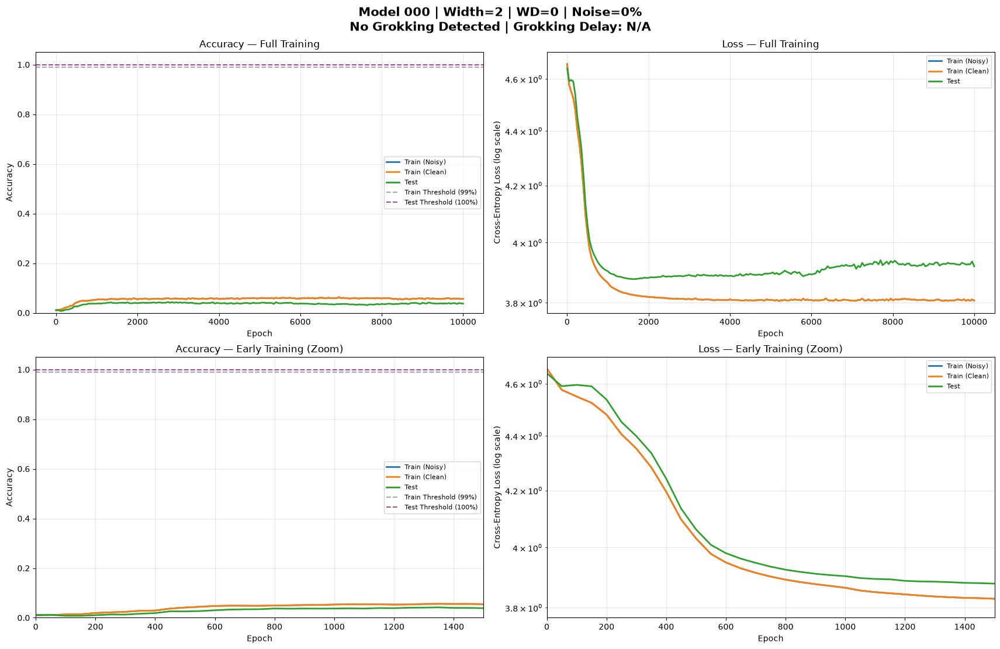

Training Models:   0%|          | 1/308 [00:01<05:08,  1.00s/model]

Model 1: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_001/learning_curves.png


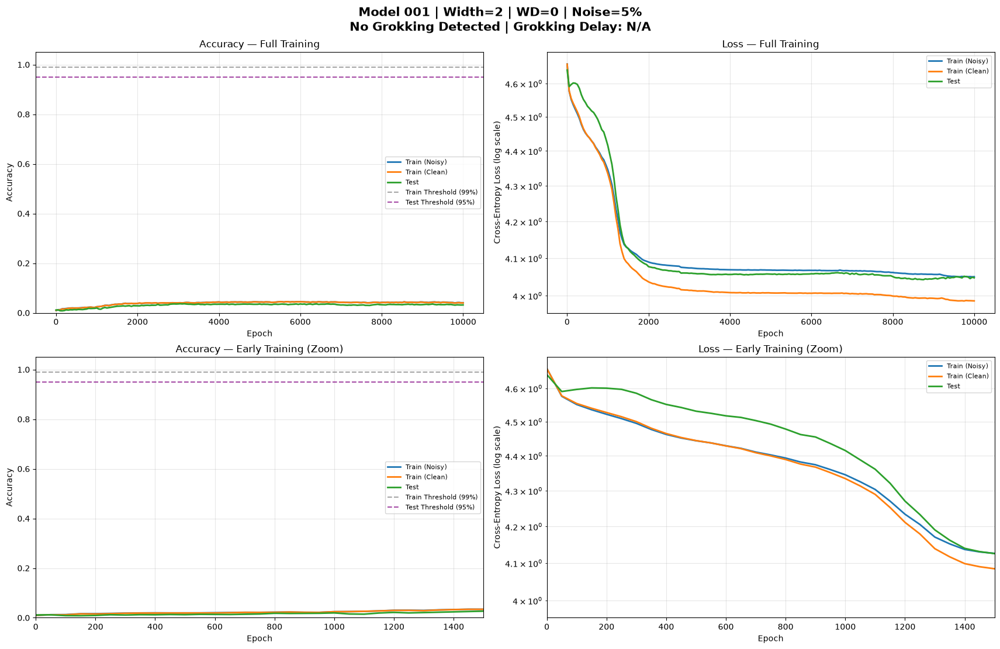

Training Models:   1%|          | 2/308 [00:02<05:13,  1.02s/model]

Model 2: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_002/learning_curves.png


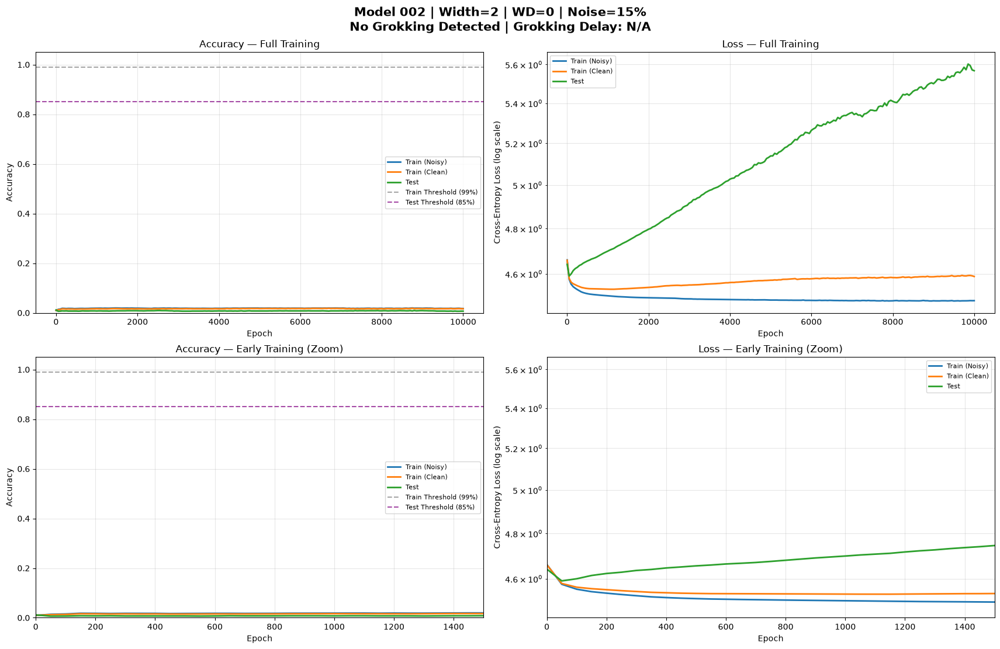

Training Models:   1%|          | 3/308 [00:02<05:01,  1.01model/s]

Model 3: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_003/learning_curves.png


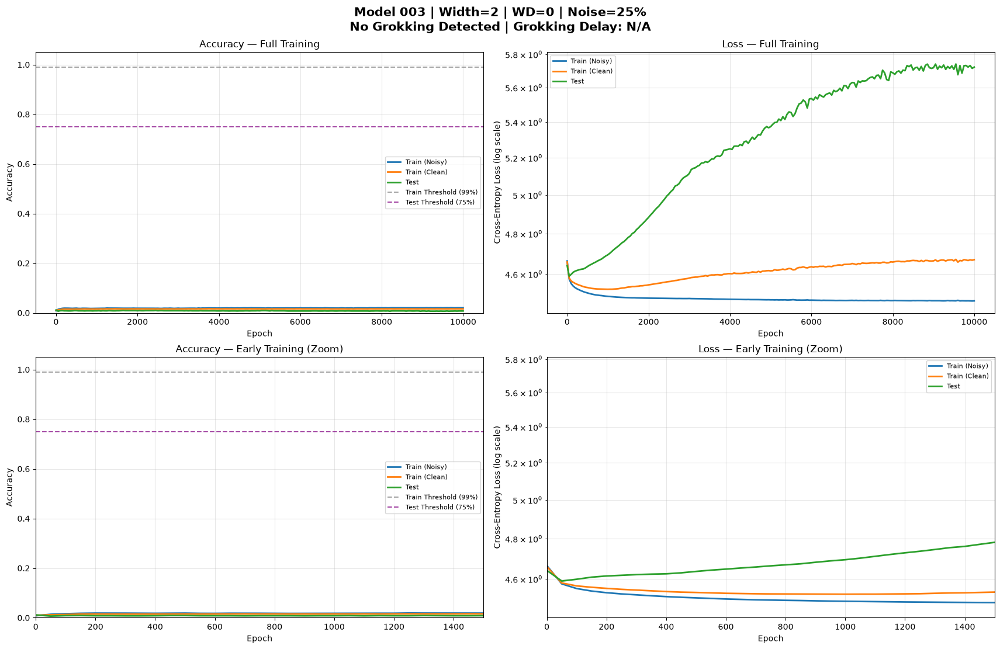

Training Models:   1%|▏         | 4/308 [00:03<05:00,  1.01model/s]

Model 4: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_004/learning_curves.png


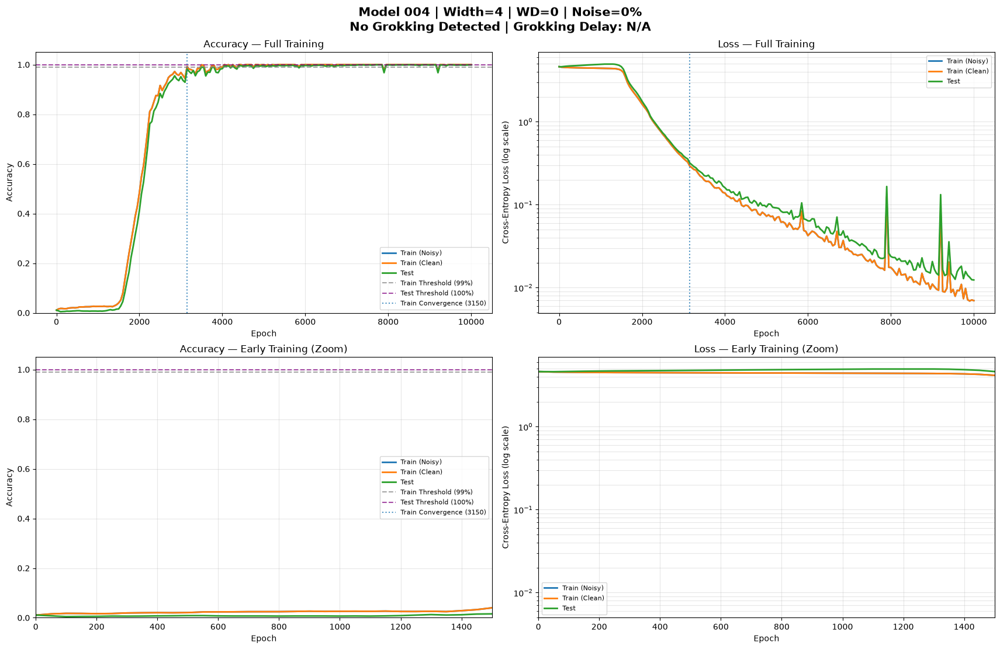

Training Models:   2%|▏         | 5/308 [00:05<05:09,  1.02s/model]

Model 5: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_005/learning_curves.png


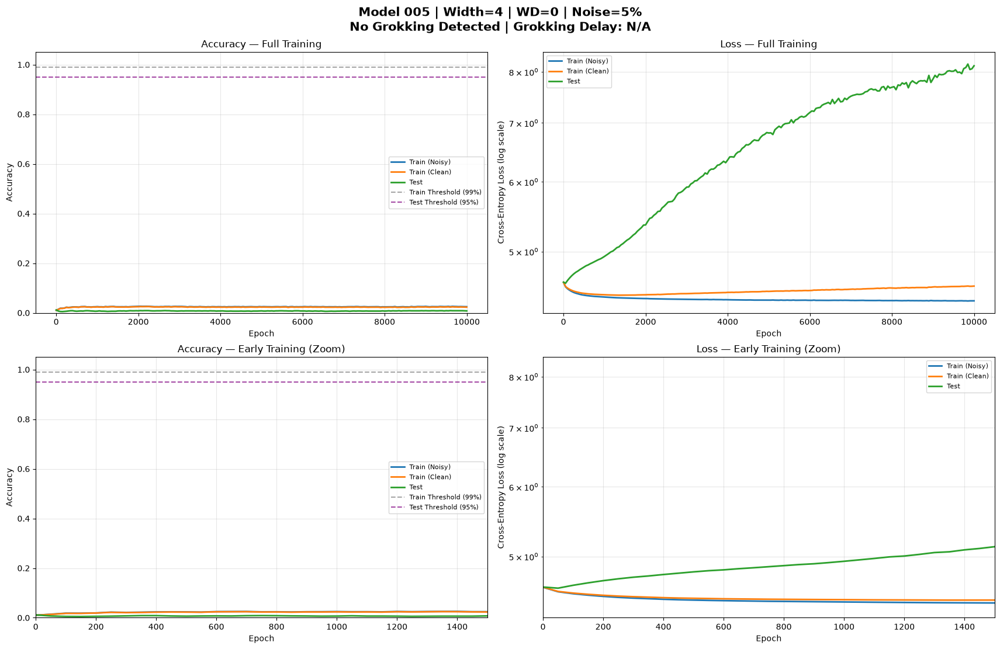

Training Models:   2%|▏         | 6/308 [00:06<05:00,  1.00model/s]

Model 6: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_006/learning_curves.png


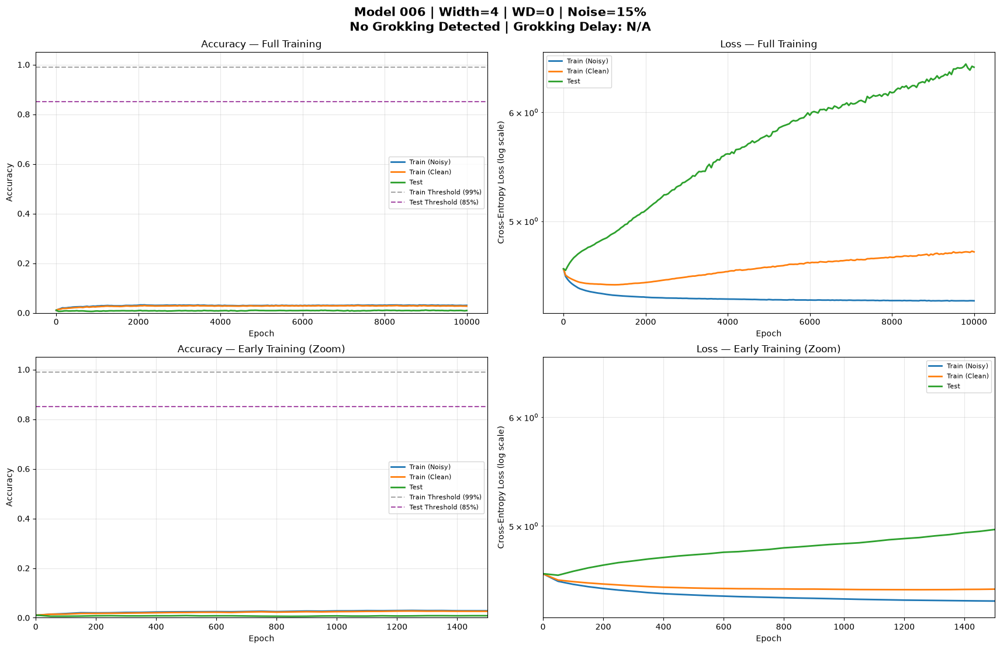

Training Models:   2%|▏         | 7/308 [00:06<04:48,  1.04model/s]

Model 7: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_007/learning_curves.png


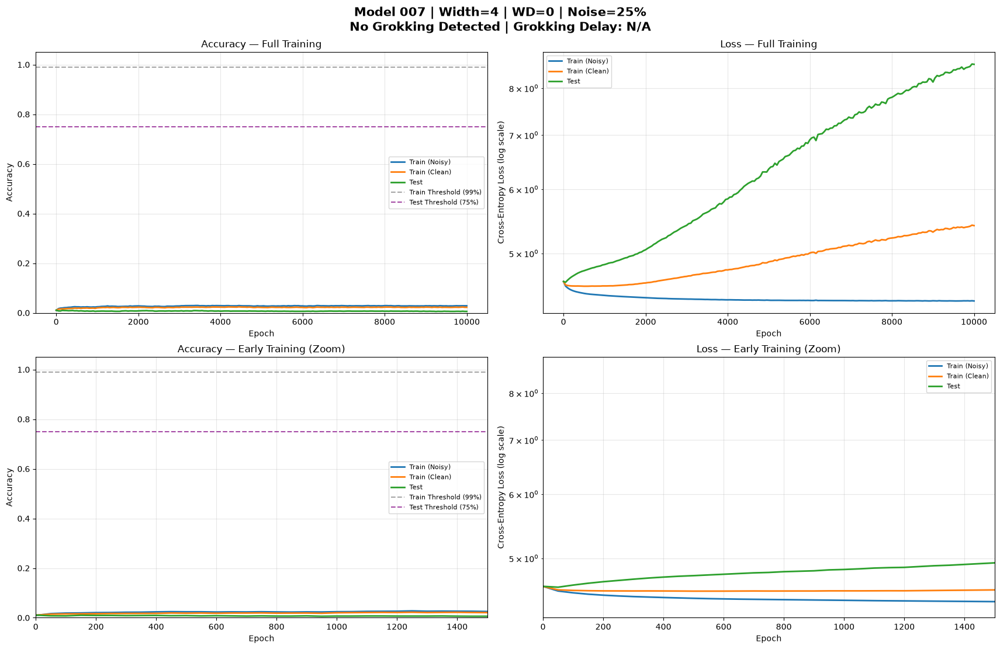

Training Models:   3%|▎         | 8/308 [00:07<04:43,  1.06model/s]

Model 8: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_008/learning_curves.png


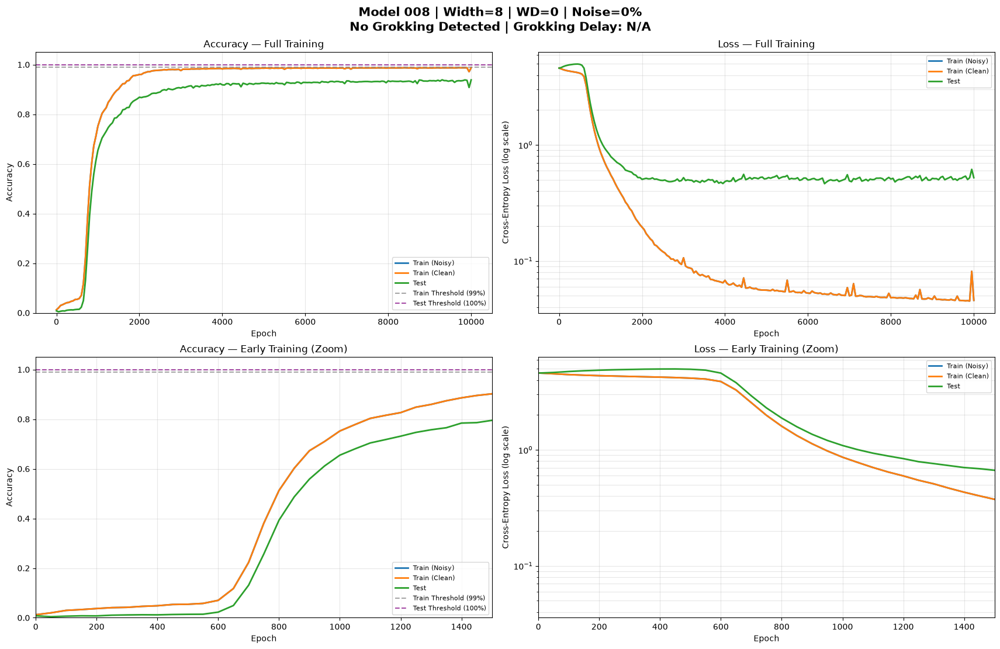

Training Models:   3%|▎         | 9/308 [00:08<04:46,  1.05model/s]

Model 9: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_009/learning_curves.png


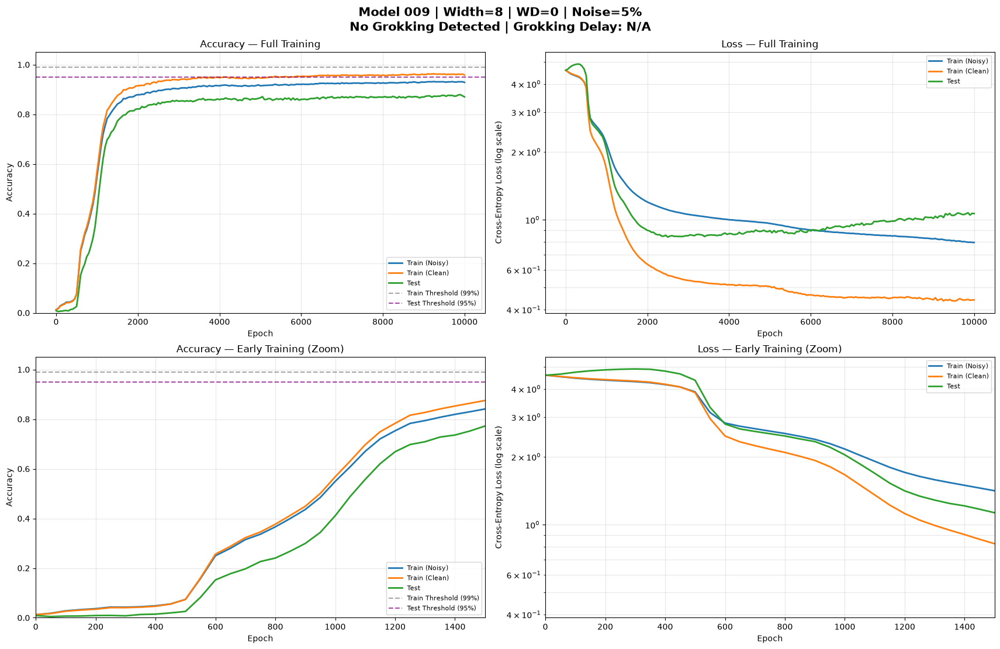

Training Models:   3%|▎         | 10/308 [00:09<05:05,  1.03s/model]

Model 10: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_010/learning_curves.png


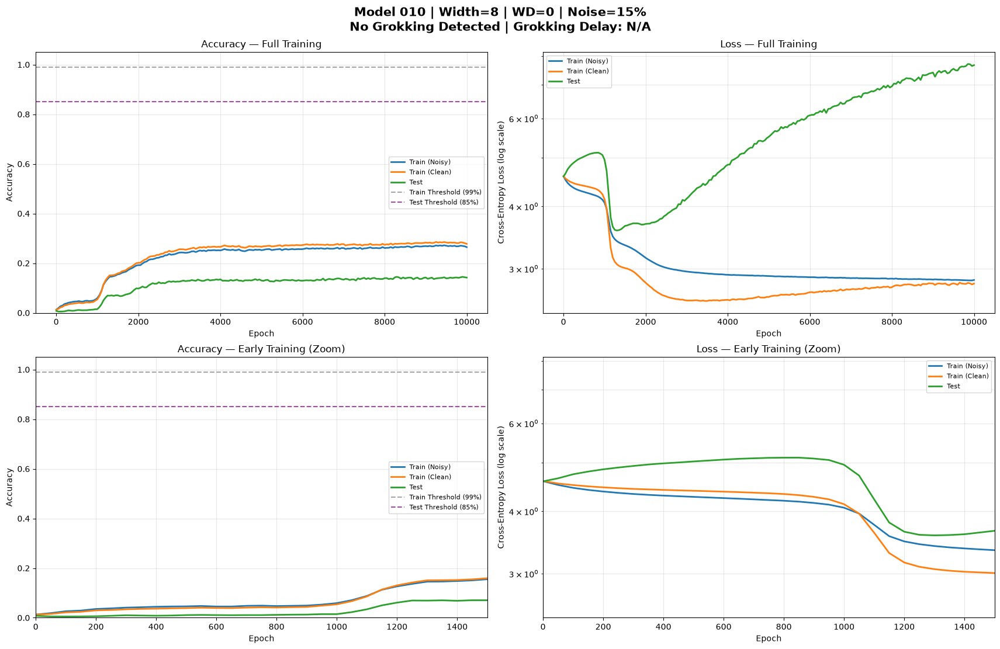

Training Models:   4%|▎         | 11/308 [00:10<04:53,  1.01model/s]

Model 11: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_011/learning_curves.png


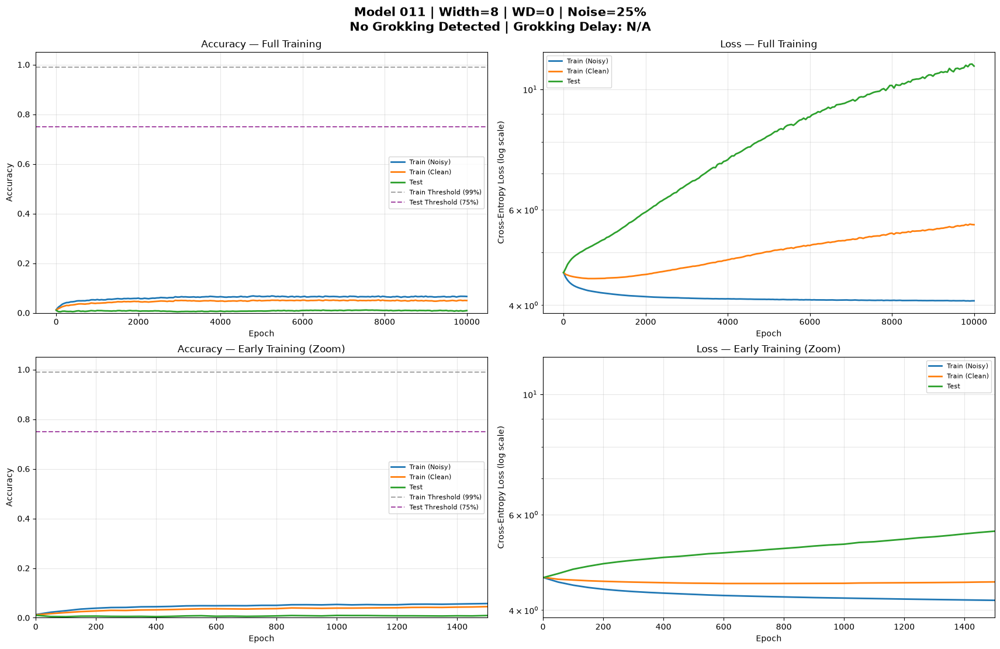

Training Models:   4%|▍         | 12/308 [00:11<04:46,  1.03model/s]

Model 12: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_012/learning_curves.png


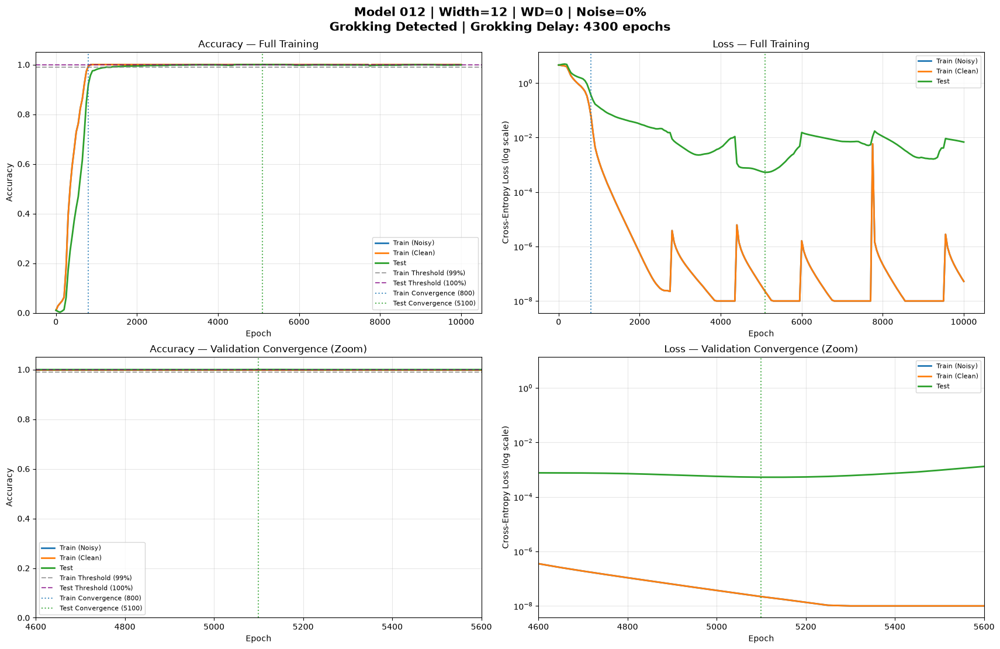

Training Models:   4%|▍         | 13/308 [00:12<04:41,  1.05model/s]

Model 13: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_013/learning_curves.png


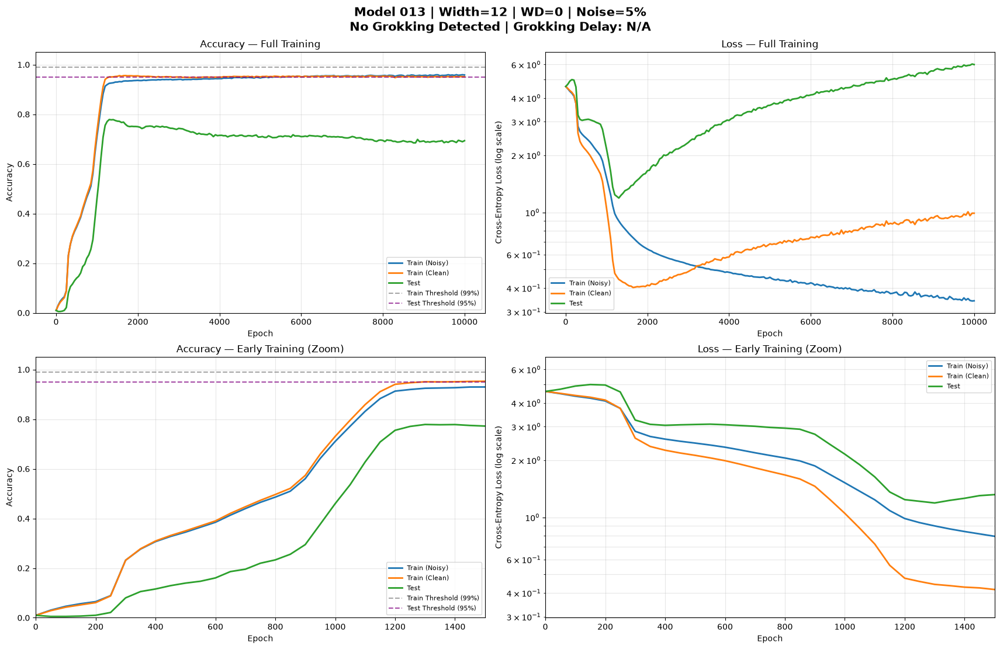

Training Models:   5%|▍         | 14/308 [00:13<04:50,  1.01model/s]

Model 14: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_014/learning_curves.png


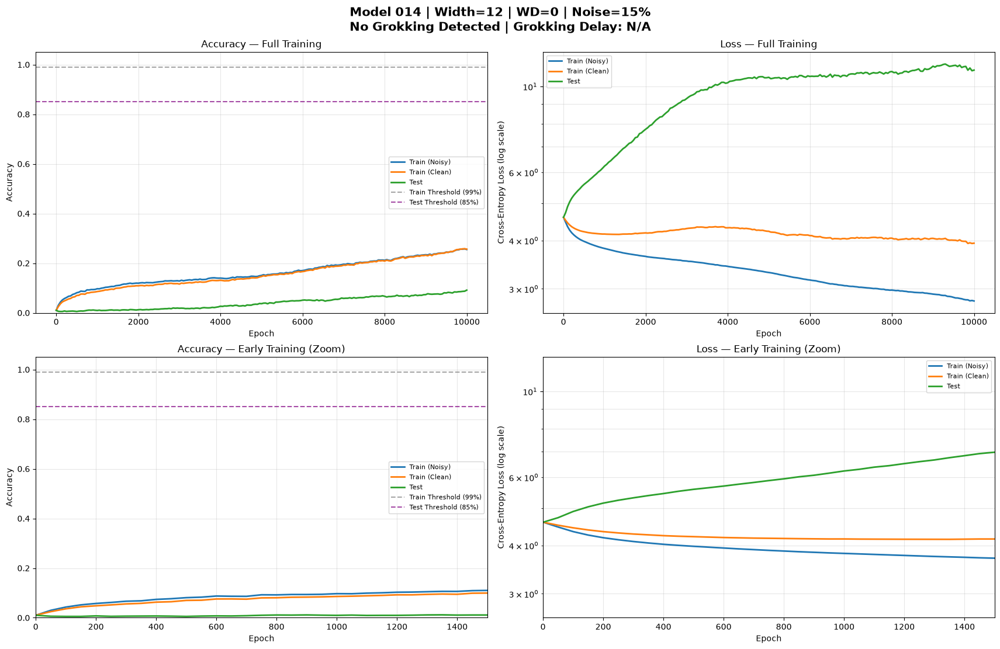

Training Models:   5%|▍         | 15/308 [00:14<04:56,  1.01s/model]

Model 15: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_015/learning_curves.png


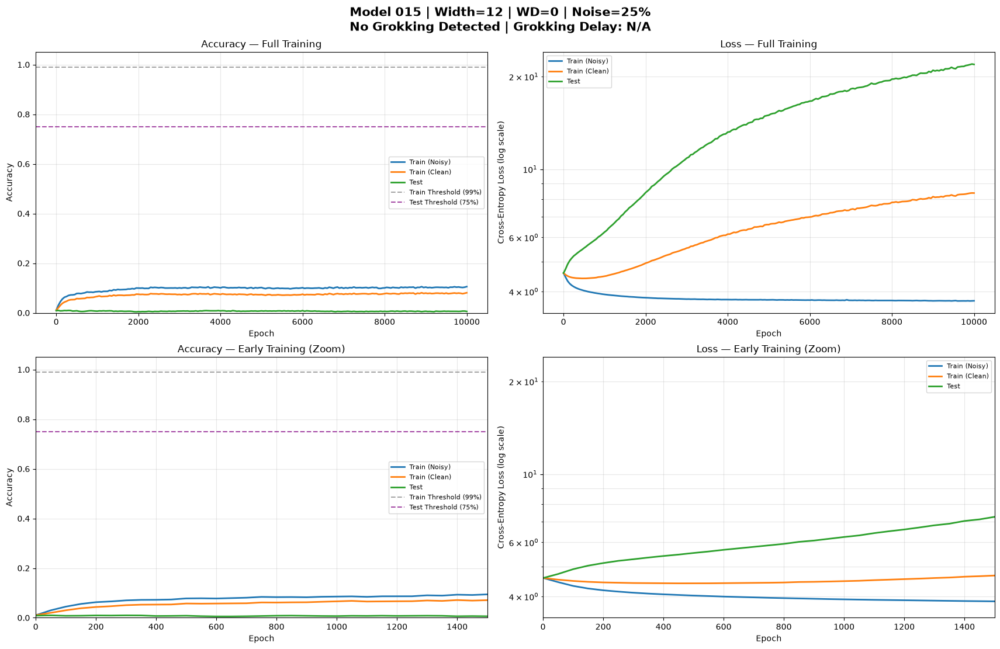

Training Models:   5%|▌         | 16/308 [00:15<04:49,  1.01model/s]

Model 16: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_016/learning_curves.png


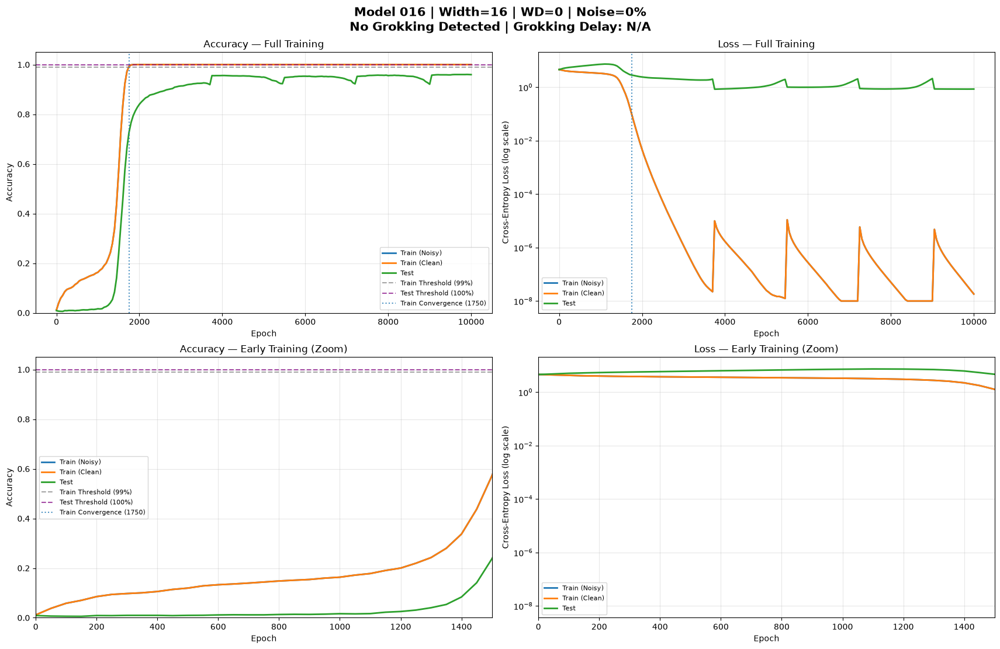

Training Models:   6%|▌         | 17/308 [00:16<04:43,  1.03model/s]

Model 17: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_017/learning_curves.png


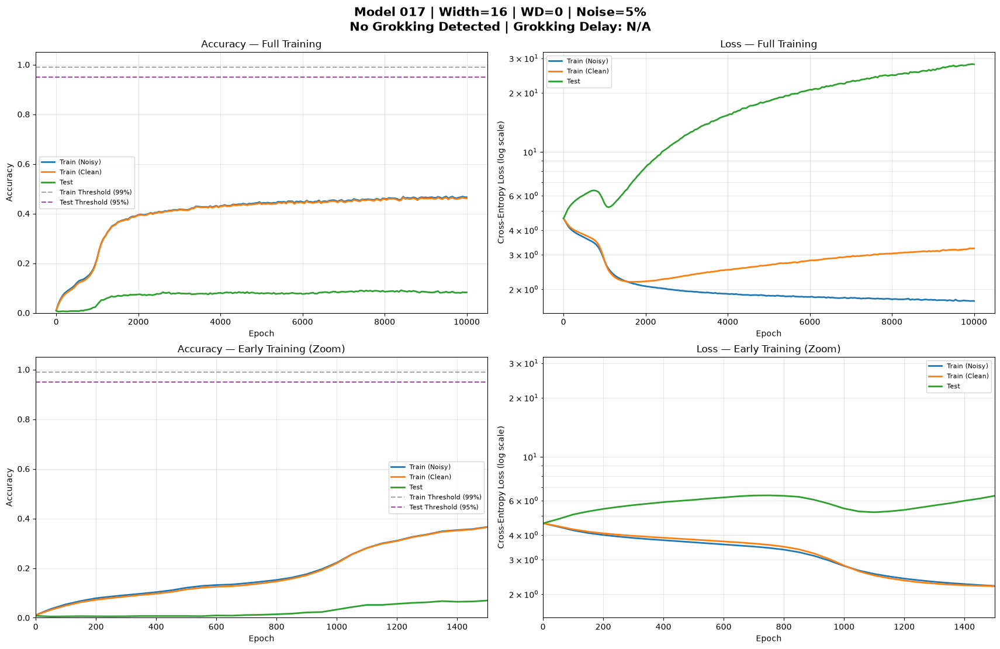

Training Models:   6%|▌         | 18/308 [00:17<04:44,  1.02model/s]

Model 18: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_018/learning_curves.png


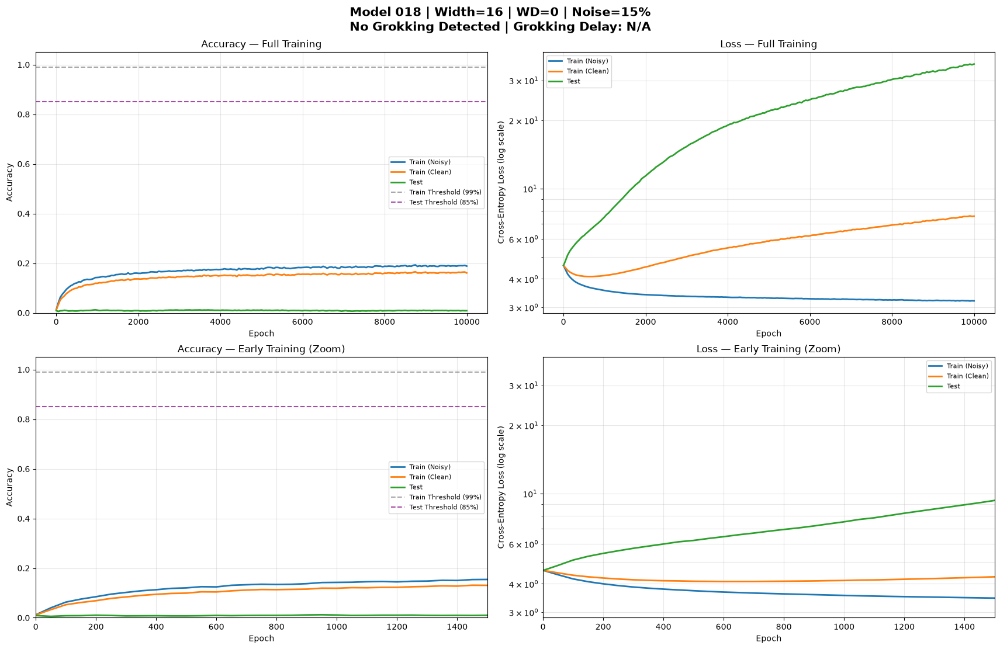

Training Models:   6%|▌         | 19/308 [00:18<04:43,  1.02model/s]

Model 19: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_019/learning_curves.png


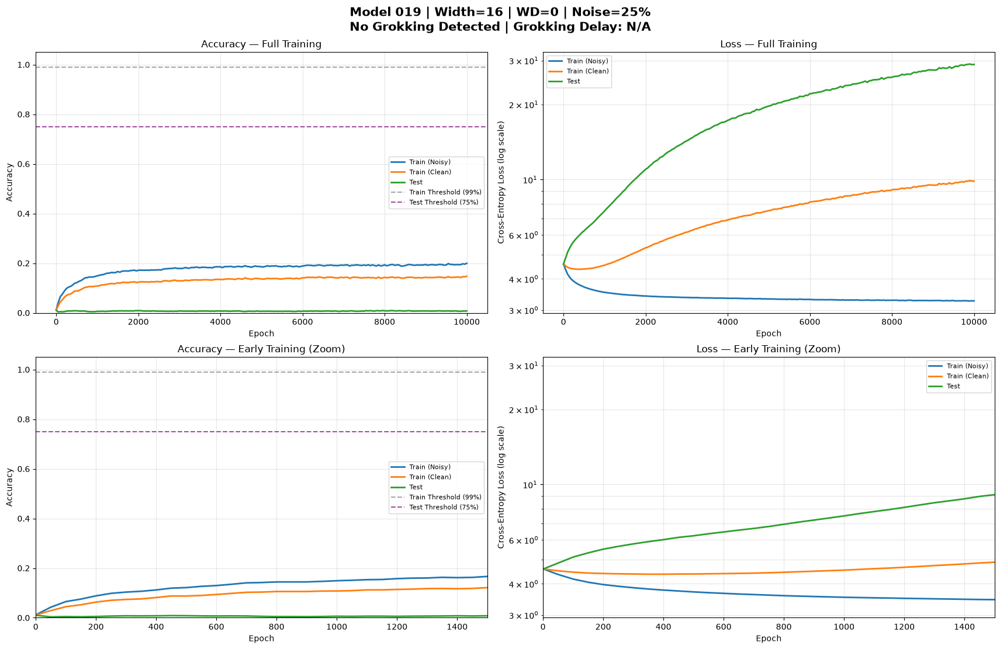

Training Models:   6%|▋         | 20/308 [00:19<04:58,  1.04s/model]

Model 20: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_020/learning_curves.png


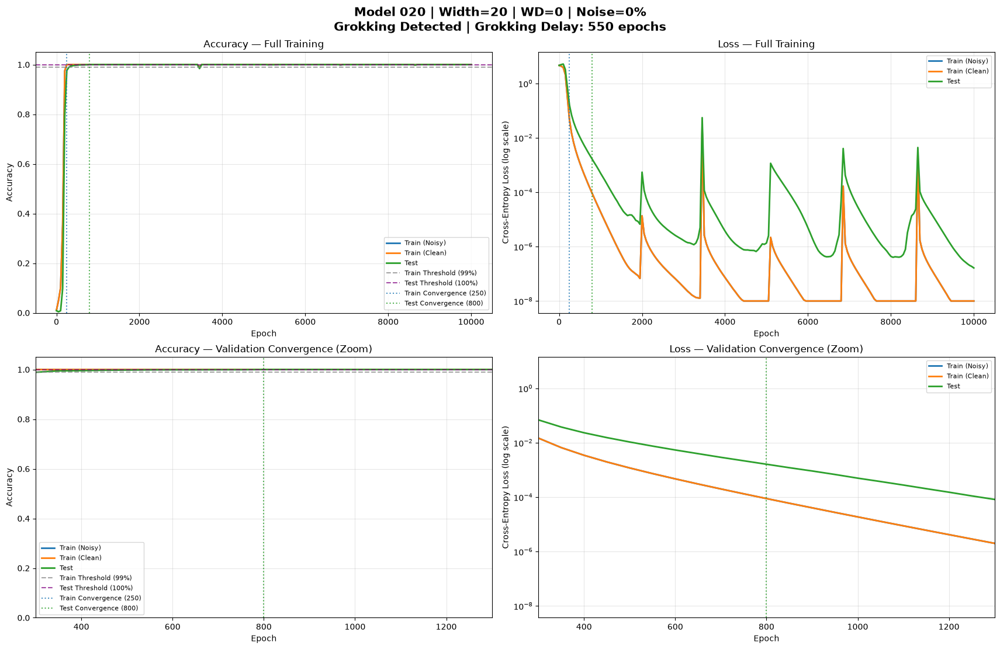

Training Models:   7%|▋         | 21/308 [00:20<04:46,  1.00model/s]

Model 21: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_021/learning_curves.png


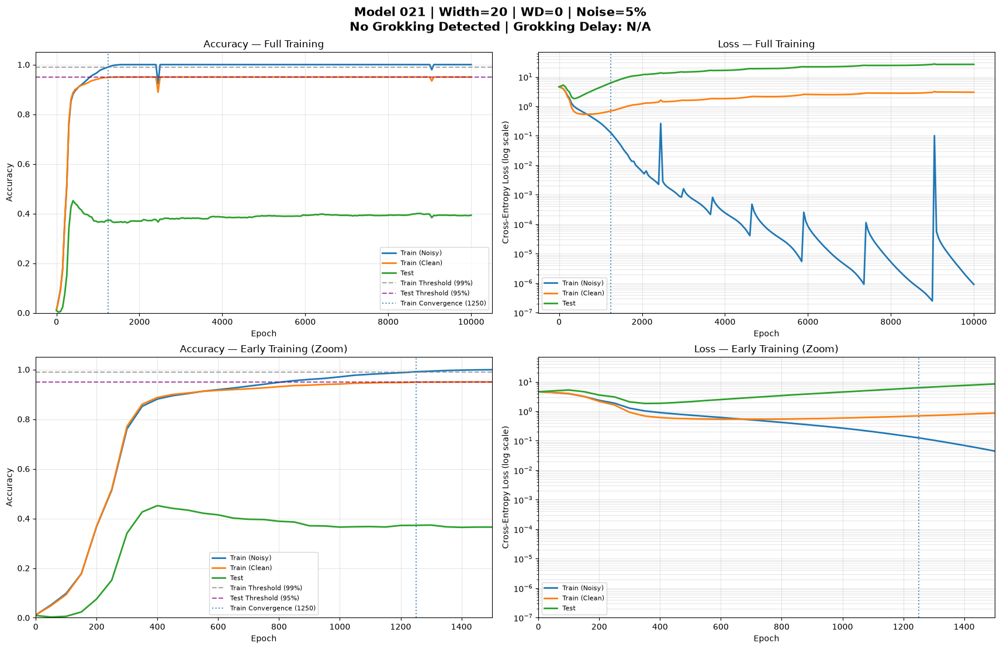

Training Models:   7%|▋         | 22/308 [00:22<05:28,  1.15s/model]

Model 22: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_022/learning_curves.png


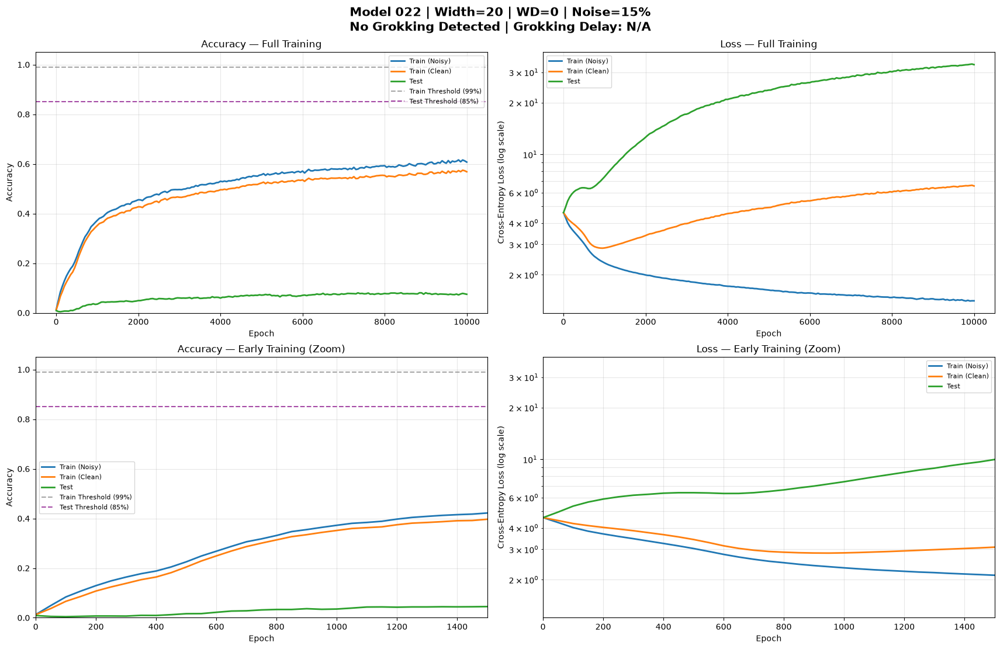

Training Models:   7%|▋         | 23/308 [00:23<05:27,  1.15s/model]

Model 23: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_023/learning_curves.png


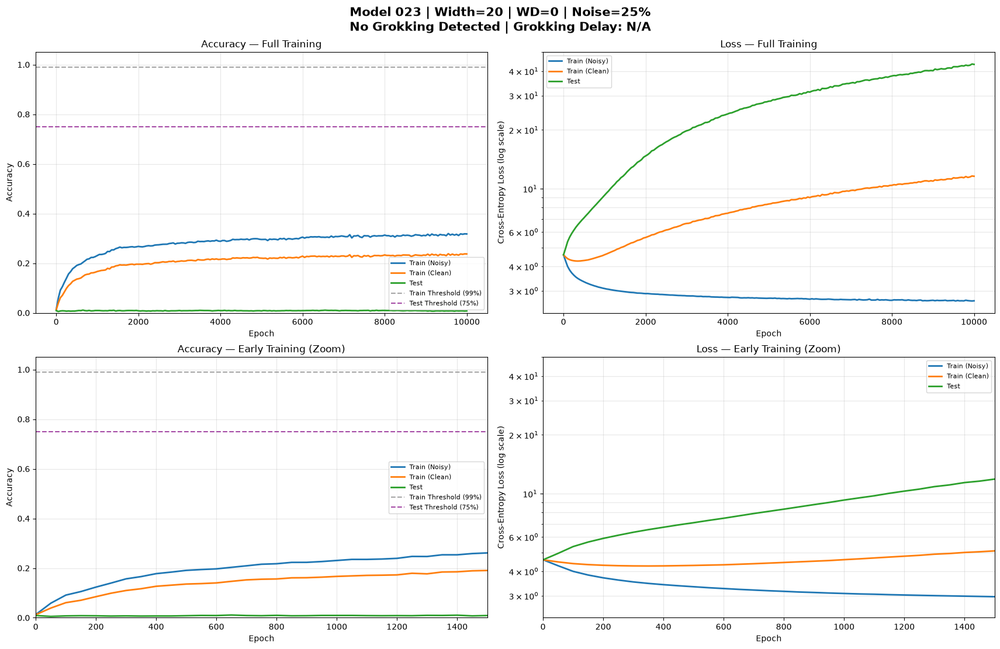

Training Models:   8%|▊         | 24/308 [00:24<05:13,  1.10s/model]

Model 24: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_024/learning_curves.png


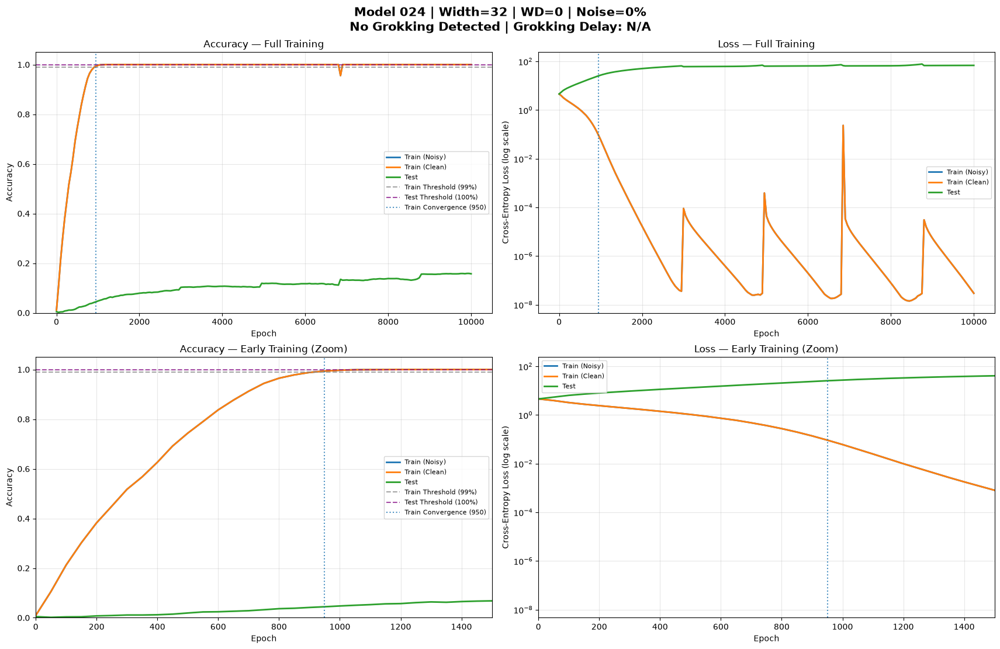

Training Models:   8%|▊         | 25/308 [00:25<04:58,  1.06s/model]

Model 25: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_025/learning_curves.png


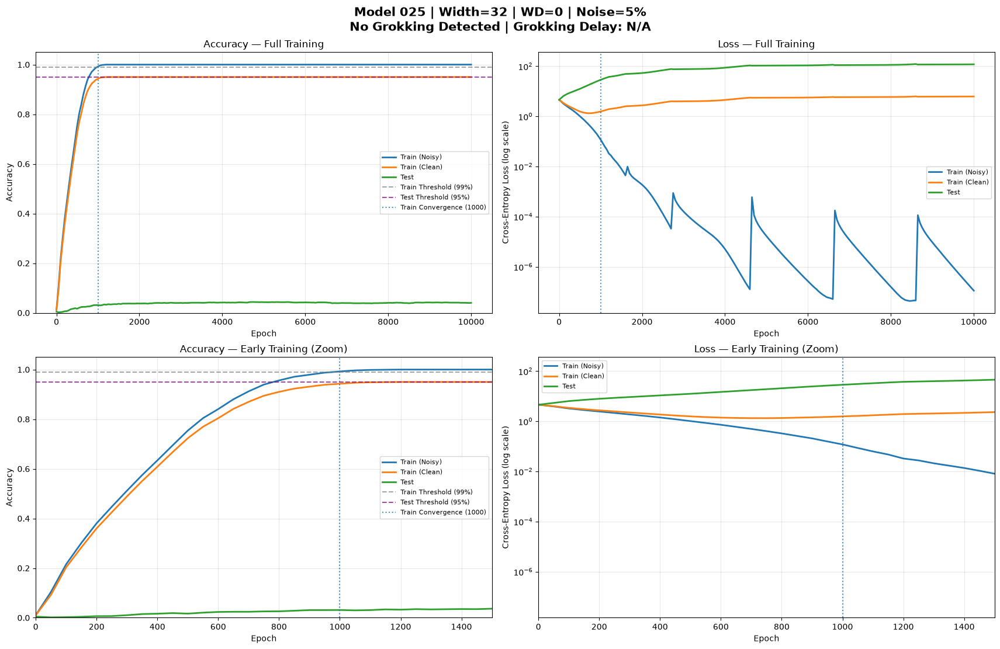

Training Models:   8%|▊         | 26/308 [00:26<04:46,  1.02s/model]

Model 26: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_026/learning_curves.png


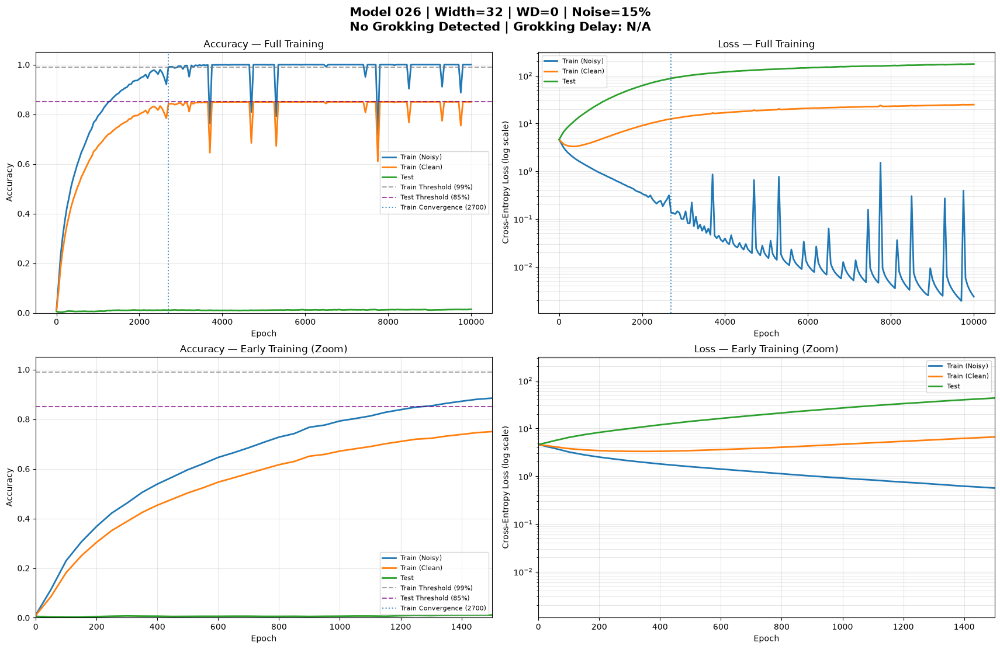

Training Models:   9%|▉         | 27/308 [00:27<05:10,  1.11s/model]

Model 27: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_027/learning_curves.png


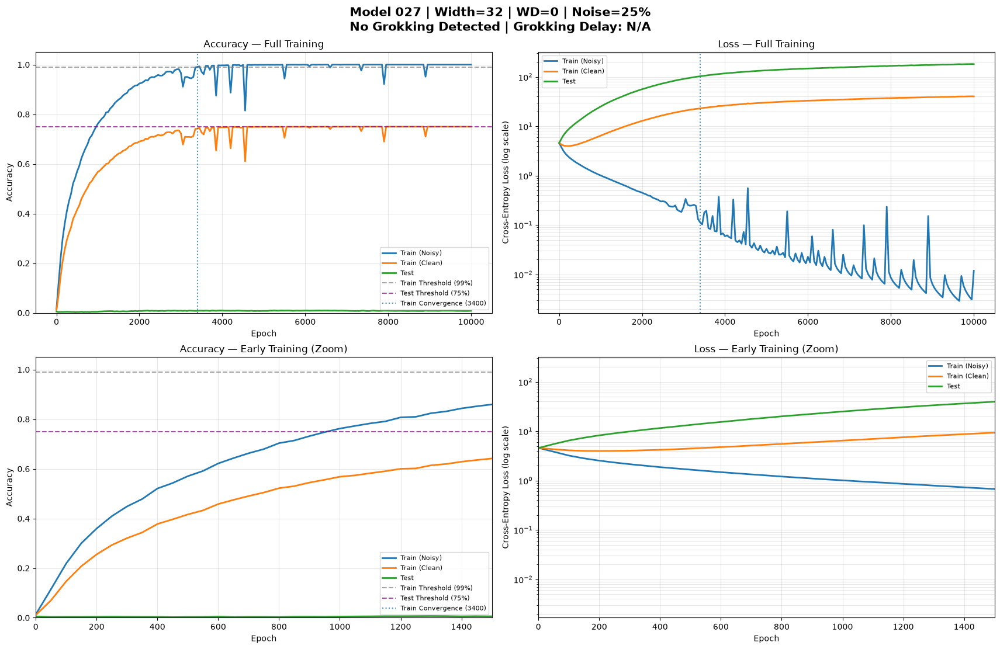

Training Models:   9%|▉         | 28/308 [00:28<05:14,  1.12s/model]

Model 28: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_028/learning_curves.png


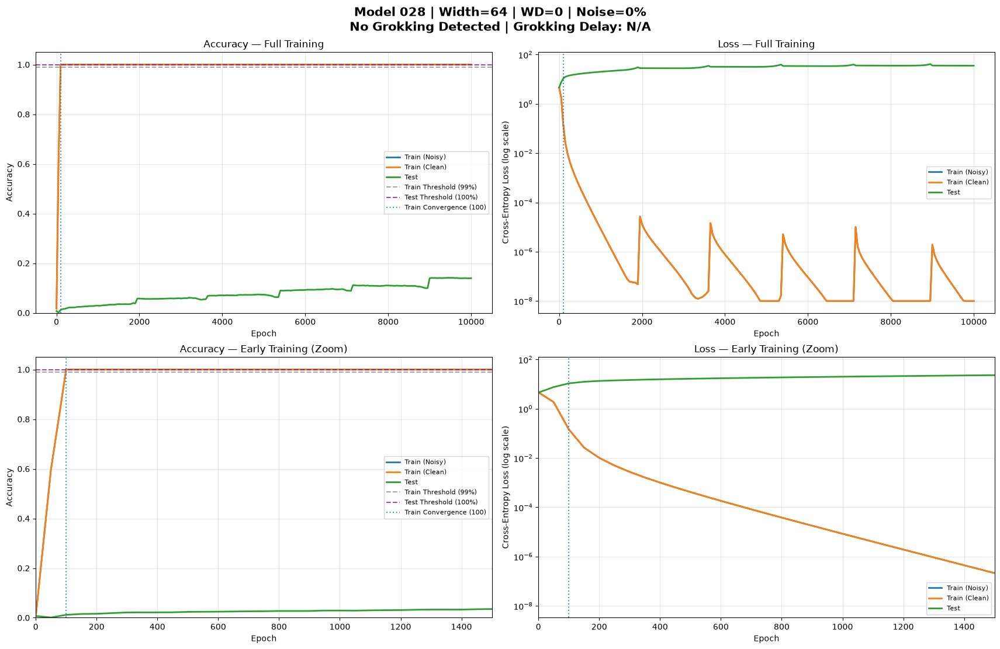

Training Models:   9%|▉         | 29/308 [00:29<04:57,  1.07s/model]

Model 29: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_029/learning_curves.png


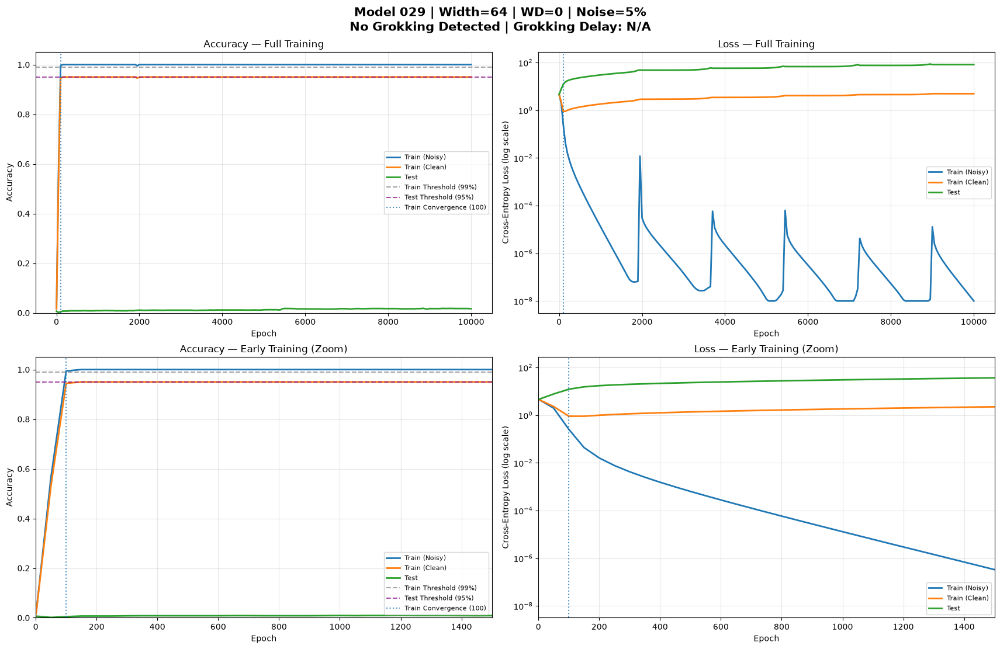

Training Models:  10%|▉         | 30/308 [00:30<04:42,  1.02s/model]

Model 30: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_030/learning_curves.png


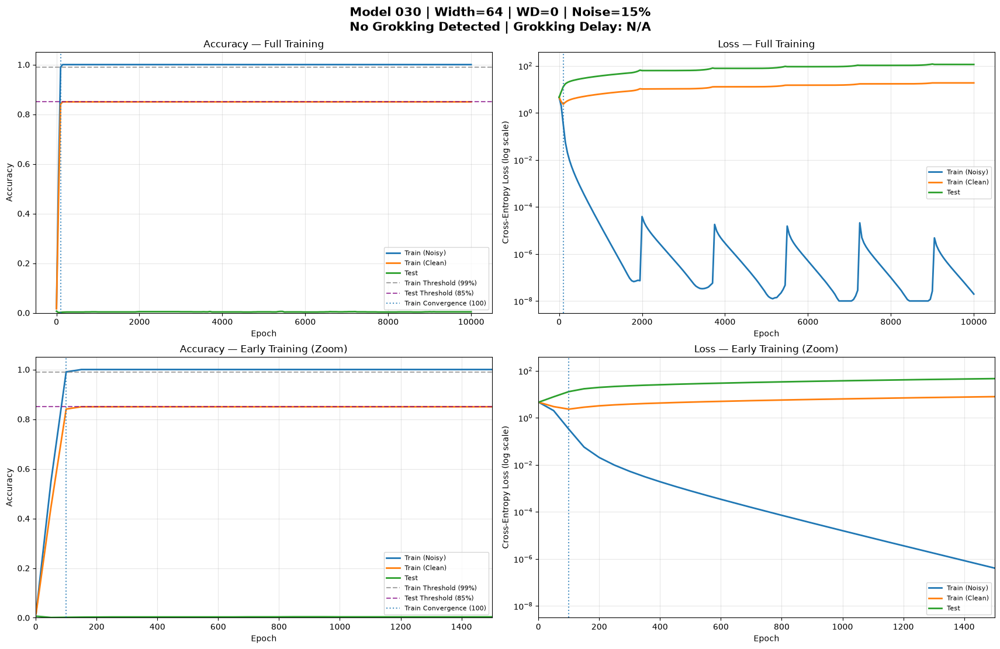

Training Models:  10%|█         | 31/308 [00:31<04:43,  1.02s/model]

Model 31: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_031/learning_curves.png


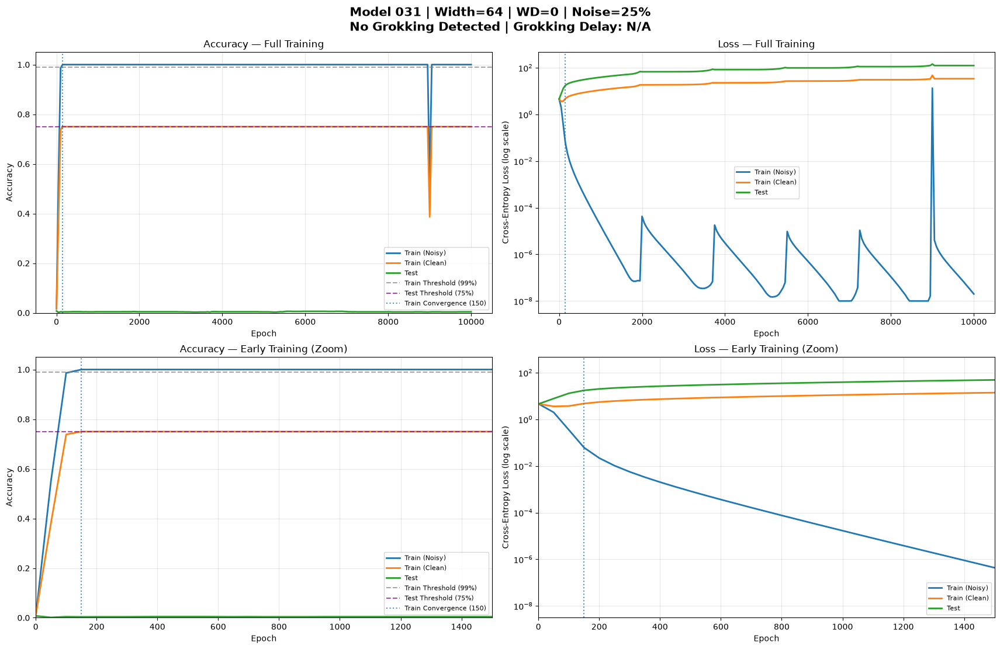

Training Models:  10%|█         | 32/308 [00:32<04:34,  1.00model/s]

Model 32: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_032/learning_curves.png


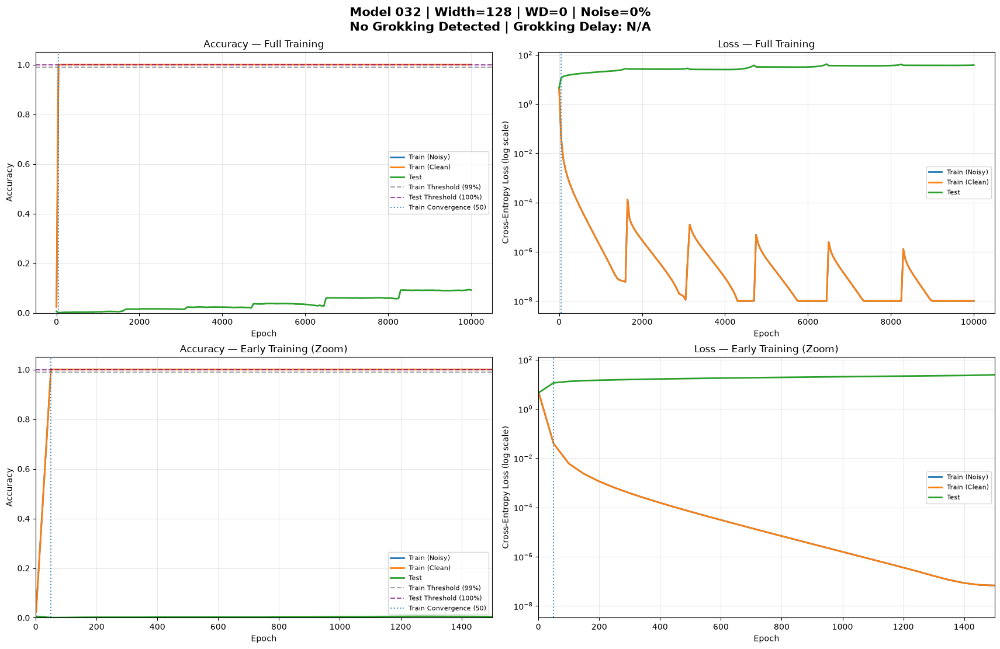

Training Models:  11%|█         | 33/308 [00:33<04:28,  1.02model/s]

Model 33: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_033/learning_curves.png


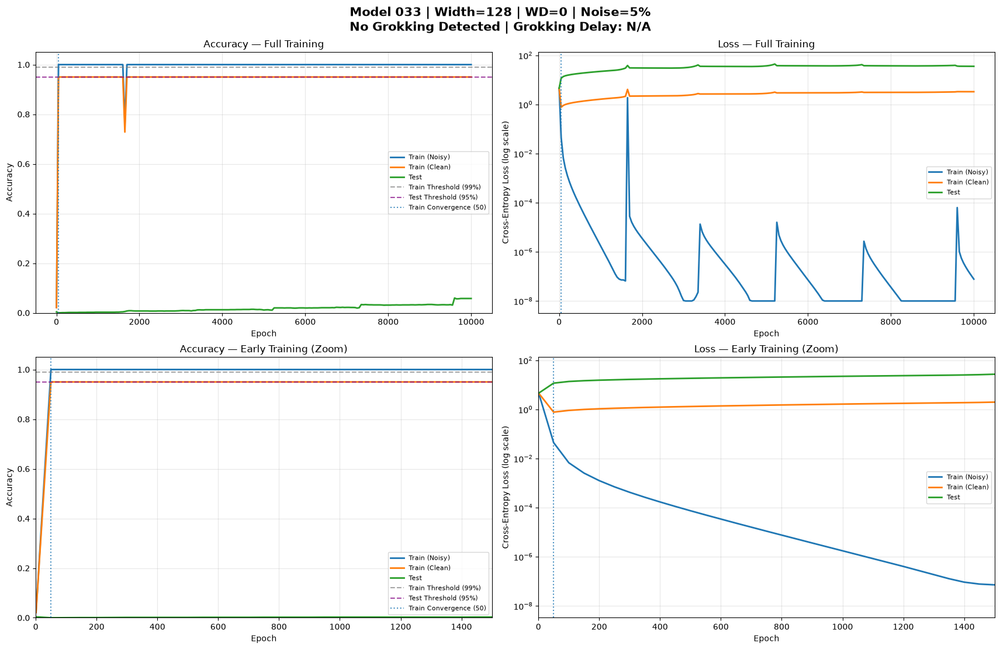

Training Models:  11%|█         | 34/308 [00:34<04:24,  1.04model/s]

Model 34: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_034/learning_curves.png


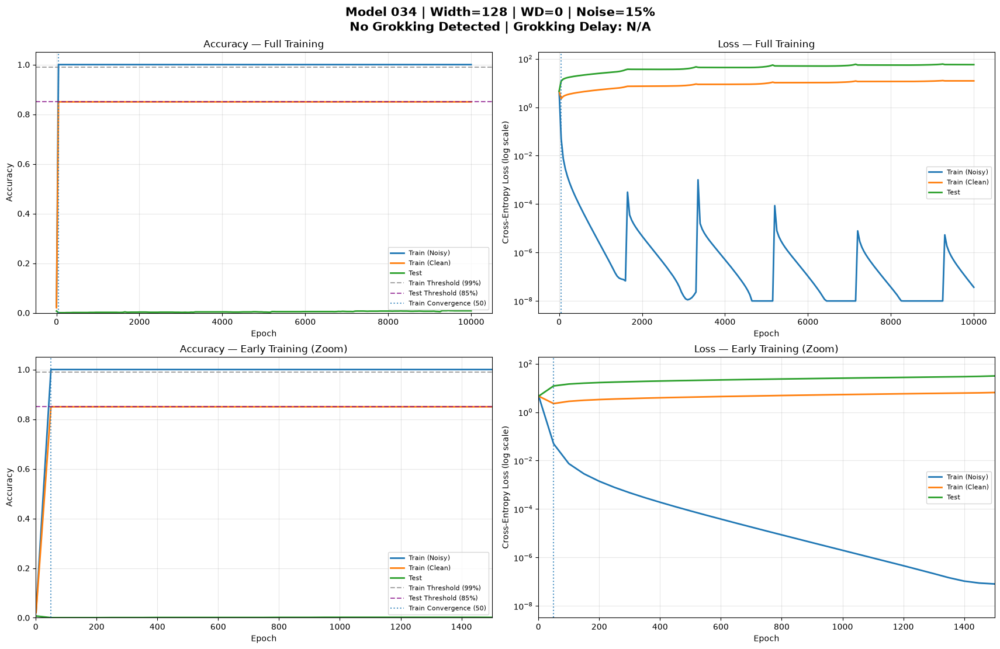

Training Models:  11%|█▏        | 35/308 [00:35<04:21,  1.05model/s]

Model 35: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_035/learning_curves.png


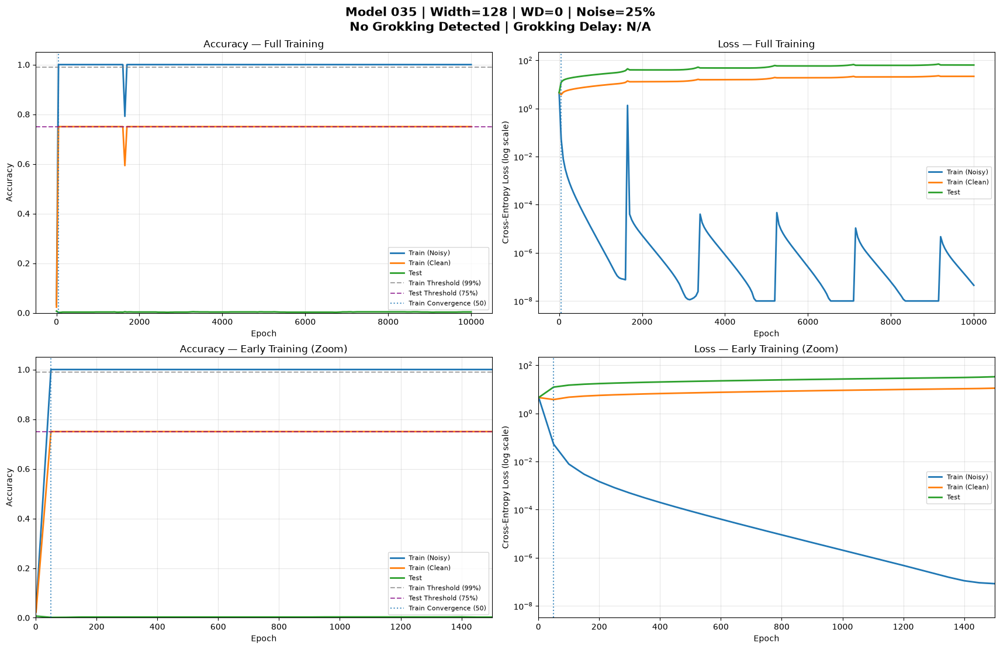

Training Models:  12%|█▏        | 36/308 [00:36<04:27,  1.02model/s]

Model 36: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_036/learning_curves.png


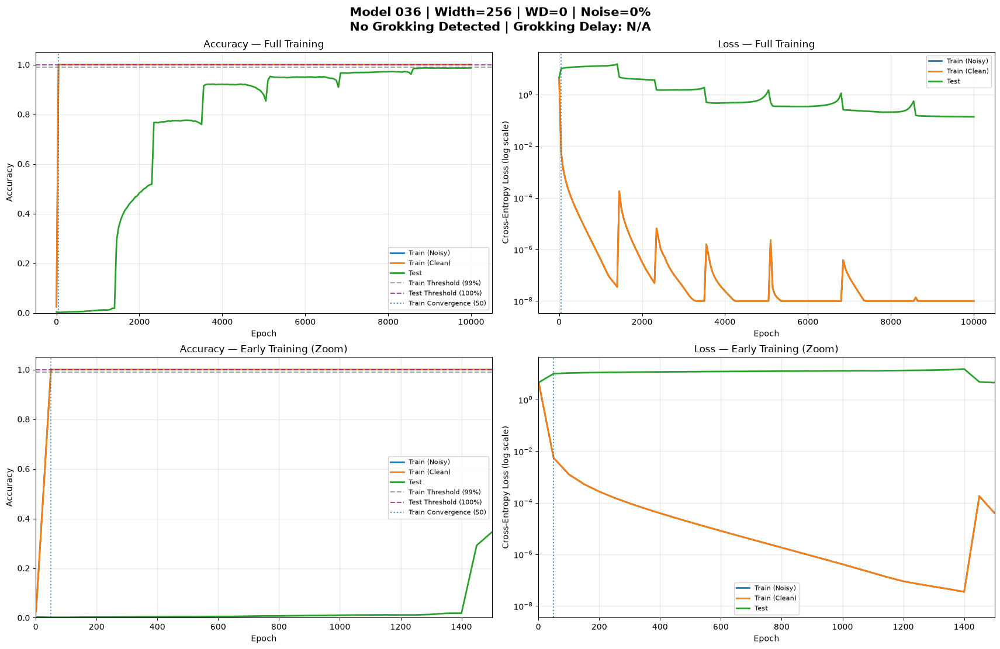

Training Models:  12%|█▏        | 37/308 [00:37<04:21,  1.04model/s]

Model 37: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_037/learning_curves.png


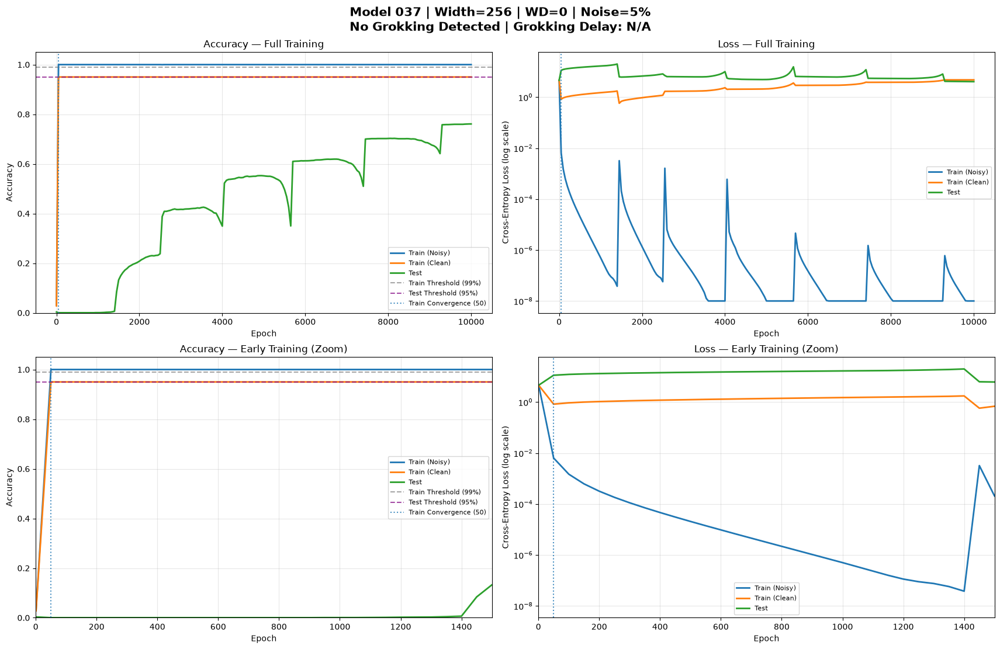

Training Models:  12%|█▏        | 38/308 [00:38<04:18,  1.05model/s]

Model 38: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_038/learning_curves.png


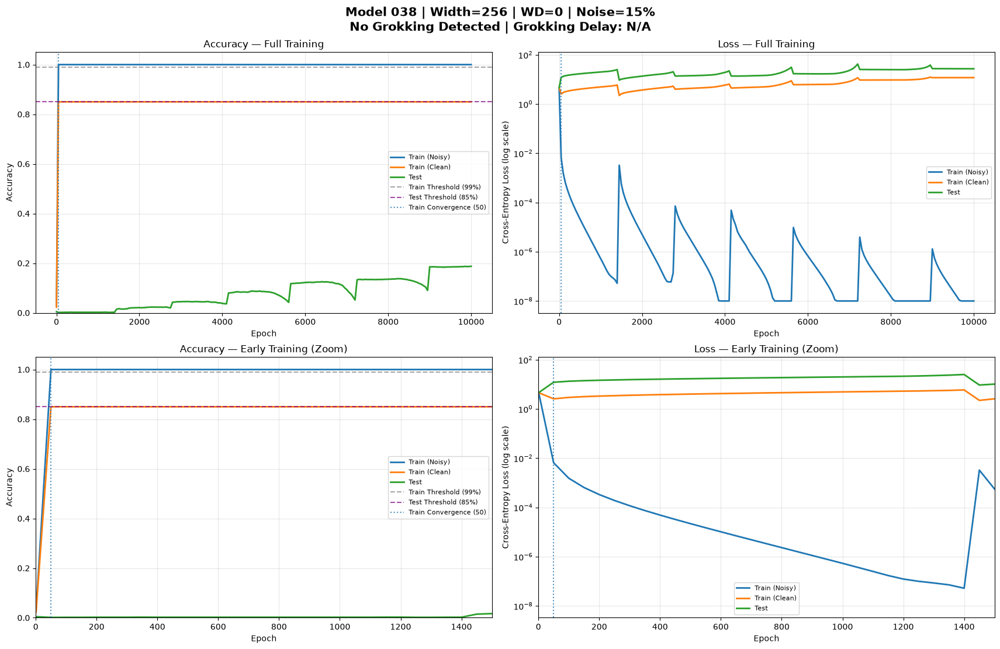

Training Models:  13%|█▎        | 39/308 [00:39<04:15,  1.05model/s]

Model 39: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_039/learning_curves.png


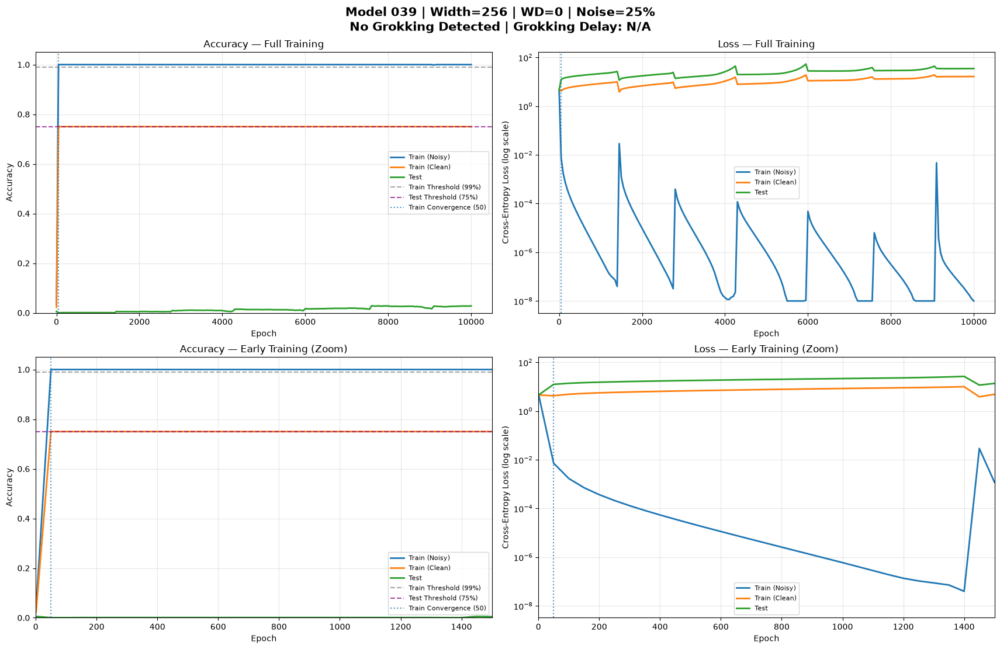

Training Models:  13%|█▎        | 40/308 [00:40<04:14,  1.05model/s]

Model 40: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_040/learning_curves.png


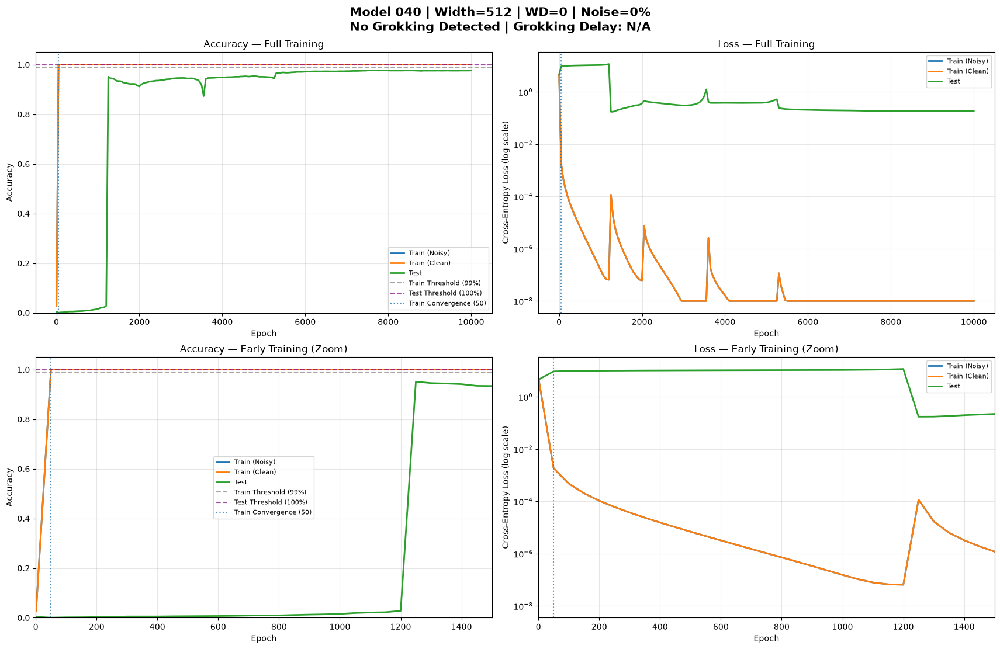

Training Models:  13%|█▎        | 41/308 [00:41<04:19,  1.03model/s]

Model 41: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_041/learning_curves.png


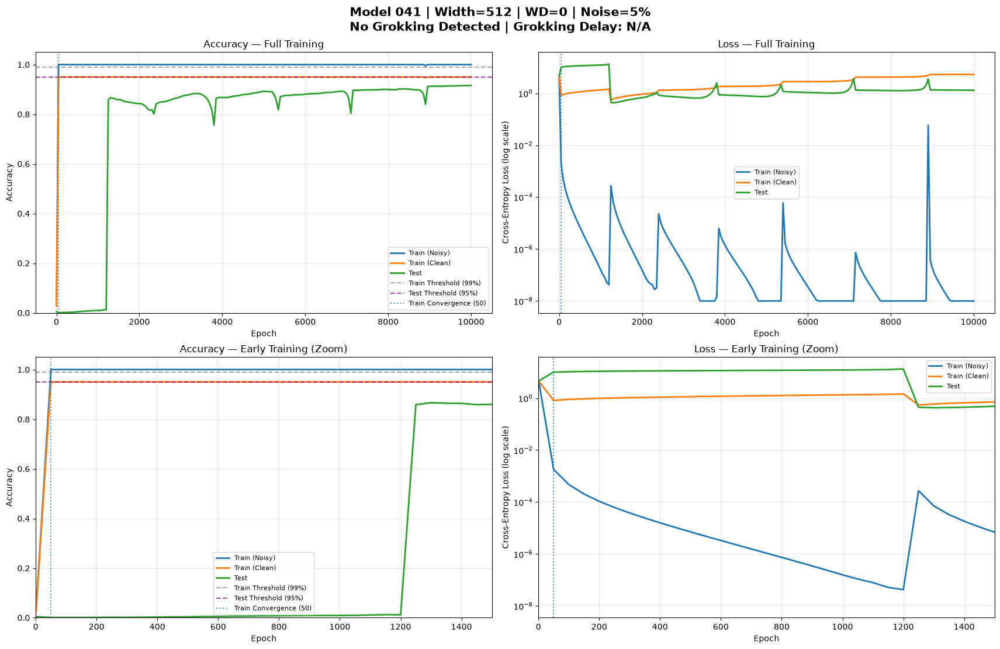

Training Models:  14%|█▎        | 42/308 [00:42<04:15,  1.04model/s]

Model 42: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_042/learning_curves.png


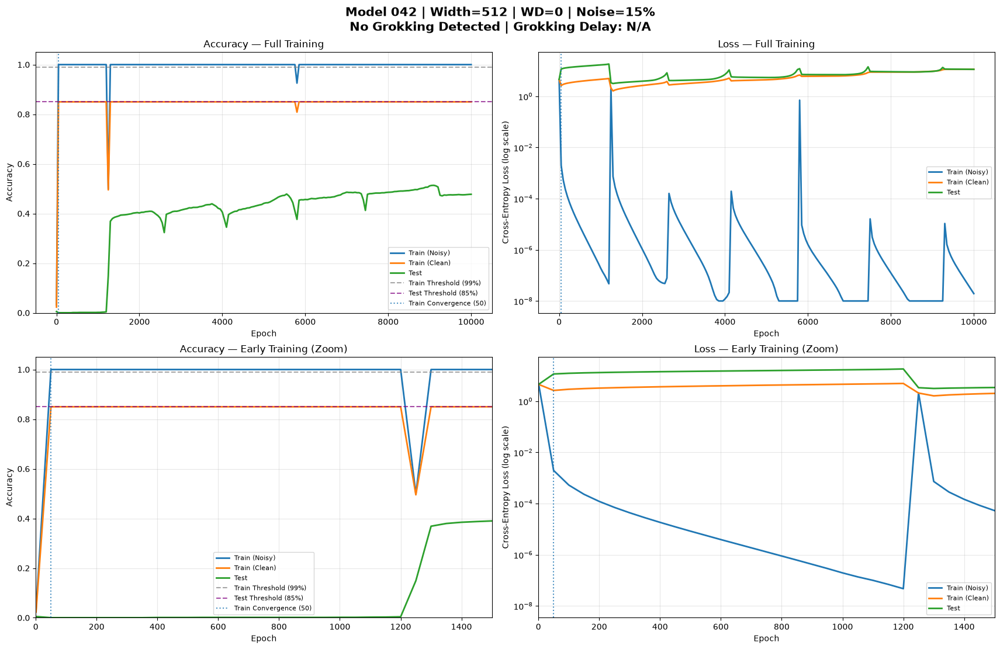

Training Models:  14%|█▍        | 43/308 [00:43<04:12,  1.05model/s]

Model 43: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_043/learning_curves.png


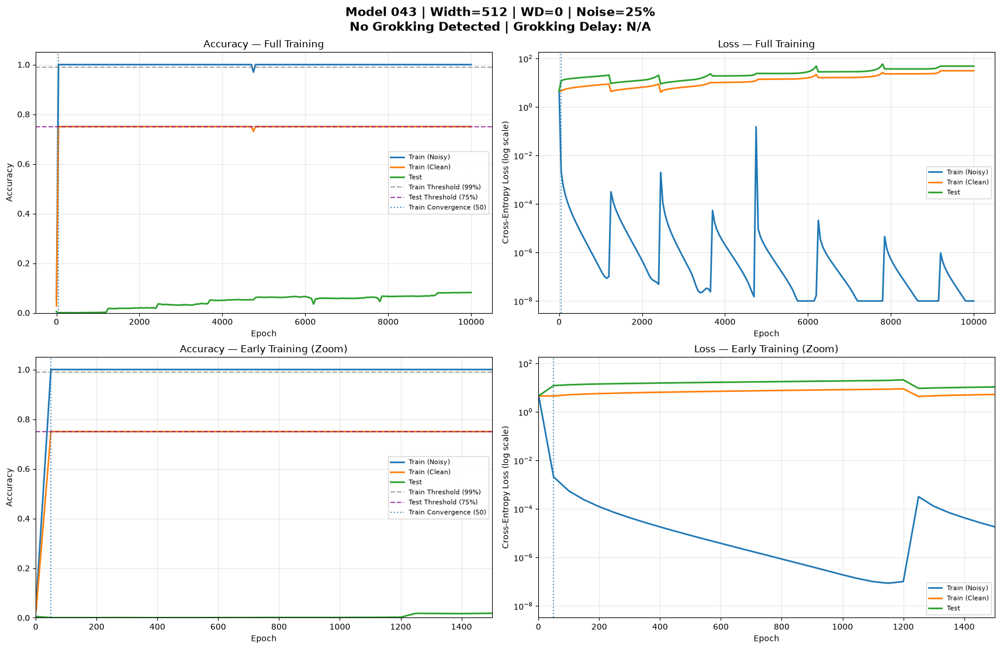

Training Models:  14%|█▍        | 44/308 [00:43<04:10,  1.05model/s]

Model 44: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_044/learning_curves.png


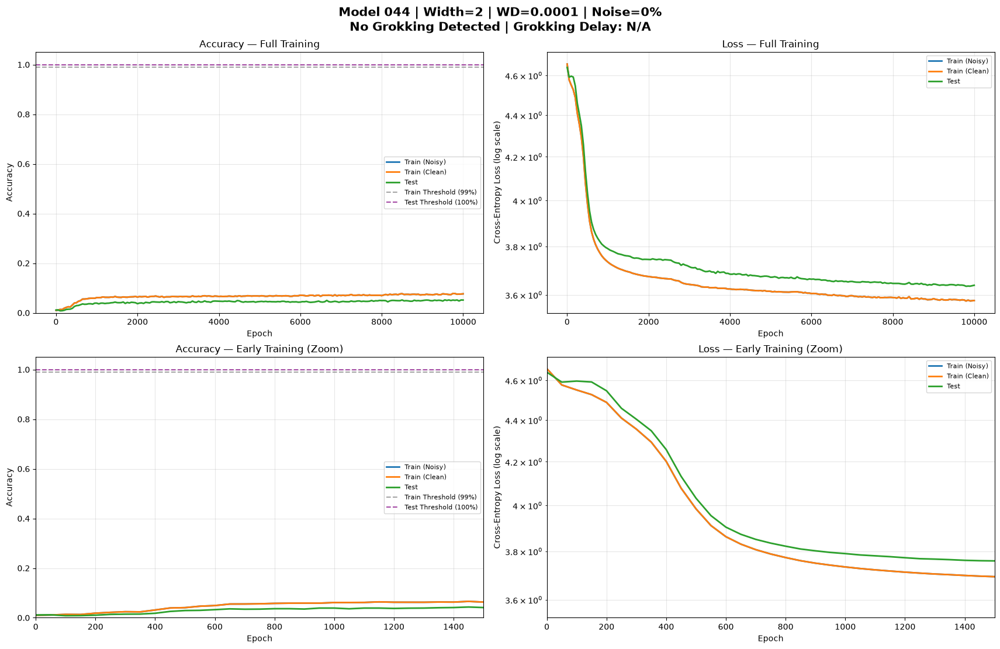

Training Models:  15%|█▍        | 45/308 [00:44<04:09,  1.05model/s]

Model 45: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_045/learning_curves.png


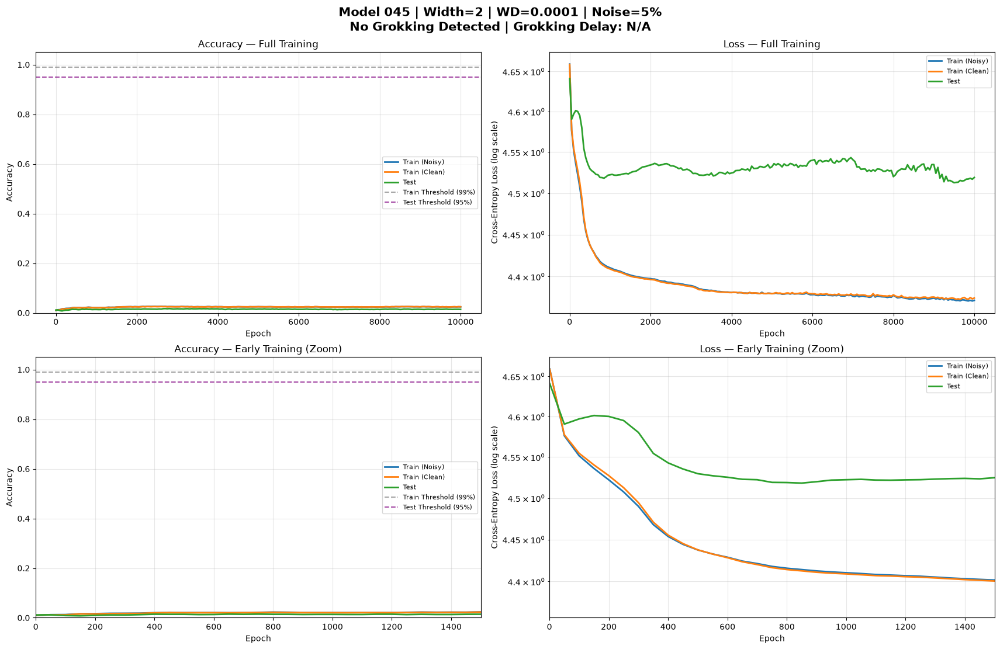

Training Models:  15%|█▍        | 46/308 [00:46<04:18,  1.01model/s]

Model 46: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_046/learning_curves.png


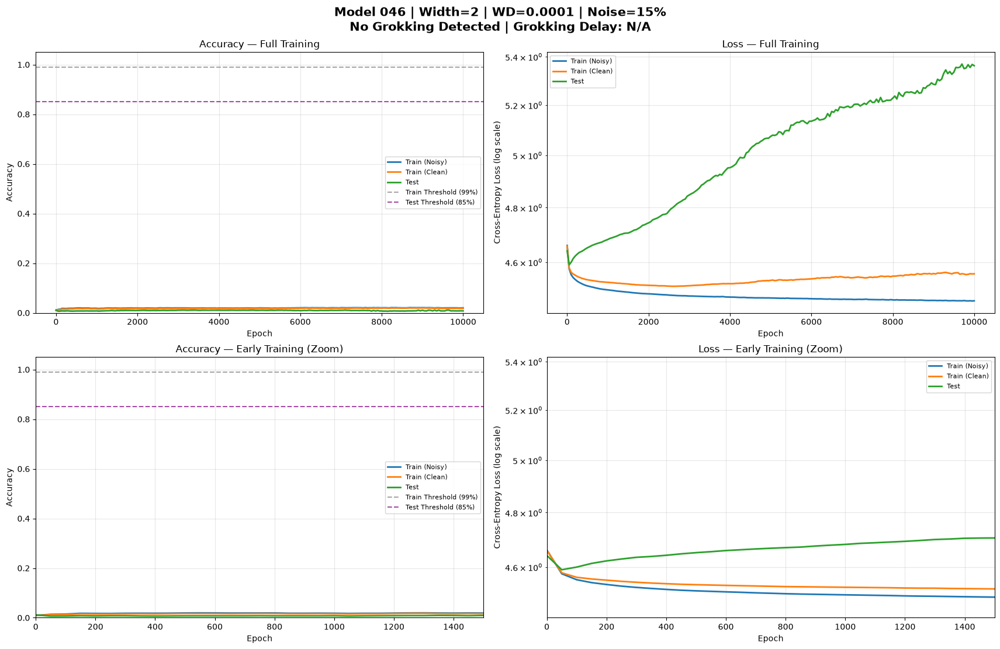

Training Models:  15%|█▌        | 47/308 [00:46<04:11,  1.04model/s]

Model 47: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_047/learning_curves.png


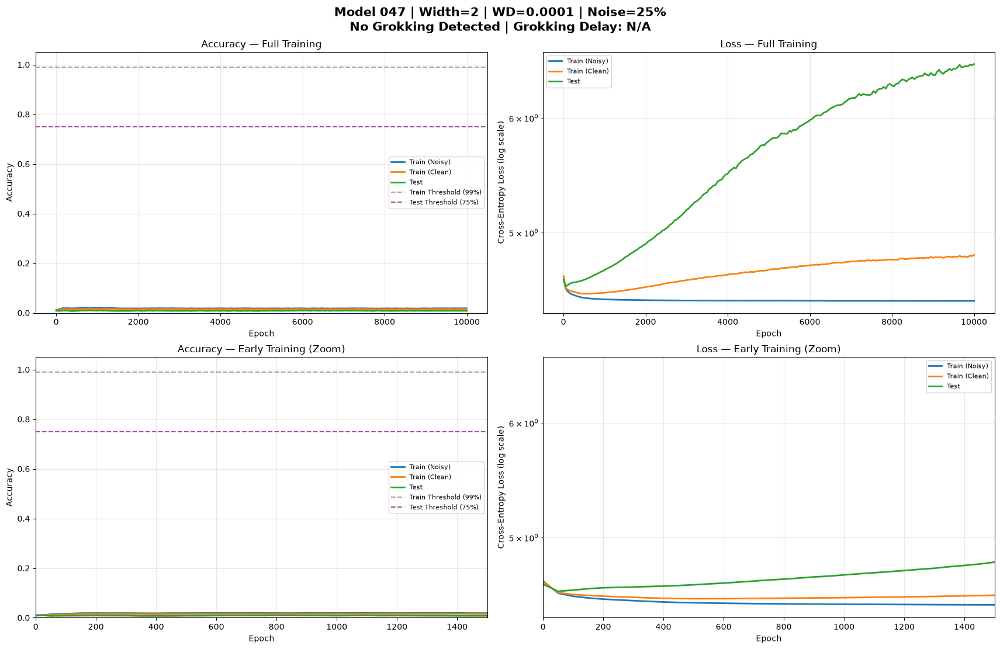

Training Models:  16%|█▌        | 48/308 [00:47<03:59,  1.09model/s]

Model 48: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_048/learning_curves.png


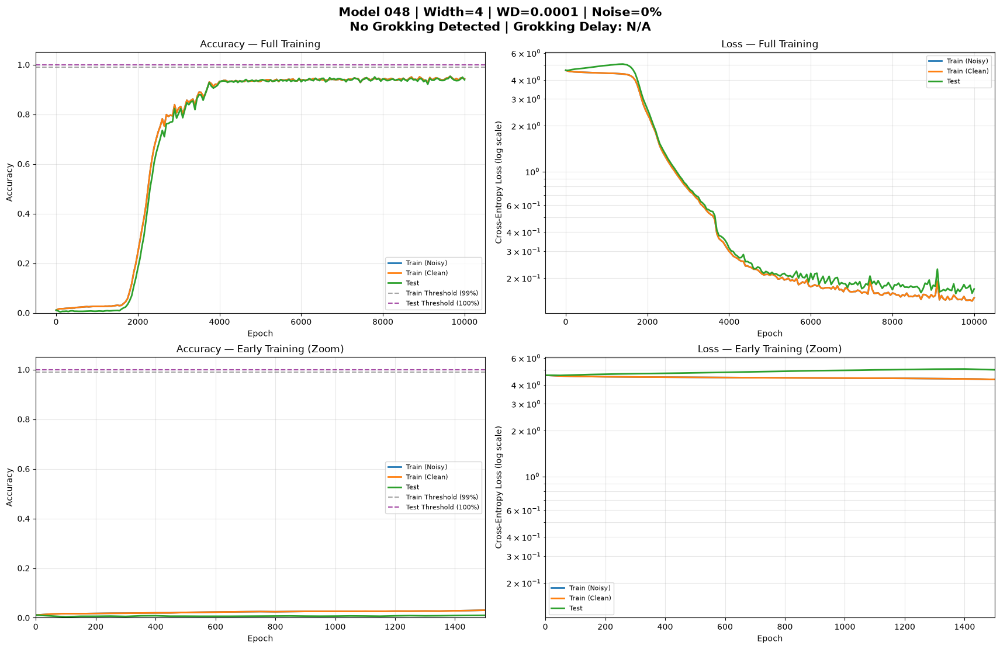

Training Models:  16%|█▌        | 49/308 [00:48<04:07,  1.05model/s]

Model 49: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_049/learning_curves.png


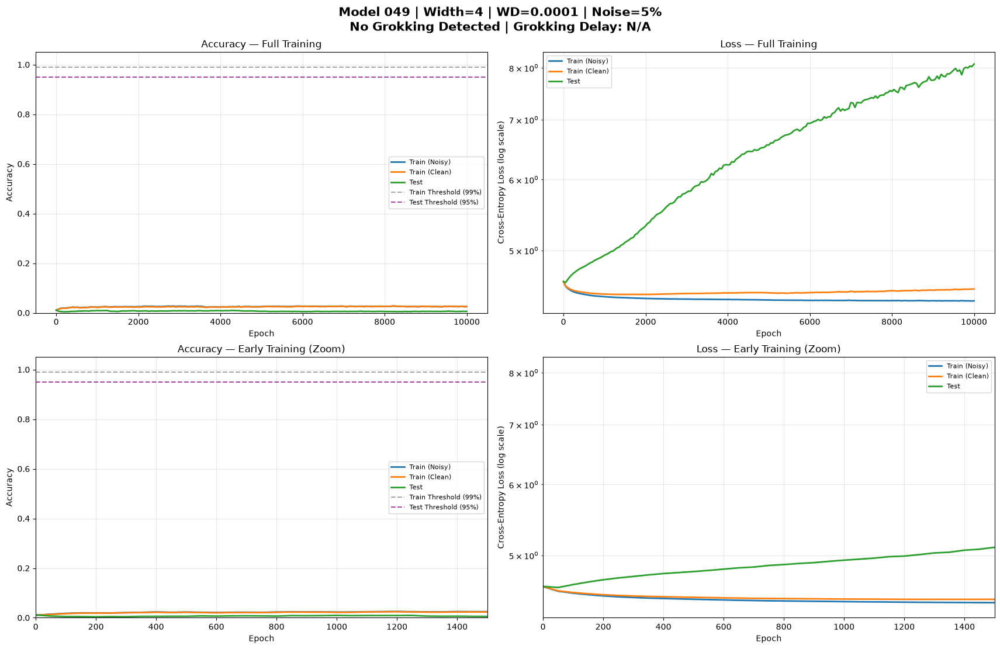

Training Models:  16%|█▌        | 50/308 [00:49<04:09,  1.03model/s]

Model 50: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_050/learning_curves.png


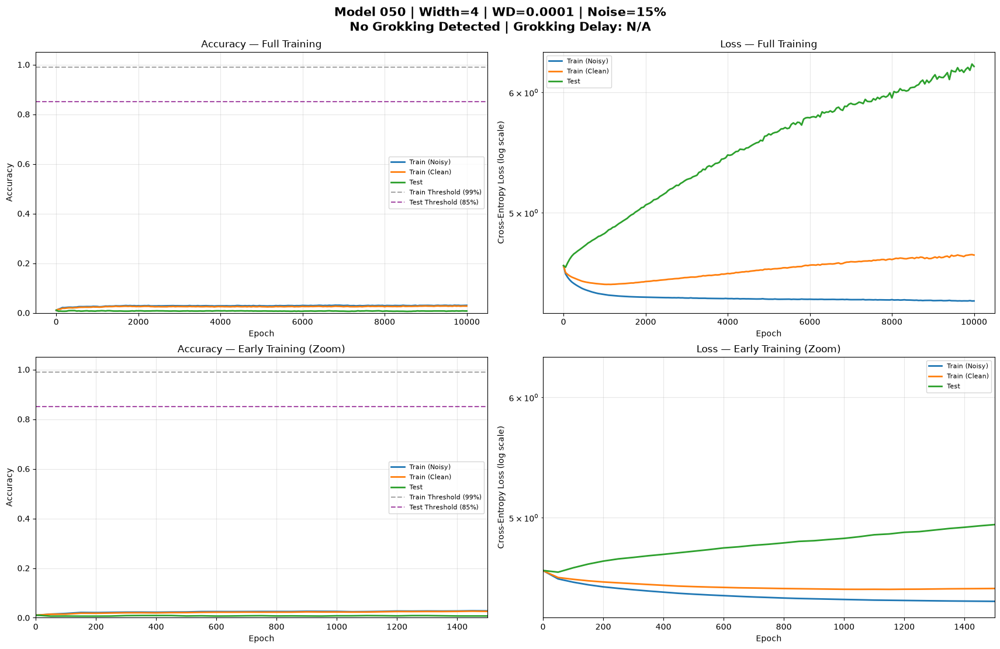

Training Models:  17%|█▋        | 51/308 [00:50<03:58,  1.08model/s]

Model 51: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_051/learning_curves.png


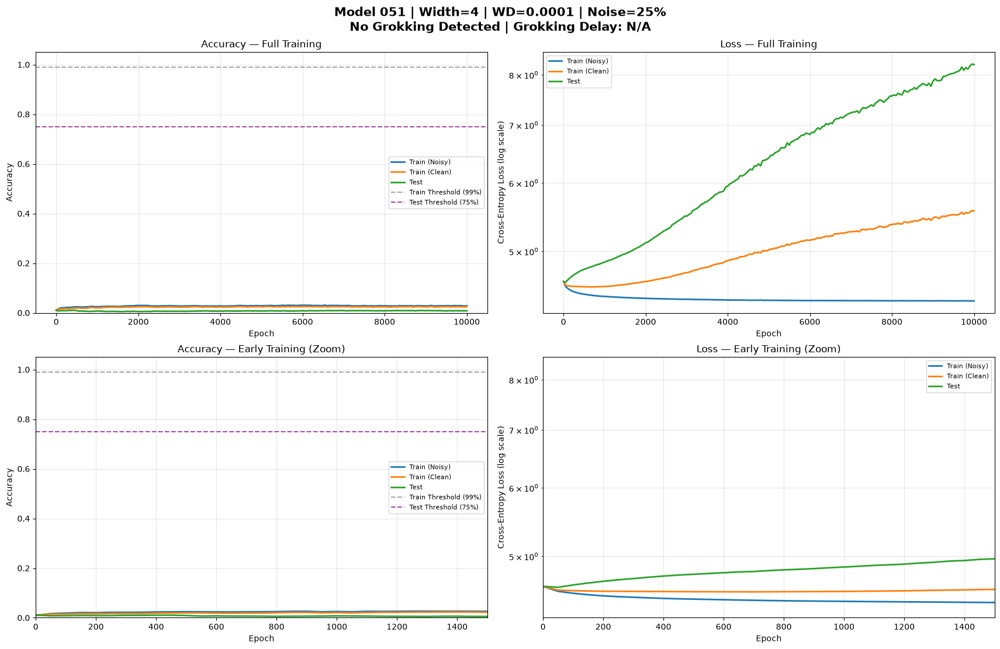

Training Models:  17%|█▋        | 52/308 [00:51<03:52,  1.10model/s]

Model 52: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_052/learning_curves.png


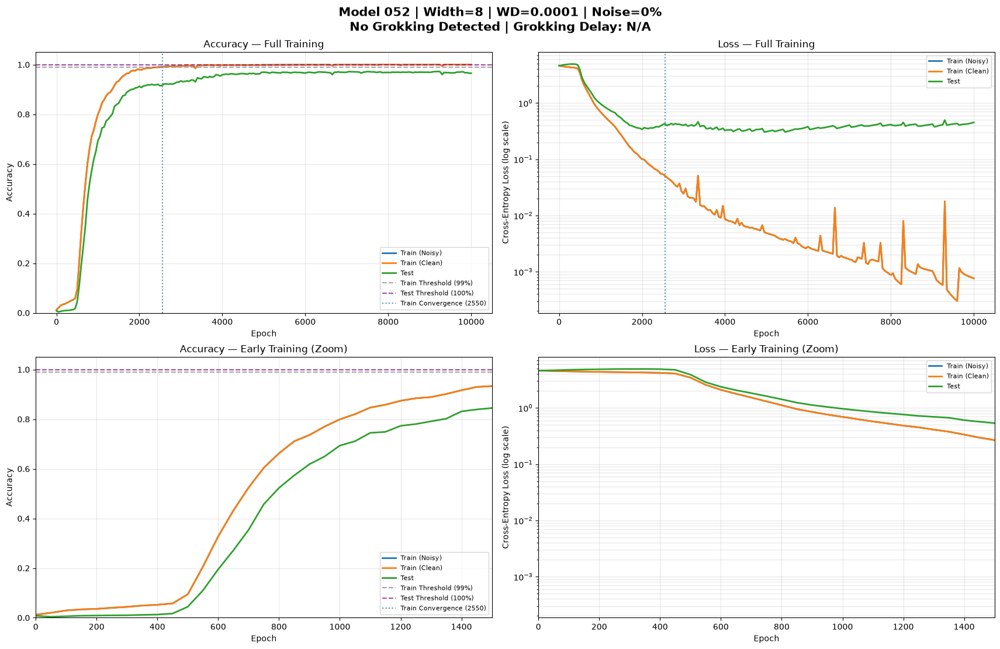

Training Models:  17%|█▋        | 53/308 [00:52<04:08,  1.03model/s]

Model 53: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_053/learning_curves.png


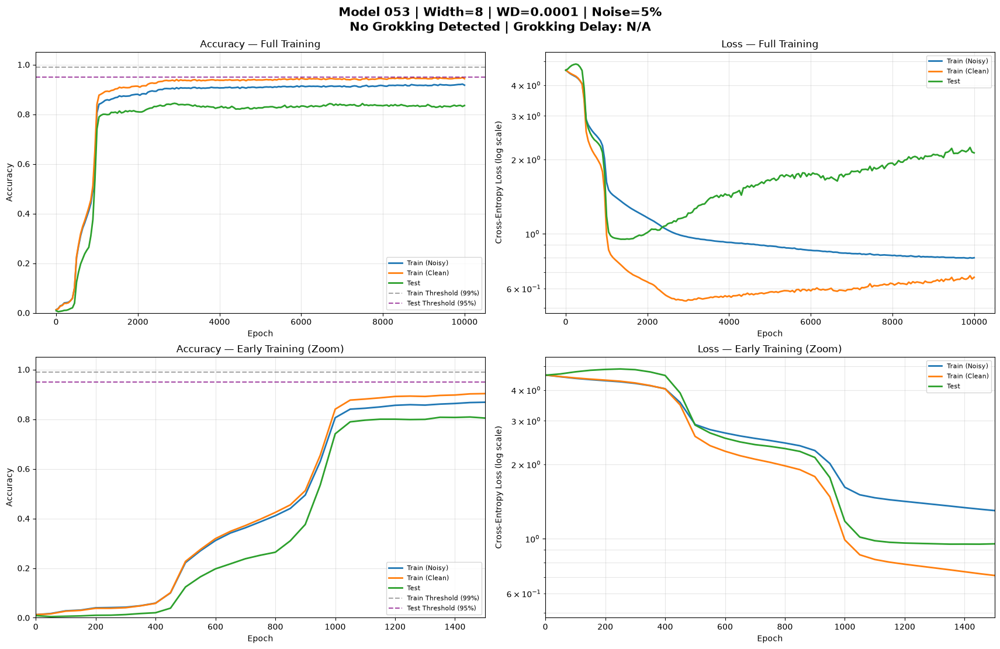

Training Models:  18%|█▊        | 54/308 [00:53<04:07,  1.03model/s]

Model 54: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_054/learning_curves.png


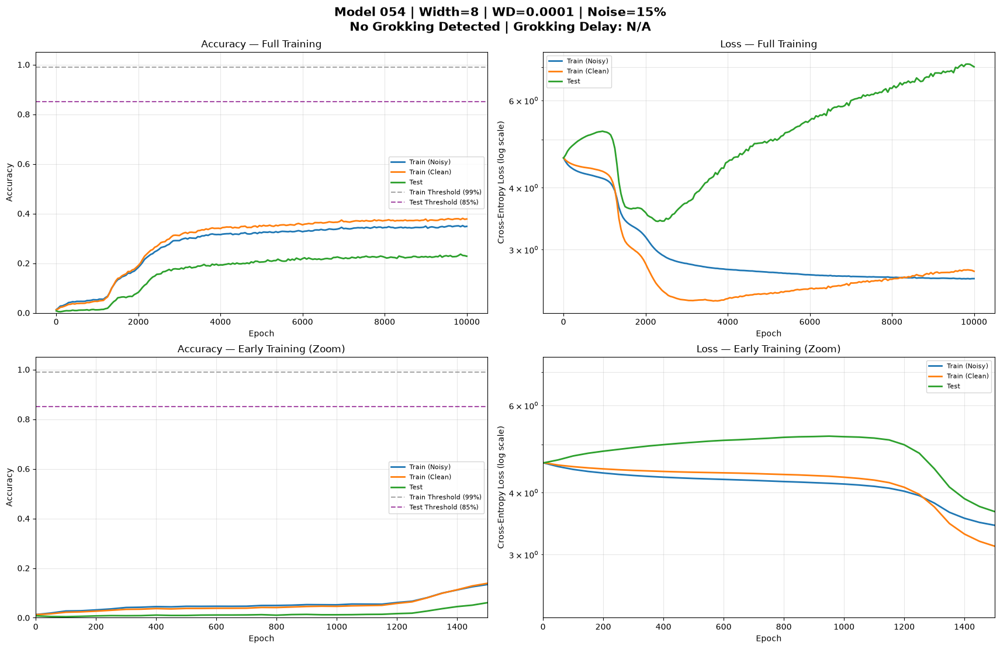

Training Models:  18%|█▊        | 55/308 [00:54<04:09,  1.02model/s]

Model 55: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_055/learning_curves.png


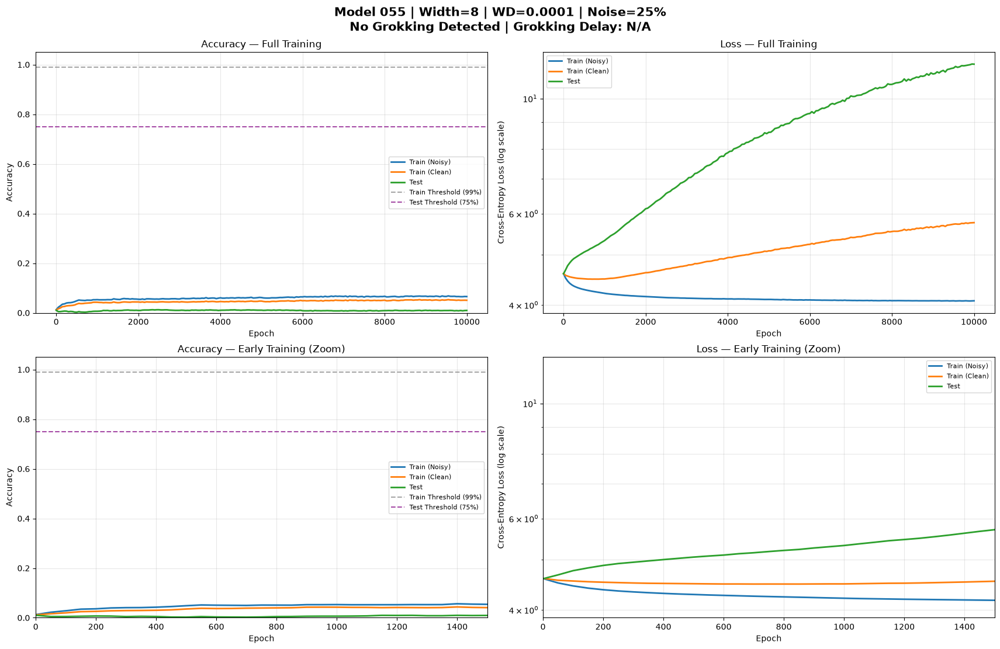

Training Models:  18%|█▊        | 56/308 [00:55<04:02,  1.04model/s]

Model 56: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_056/learning_curves.png


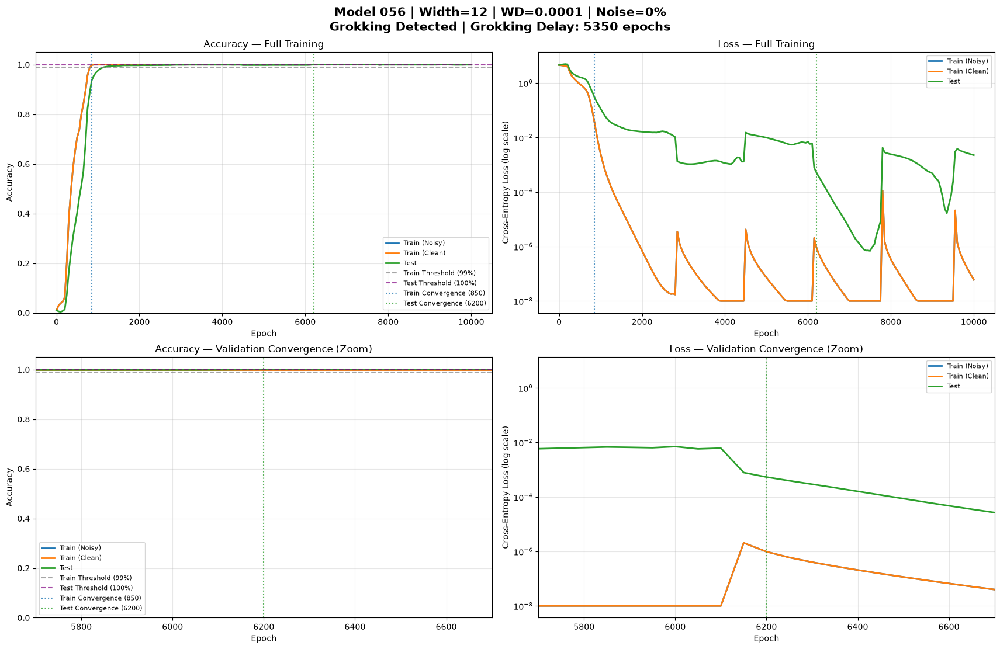

Training Models:  19%|█▊        | 57/308 [00:56<03:56,  1.06model/s]

Model 57: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_057/learning_curves.png


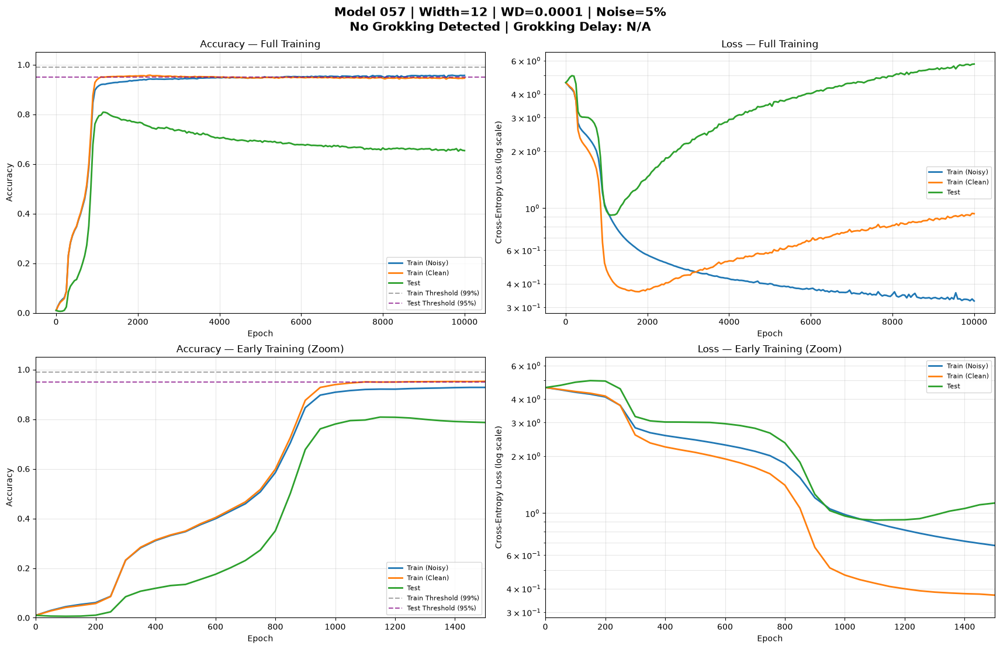

Training Models:  19%|█▉        | 58/308 [00:57<04:03,  1.03model/s]

Model 58: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_058/learning_curves.png


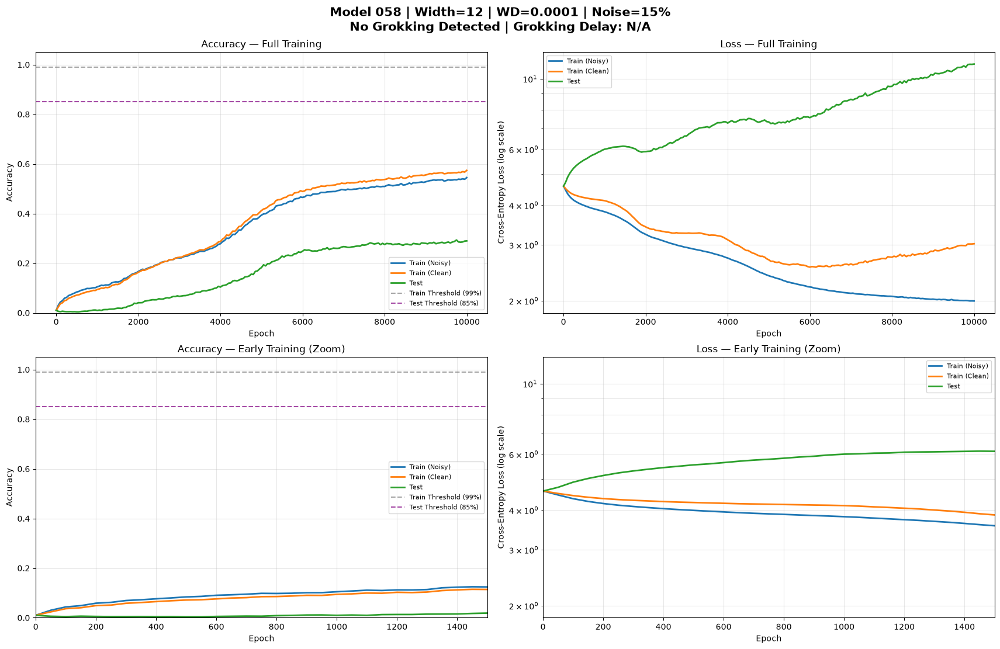

Training Models:  19%|█▉        | 59/308 [00:58<04:10,  1.01s/model]

Model 59: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_059/learning_curves.png


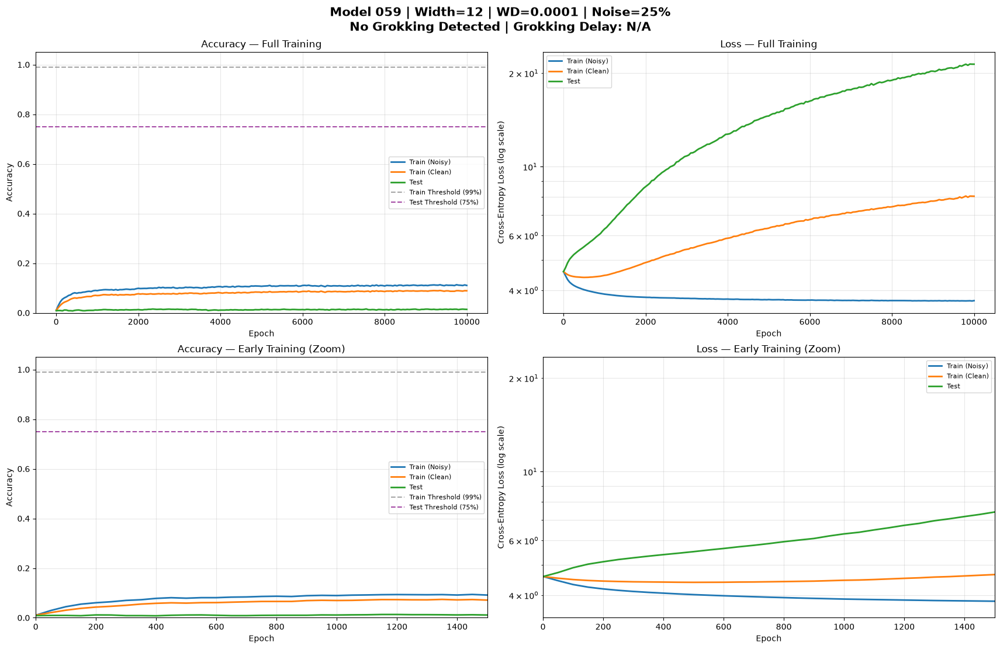

Training Models:  19%|█▉        | 60/308 [00:59<04:02,  1.02model/s]

Model 60: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_060/learning_curves.png


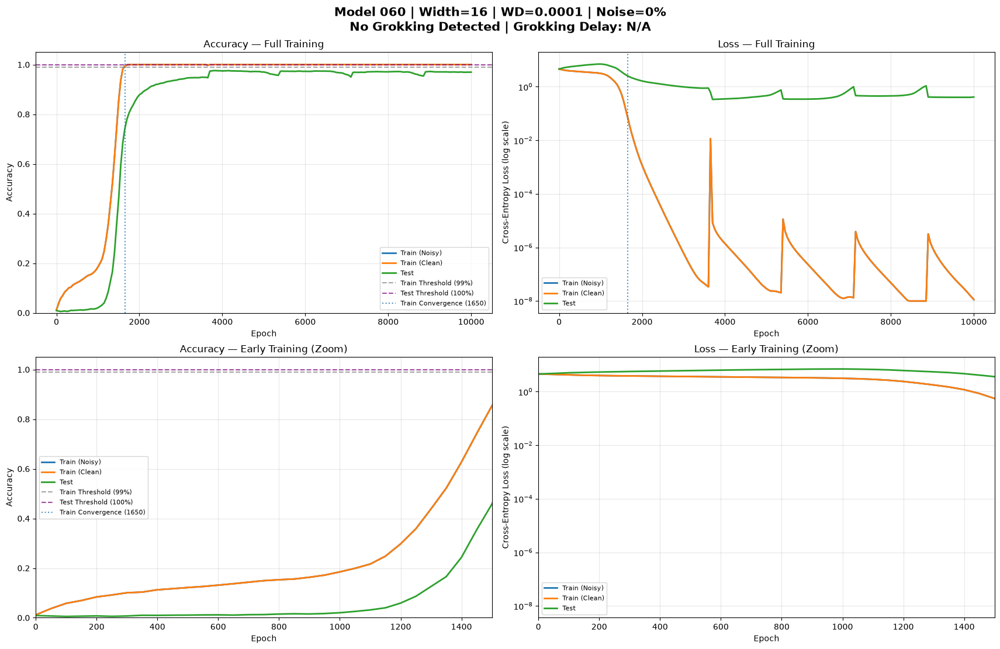

Training Models:  20%|█▉        | 61/308 [01:00<03:56,  1.05model/s]

Model 61: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_061/learning_curves.png


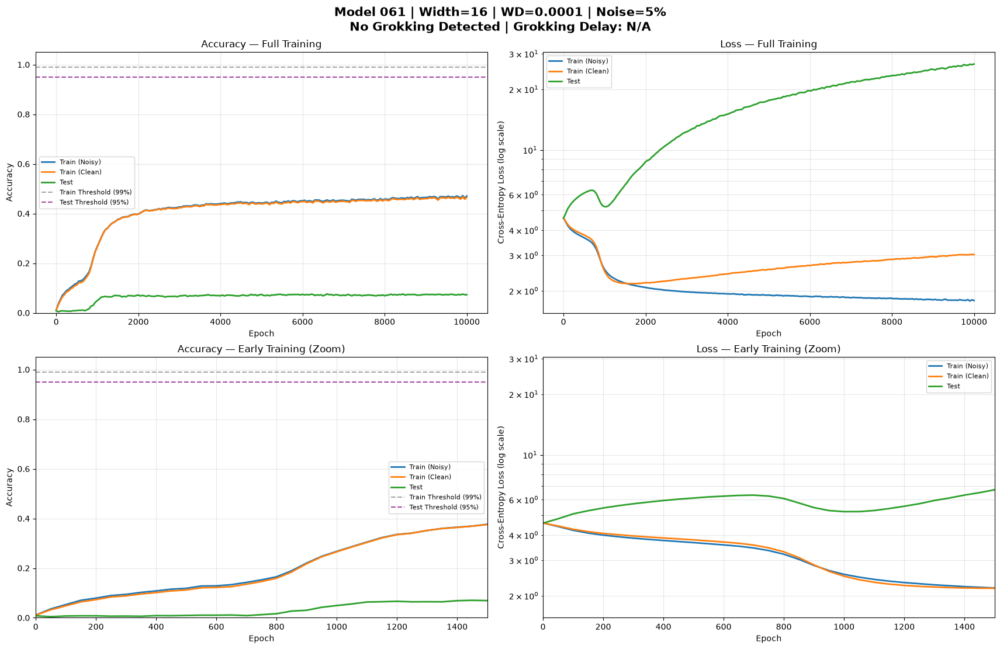

Training Models:  20%|██        | 62/308 [01:01<03:58,  1.03model/s]

Model 62: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_062/learning_curves.png


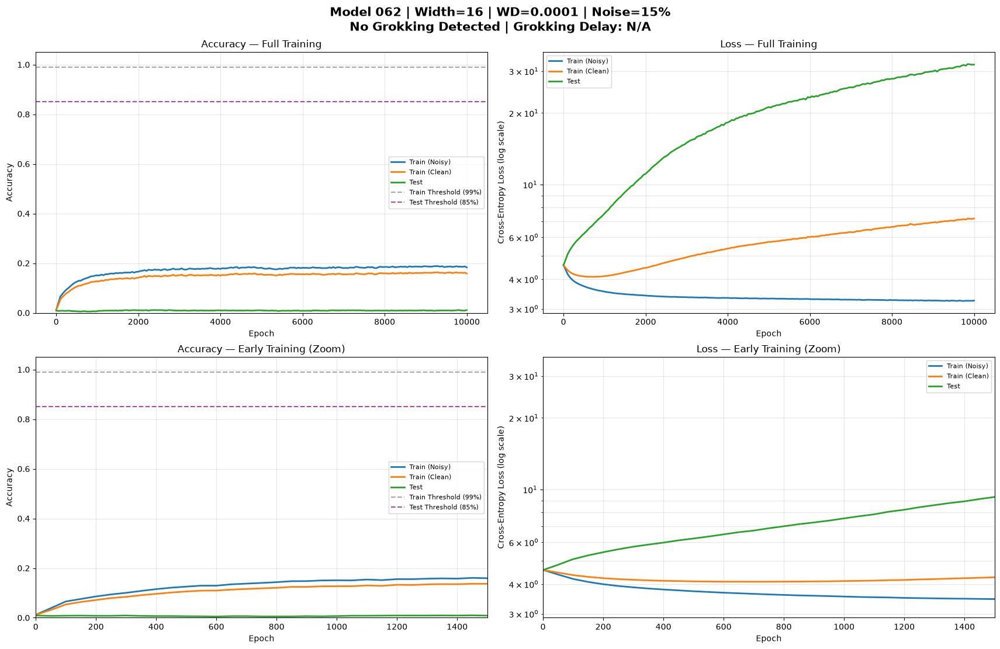

Training Models:  20%|██        | 63/308 [01:02<03:57,  1.03model/s]

Model 63: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_063/learning_curves.png


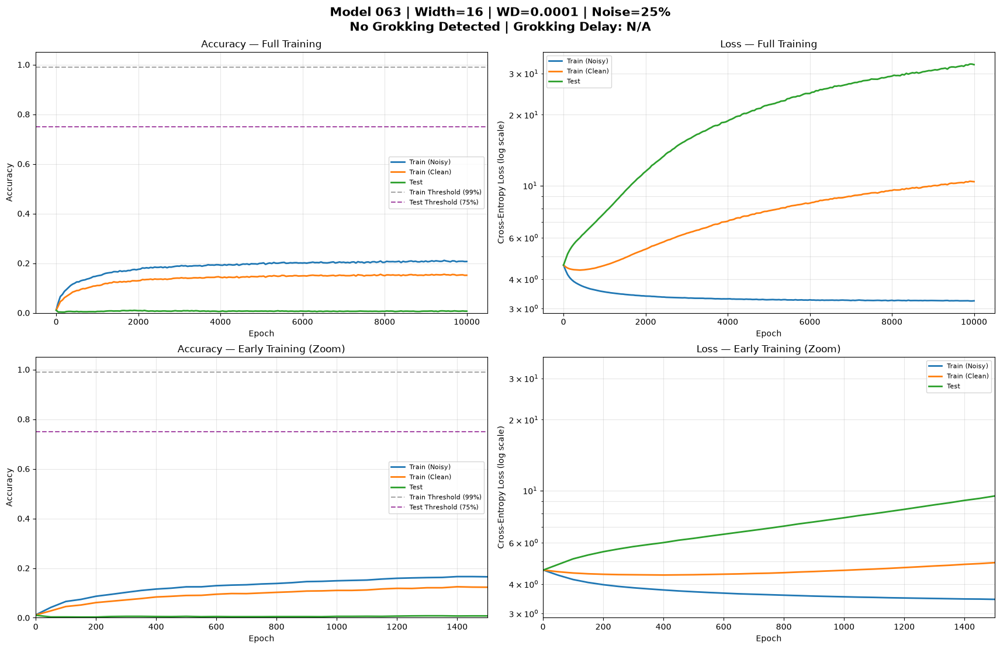

Training Models:  21%|██        | 64/308 [01:03<04:11,  1.03s/model]

Model 64: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_064/learning_curves.png


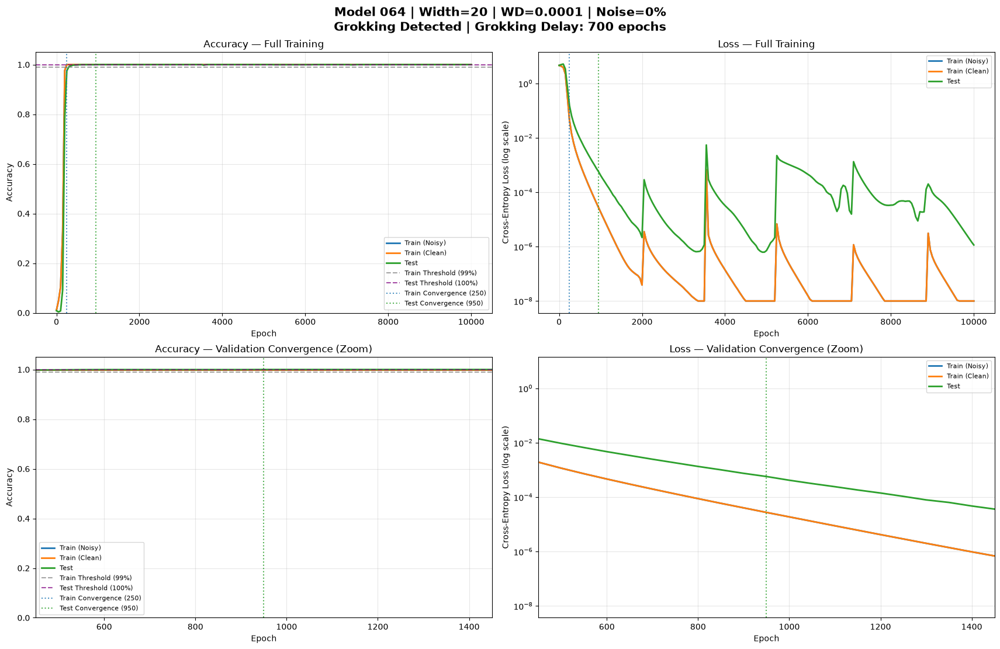

Training Models:  21%|██        | 65/308 [01:04<04:02,  1.00model/s]

Model 65: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_065/learning_curves.png


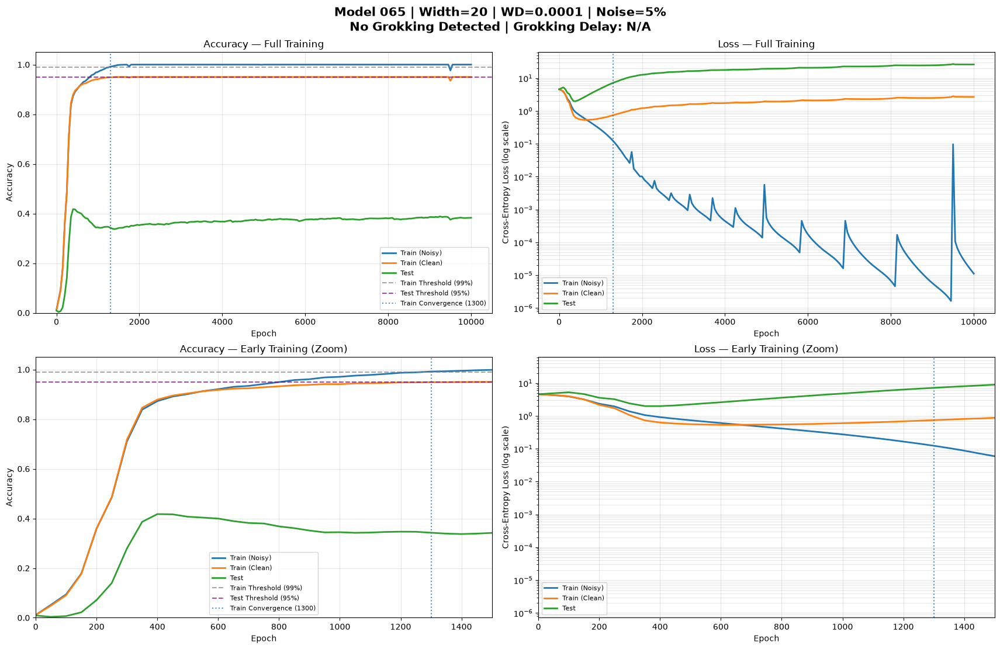

Training Models:  21%|██▏       | 66/308 [01:05<04:32,  1.13s/model]

Model 66: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_066/learning_curves.png


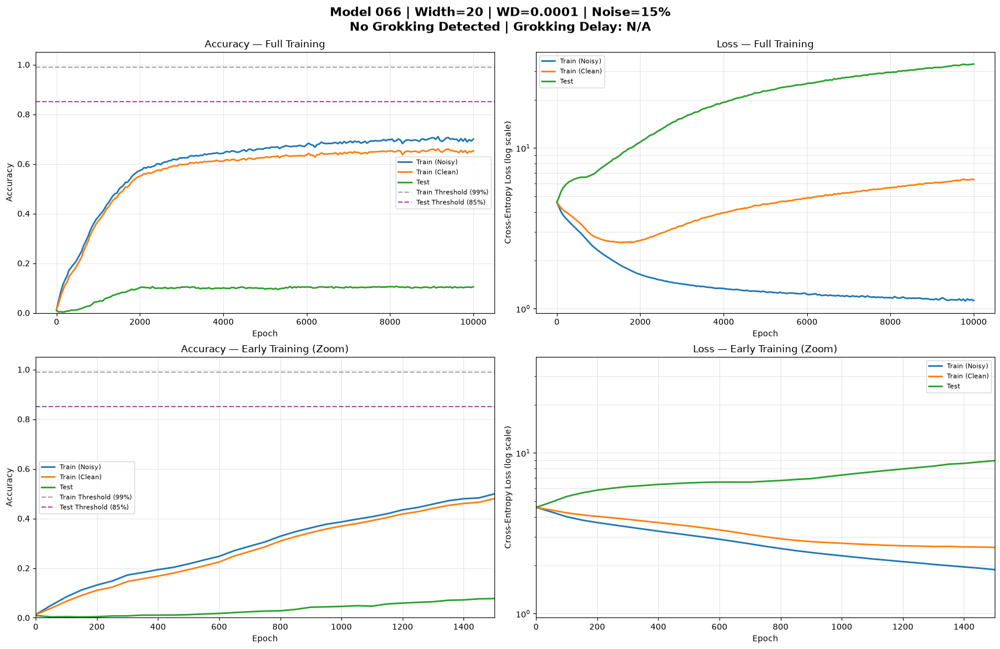

Training Models:  22%|██▏       | 67/308 [01:06<04:16,  1.06s/model]

Model 67: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_067/learning_curves.png


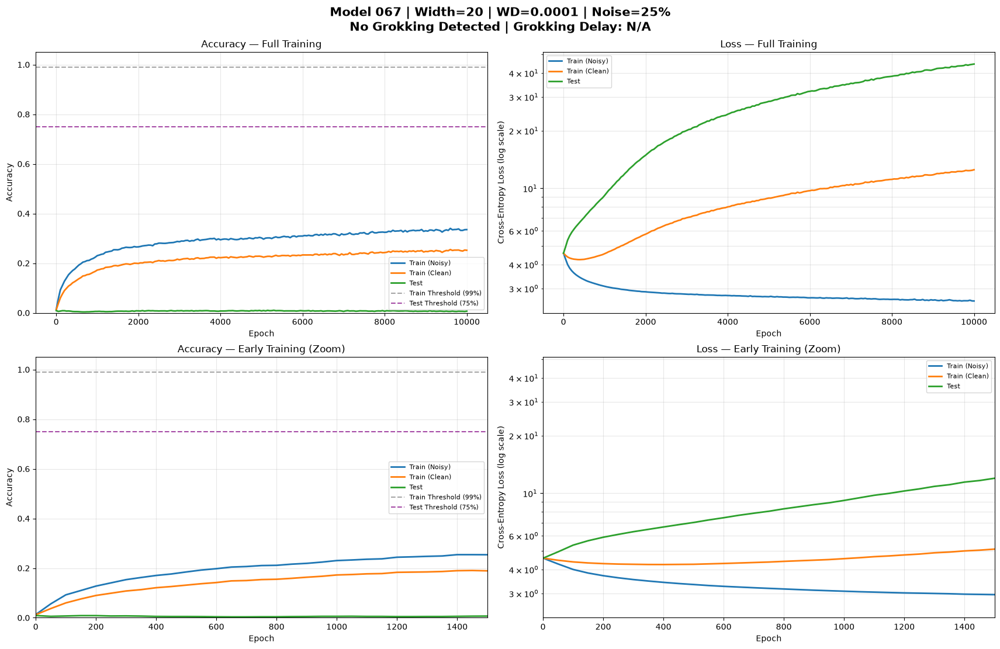

Training Models:  22%|██▏       | 68/308 [01:07<04:22,  1.09s/model]

Model 68: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_068/learning_curves.png


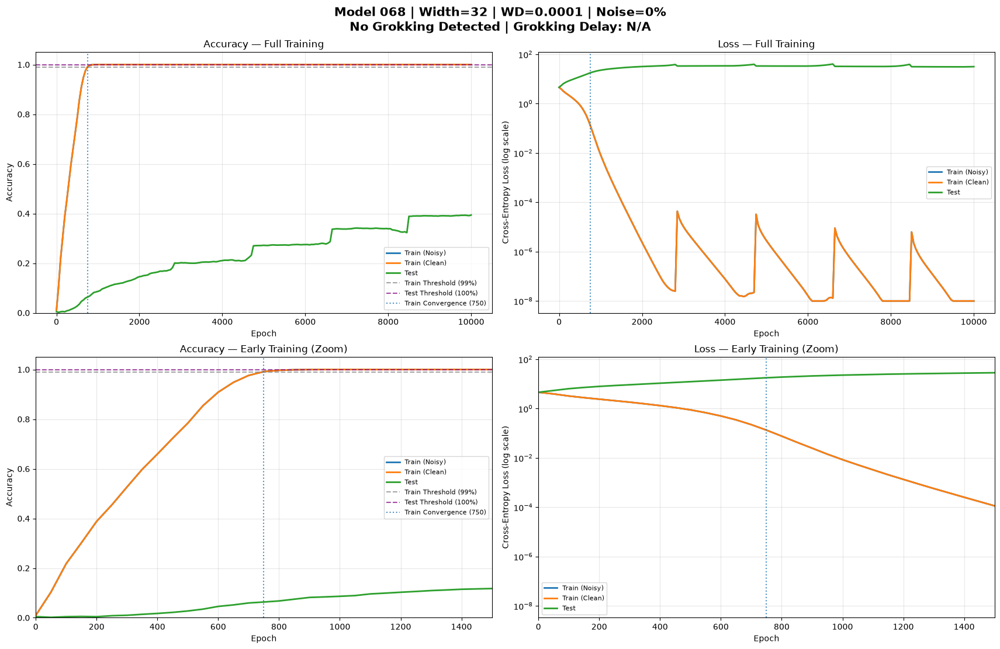

Training Models:  22%|██▏       | 69/308 [01:08<04:09,  1.04s/model]

Model 69: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_069/learning_curves.png


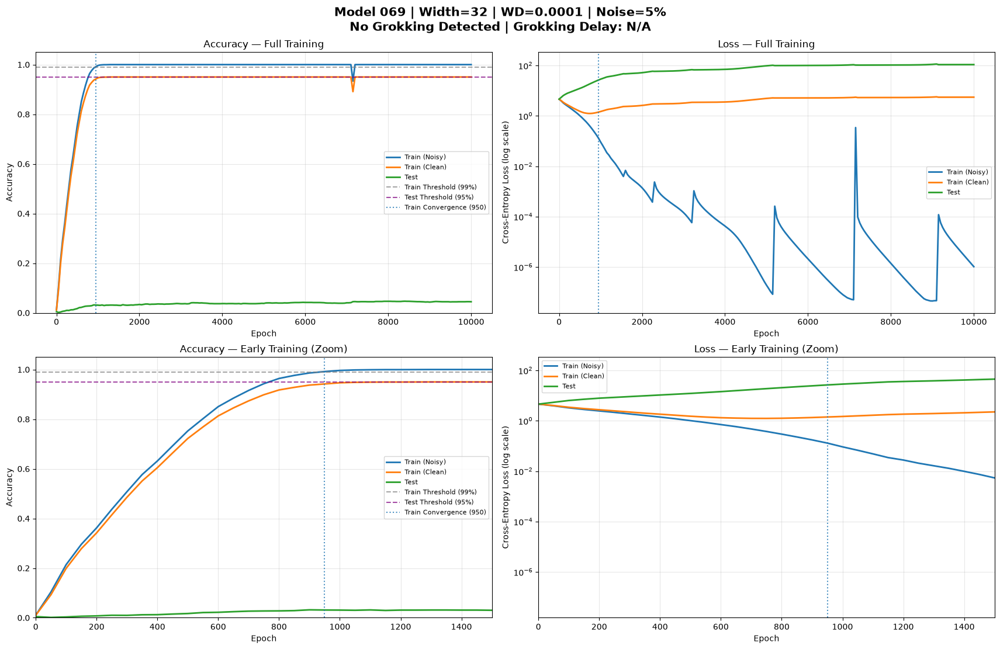

Training Models:  23%|██▎       | 70/308 [01:09<04:01,  1.01s/model]

Model 70: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_070/learning_curves.png


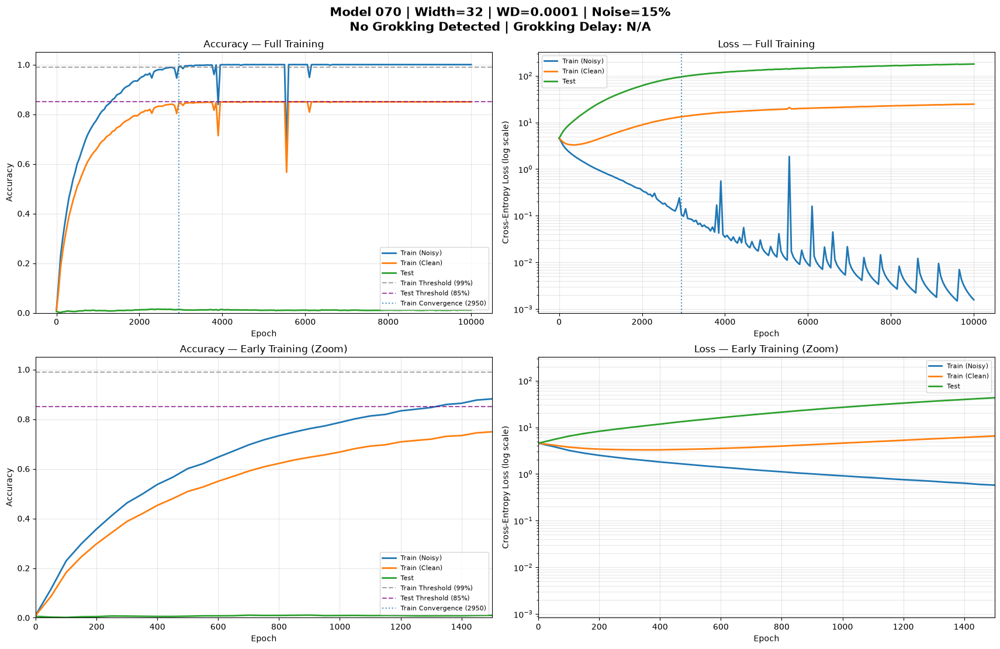

Training Models:  23%|██▎       | 71/308 [01:11<04:15,  1.08s/model]

Model 71: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_071/learning_curves.png


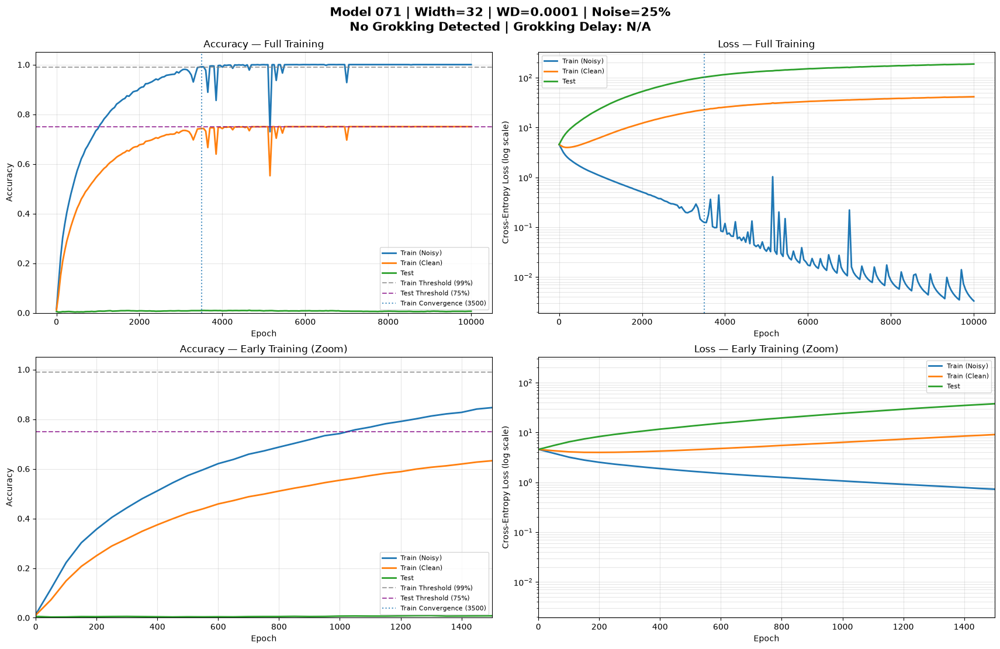

Training Models:  23%|██▎       | 72/308 [01:12<04:33,  1.16s/model]

Model 72: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_072/learning_curves.png


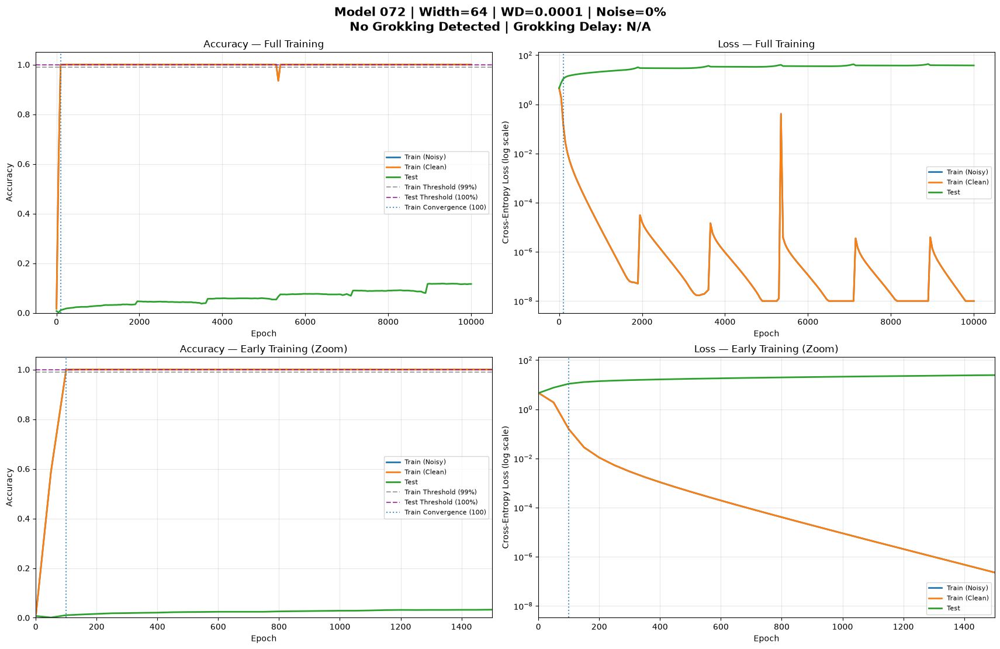

Training Models:  24%|██▎       | 73/308 [01:13<04:16,  1.09s/model]

Model 73: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_073/learning_curves.png


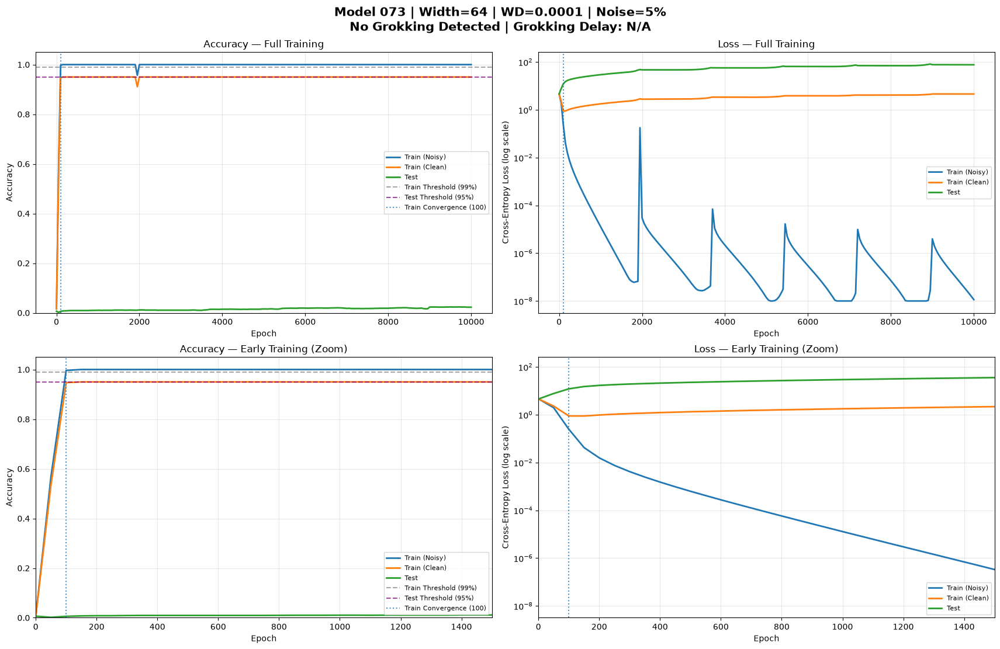

Training Models:  24%|██▍       | 74/308 [01:14<04:04,  1.05s/model]

Model 74: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_074/learning_curves.png


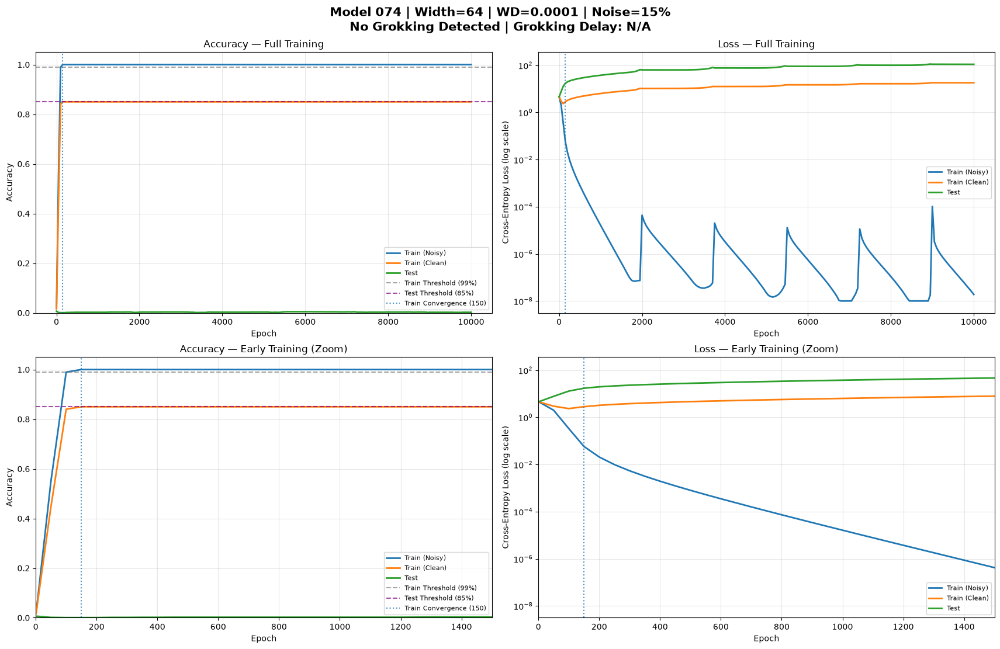

Training Models:  24%|██▍       | 75/308 [01:15<03:57,  1.02s/model]

Model 75: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_075/learning_curves.png


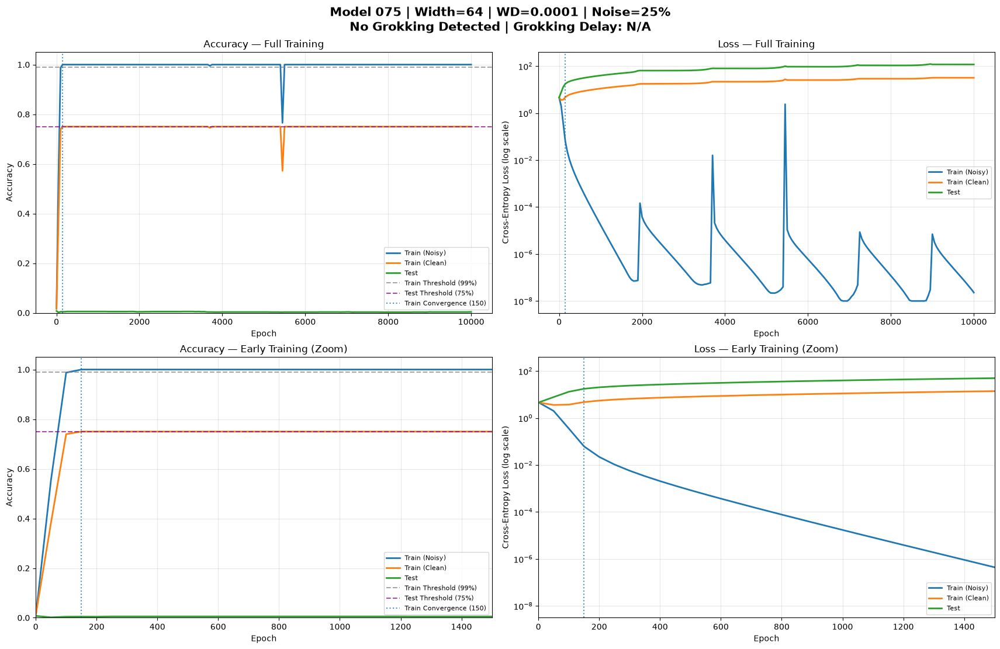

Training Models:  25%|██▍       | 76/308 [01:16<04:04,  1.05s/model]

Model 76: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_076/learning_curves.png


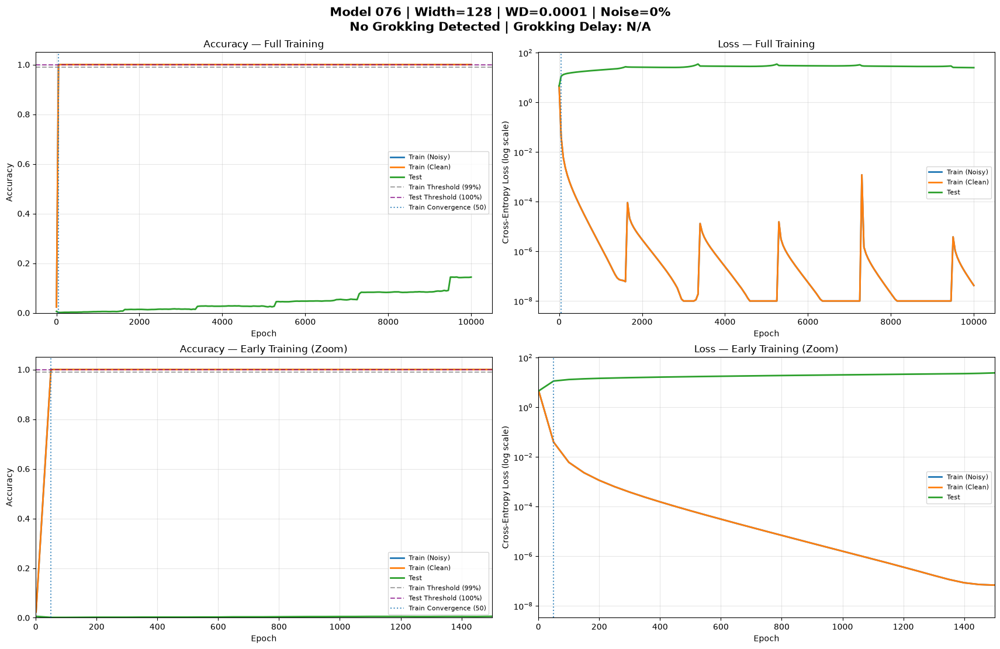

Training Models:  25%|██▌       | 77/308 [01:17<03:57,  1.03s/model]

Model 77: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_077/learning_curves.png


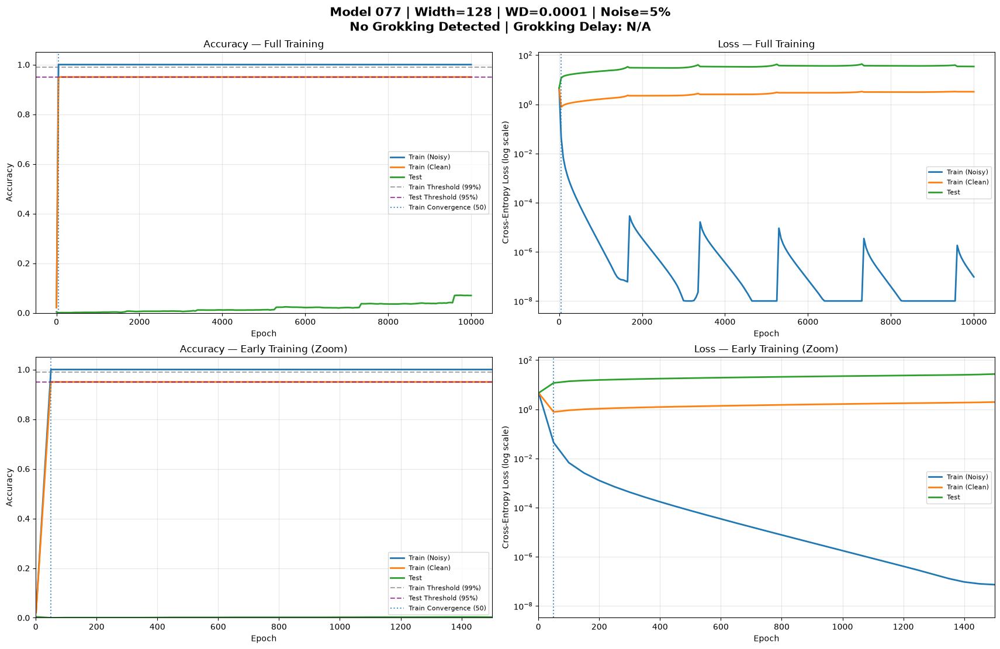

Training Models:  25%|██▌       | 78/308 [01:18<03:51,  1.01s/model]

Model 78: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_078/learning_curves.png


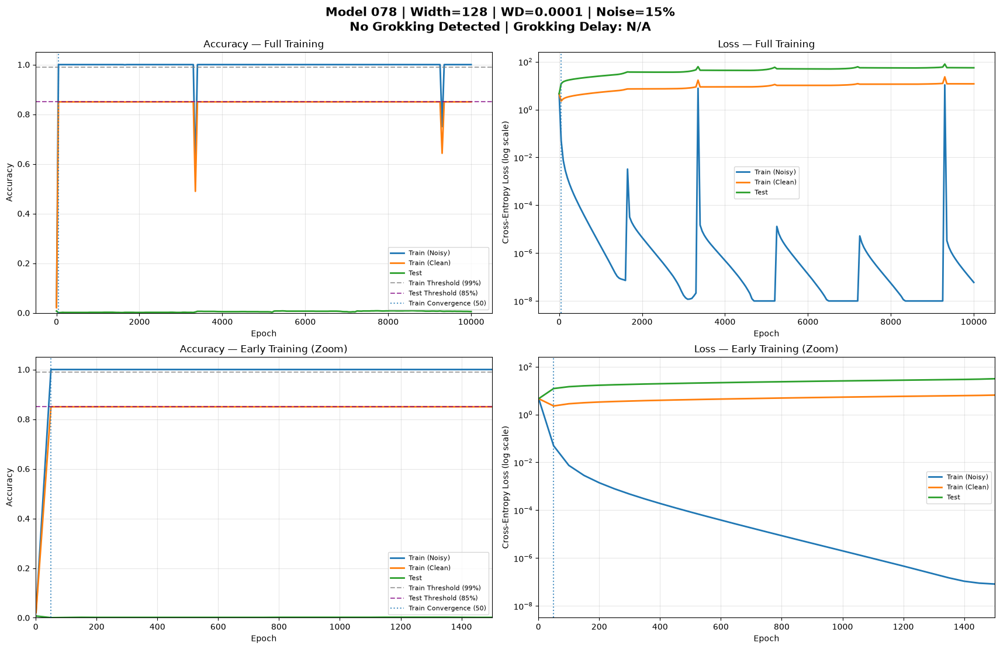

Training Models:  26%|██▌       | 79/308 [01:19<03:50,  1.01s/model]

Model 79: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_079/learning_curves.png


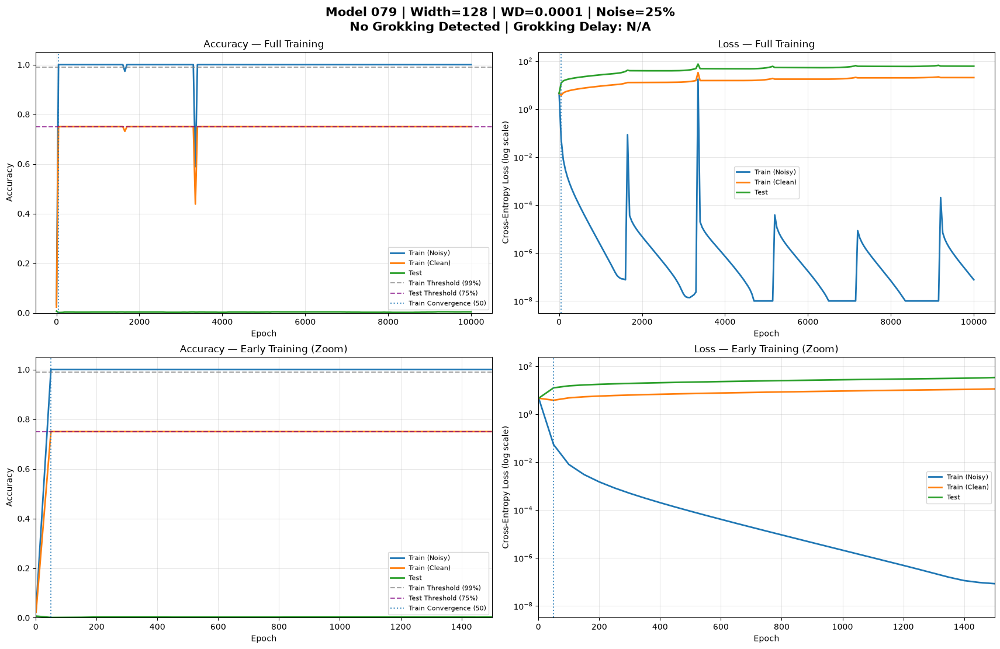

Training Models:  26%|██▌       | 80/308 [01:20<03:49,  1.01s/model]

Model 80: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_080/learning_curves.png


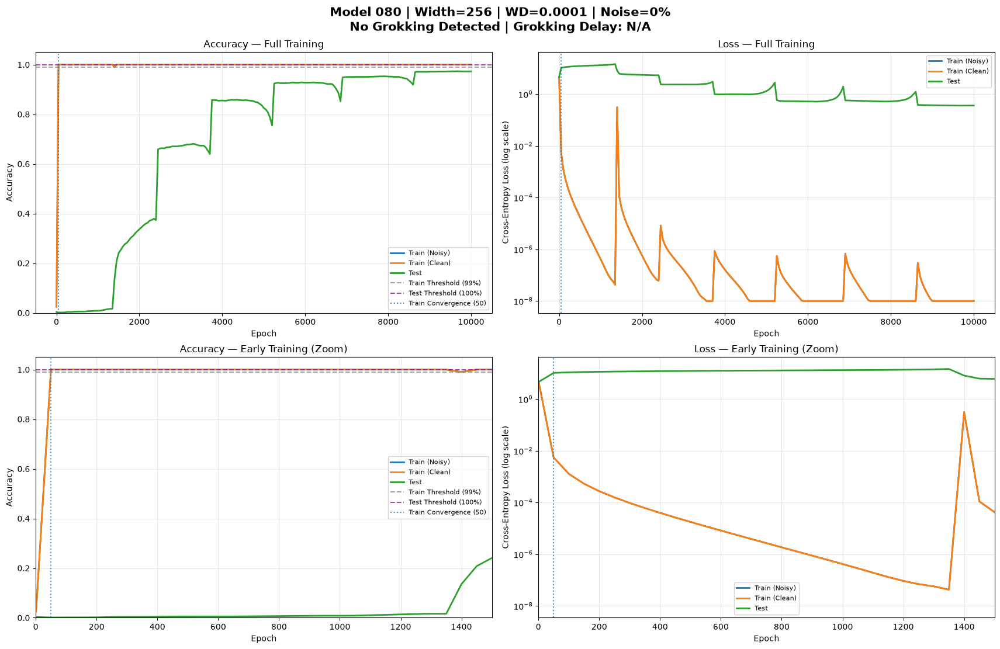

Training Models:  26%|██▋       | 81/308 [01:21<03:54,  1.03s/model]

Model 81: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_081/learning_curves.png


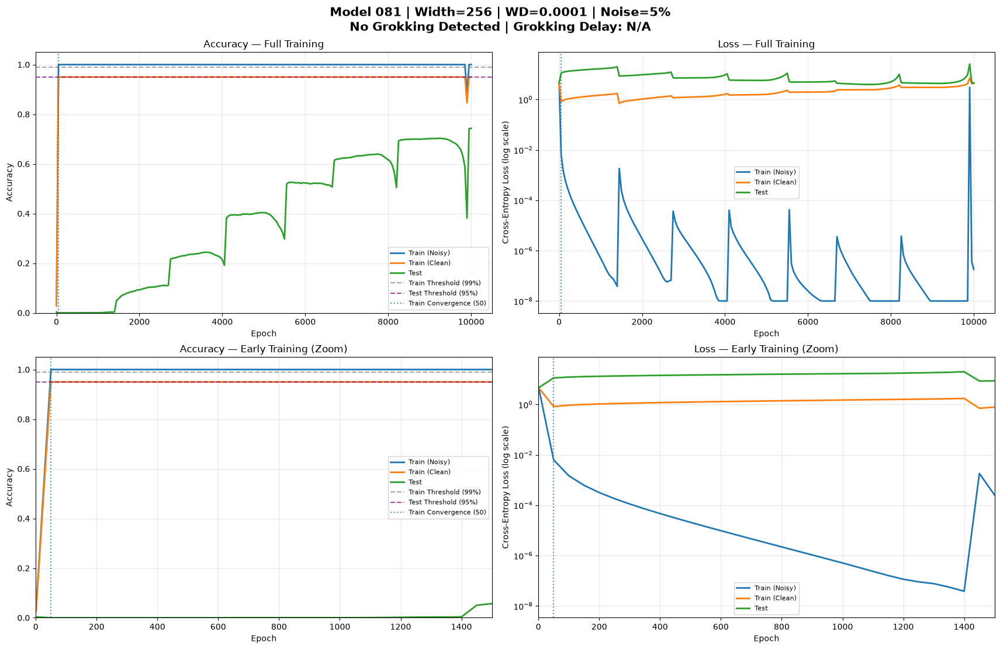

Training Models:  27%|██▋       | 82/308 [01:22<03:50,  1.02s/model]

Model 82: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_082/learning_curves.png


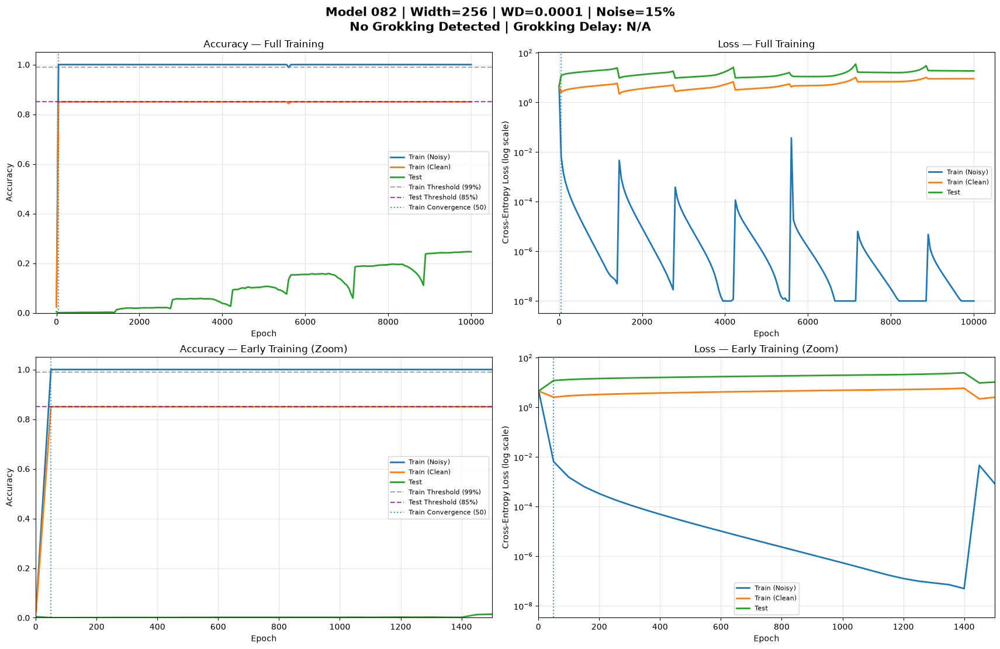

Training Models:  27%|██▋       | 83/308 [01:23<03:47,  1.01s/model]

Model 83: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_083/learning_curves.png


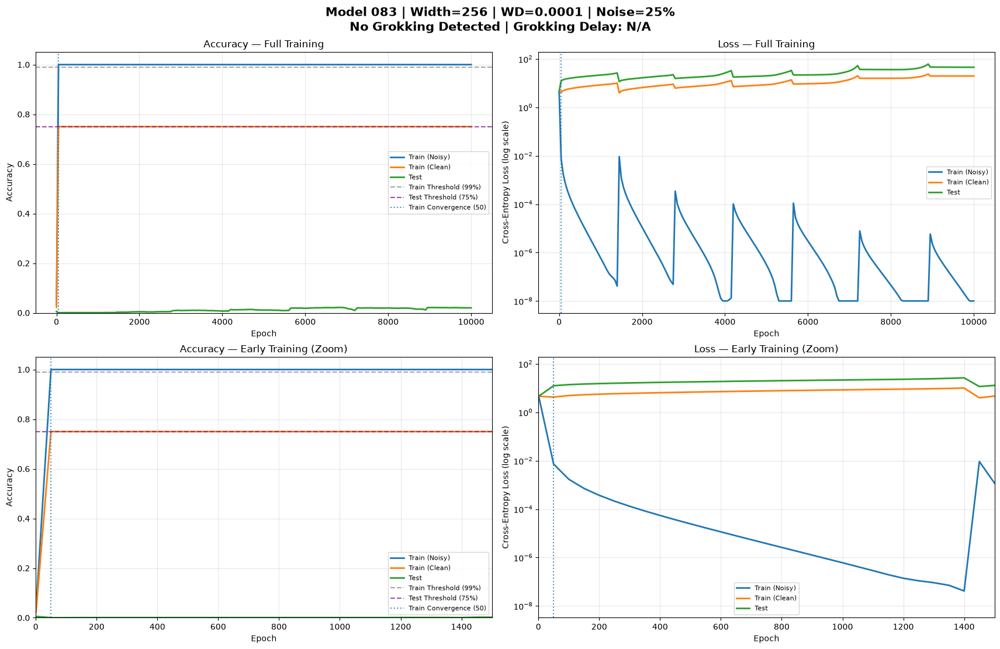

Training Models:  27%|██▋       | 84/308 [01:24<03:44,  1.00s/model]

Model 84: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_084/learning_curves.png


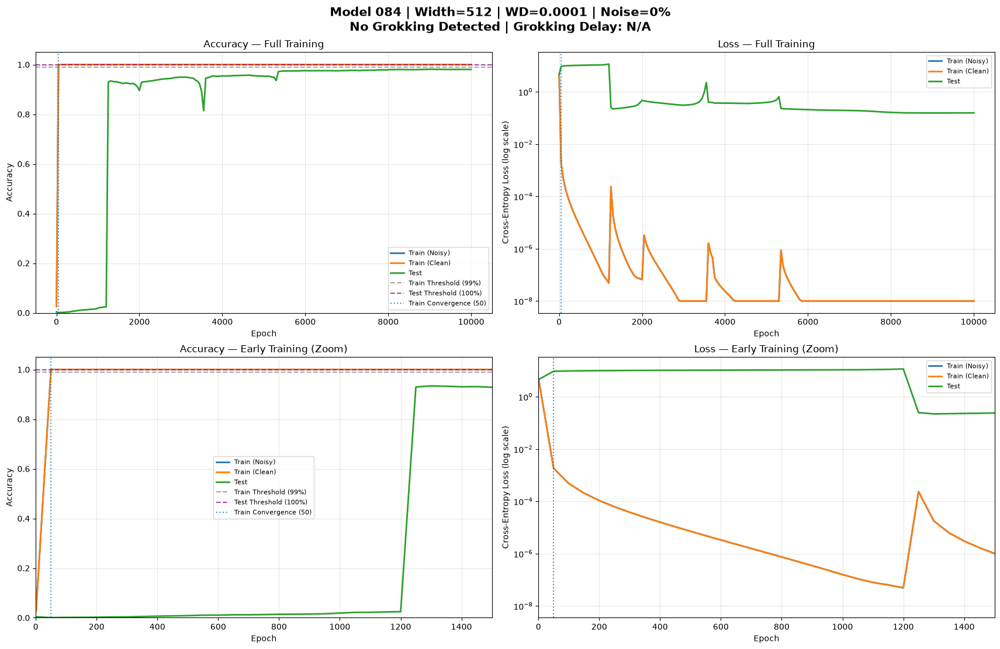

Training Models:  28%|██▊       | 85/308 [01:25<03:38,  1.02model/s]

Model 85: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_085/learning_curves.png


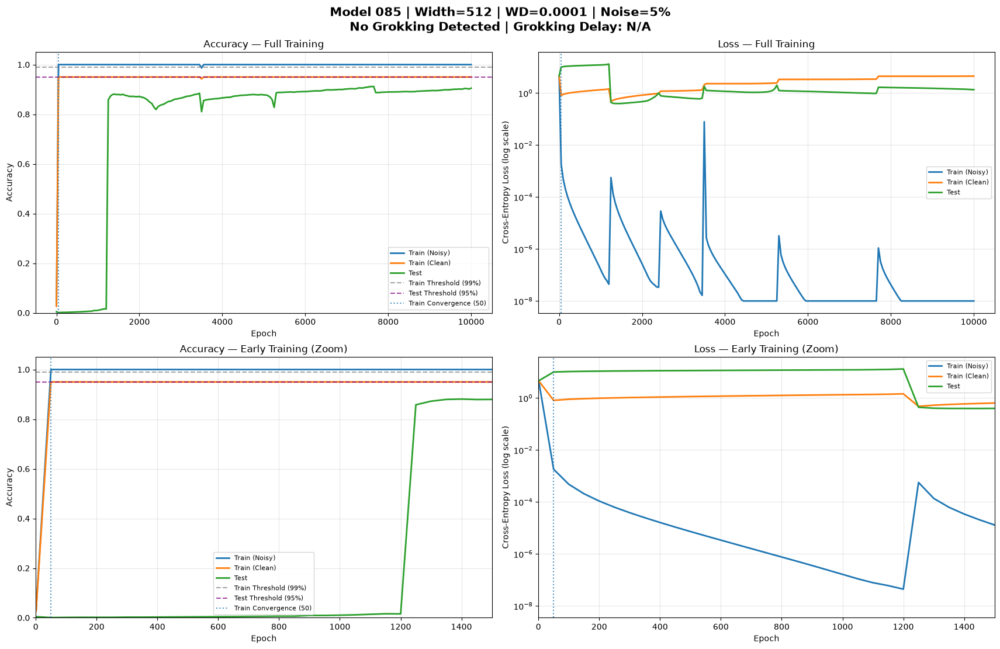

Training Models:  28%|██▊       | 86/308 [01:26<03:46,  1.02s/model]

Model 86: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_086/learning_curves.png


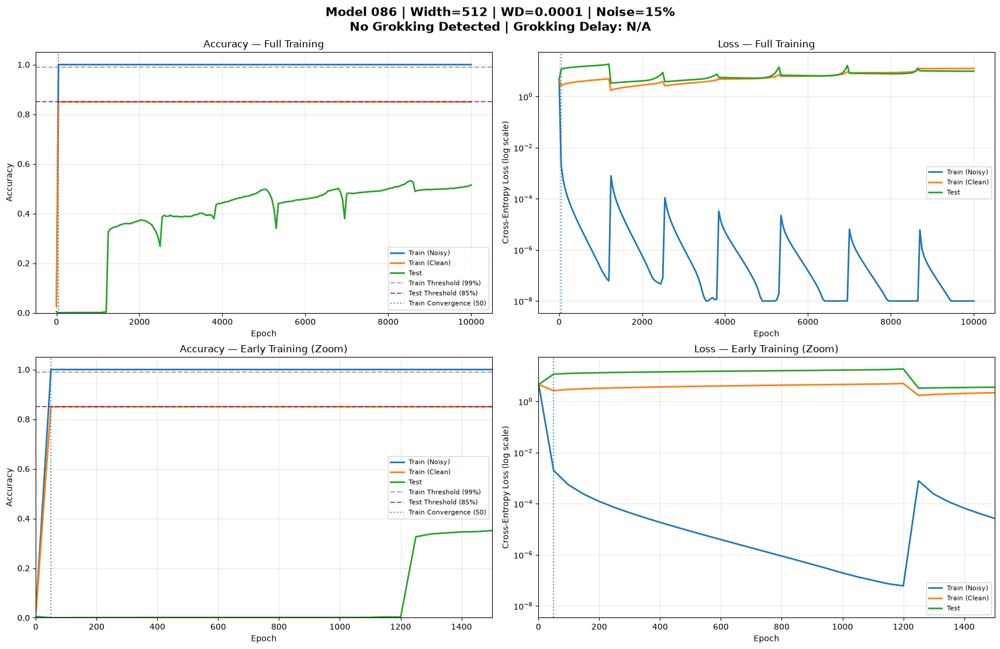

Training Models:  28%|██▊       | 87/308 [01:27<03:38,  1.01model/s]

Model 87: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_087/learning_curves.png


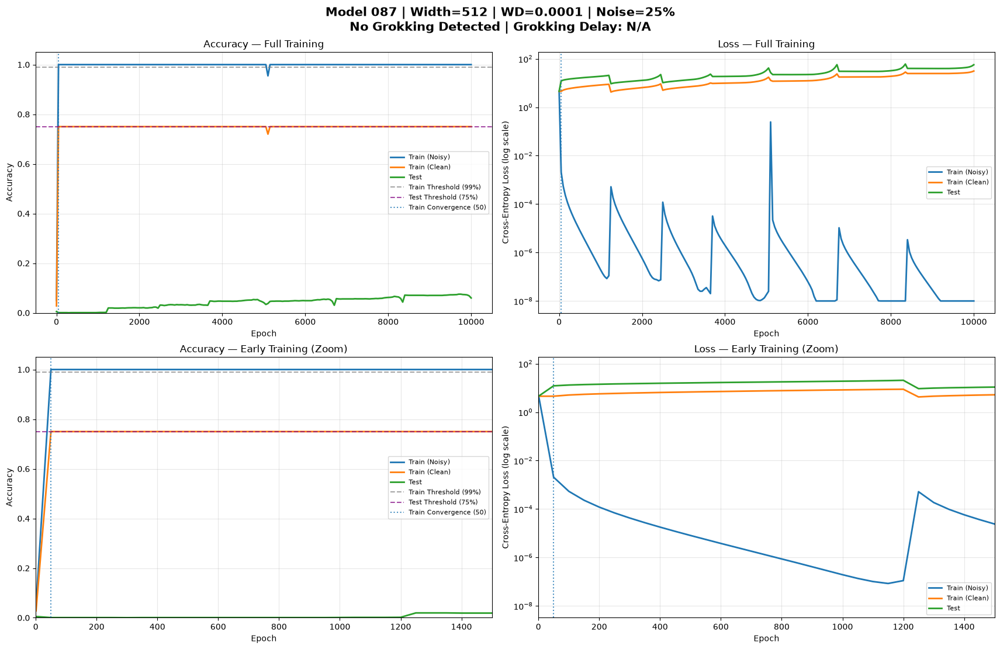

Training Models:  29%|██▊       | 88/308 [01:28<03:36,  1.02model/s]

Model 88: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_088/learning_curves.png


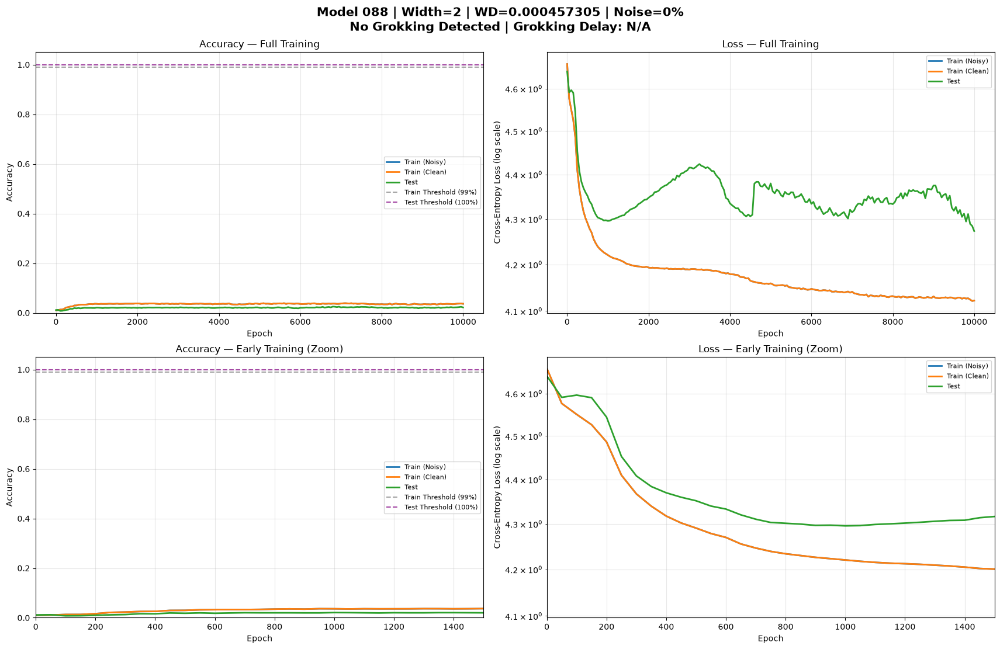

Training Models:  29%|██▉       | 89/308 [01:29<03:32,  1.03model/s]

Model 89: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_089/learning_curves.png


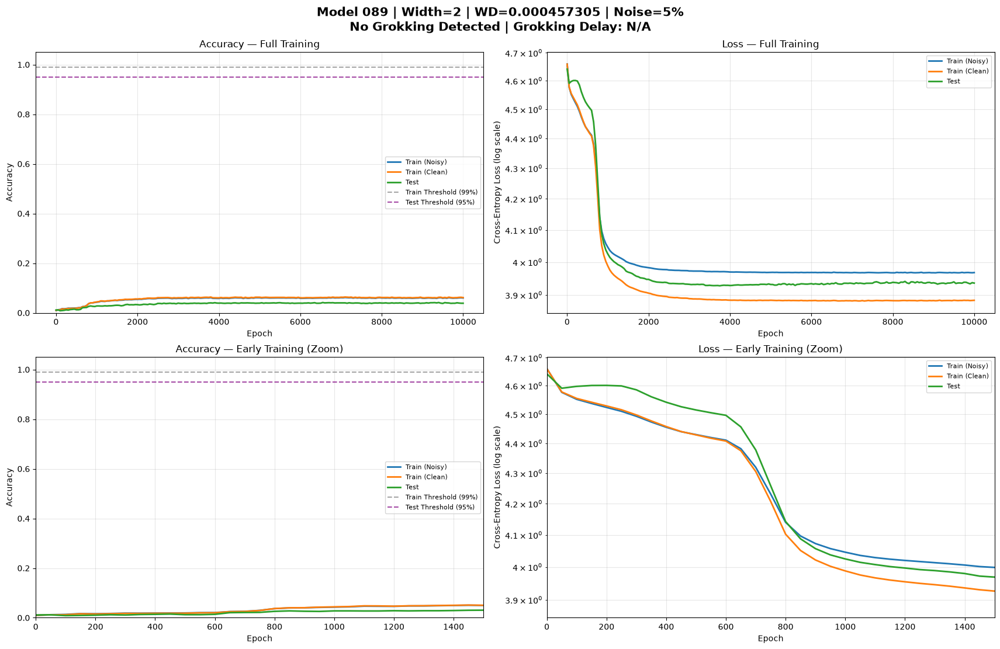

Training Models:  29%|██▉       | 90/308 [01:30<03:34,  1.02model/s]

Model 90: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_090/learning_curves.png


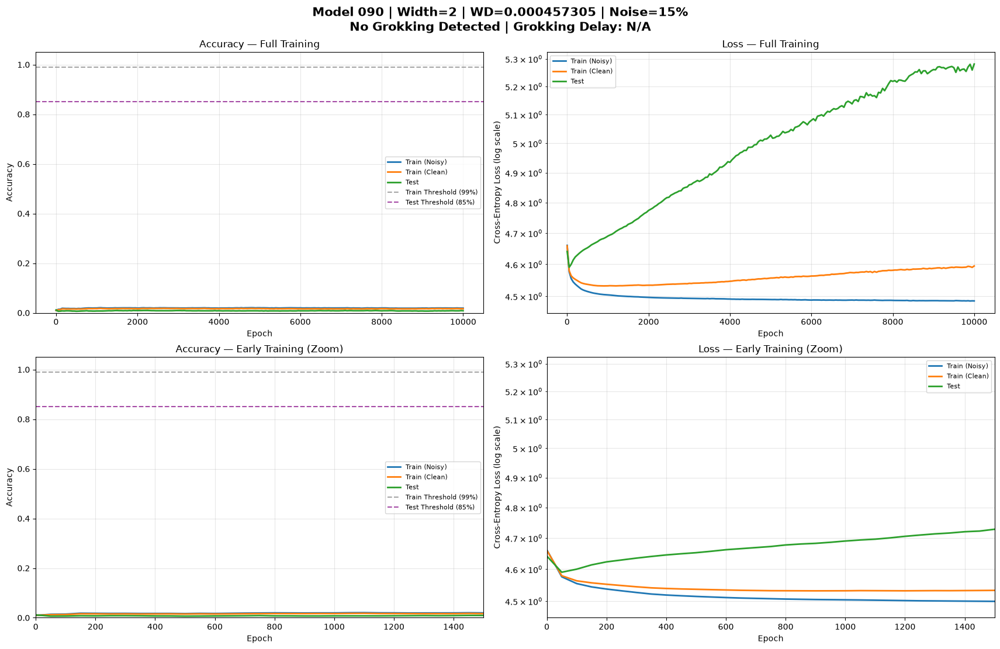

Training Models:  30%|██▉       | 91/308 [01:31<03:44,  1.04s/model]

Model 91: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_091/learning_curves.png


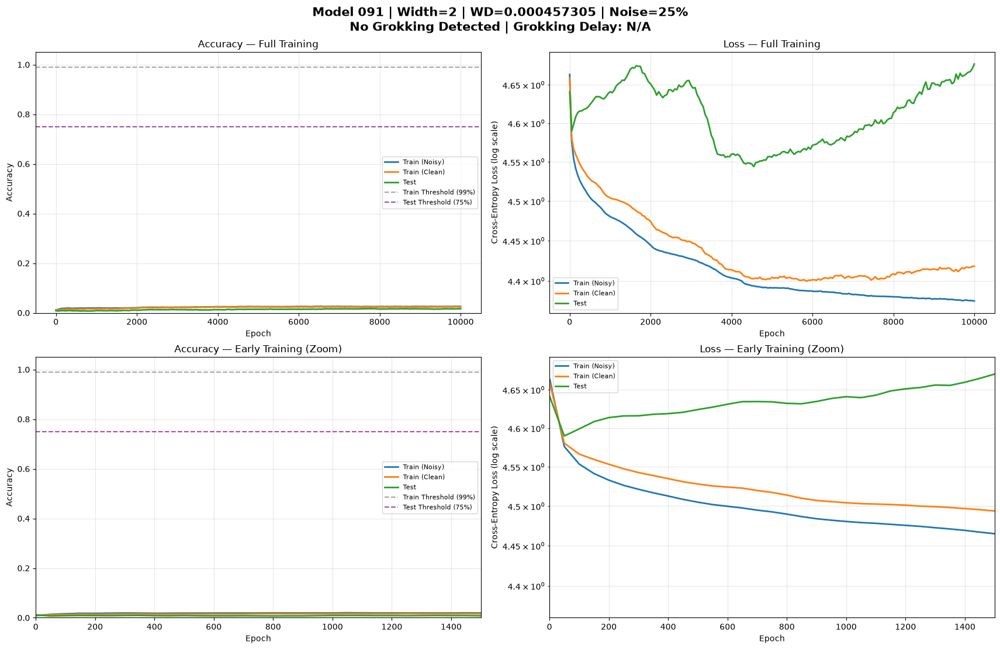

Training Models:  30%|██▉       | 92/308 [01:32<03:38,  1.01s/model]

Model 92: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_092/learning_curves.png


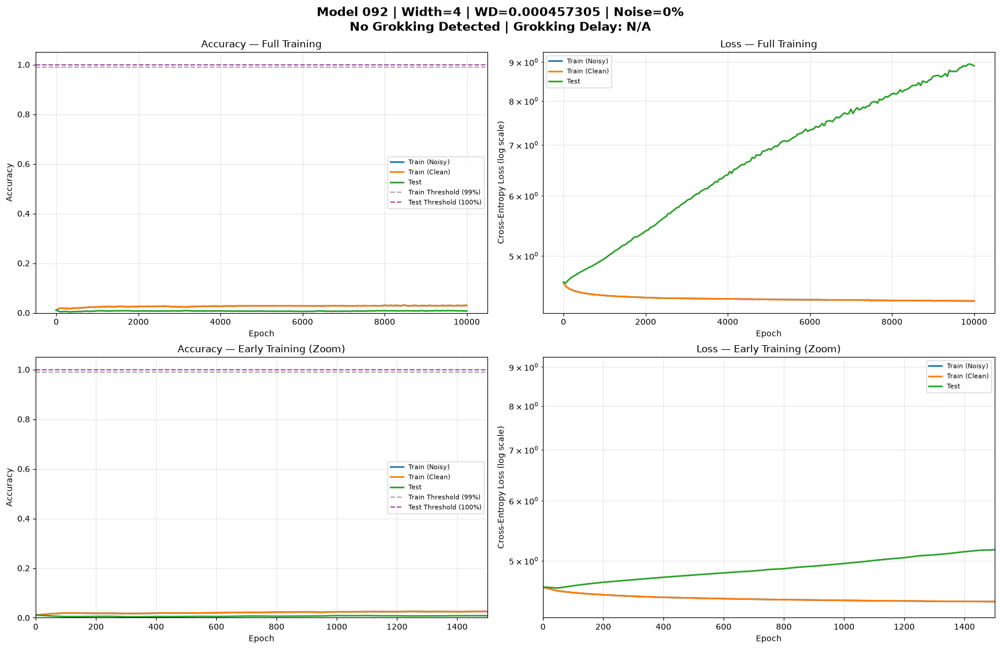

Training Models:  30%|███       | 93/308 [01:33<03:30,  1.02model/s]

Model 93: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_093/learning_curves.png


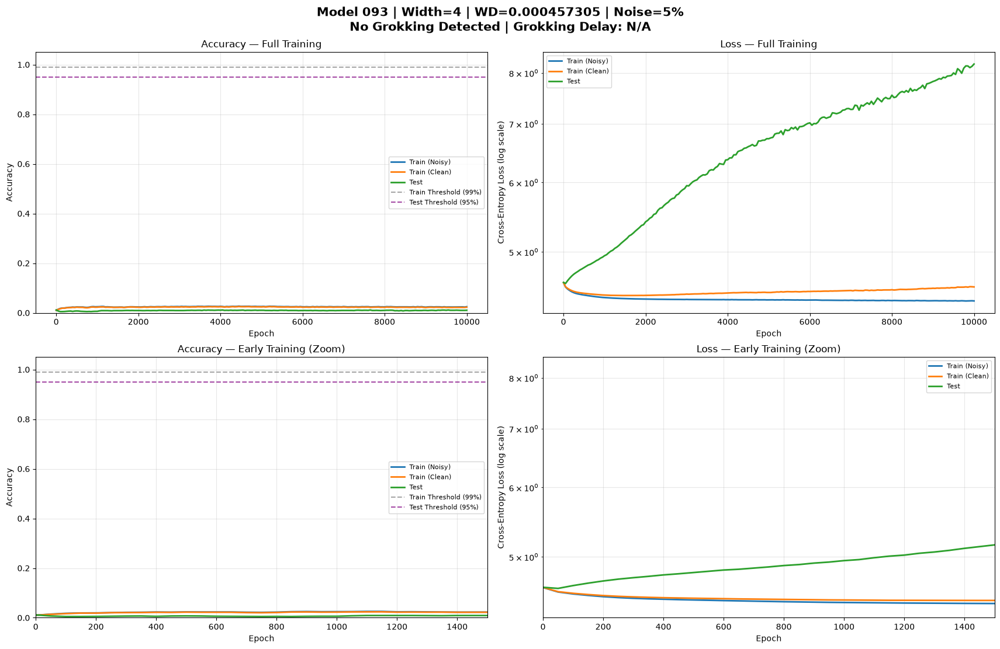

Training Models:  31%|███       | 94/308 [01:34<03:21,  1.06model/s]

Model 94: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_094/learning_curves.png


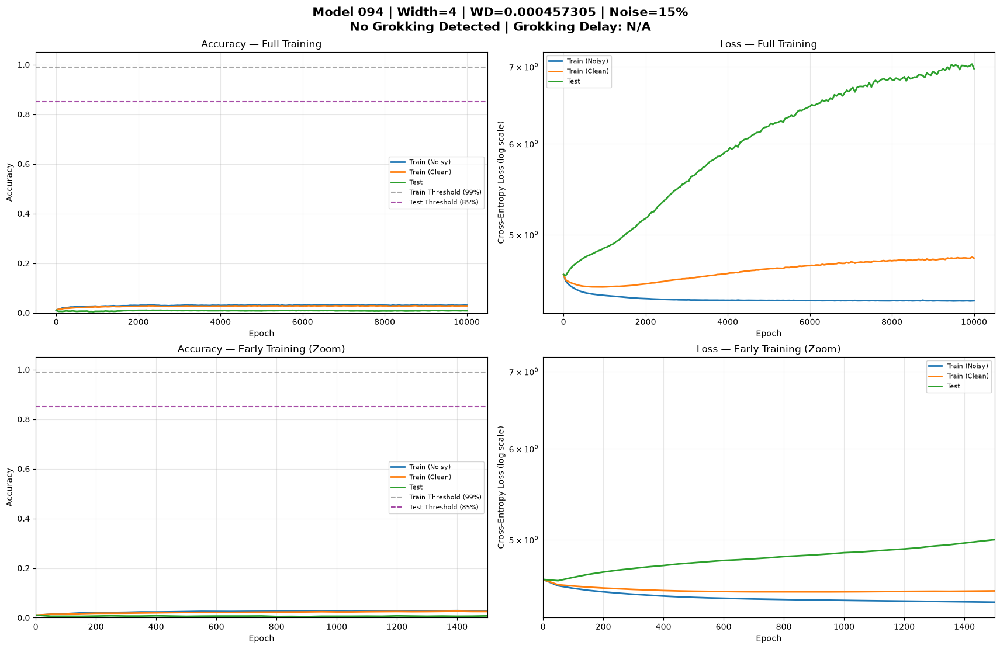

Training Models:  31%|███       | 95/308 [01:35<03:22,  1.05model/s]

Model 95: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_095/learning_curves.png


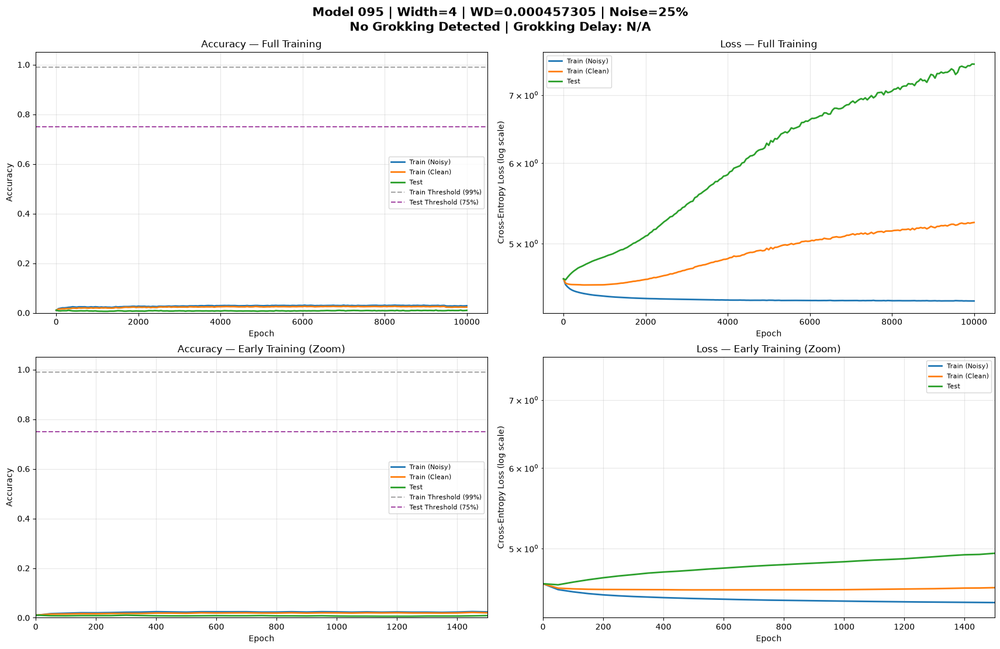

Training Models:  31%|███       | 96/308 [01:35<03:15,  1.08model/s]

Model 96: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_096/learning_curves.png


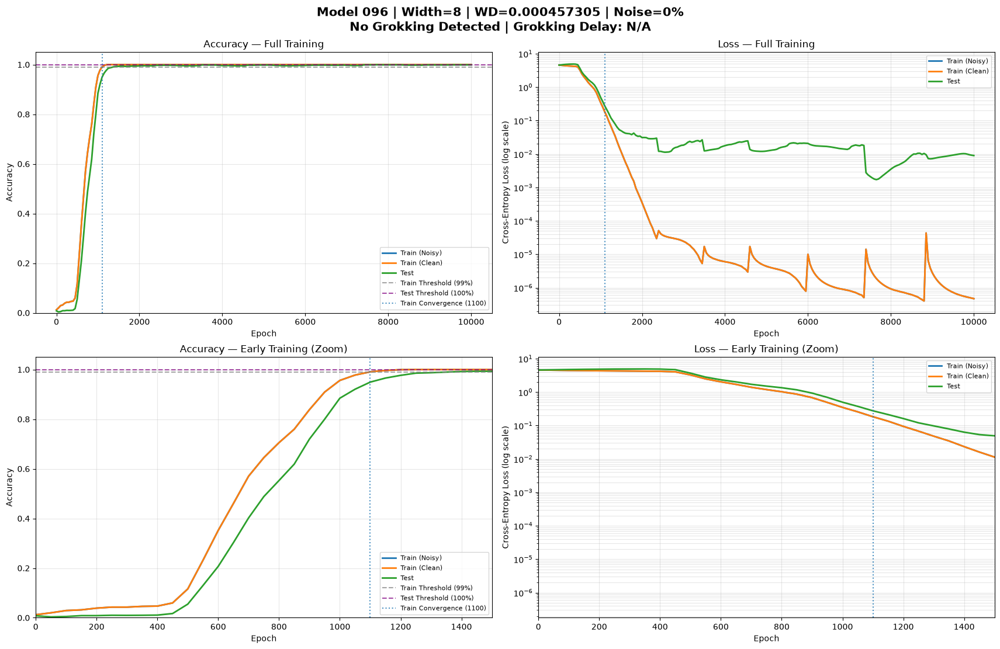

Training Models:  31%|███▏      | 97/308 [01:37<03:44,  1.06s/model]

Model 97: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_097/learning_curves.png


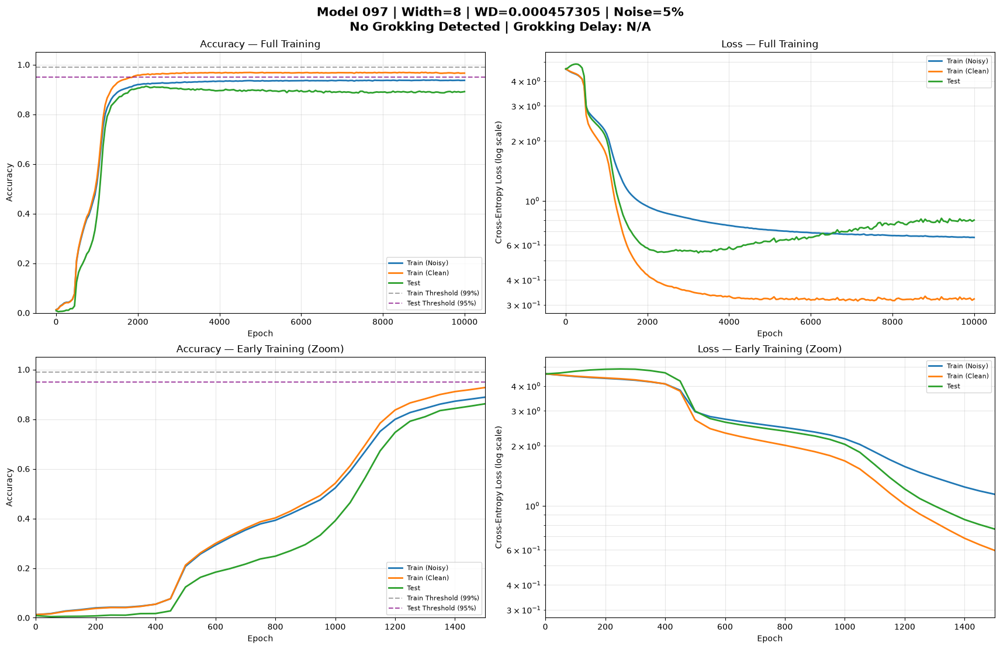

Training Models:  32%|███▏      | 98/308 [01:38<03:40,  1.05s/model]

Model 98: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_098/learning_curves.png


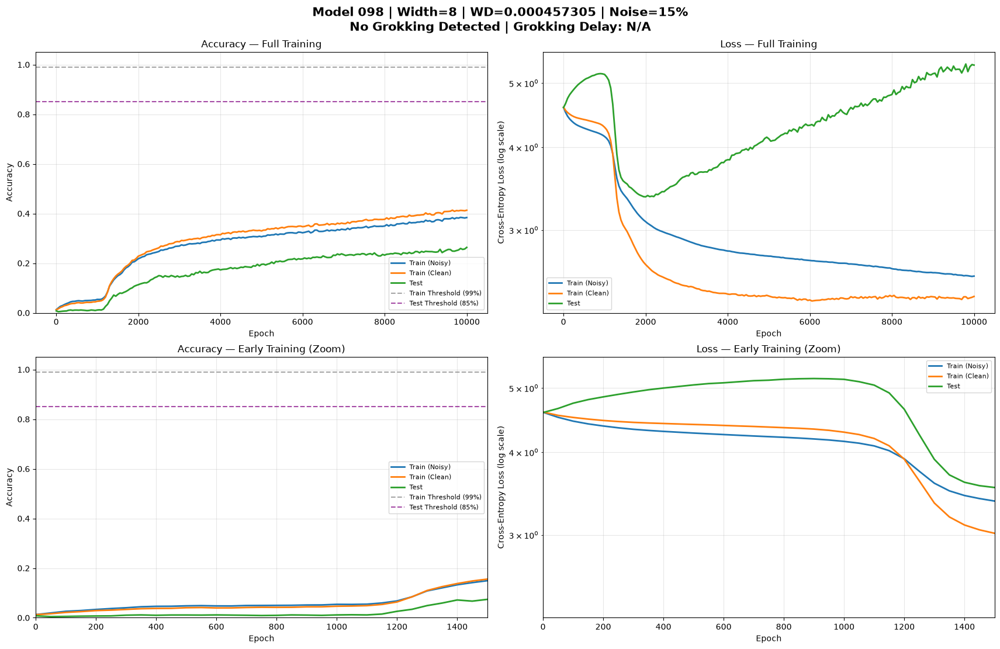

Training Models:  32%|███▏      | 99/308 [01:39<03:33,  1.02s/model]

Model 99: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_099/learning_curves.png


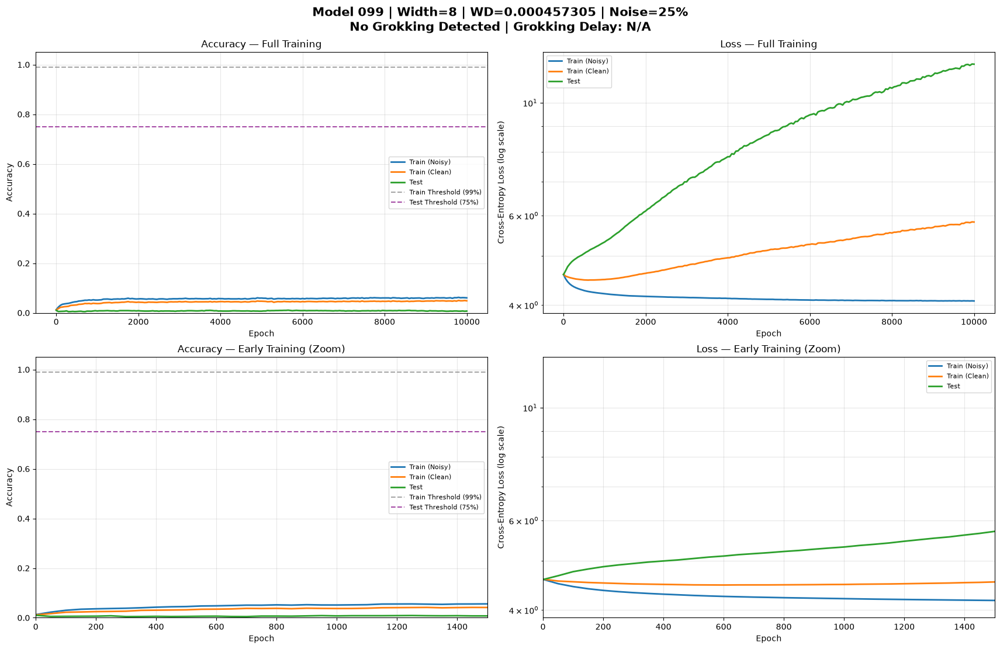

Training Models:  32%|███▏      | 100/308 [01:40<03:25,  1.01model/s]

Model 100: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_100/learning_curves.png


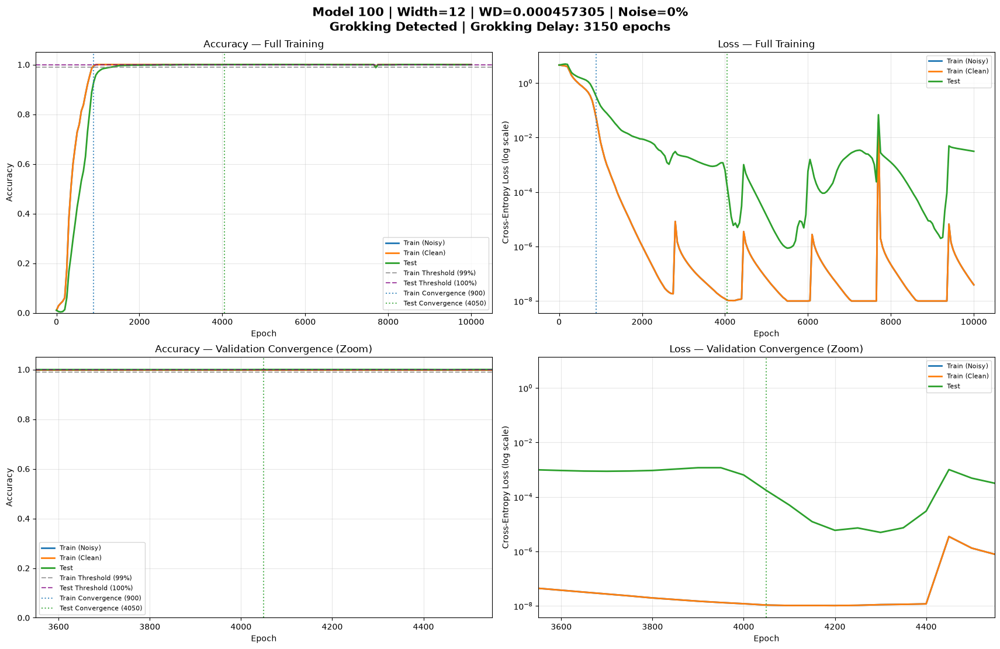

Training Models:  33%|███▎      | 101/308 [01:41<03:19,  1.04model/s]

Model 101: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_101/learning_curves.png


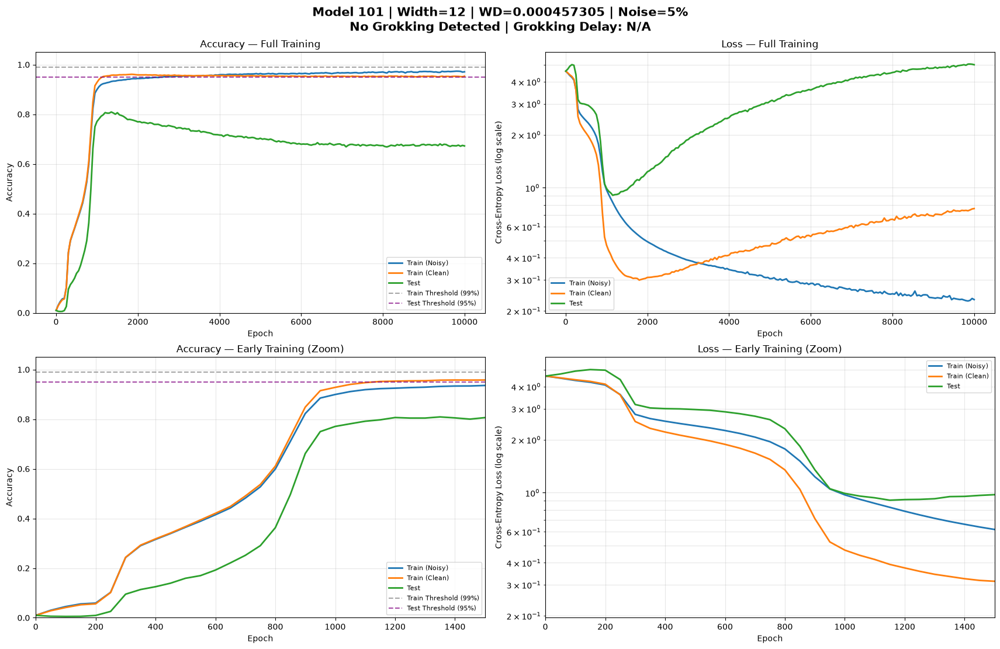

Training Models:  33%|███▎      | 102/308 [01:42<03:22,  1.02model/s]

Model 102: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_102/learning_curves.png


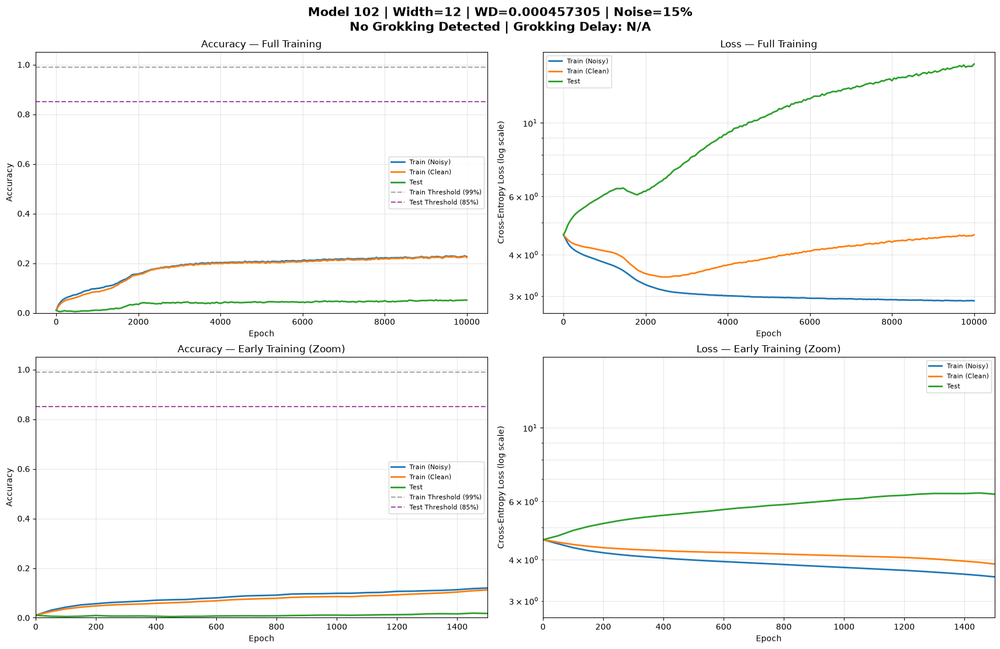

Training Models:  33%|███▎      | 103/308 [01:43<03:19,  1.03model/s]

Model 103: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_103/learning_curves.png


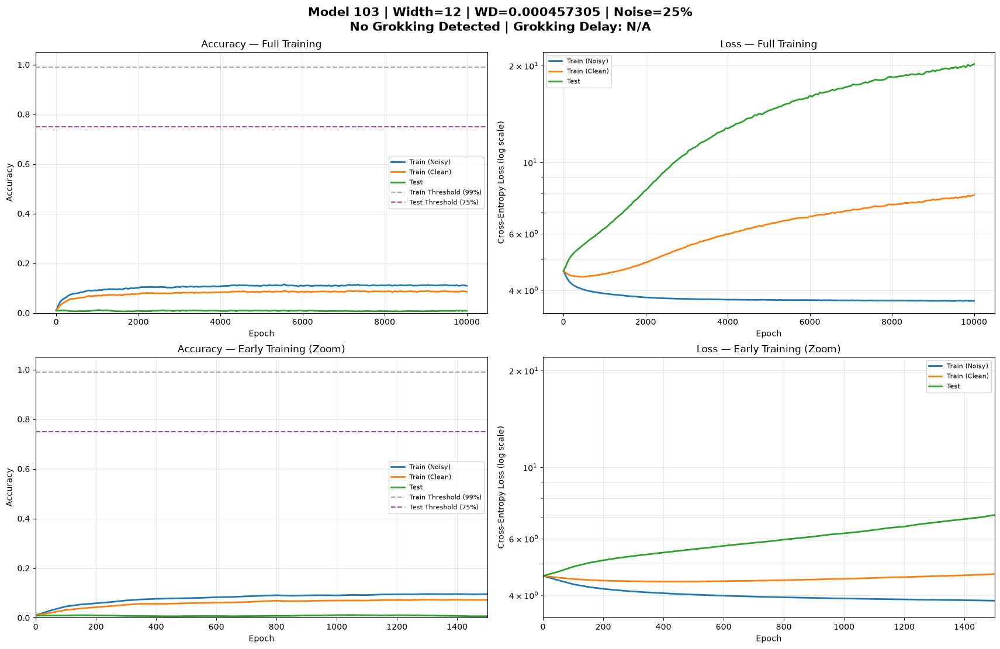

Training Models:  34%|███▍      | 104/308 [01:44<03:24,  1.00s/model]

Model 104: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_104/learning_curves.png


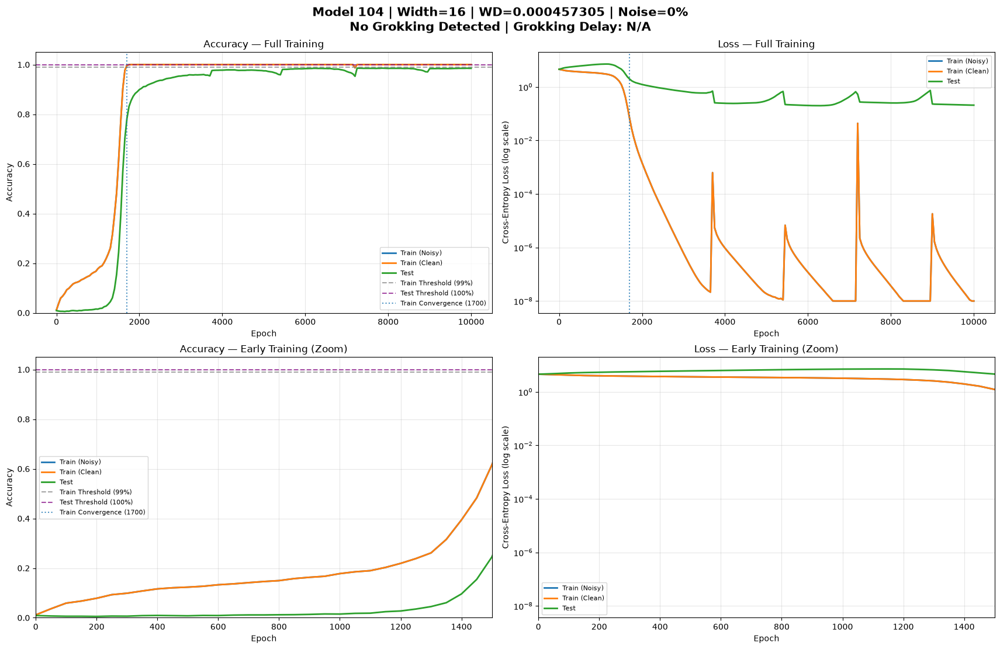

Training Models:  34%|███▍      | 105/308 [01:45<03:16,  1.03model/s]

Model 105: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_105/learning_curves.png


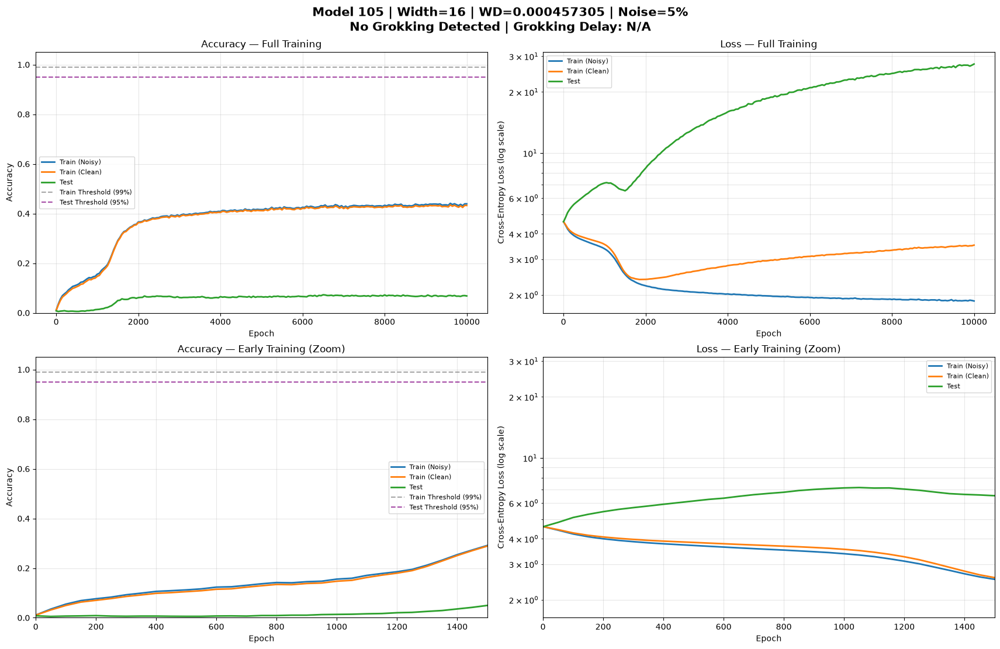

Training Models:  34%|███▍      | 106/308 [01:46<03:17,  1.02model/s]

Model 106: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_106/learning_curves.png


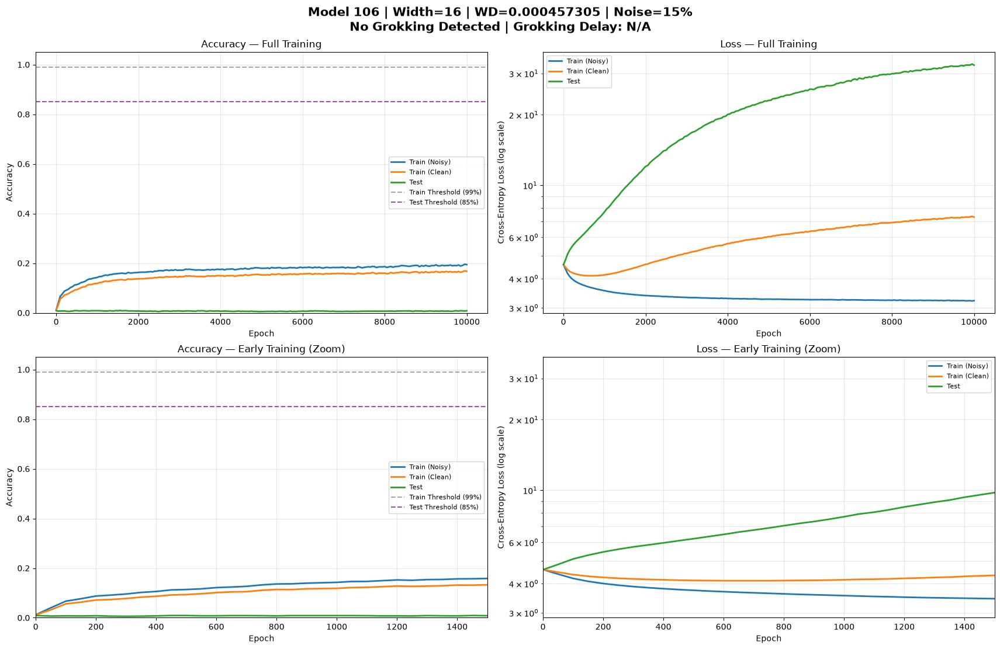

Training Models:  35%|███▍      | 107/308 [01:46<03:15,  1.03model/s]

Model 107: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_107/learning_curves.png


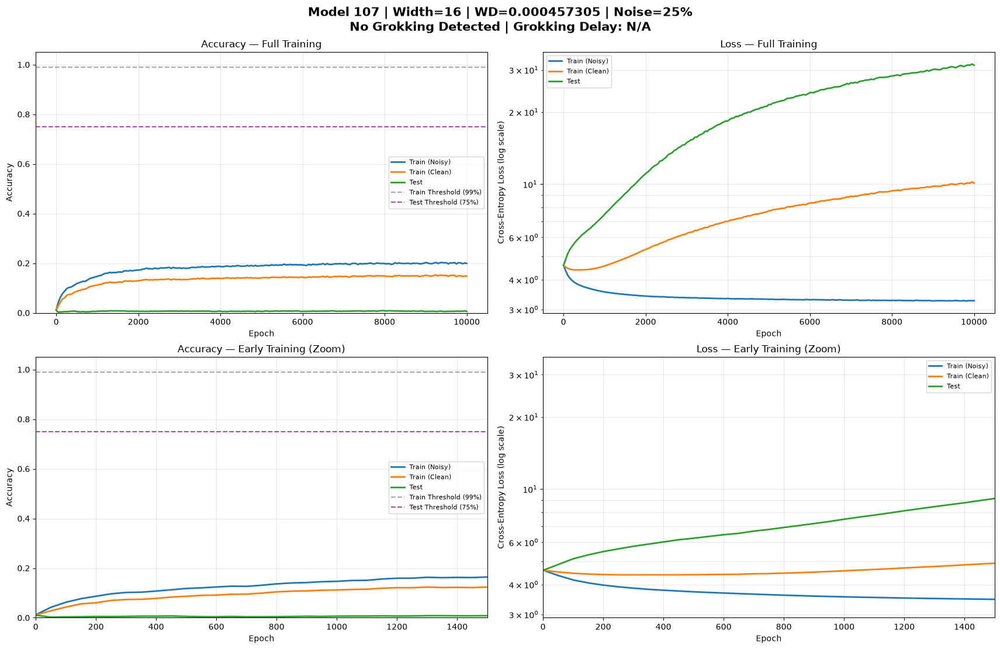

Training Models:  35%|███▌      | 108/308 [01:48<03:23,  1.02s/model]

Model 108: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_108/learning_curves.png


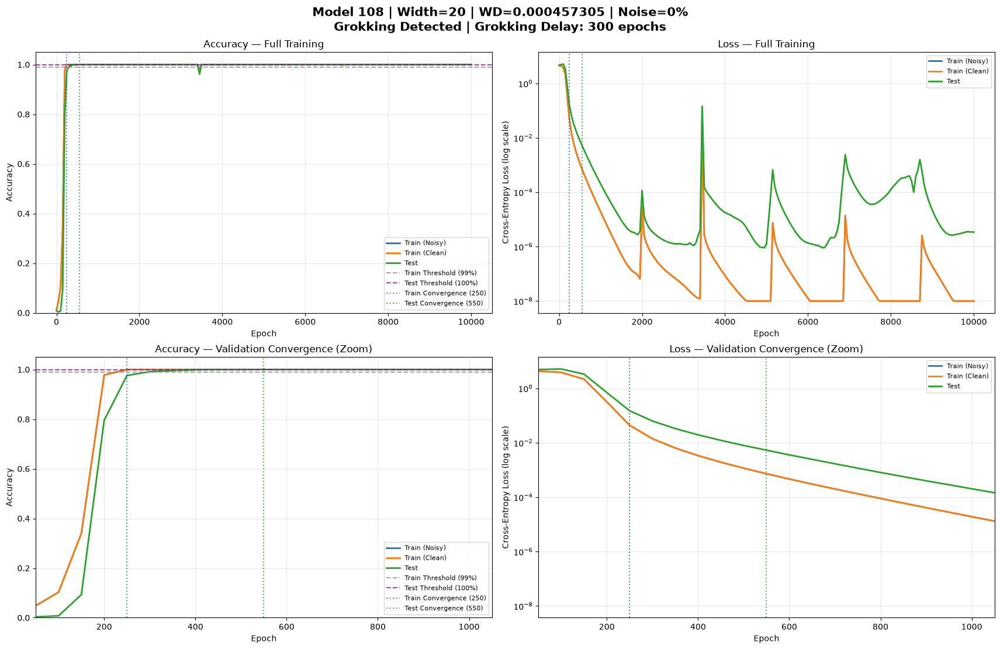

Training Models:  35%|███▌      | 109/308 [01:49<03:15,  1.02model/s]

Model 109: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_109/learning_curves.png


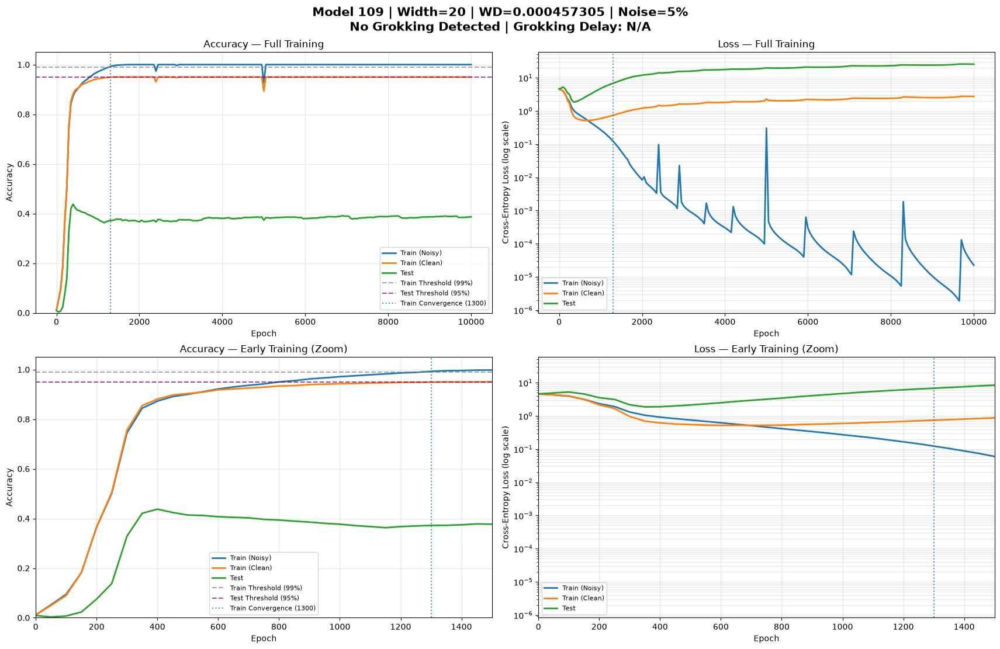

Training Models:  36%|███▌      | 110/308 [01:50<03:38,  1.10s/model]

Model 110: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_110/learning_curves.png


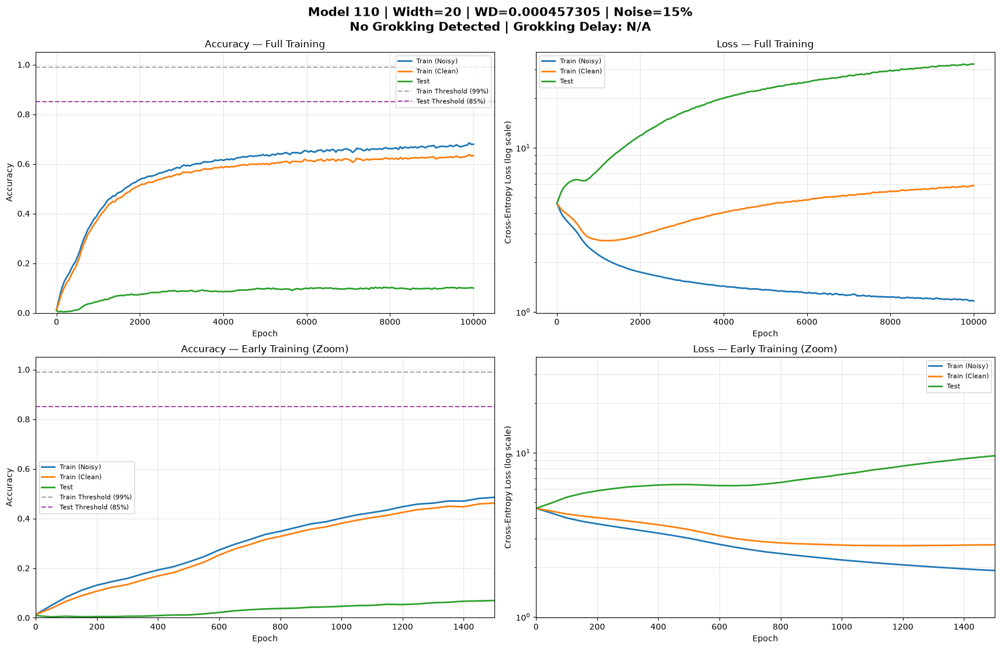

Training Models:  36%|███▌      | 111/308 [01:51<03:26,  1.05s/model]

Model 111: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_111/learning_curves.png


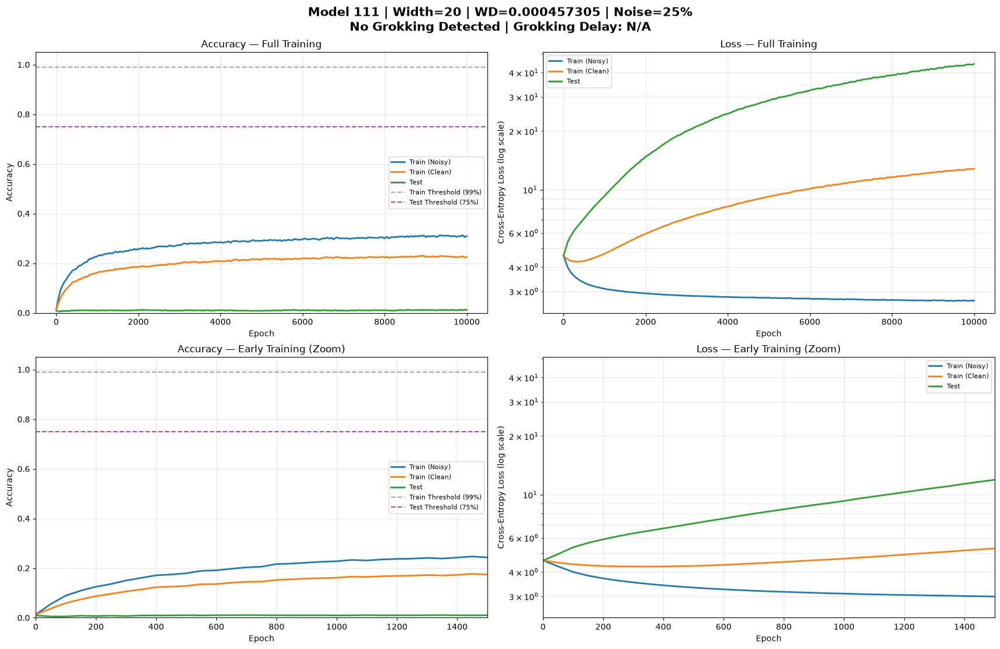

Training Models:  36%|███▋      | 112/308 [01:52<03:30,  1.07s/model]

Model 112: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_112/learning_curves.png


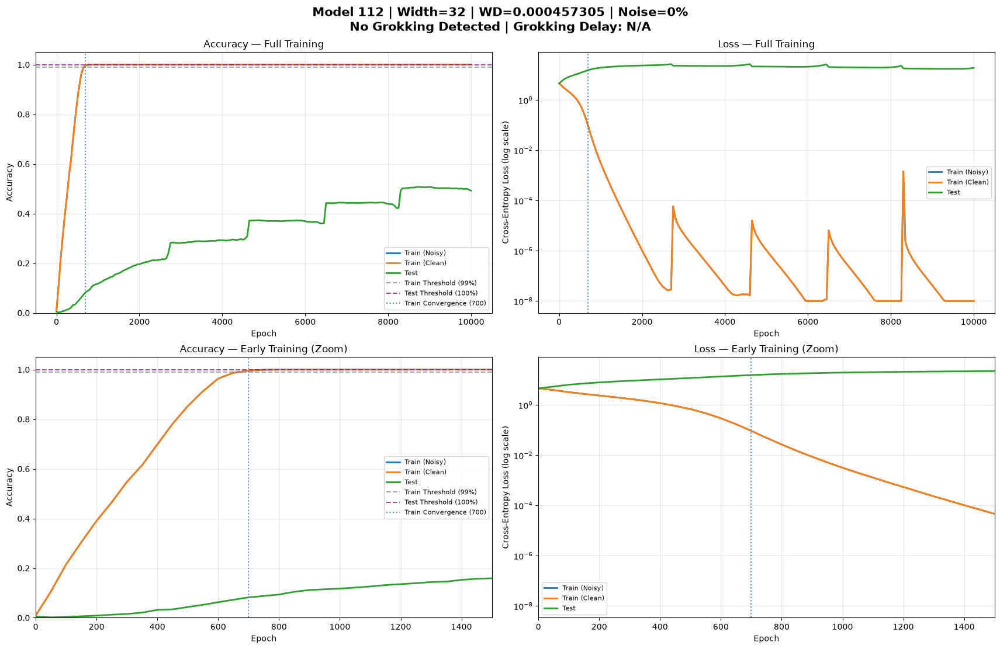

Training Models:  37%|███▋      | 113/308 [01:53<03:19,  1.02s/model]

Model 113: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_113/learning_curves.png


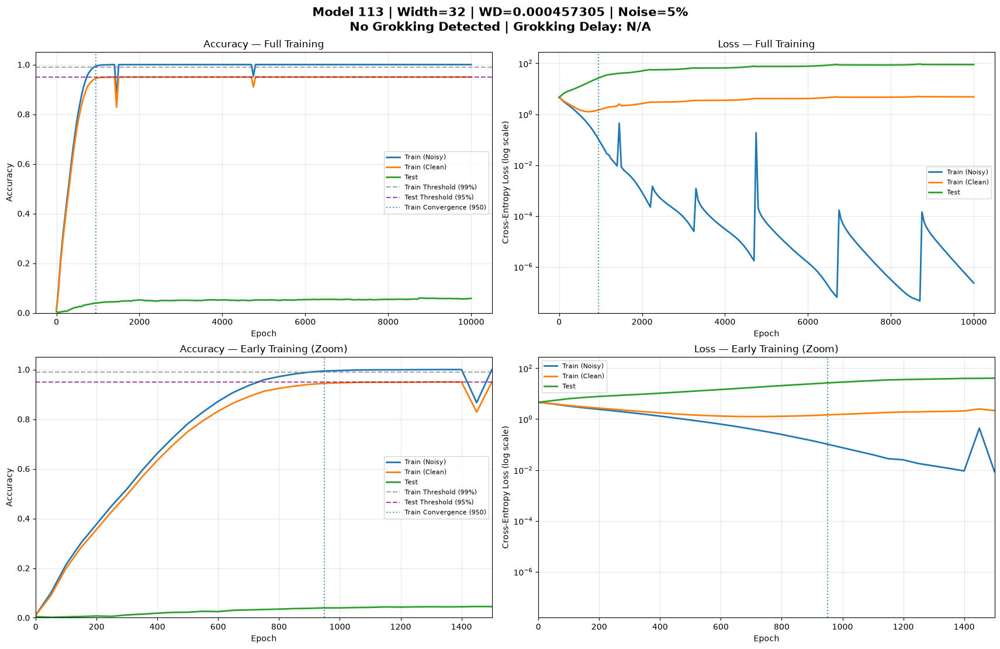

Training Models:  37%|███▋      | 114/308 [01:54<03:11,  1.01model/s]

Model 114: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_114/learning_curves.png


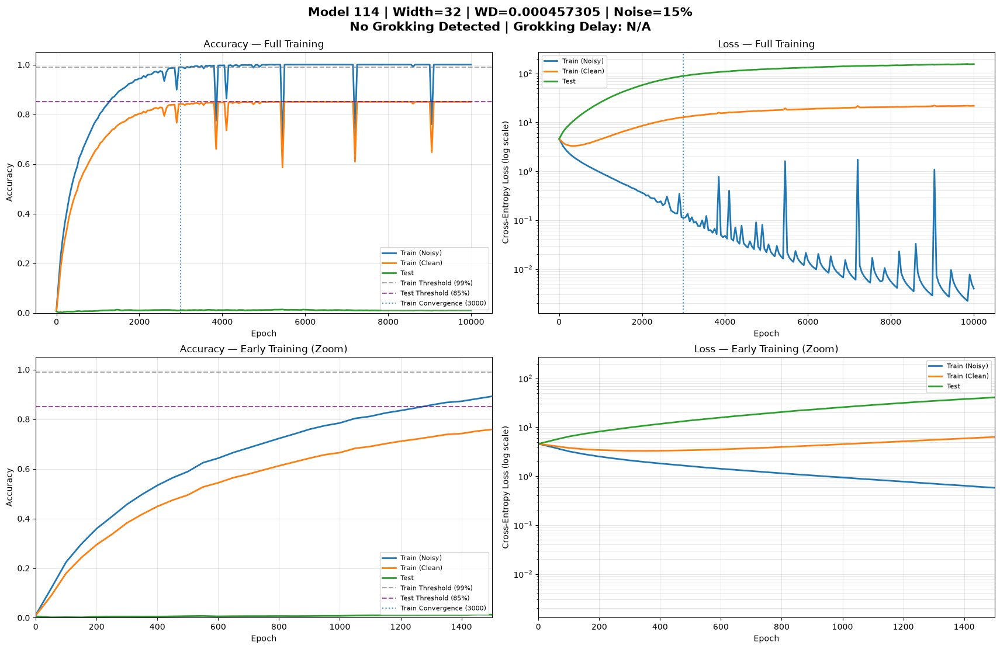

Training Models:  37%|███▋      | 115/308 [01:55<03:20,  1.04s/model]

Model 115: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_115/learning_curves.png


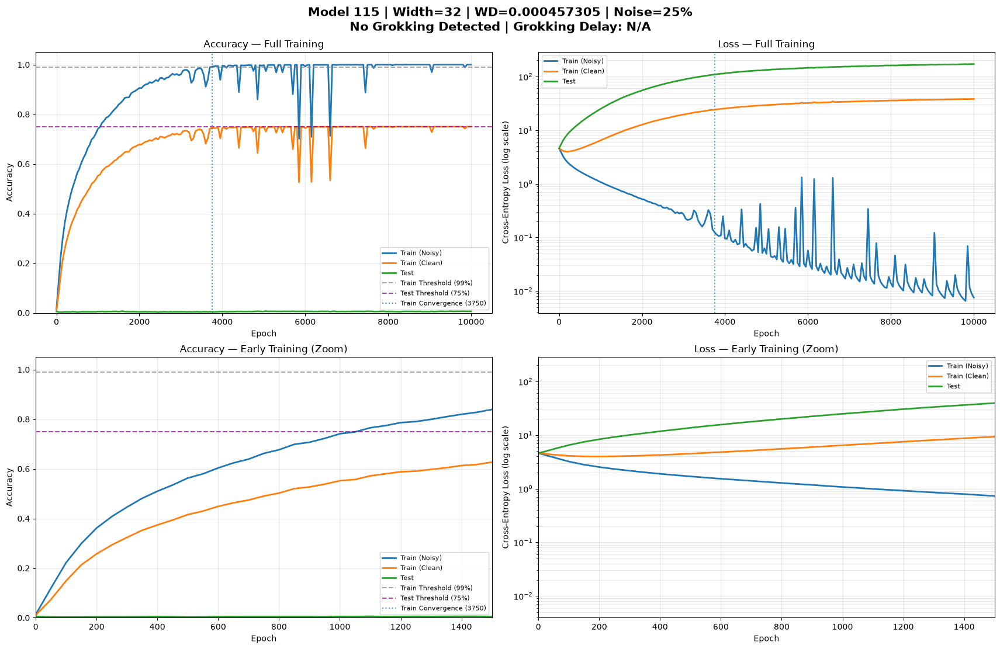

Training Models:  38%|███▊      | 116/308 [01:56<03:33,  1.11s/model]

Model 116: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_116/learning_curves.png


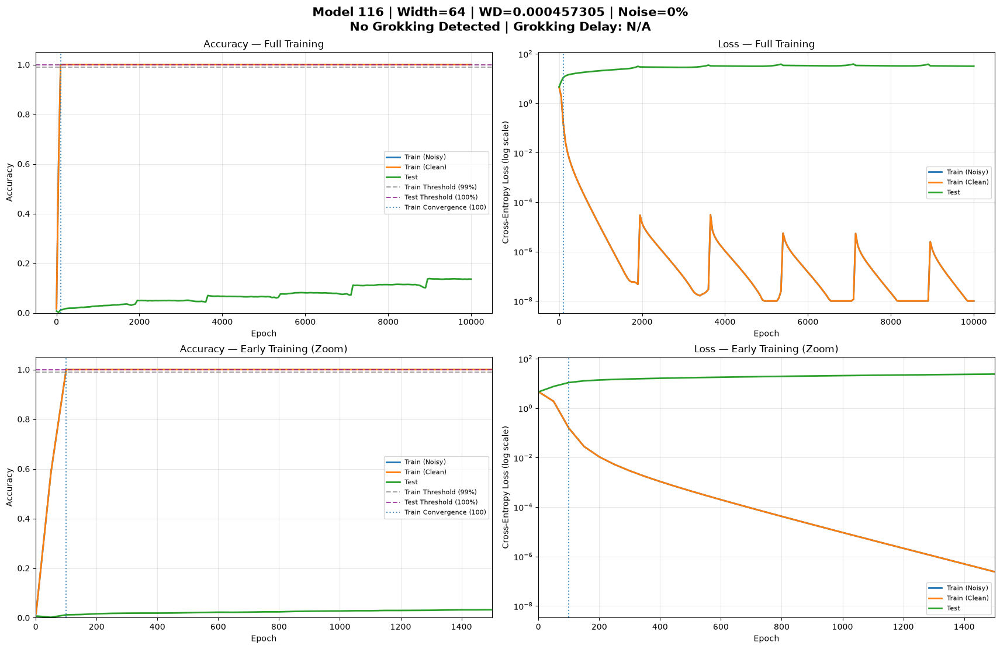

Training Models:  38%|███▊      | 117/308 [01:57<03:22,  1.06s/model]

Model 117: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_117/learning_curves.png


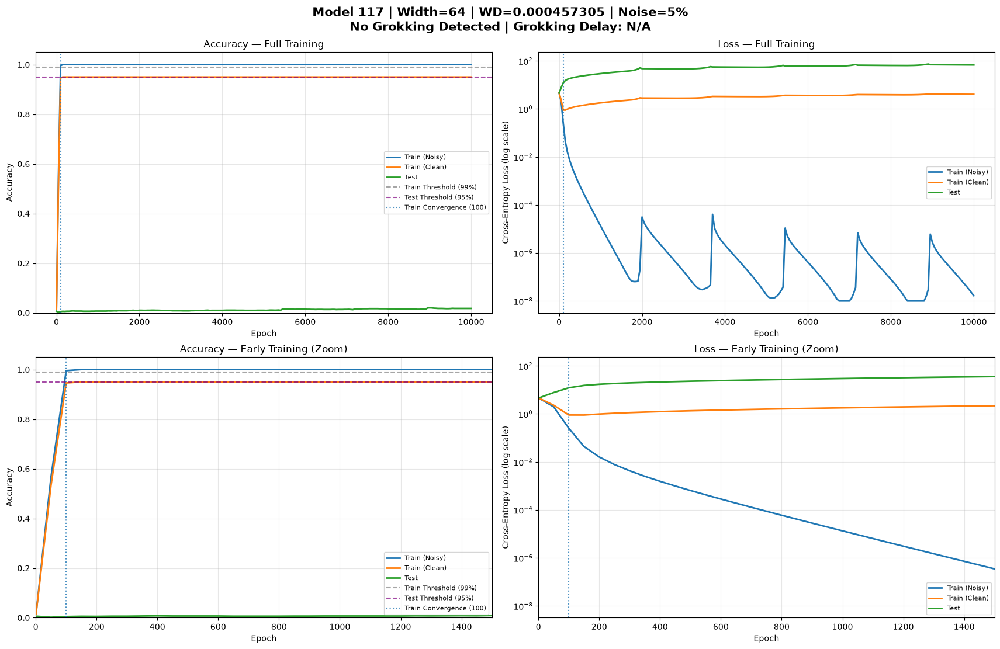

Training Models:  38%|███▊      | 118/308 [01:58<03:14,  1.02s/model]

Model 118: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_118/learning_curves.png


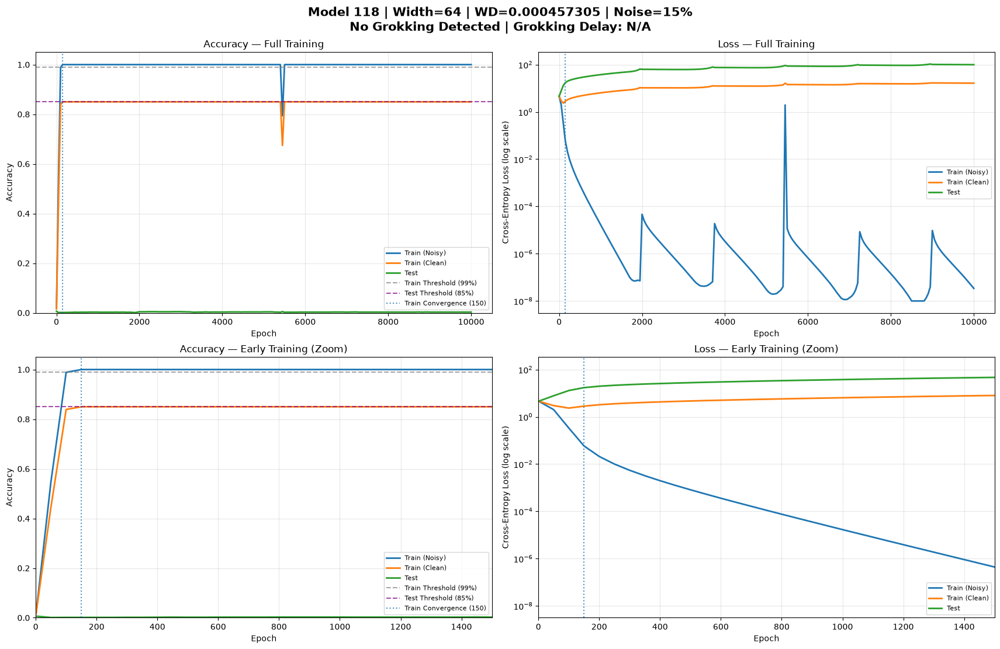

Training Models:  39%|███▊      | 119/308 [01:59<03:08,  1.01model/s]

Model 119: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_119/learning_curves.png


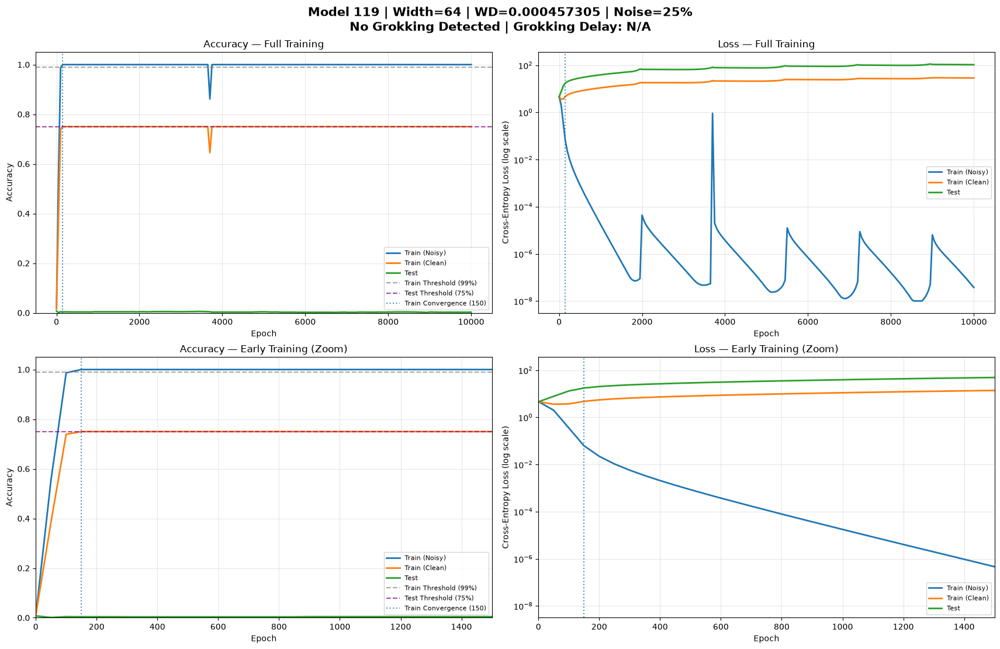

Training Models:  39%|███▉      | 120/308 [02:00<03:10,  1.02s/model]

Model 120: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_120/learning_curves.png


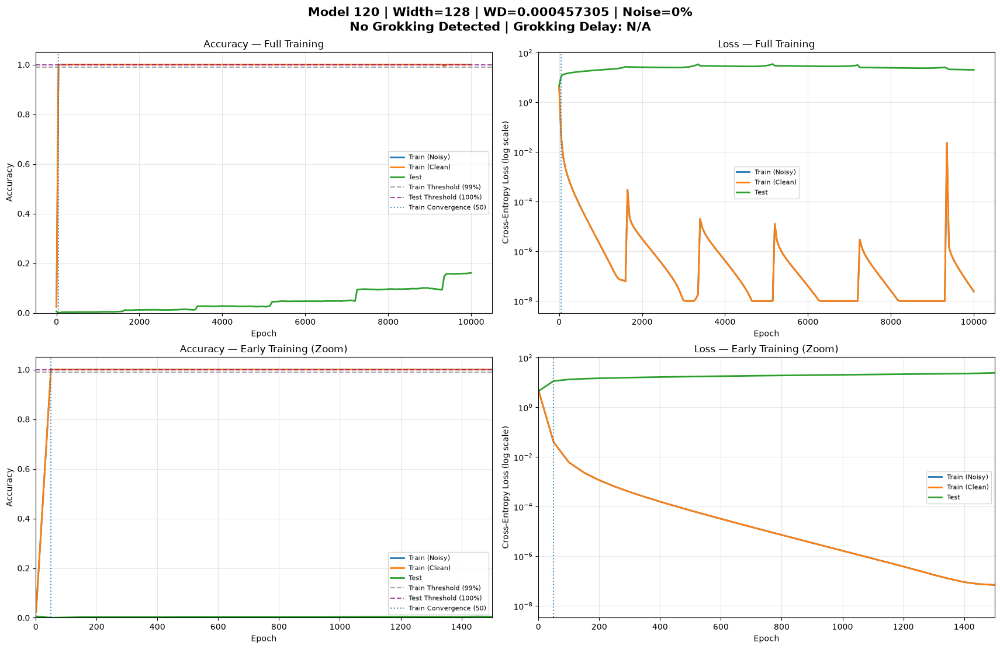

Training Models:  39%|███▉      | 121/308 [02:01<03:06,  1.01model/s]

Model 121: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_121/learning_curves.png


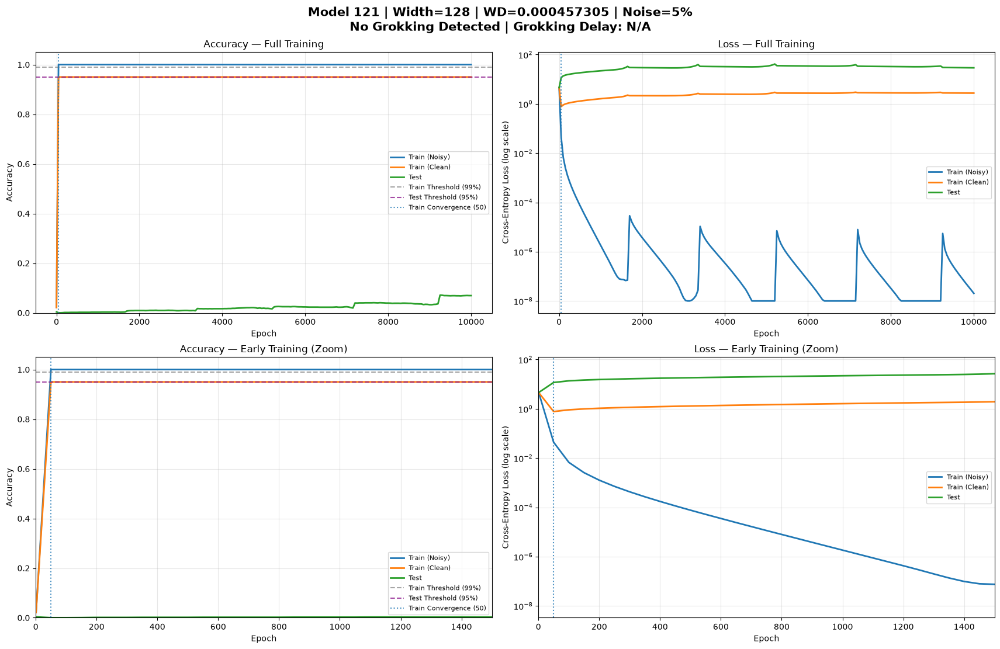

Training Models:  40%|███▉      | 122/308 [02:02<03:02,  1.02model/s]

Model 122: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_122/learning_curves.png


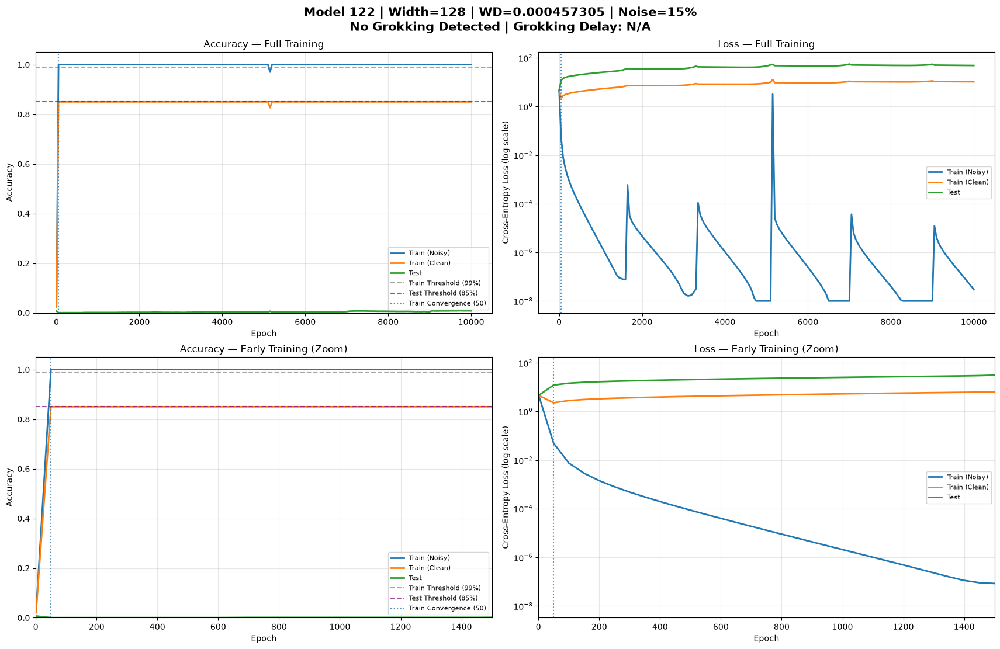

Training Models:  40%|███▉      | 123/308 [02:03<02:58,  1.03model/s]

Model 123: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_123/learning_curves.png


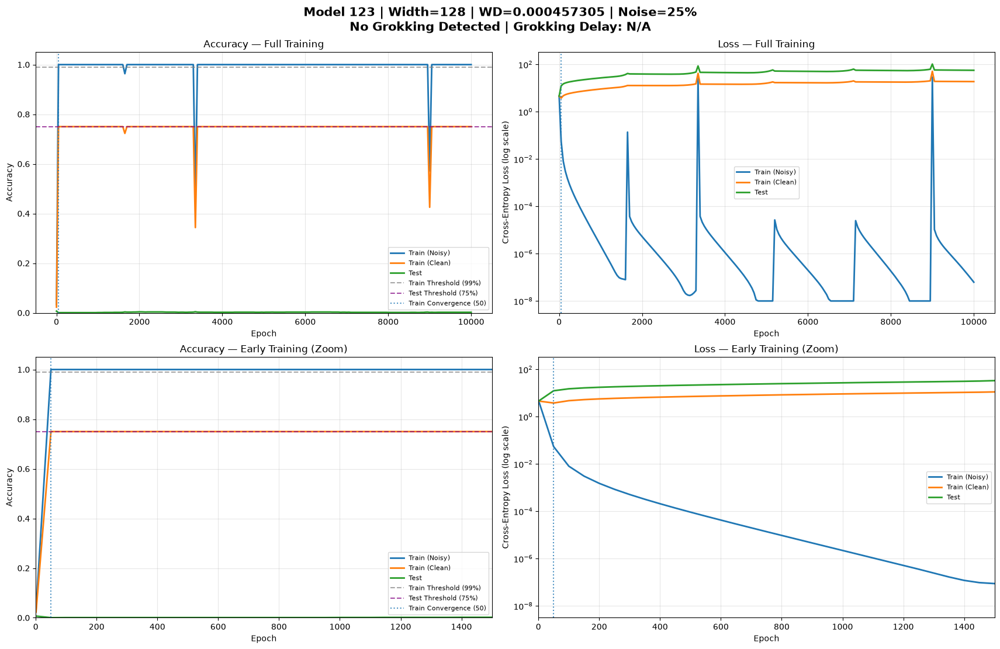

Training Models:  40%|████      | 124/308 [02:04<02:56,  1.04model/s]

Model 124: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_124/learning_curves.png


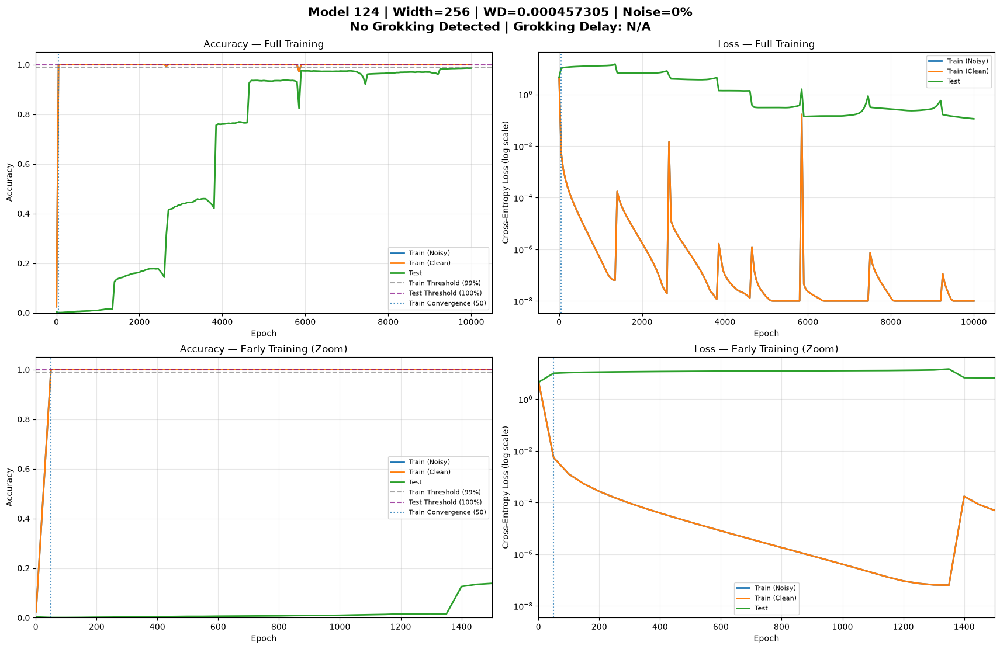

Training Models:  41%|████      | 125/308 [02:05<02:58,  1.02model/s]

Model 125: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_125/learning_curves.png


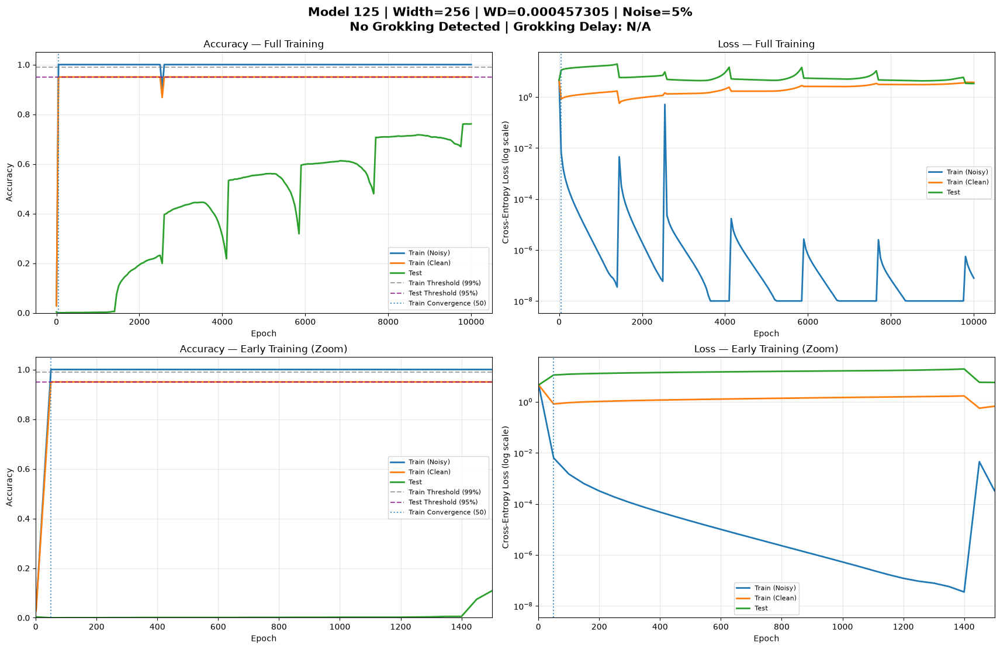

Training Models:  41%|████      | 126/308 [02:06<02:55,  1.04model/s]

Model 126: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_126/learning_curves.png


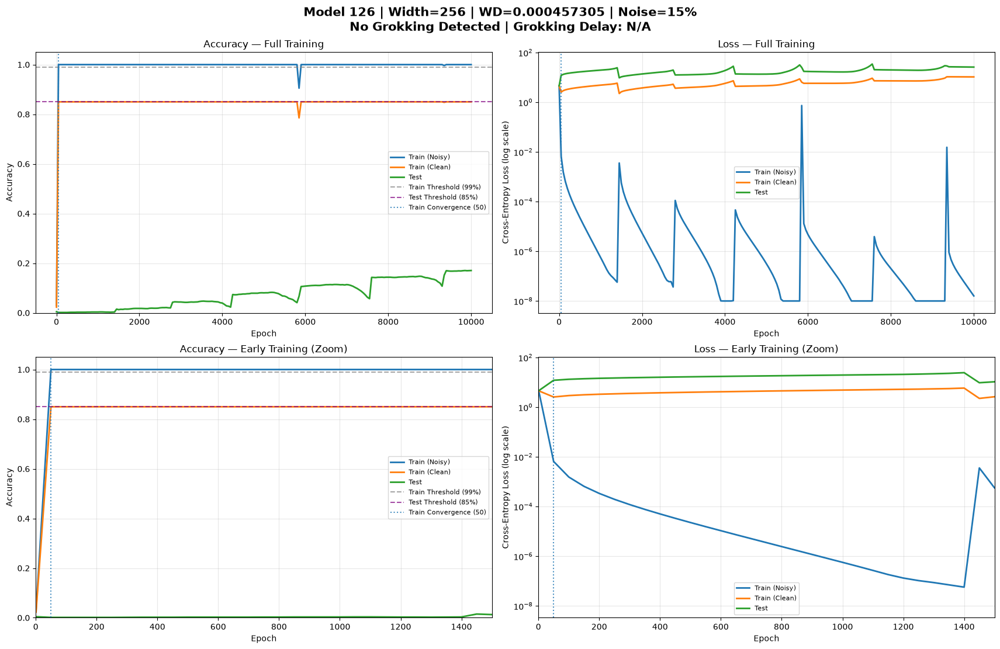

Training Models:  41%|████      | 127/308 [02:07<02:54,  1.04model/s]

Model 127: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_127/learning_curves.png


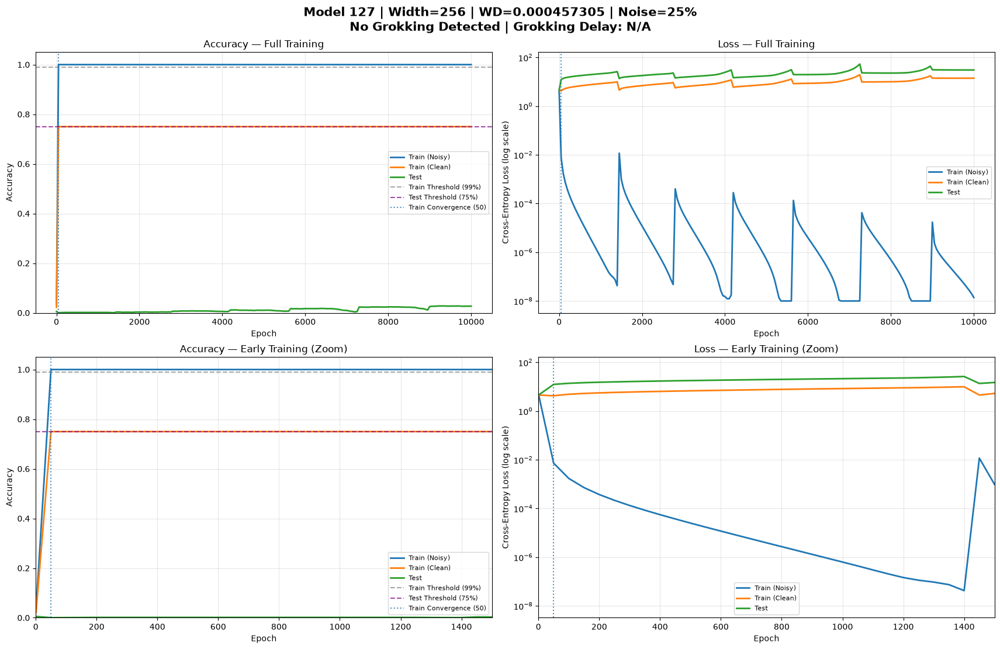

Training Models:  42%|████▏     | 128/308 [02:08<02:51,  1.05model/s]

Model 128: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_128/learning_curves.png


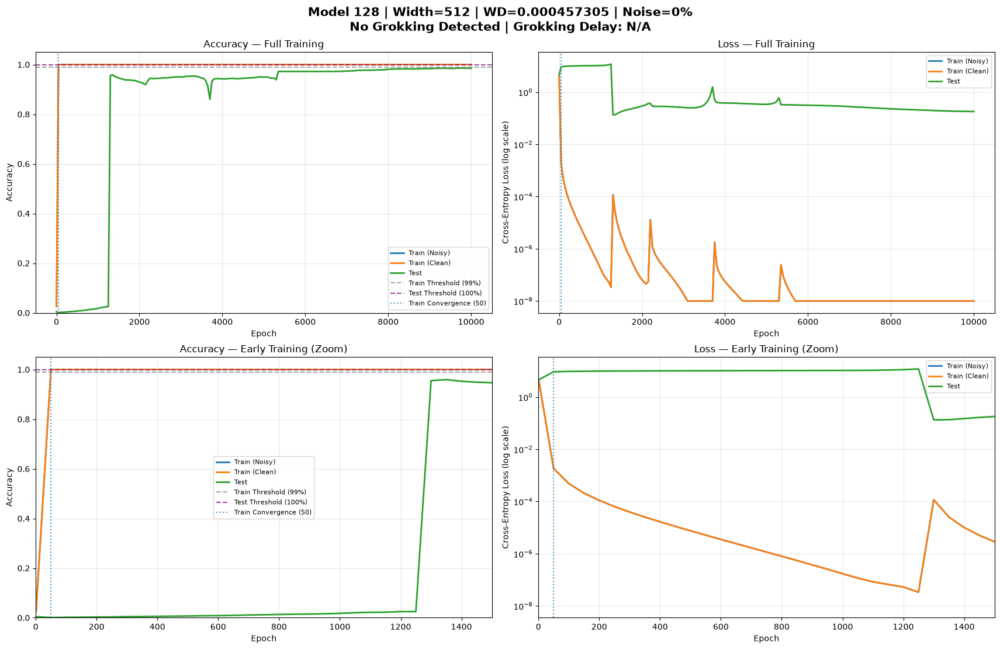

Training Models:  42%|████▏     | 129/308 [02:09<02:55,  1.02model/s]

Model 129: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_129/learning_curves.png


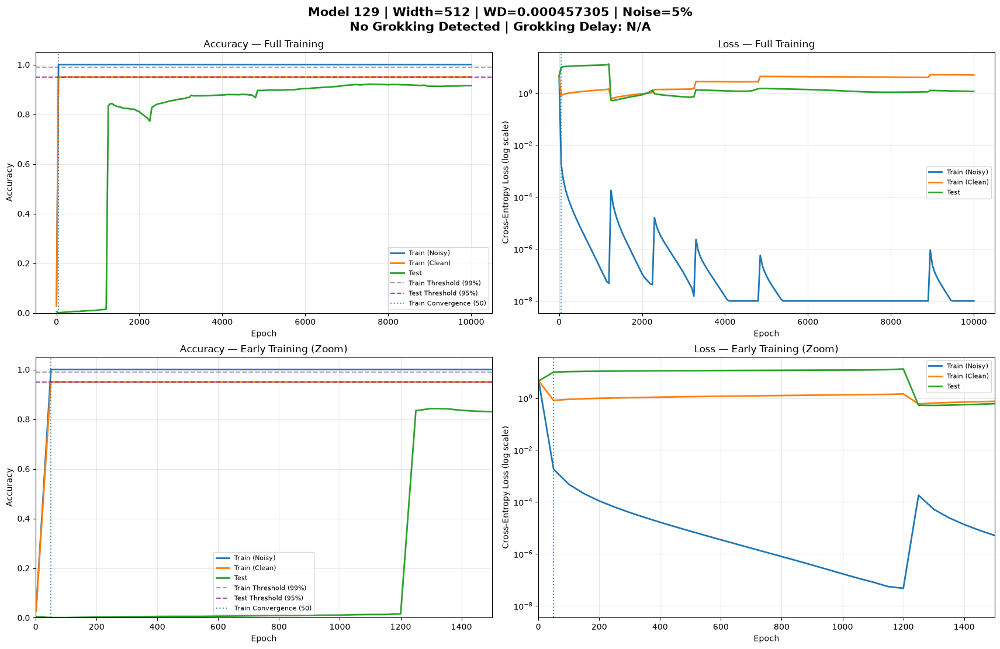

Training Models:  42%|████▏     | 130/308 [02:10<02:51,  1.04model/s]

Model 130: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_130/learning_curves.png


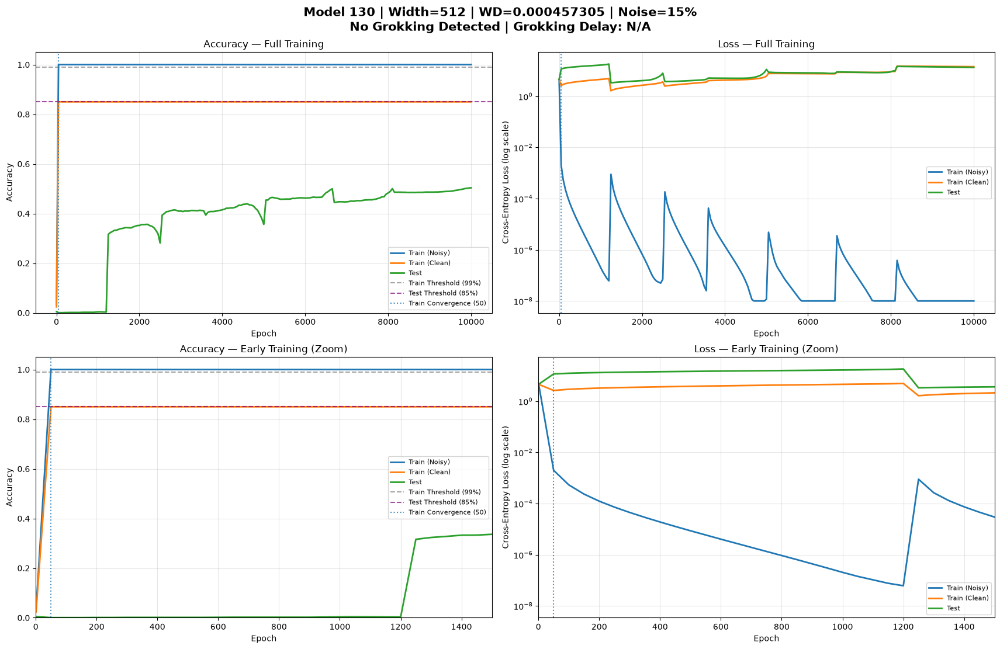

Training Models:  43%|████▎     | 131/308 [02:11<02:47,  1.06model/s]

Model 131: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_131/learning_curves.png


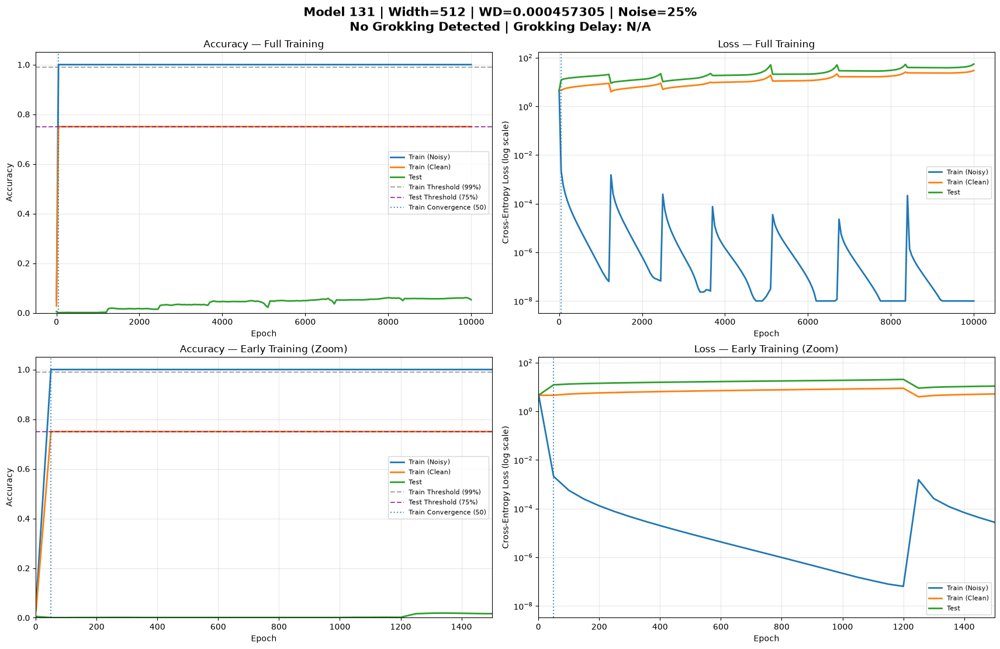

Training Models:  43%|████▎     | 132/308 [02:11<02:45,  1.06model/s]

Model 132: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_132/learning_curves.png


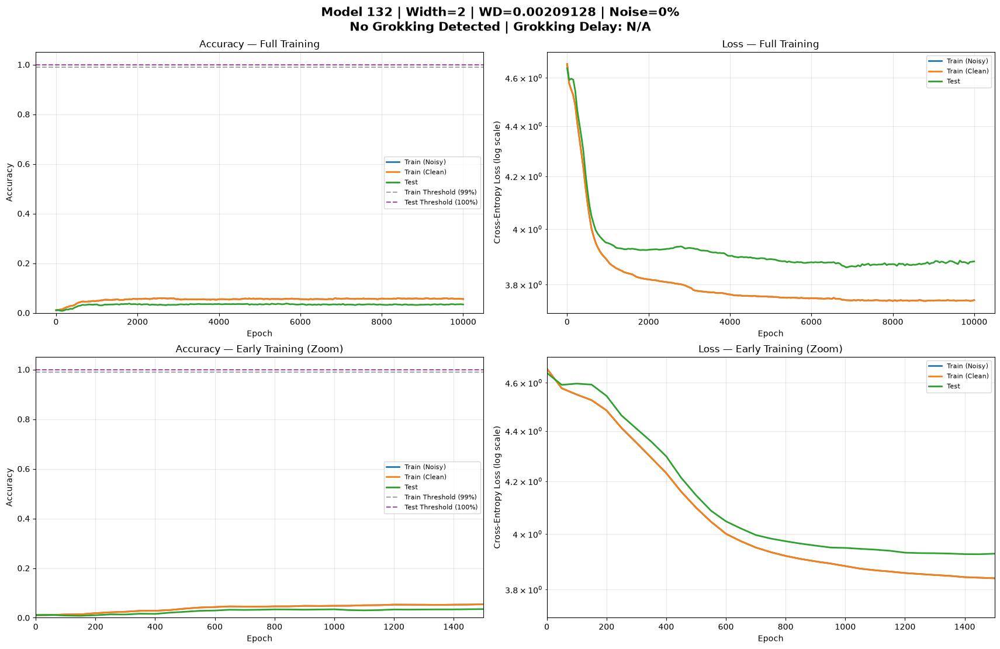

Training Models:  43%|████▎     | 133/308 [02:12<02:42,  1.07model/s]

Model 133: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_133/learning_curves.png


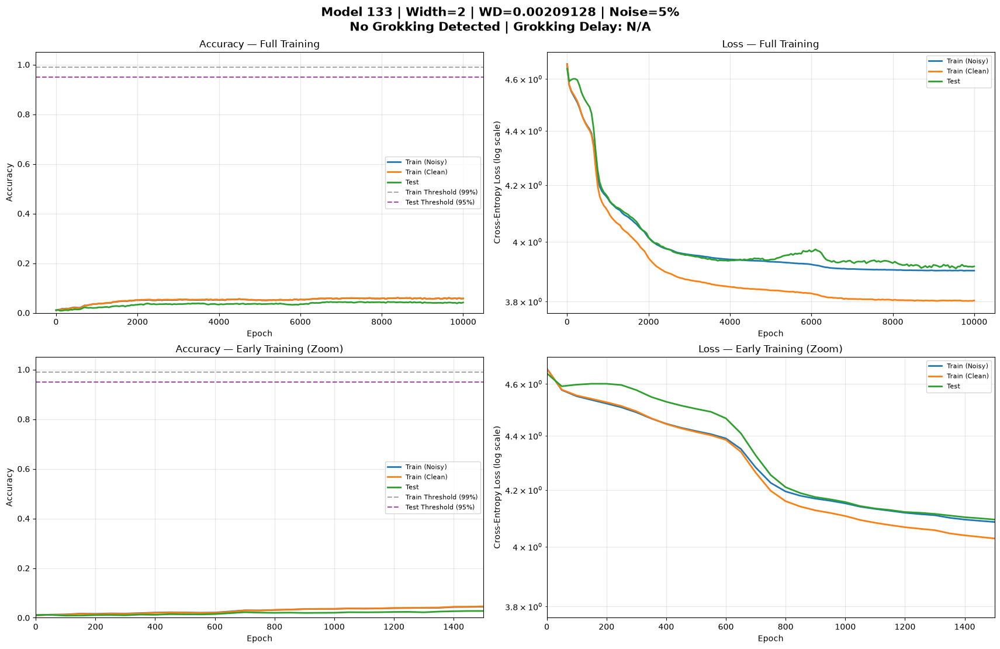

Training Models:  44%|████▎     | 134/308 [02:13<02:46,  1.05model/s]

Model 134: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_134/learning_curves.png


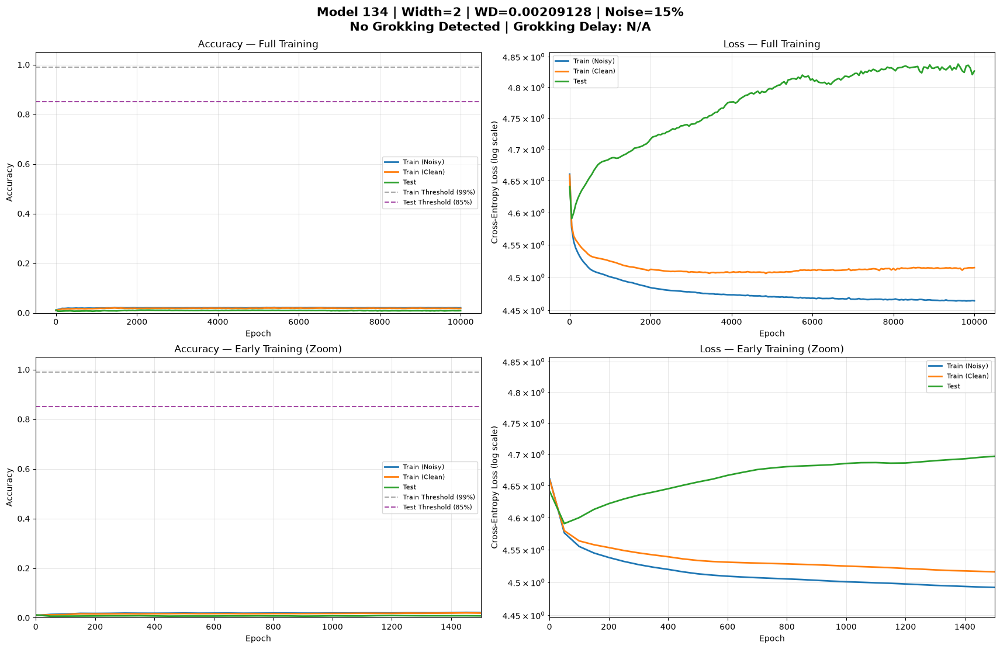

Training Models:  44%|████▍     | 135/308 [02:14<02:47,  1.03model/s]

Model 135: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_135/learning_curves.png


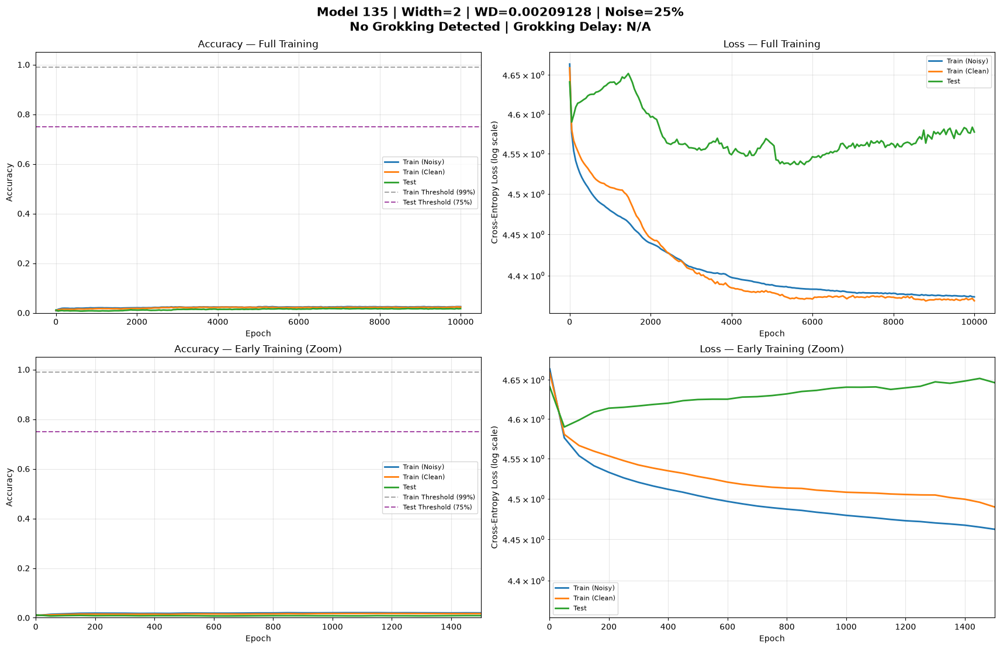

Training Models:  44%|████▍     | 136/308 [02:15<02:45,  1.04model/s]

Model 136: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_136/learning_curves.png


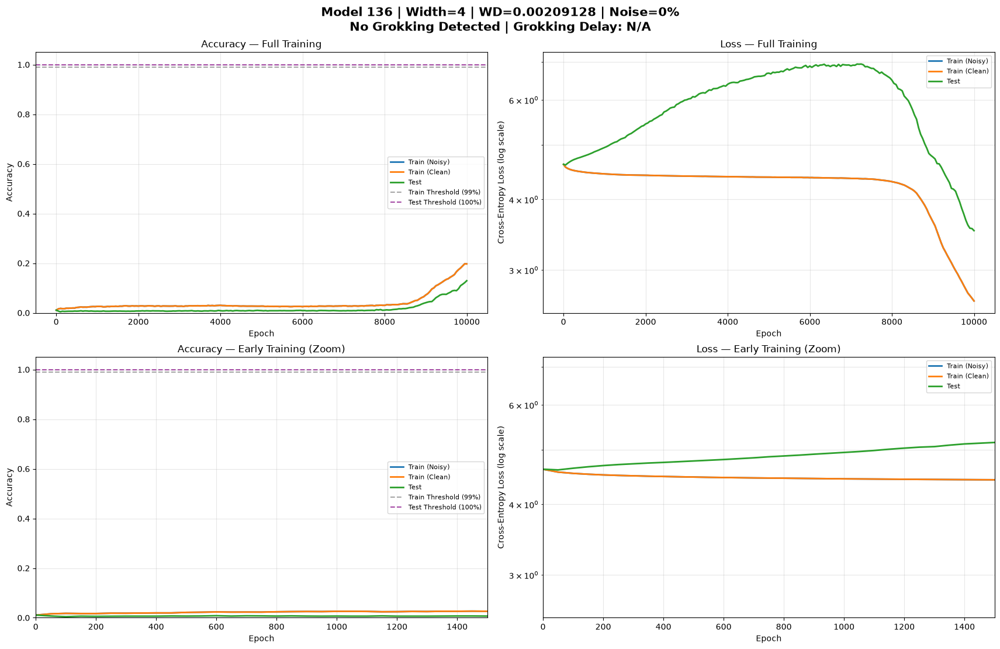

Training Models:  44%|████▍     | 137/308 [02:16<02:39,  1.07model/s]

Model 137: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_137/learning_curves.png


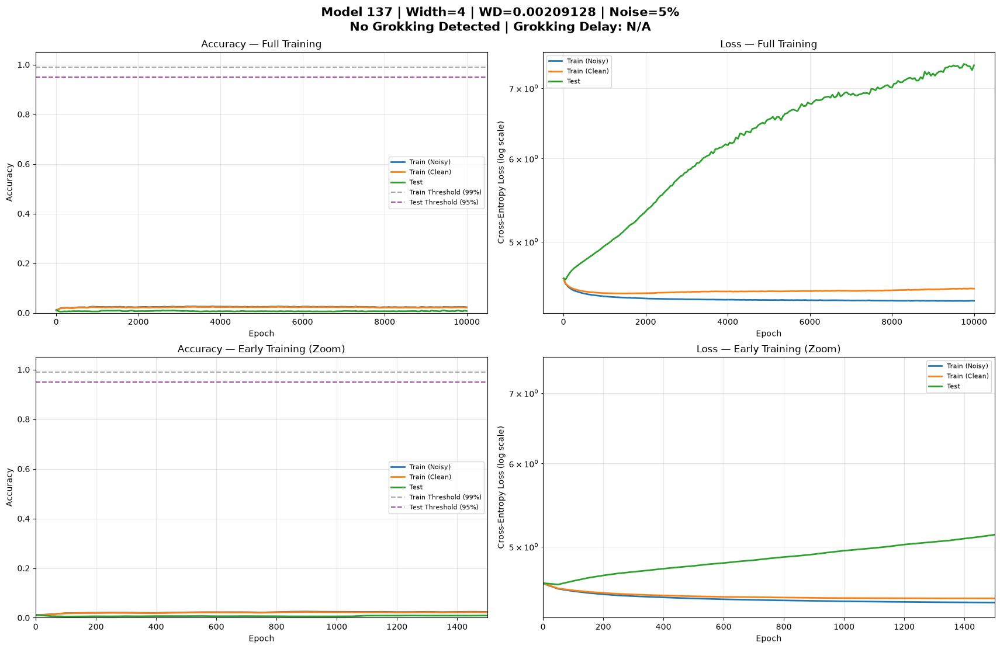

Training Models:  45%|████▍     | 138/308 [02:17<02:34,  1.10model/s]

Model 138: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_138/learning_curves.png


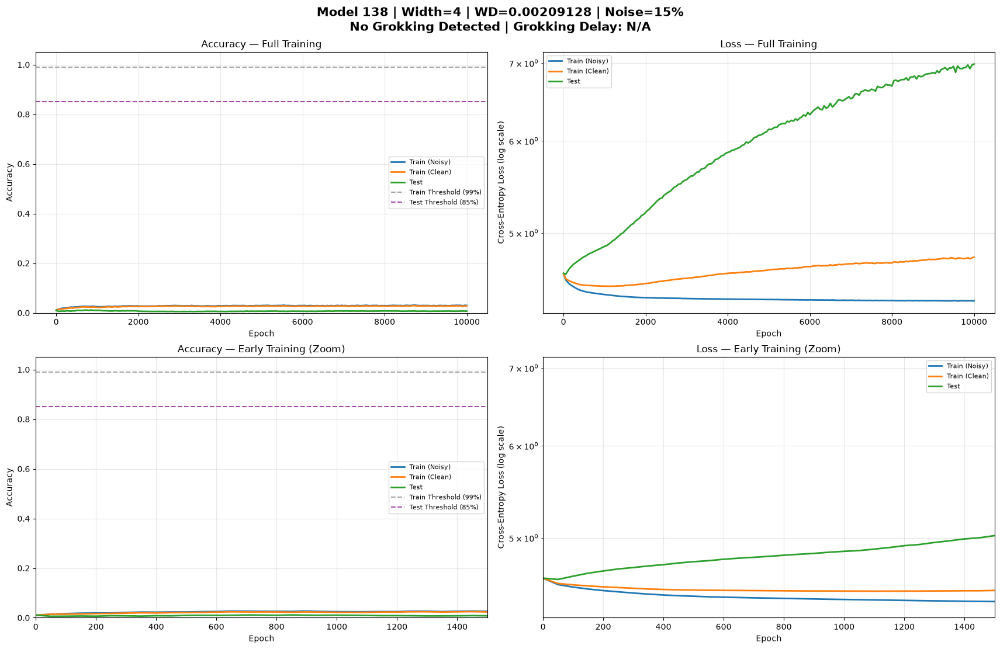

Training Models:  45%|████▌     | 139/308 [02:18<02:37,  1.07model/s]

Model 139: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_139/learning_curves.png


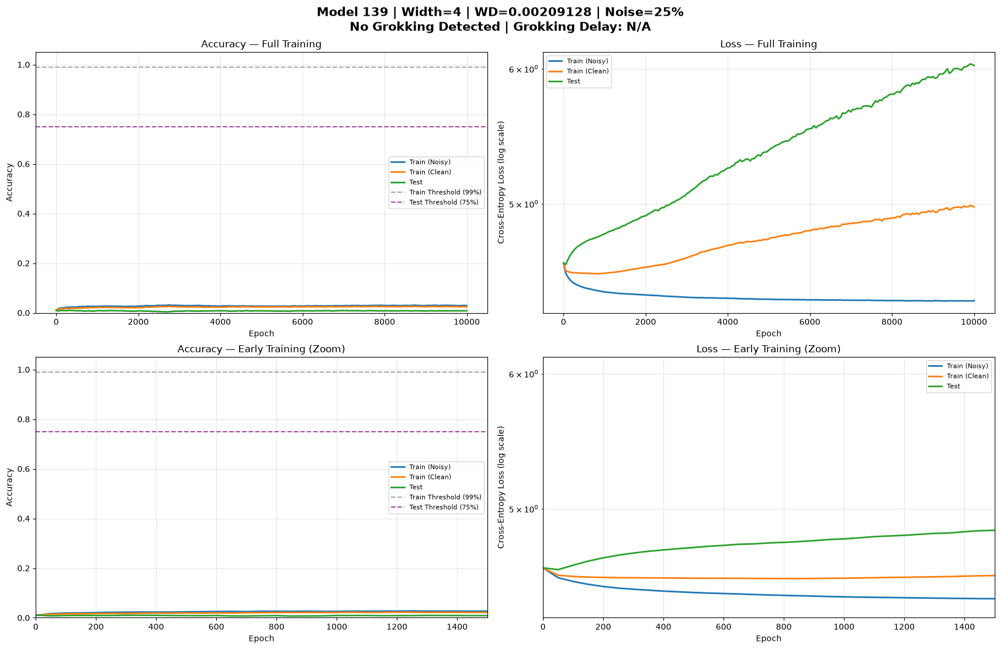

Training Models:  45%|████▌     | 140/308 [02:19<02:30,  1.11model/s]

Model 140: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_140/learning_curves.png


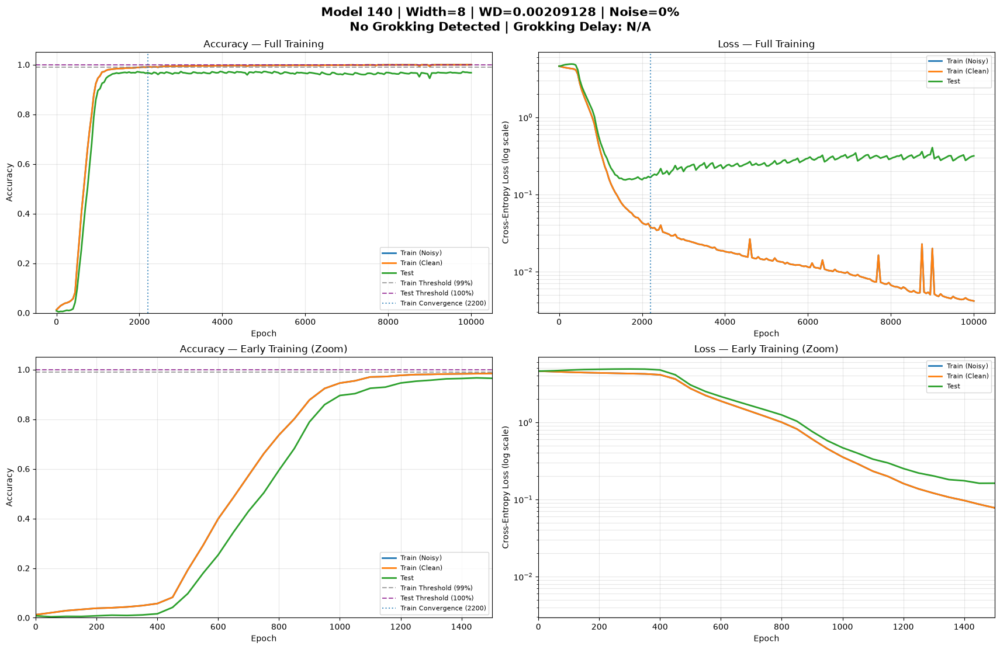

Training Models:  46%|████▌     | 141/308 [02:20<02:36,  1.07model/s]

Model 141: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_141/learning_curves.png


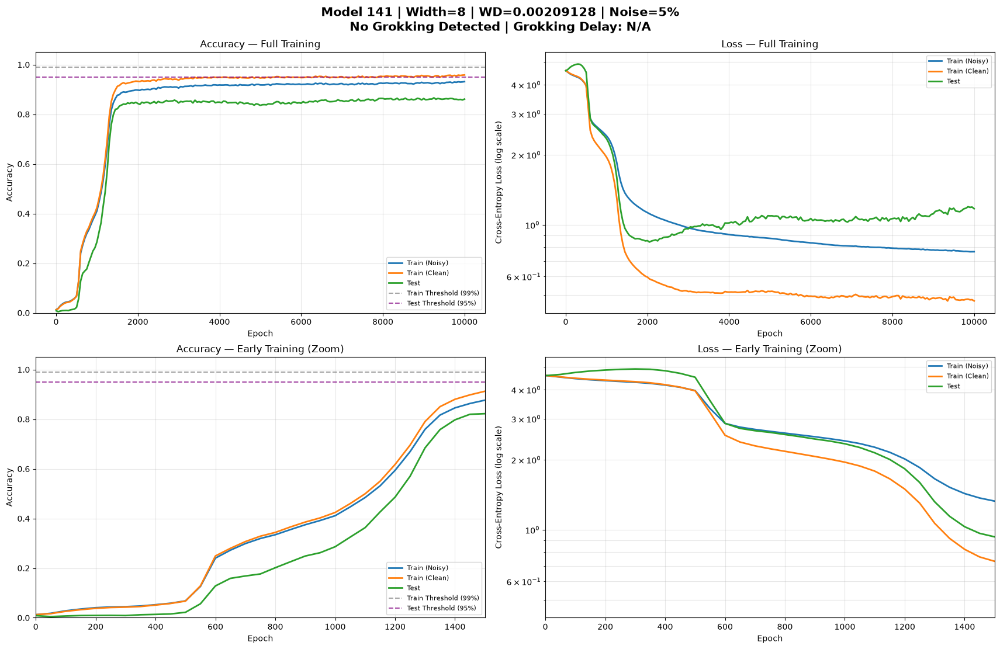

Training Models:  46%|████▌     | 142/308 [02:21<02:36,  1.06model/s]

Model 142: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_142/learning_curves.png


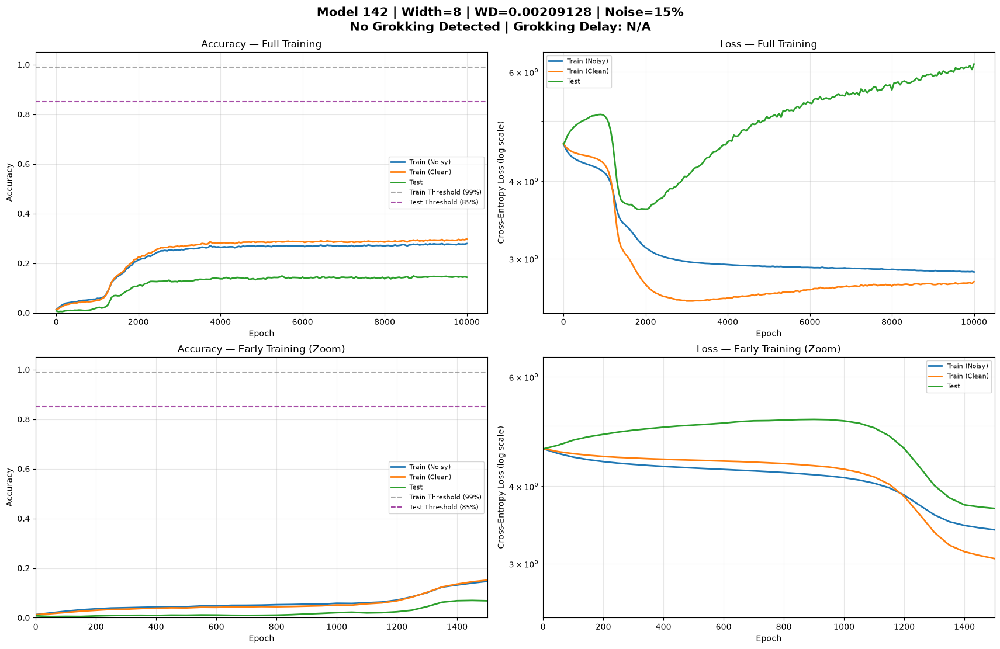

Training Models:  46%|████▋     | 143/308 [02:22<02:37,  1.05model/s]

Model 143: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_143/learning_curves.png


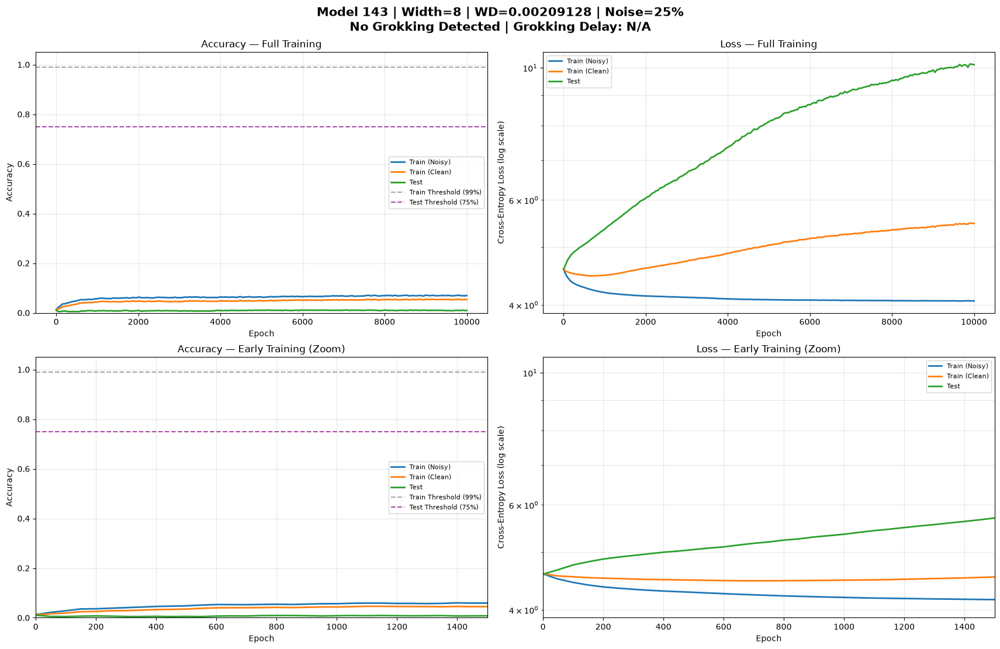

Training Models:  47%|████▋     | 144/308 [02:23<02:33,  1.07model/s]

Model 144: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_144/learning_curves.png


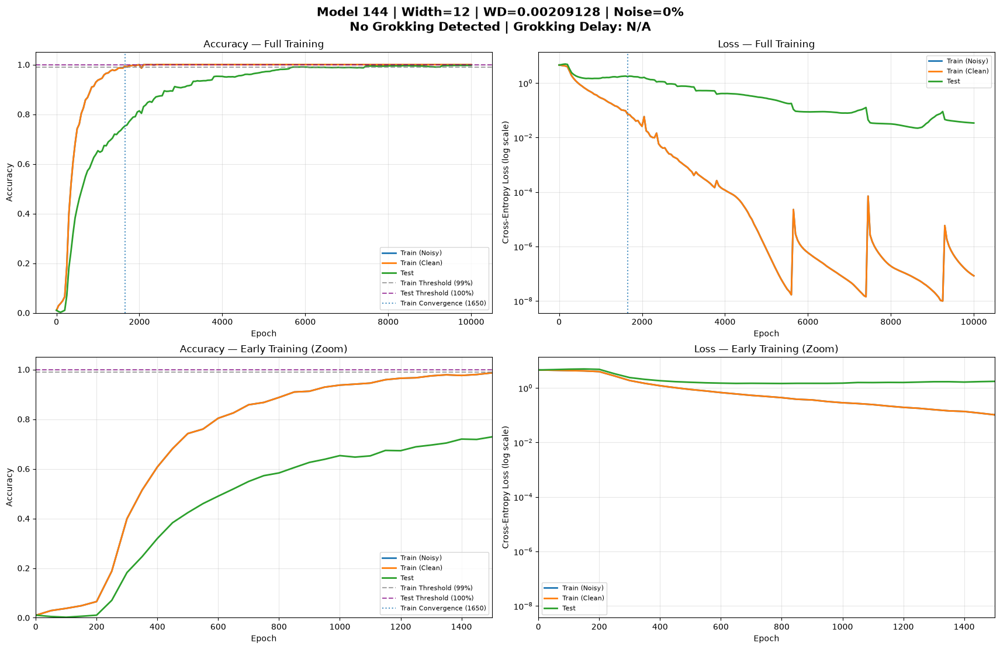

Training Models:  47%|████▋     | 145/308 [02:24<02:31,  1.08model/s]

Model 145: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_145/learning_curves.png


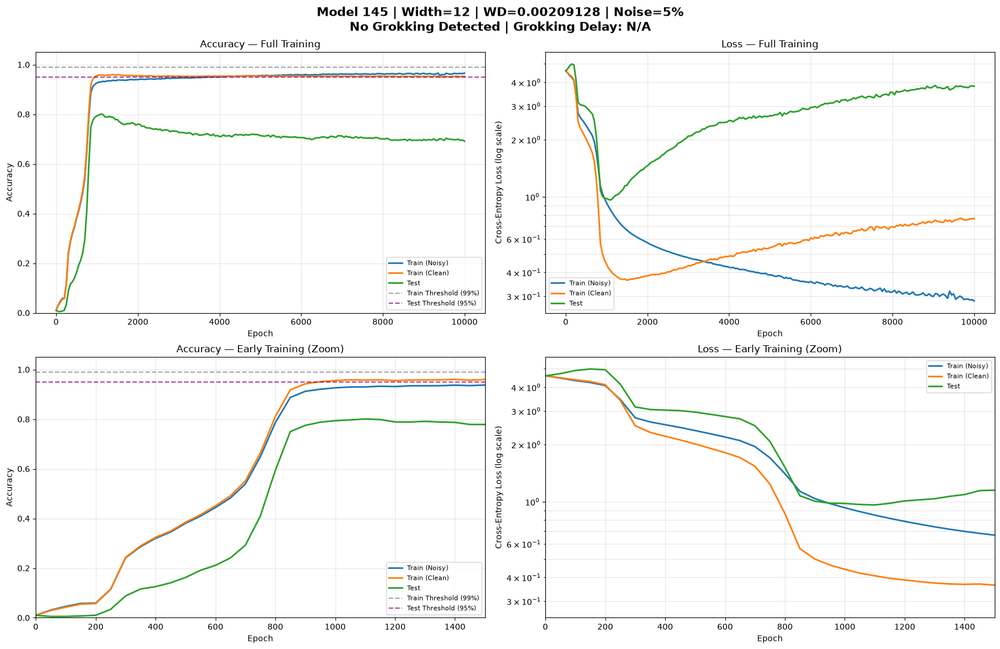

Training Models:  47%|████▋     | 146/308 [02:25<02:34,  1.05model/s]

Model 146: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_146/learning_curves.png


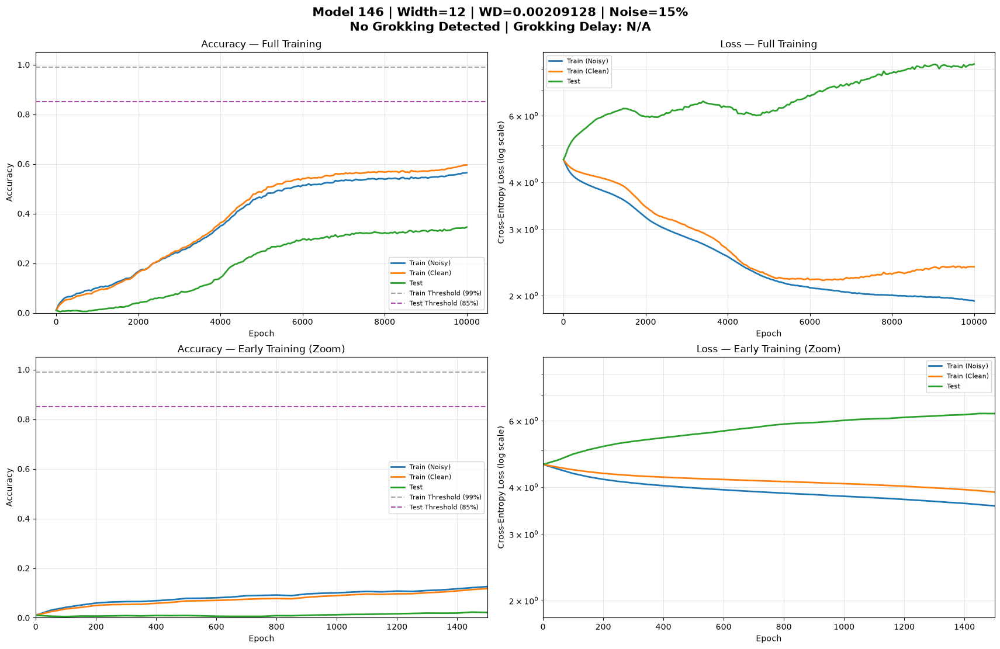

Training Models:  48%|████▊     | 147/308 [02:26<02:30,  1.07model/s]

Model 147: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_147/learning_curves.png


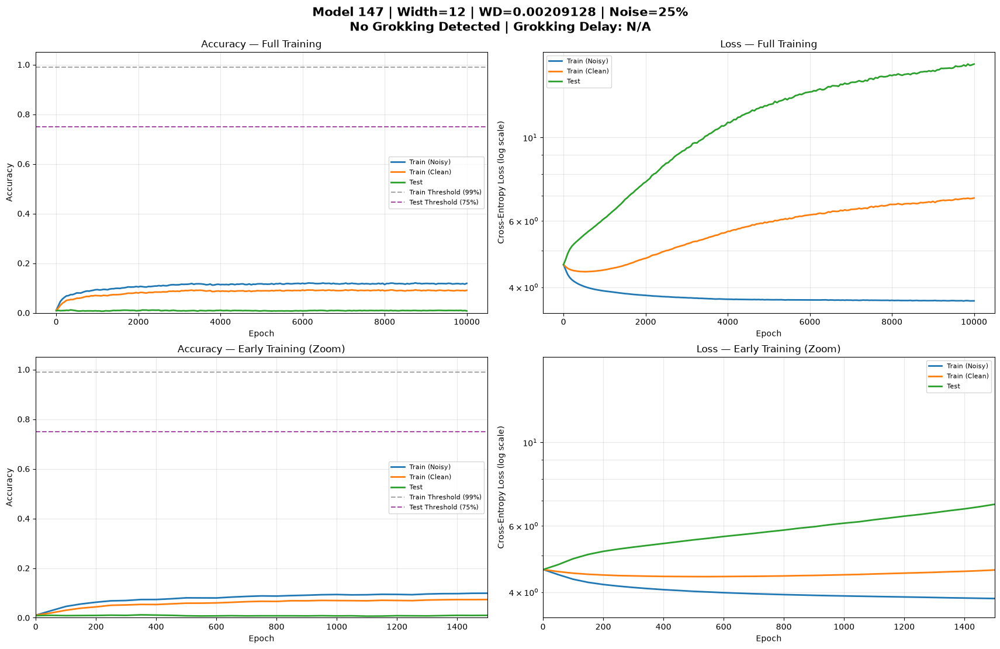

Training Models:  48%|████▊     | 148/308 [02:27<02:33,  1.04model/s]

Model 148: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_148/learning_curves.png


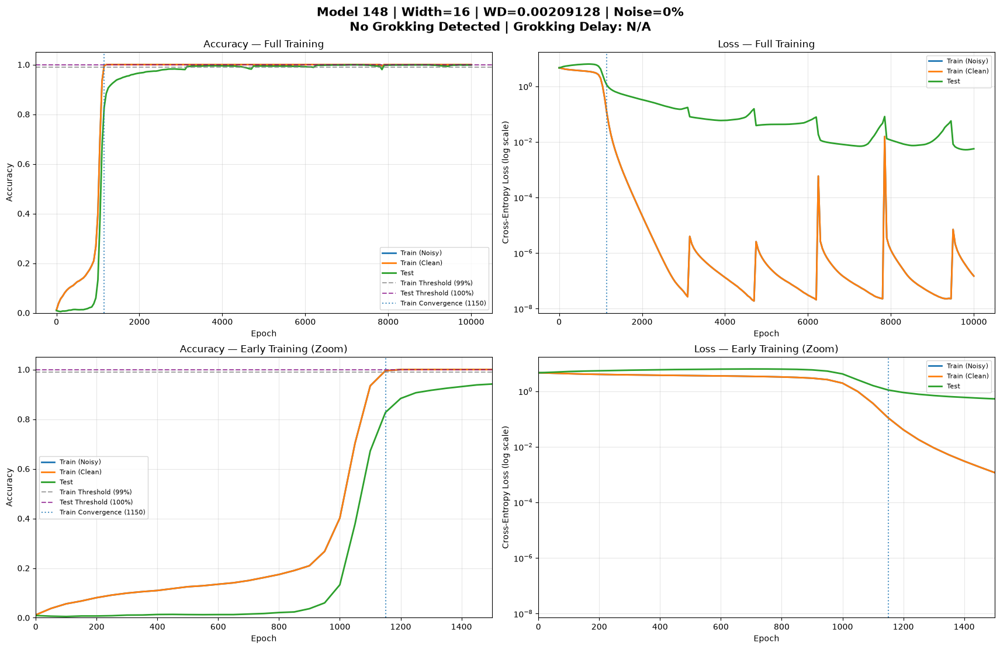

Training Models:  48%|████▊     | 149/308 [02:27<02:29,  1.06model/s]

Model 149: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_149/learning_curves.png


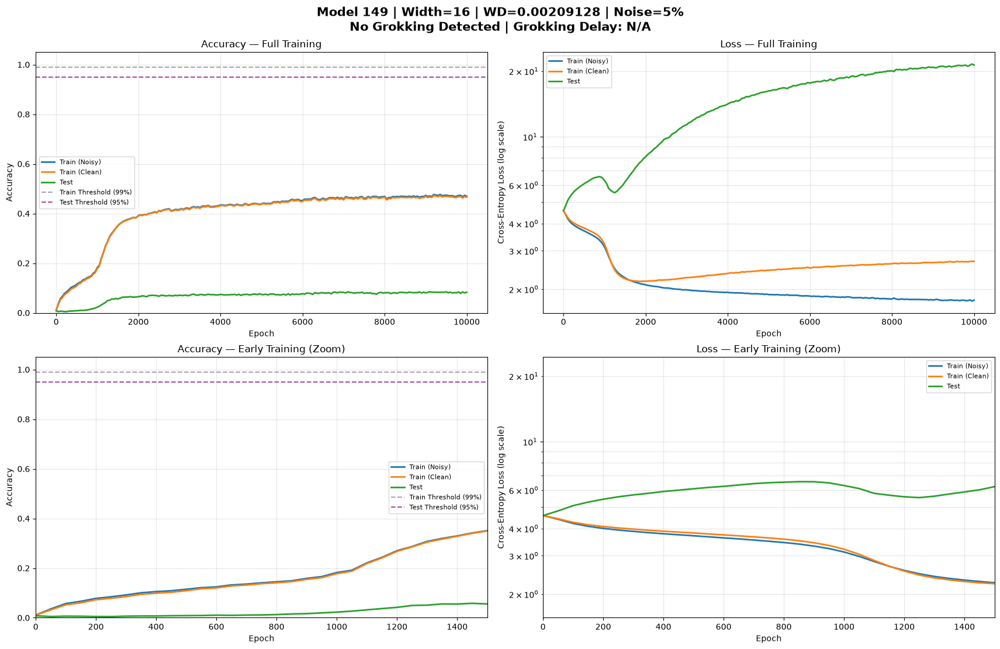

Training Models:  49%|████▊     | 150/308 [02:28<02:30,  1.05model/s]

Model 150: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_150/learning_curves.png


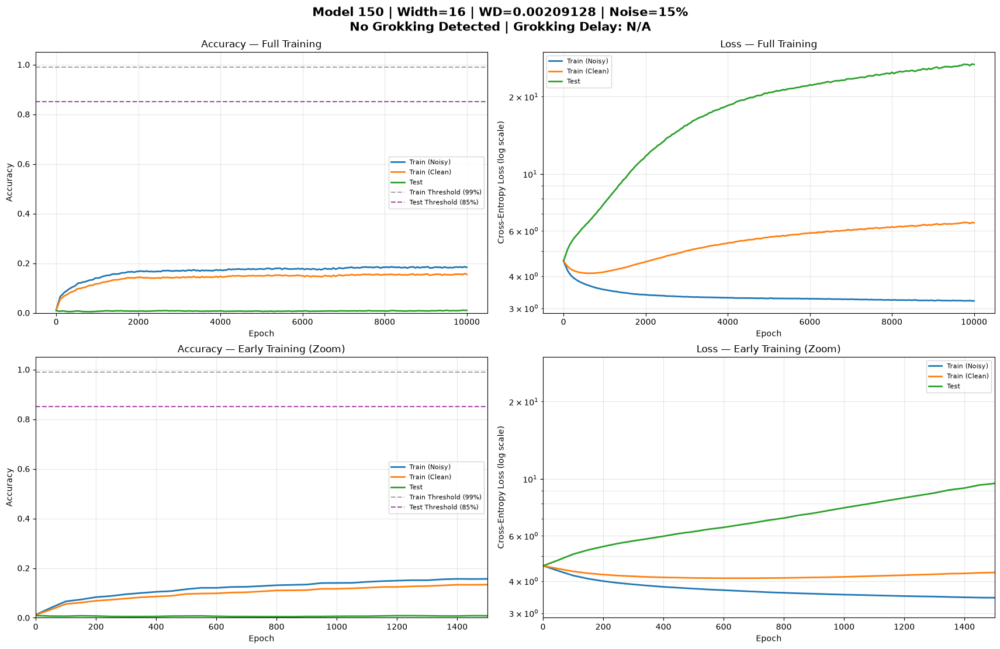

Training Models:  49%|████▉     | 151/308 [02:29<02:29,  1.05model/s]

Model 151: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_151/learning_curves.png


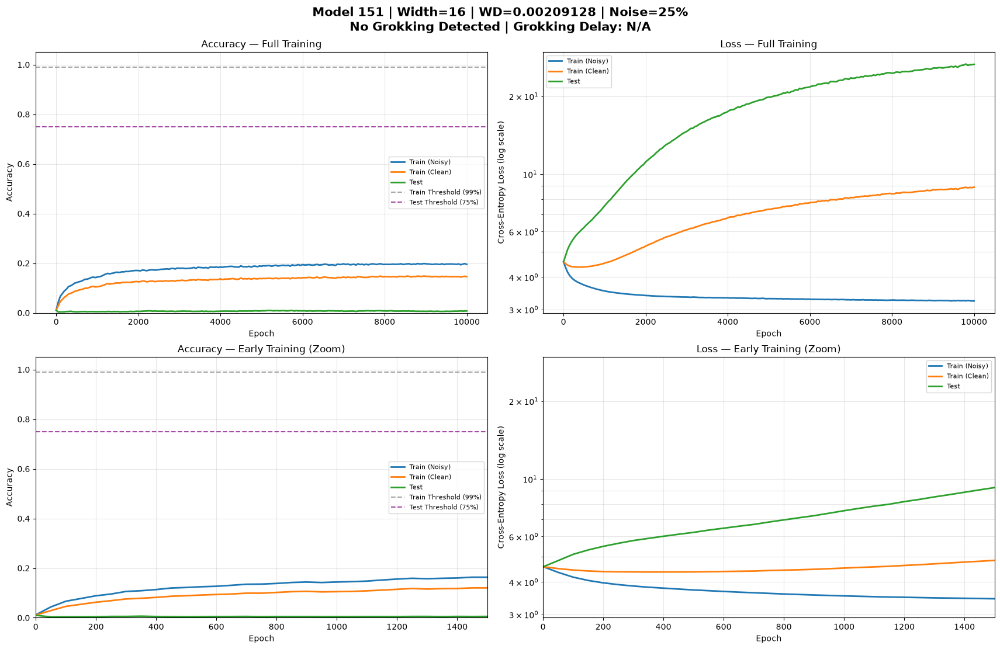

Training Models:  49%|████▉     | 152/308 [02:30<02:27,  1.05model/s]

Model 152: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_152/learning_curves.png


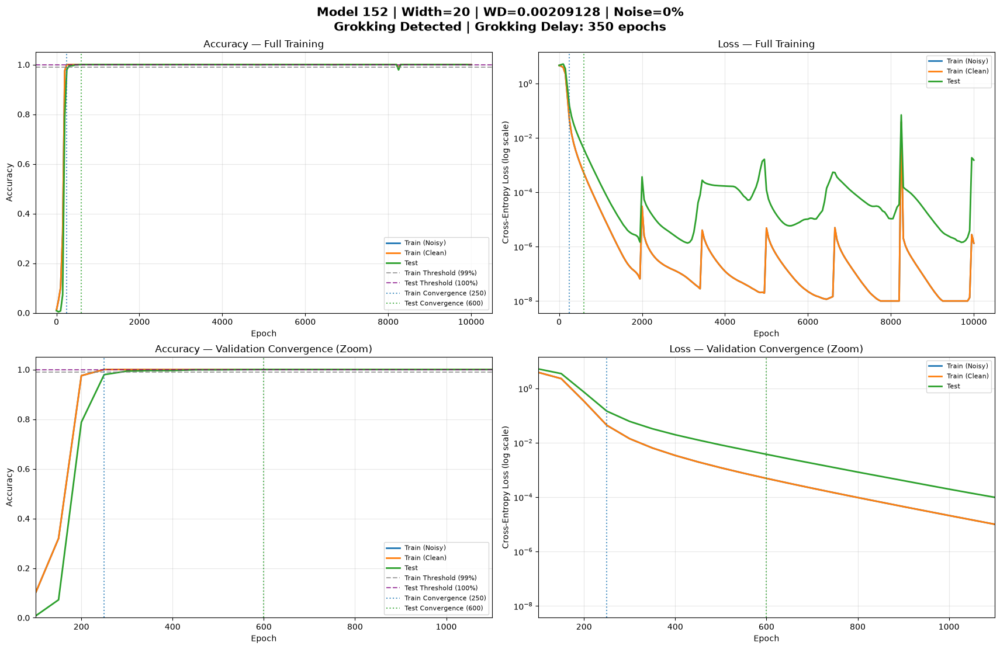

Training Models:  50%|████▉     | 153/308 [02:31<02:32,  1.02model/s]

Model 153: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_153/learning_curves.png


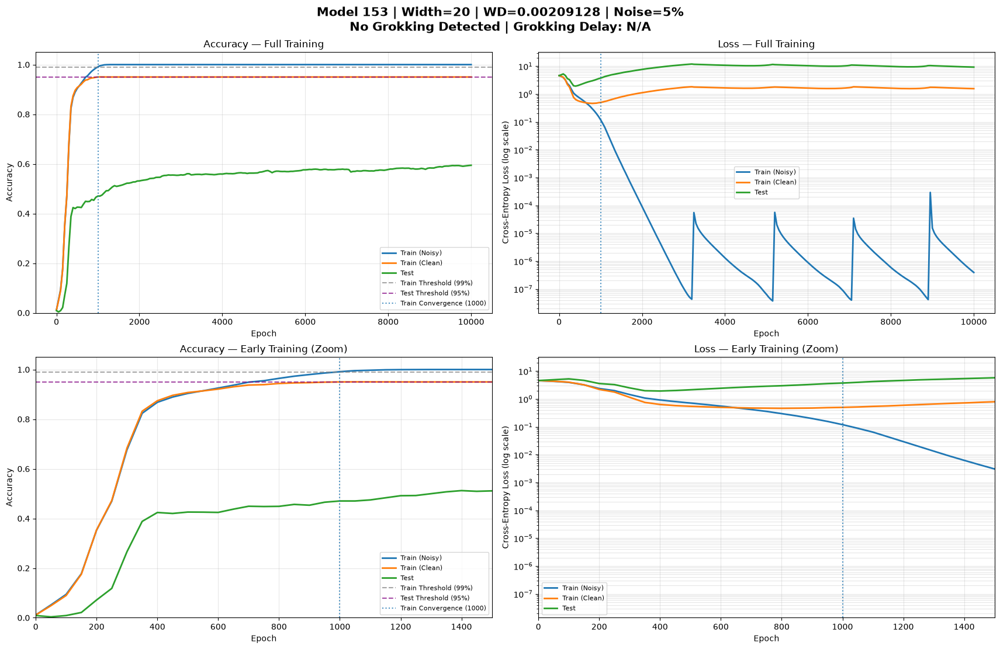

Training Models:  50%|█████     | 154/308 [02:33<02:54,  1.13s/model]

Model 154: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_154/learning_curves.png


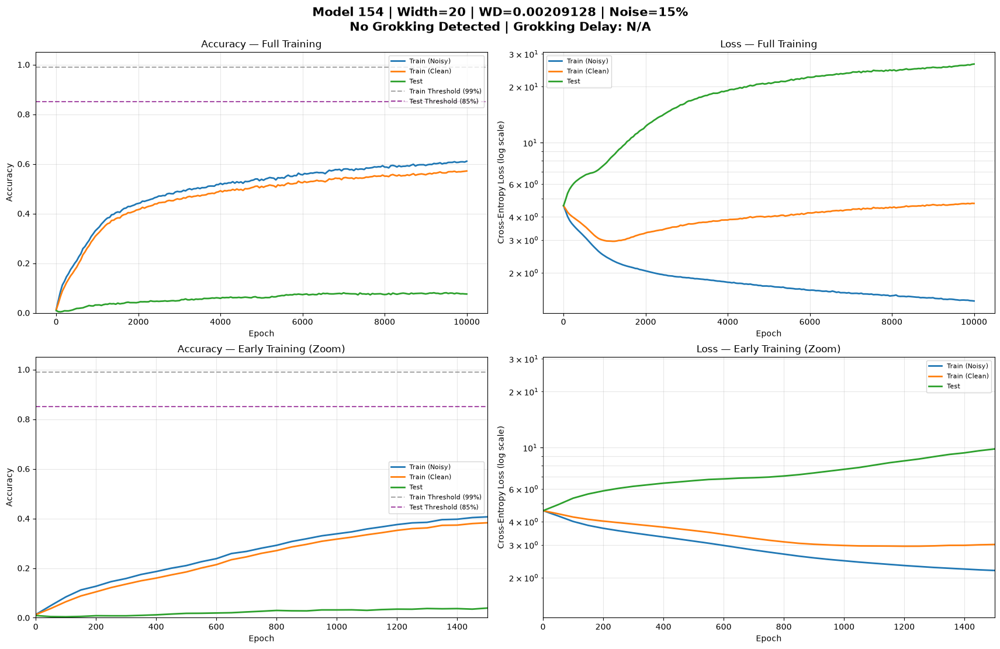

Training Models:  50%|█████     | 155/308 [02:34<02:47,  1.10s/model]

Model 155: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_155/learning_curves.png


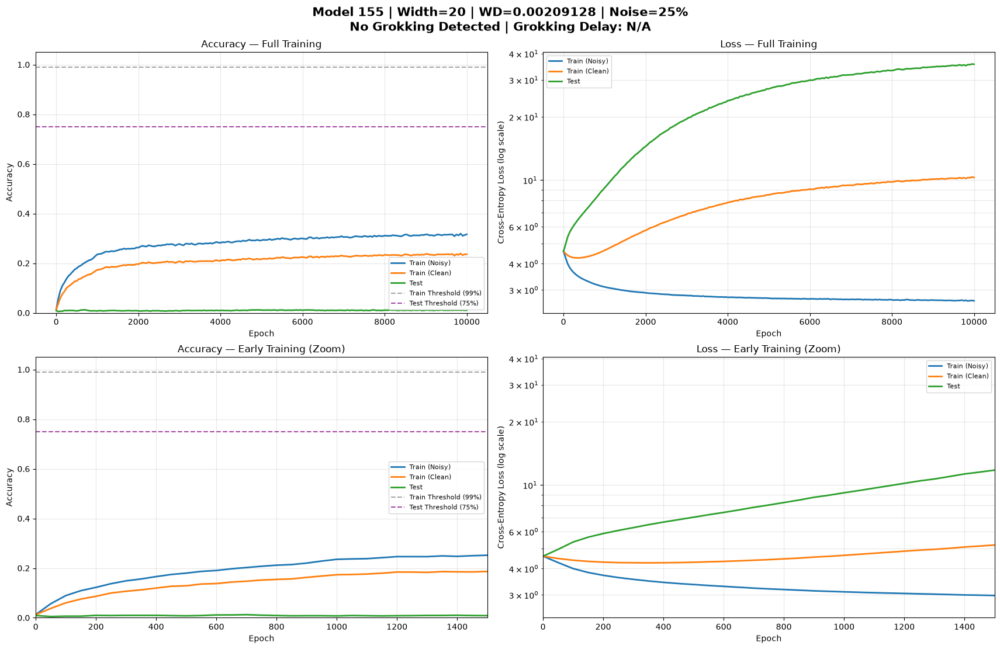

Training Models:  51%|█████     | 156/308 [02:35<02:47,  1.10s/model]

Model 156: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_156/learning_curves.png


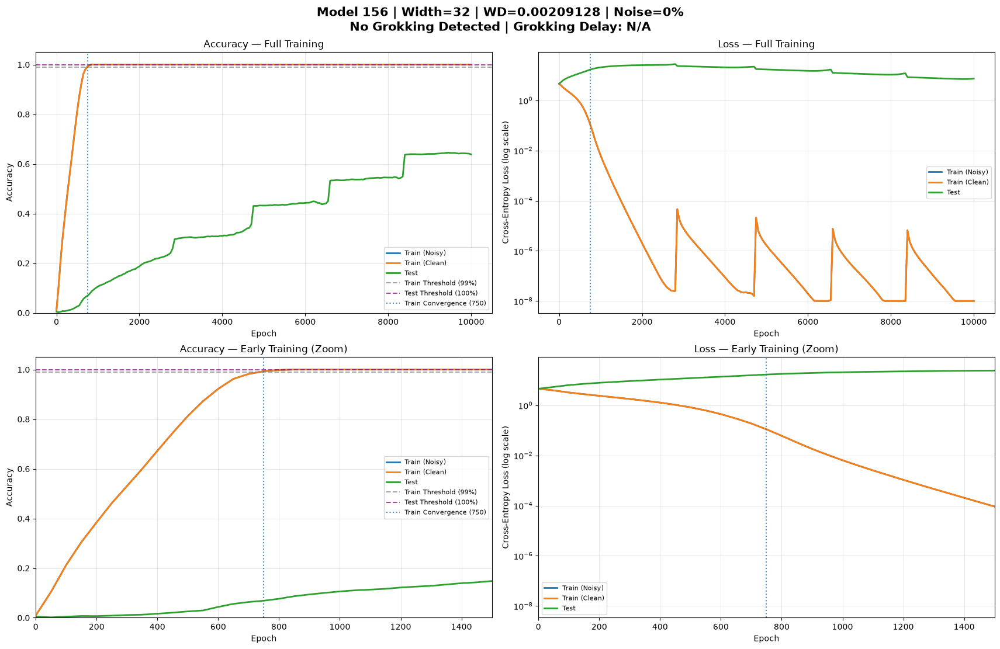

Training Models:  51%|█████     | 157/308 [02:36<02:37,  1.04s/model]

Model 157: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_157/learning_curves.png


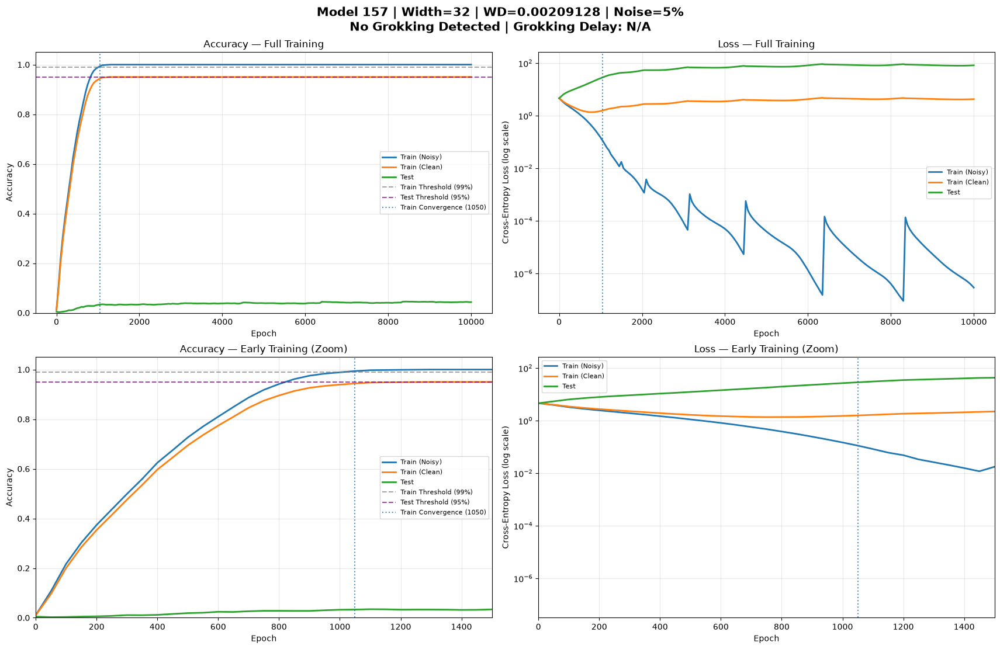

Training Models:  51%|█████▏    | 158/308 [02:37<02:30,  1.00s/model]

Model 158: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_158/learning_curves.png


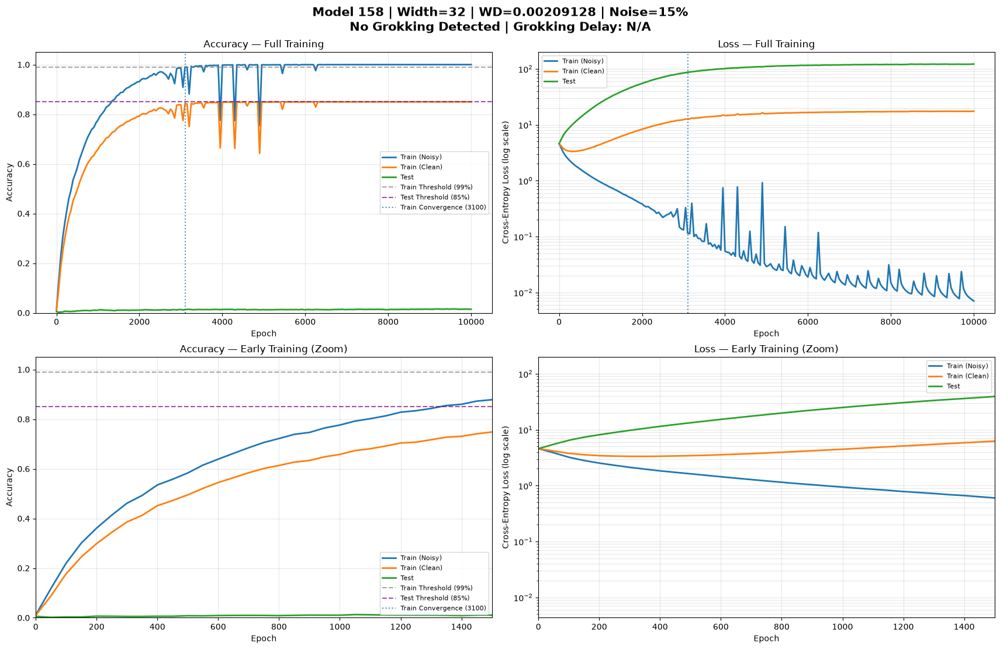

Training Models:  52%|█████▏    | 159/308 [02:38<02:35,  1.05s/model]

Model 159: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_159/learning_curves.png


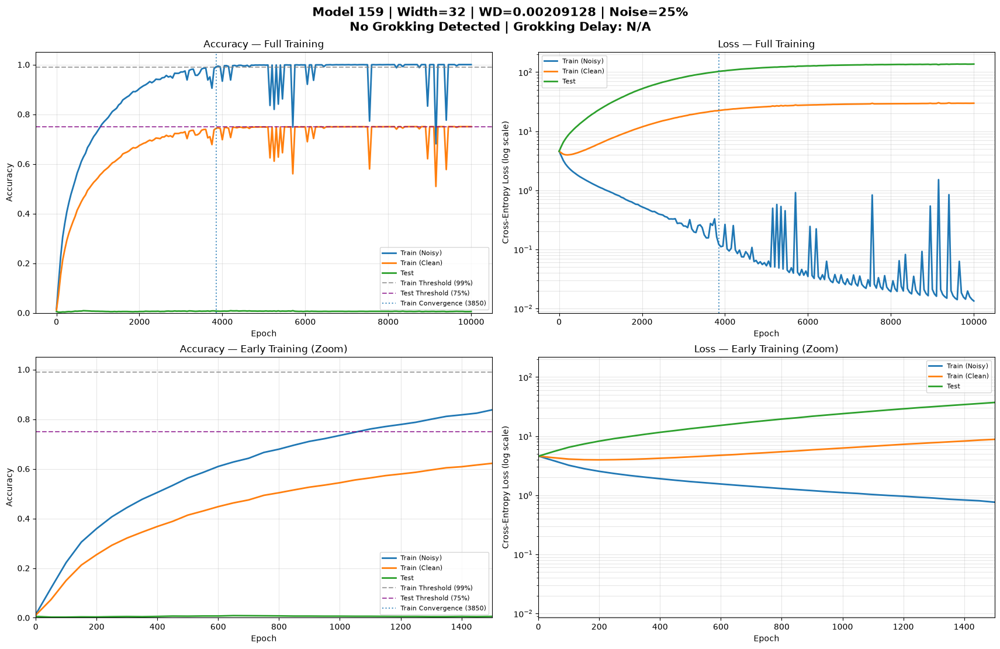

Training Models:  52%|█████▏    | 160/308 [02:39<02:44,  1.11s/model]

Model 160: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_160/learning_curves.png


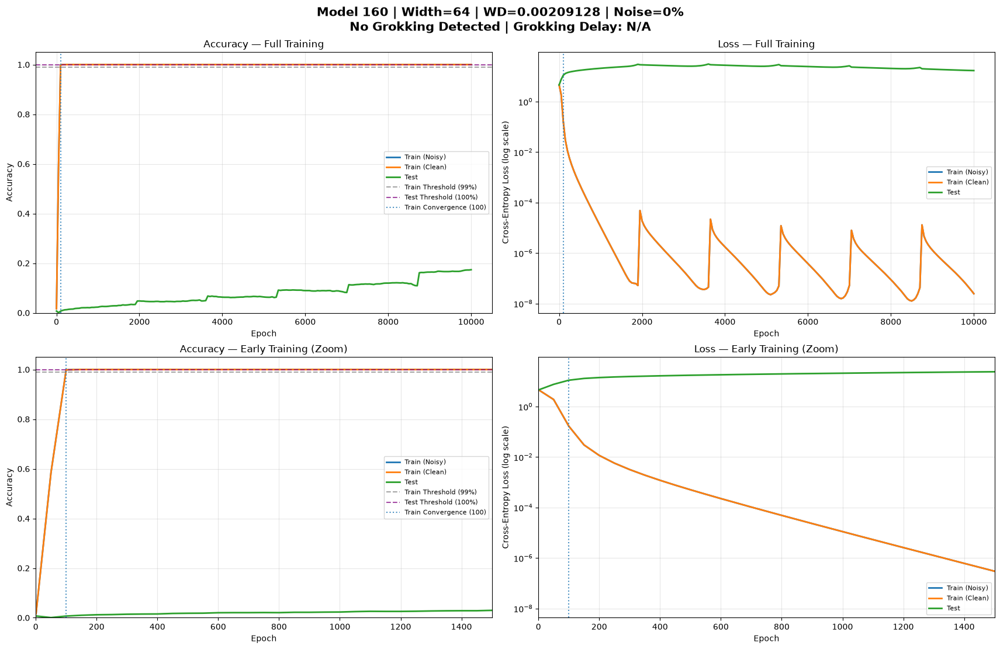

Training Models:  52%|█████▏    | 161/308 [02:40<02:34,  1.05s/model]

Model 161: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_161/learning_curves.png


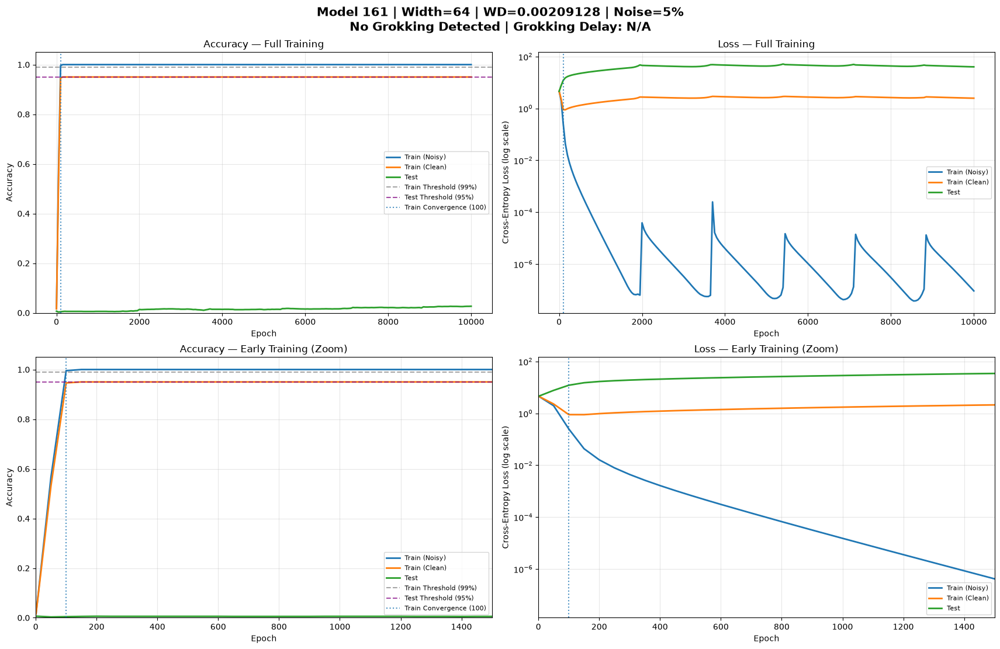

Training Models:  53%|█████▎    | 162/308 [02:41<02:26,  1.01s/model]

Model 162: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_162/learning_curves.png


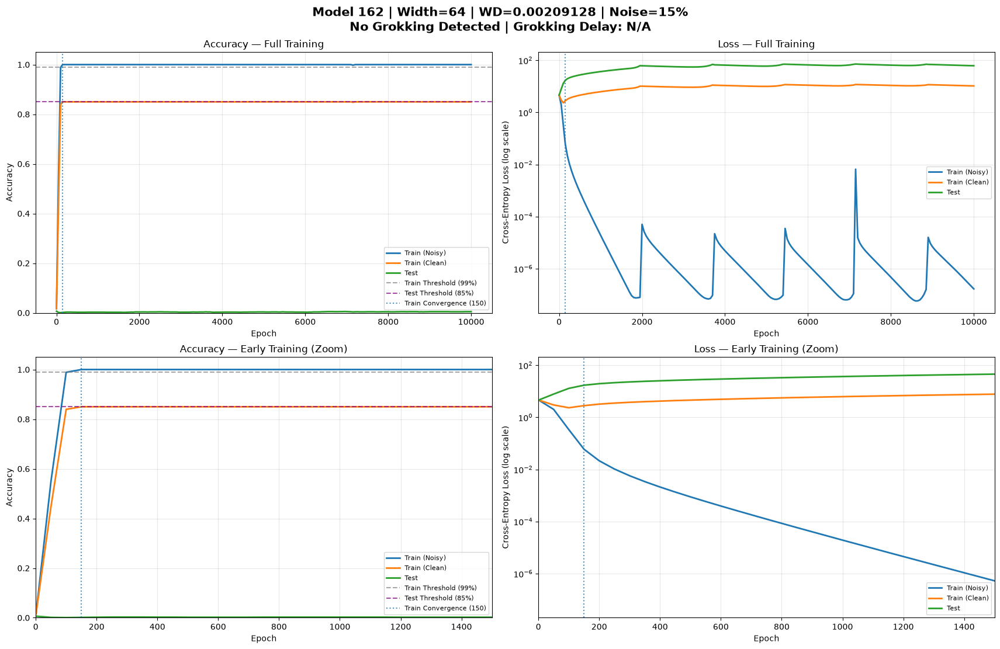

Training Models:  53%|█████▎    | 163/308 [02:42<02:21,  1.02model/s]

Model 163: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_163/learning_curves.png


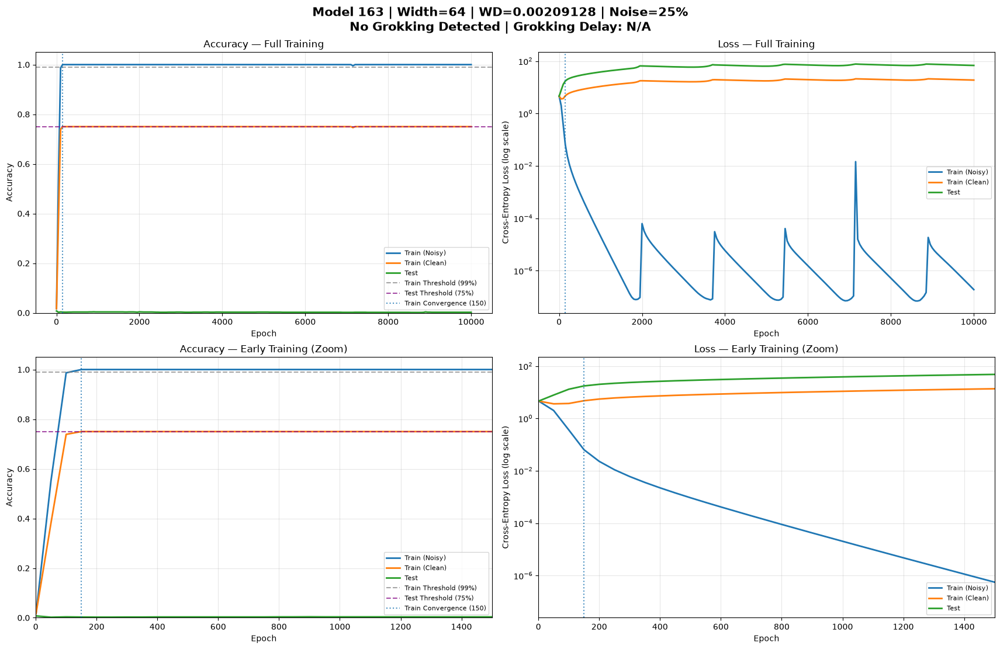

Training Models:  53%|█████▎    | 164/308 [02:43<02:17,  1.05model/s]

Model 164: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_164/learning_curves.png


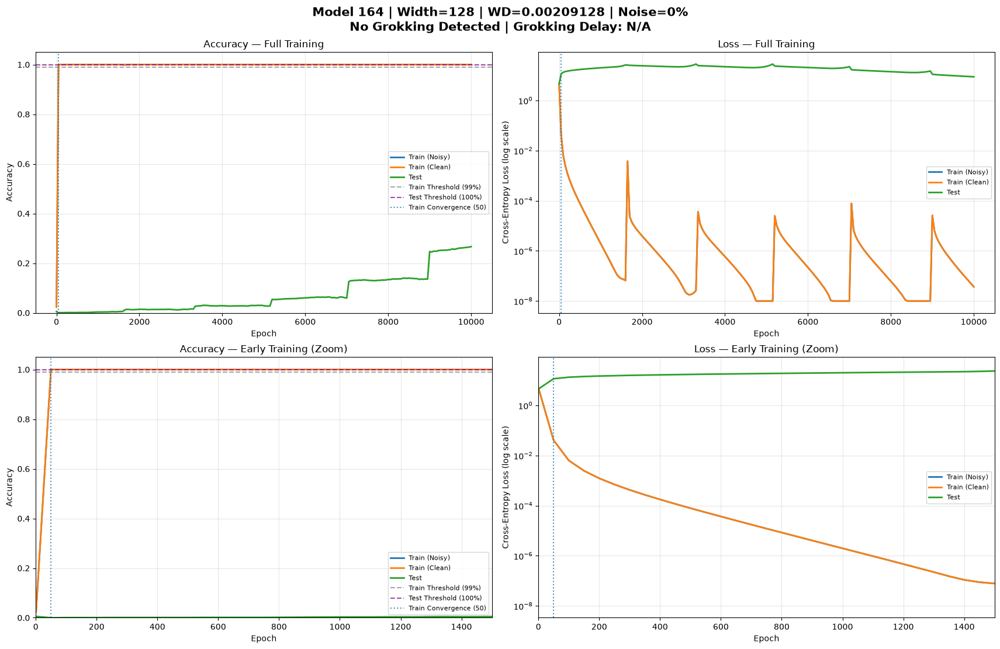

Training Models:  54%|█████▎    | 165/308 [02:44<02:21,  1.01model/s]

Model 165: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_165/learning_curves.png


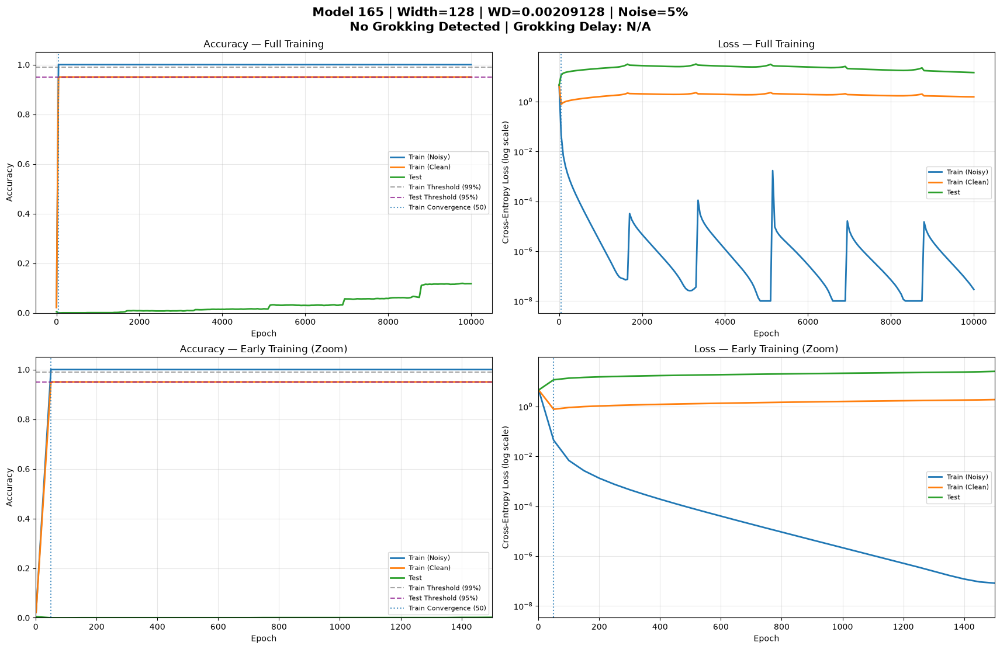

Training Models:  54%|█████▍    | 166/308 [02:45<02:16,  1.04model/s]

Model 166: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_166/learning_curves.png


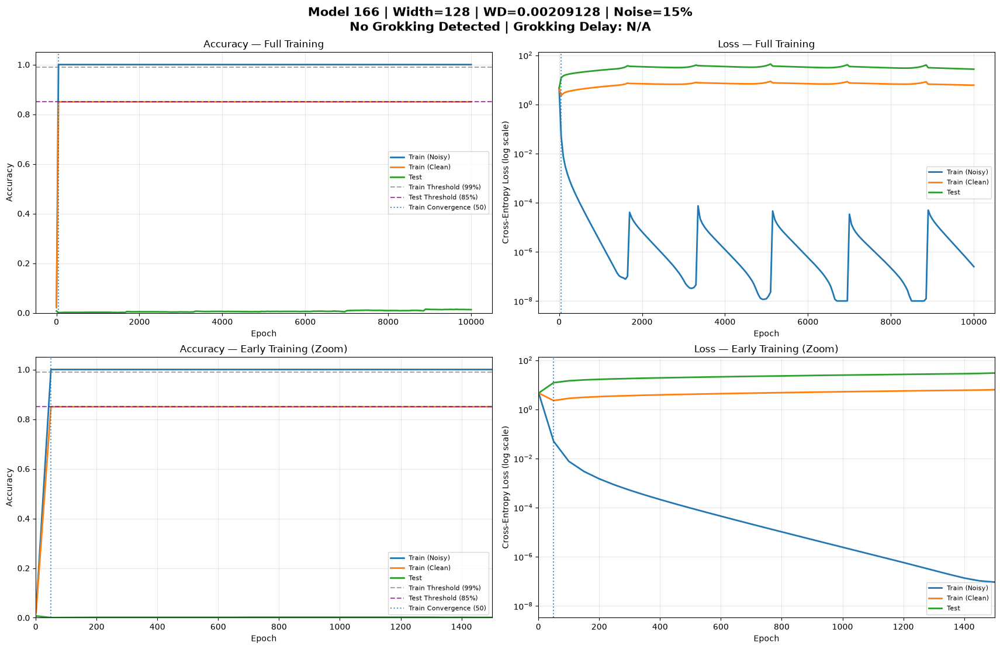

Training Models:  54%|█████▍    | 167/308 [02:46<02:14,  1.05model/s]

Model 167: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_167/learning_curves.png


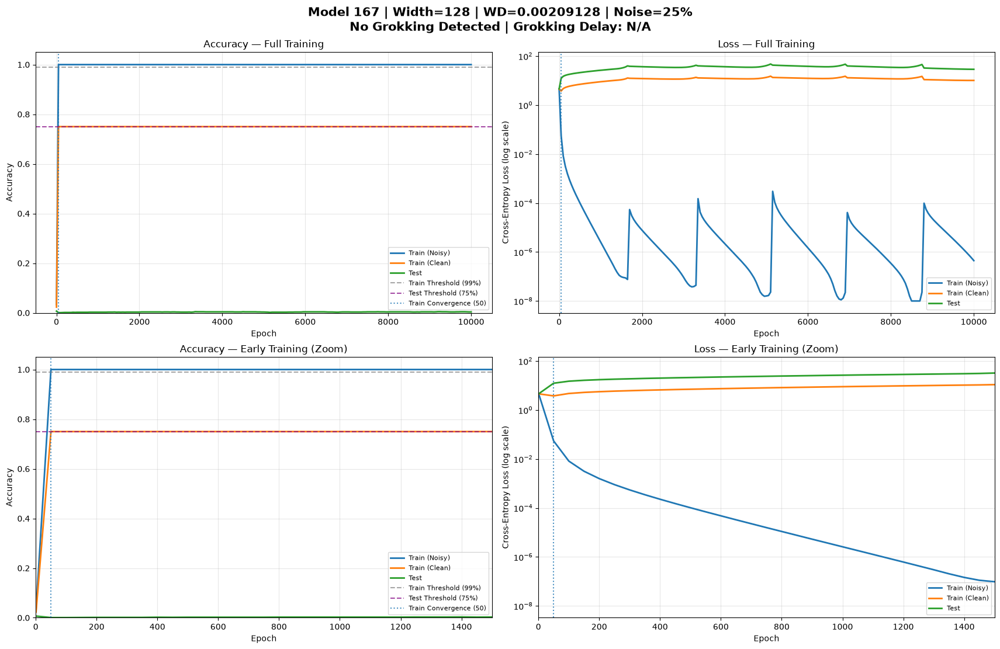

Training Models:  55%|█████▍    | 168/308 [02:47<02:12,  1.06model/s]

Model 168: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_168/learning_curves.png


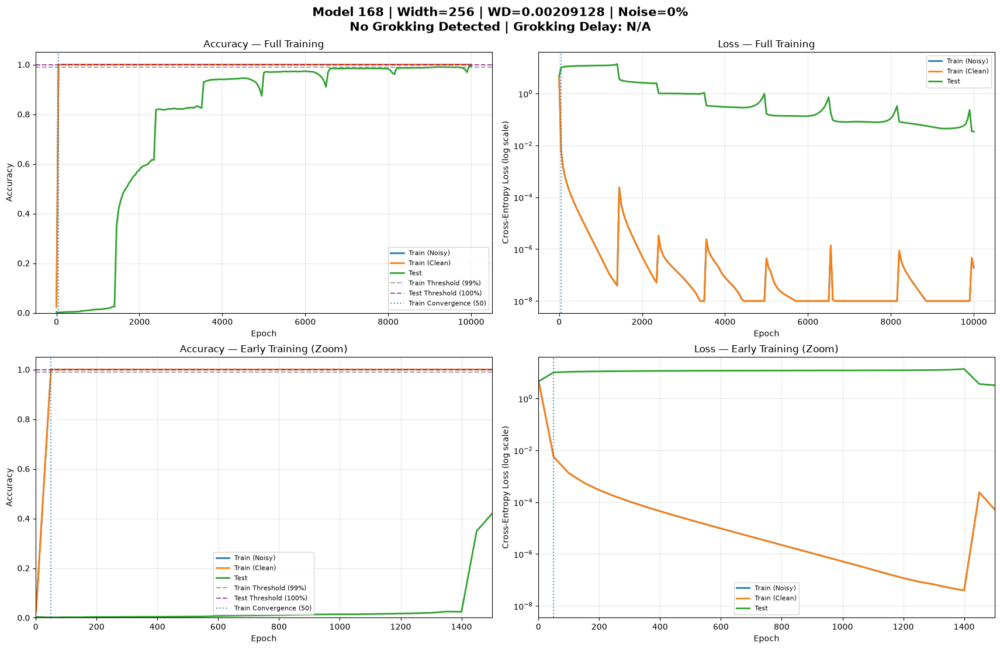

Training Models:  55%|█████▍    | 169/308 [02:48<02:10,  1.06model/s]

Model 169: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_169/learning_curves.png


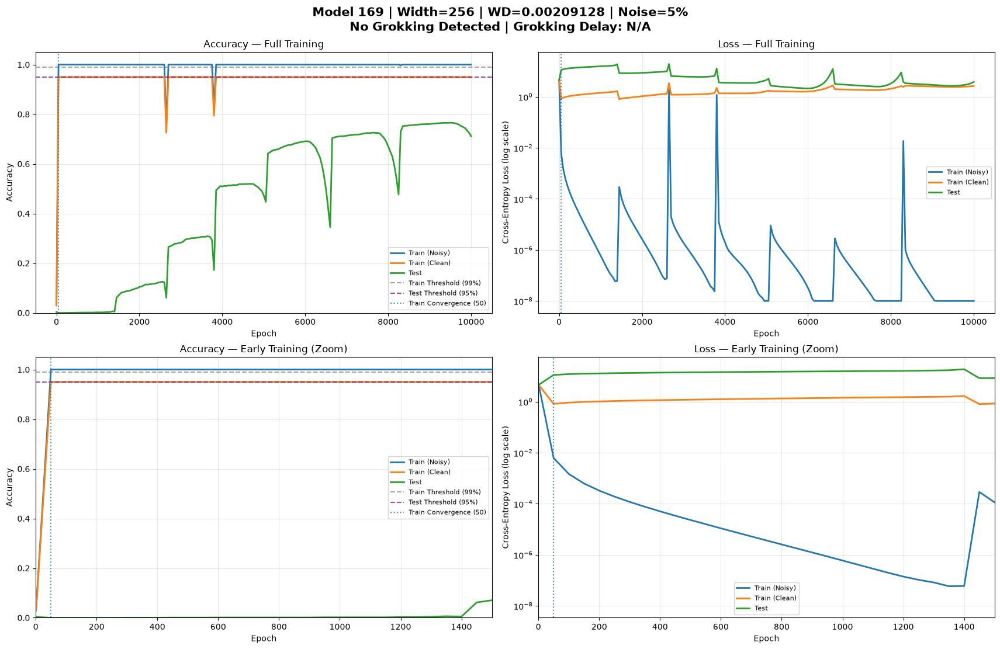

Training Models:  55%|█████▌    | 170/308 [02:49<02:14,  1.03model/s]

Model 170: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_170/learning_curves.png


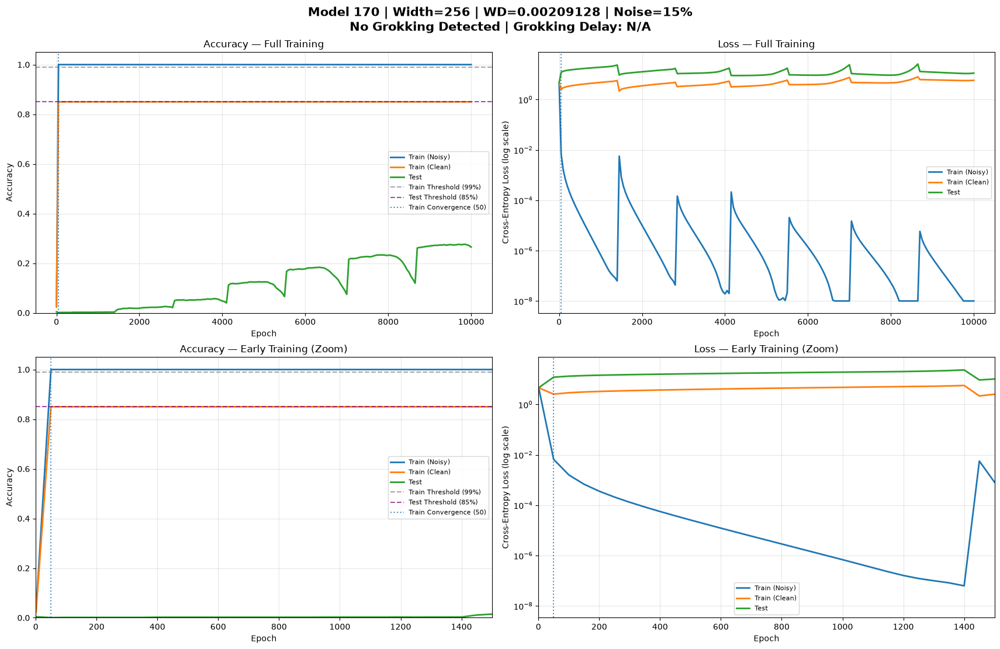

Training Models:  56%|█████▌    | 171/308 [02:50<02:11,  1.04model/s]

Model 171: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_171/learning_curves.png


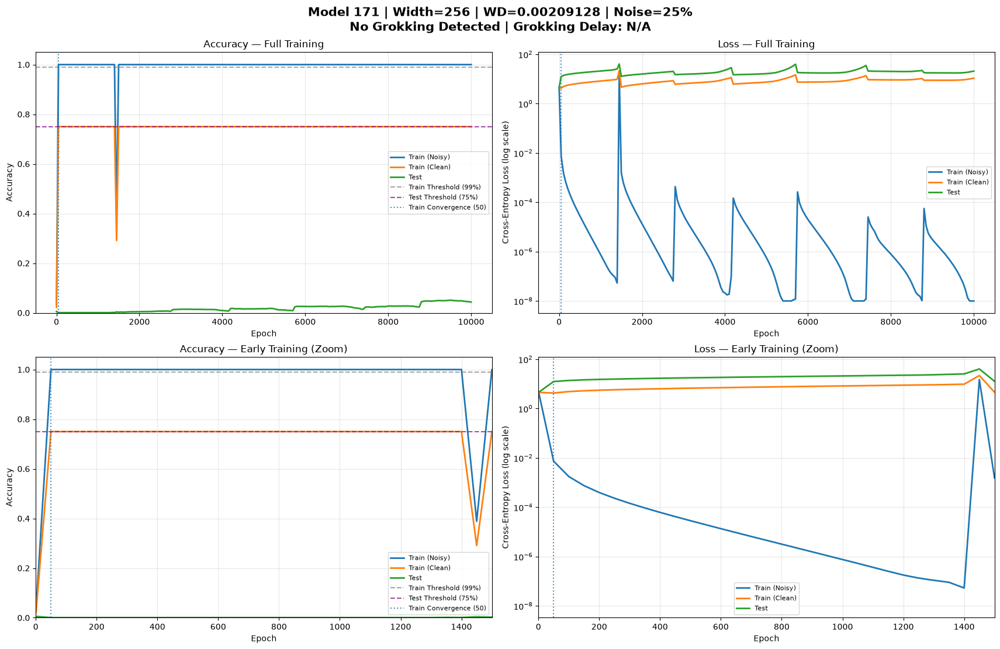

Training Models:  56%|█████▌    | 172/308 [02:51<02:09,  1.05model/s]

Model 172: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_172/learning_curves.png


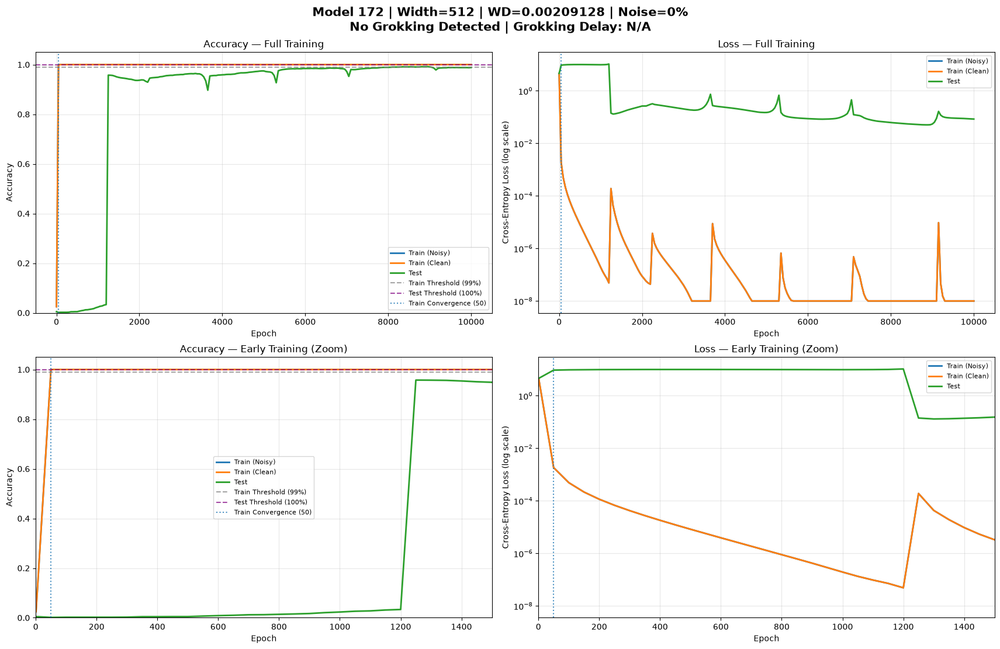

Training Models:  56%|█████▌    | 173/308 [02:51<02:06,  1.07model/s]

Model 173: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_173/learning_curves.png


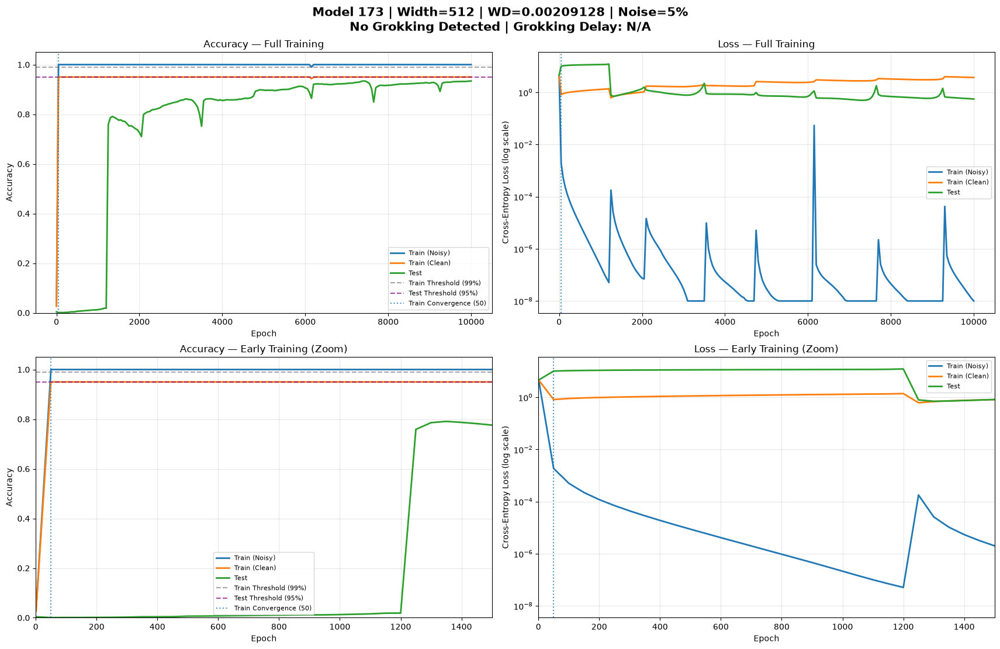

Training Models:  56%|█████▋    | 174/308 [02:52<02:03,  1.08model/s]

Model 174: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_174/learning_curves.png


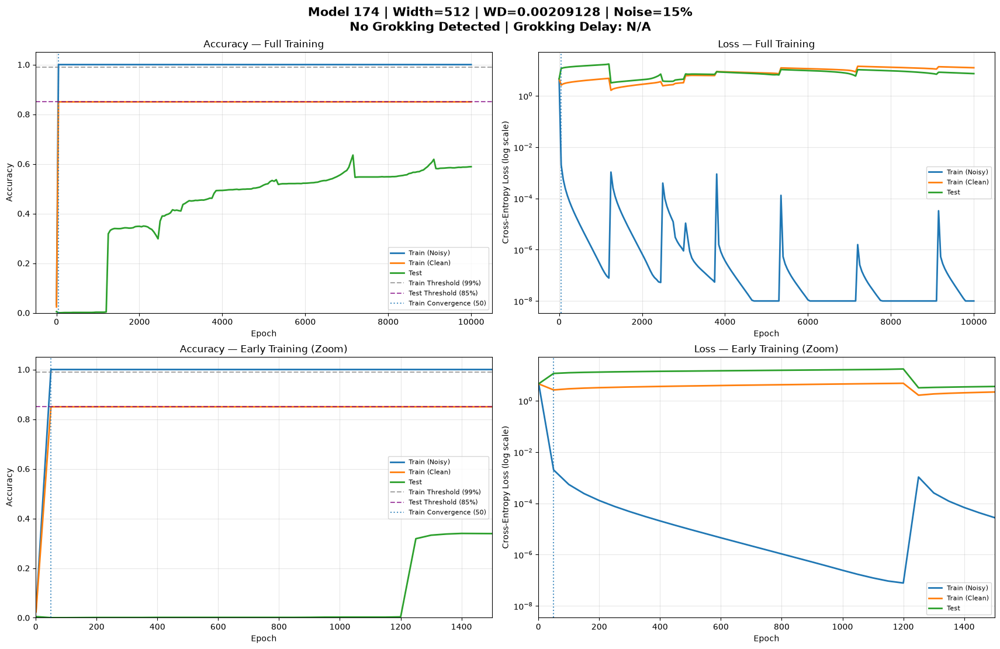

Training Models:  57%|█████▋    | 175/308 [02:53<02:07,  1.04model/s]

Model 175: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_175/learning_curves.png


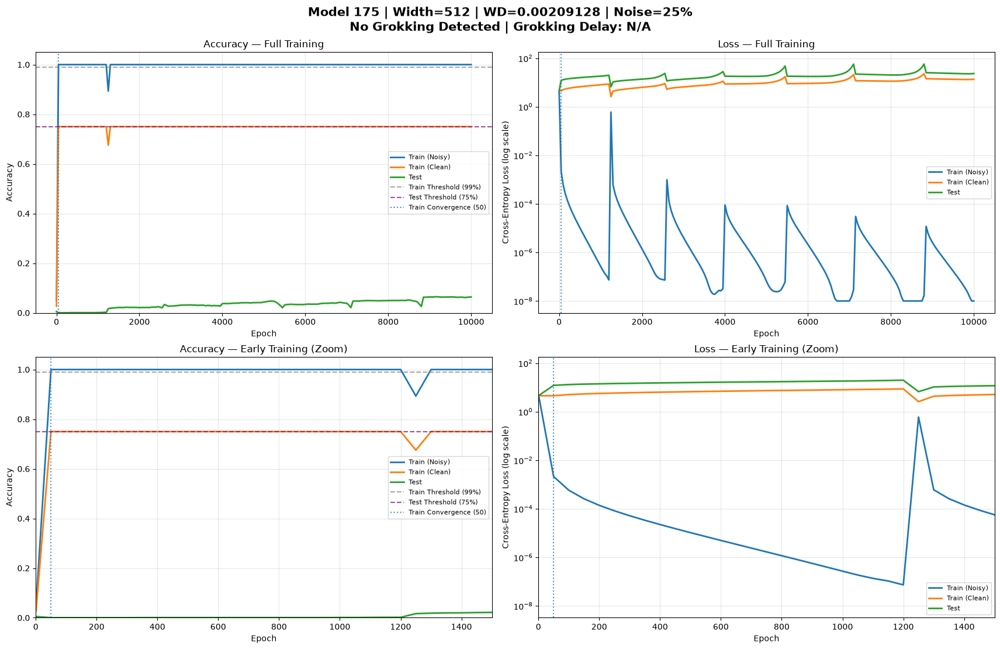

Training Models:  57%|█████▋    | 176/308 [02:54<02:05,  1.05model/s]

Model 176: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_176/learning_curves.png


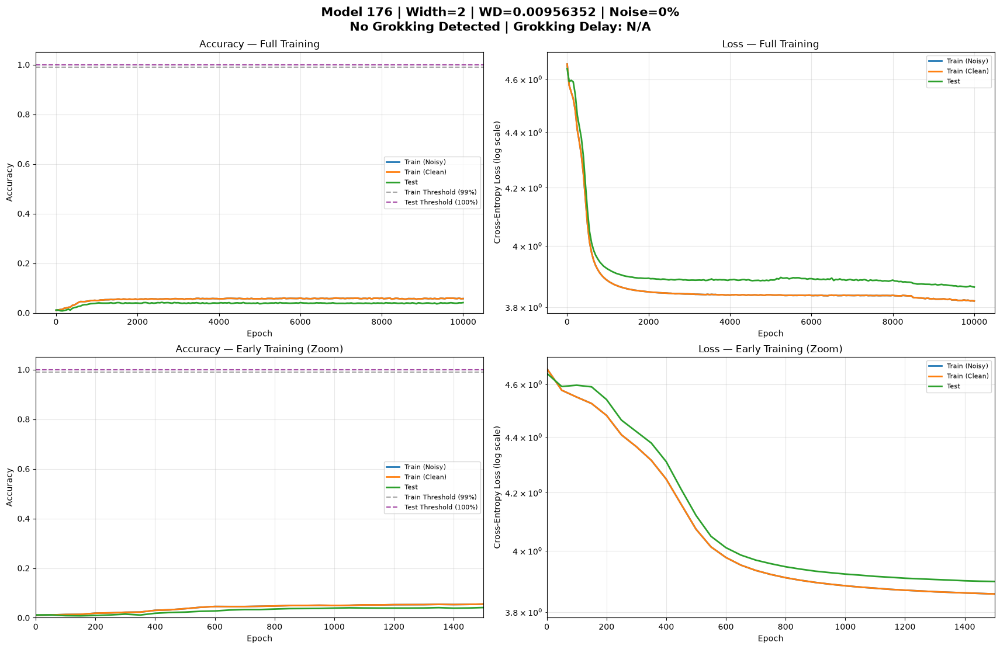

Training Models:  57%|█████▋    | 177/308 [02:55<02:03,  1.06model/s]

Model 177: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_177/learning_curves.png


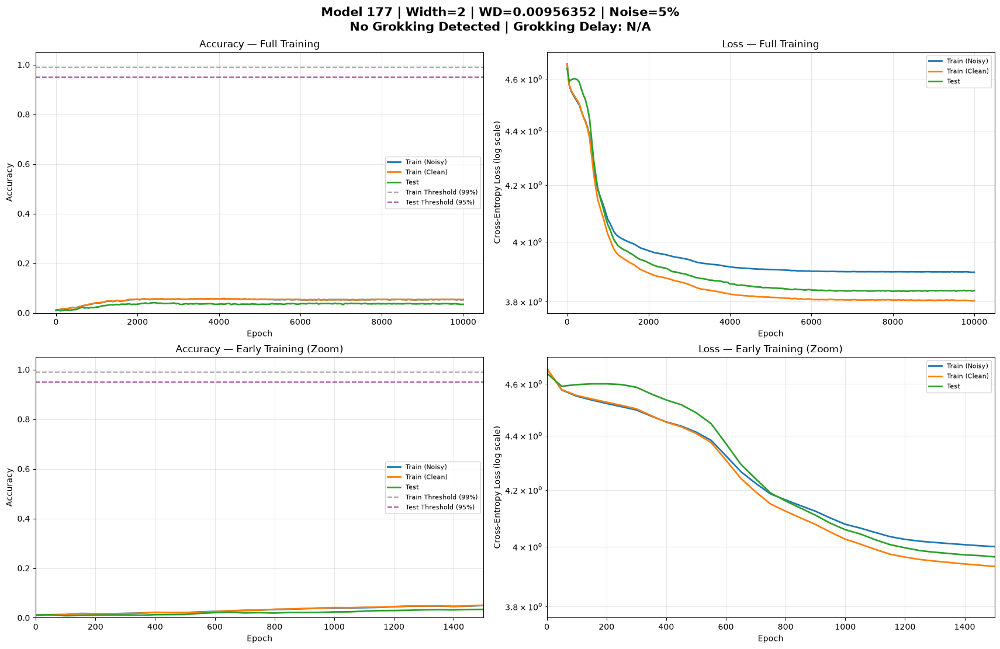

Training Models:  58%|█████▊    | 178/308 [02:56<02:00,  1.08model/s]

Model 178: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_178/learning_curves.png


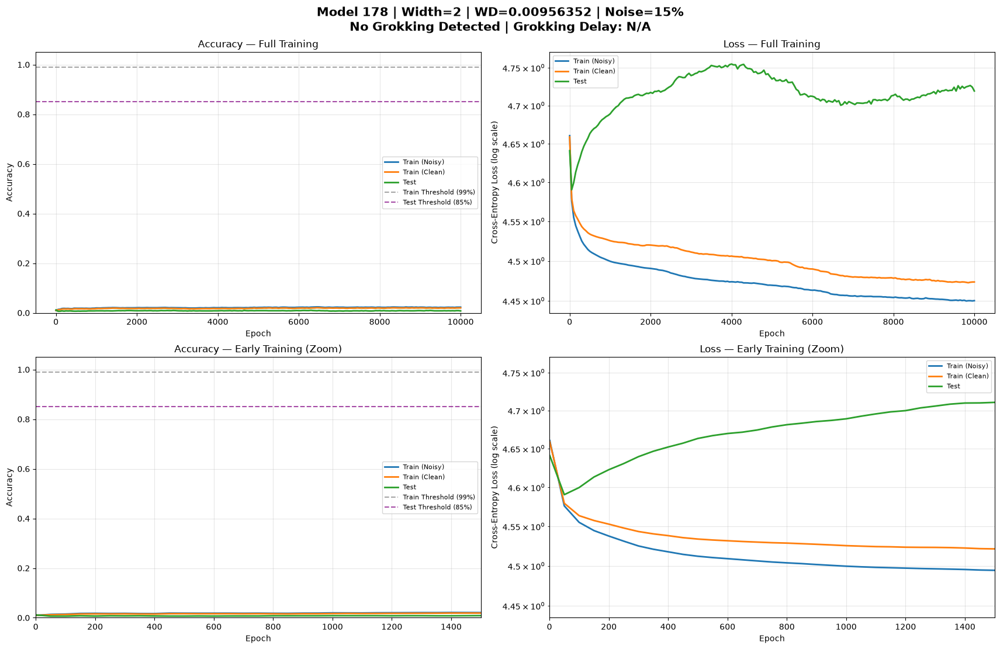

Training Models:  58%|█████▊    | 179/308 [02:57<02:01,  1.07model/s]

Model 179: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_179/learning_curves.png


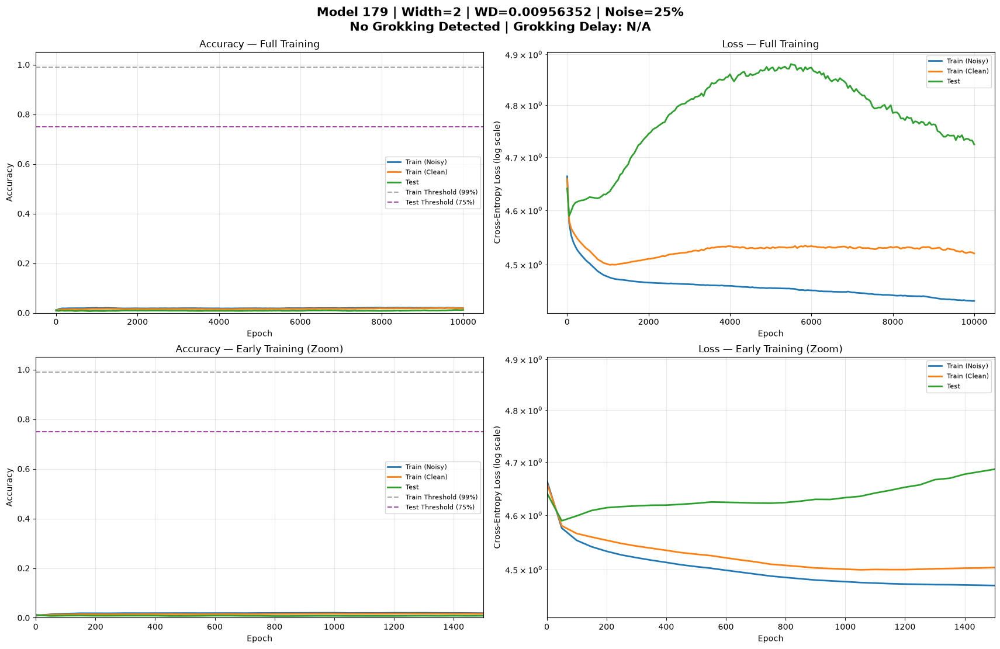

Training Models:  58%|█████▊    | 180/308 [02:58<02:04,  1.03model/s]

Model 180: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_180/learning_curves.png


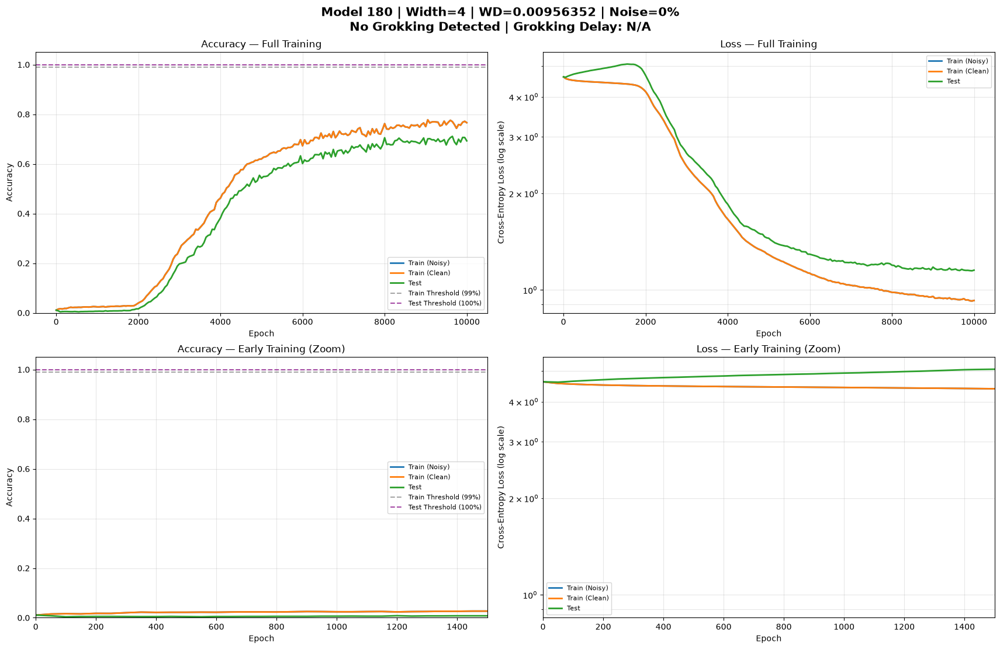

Training Models:  59%|█████▉    | 181/308 [02:59<02:01,  1.05model/s]

Model 181: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_181/learning_curves.png


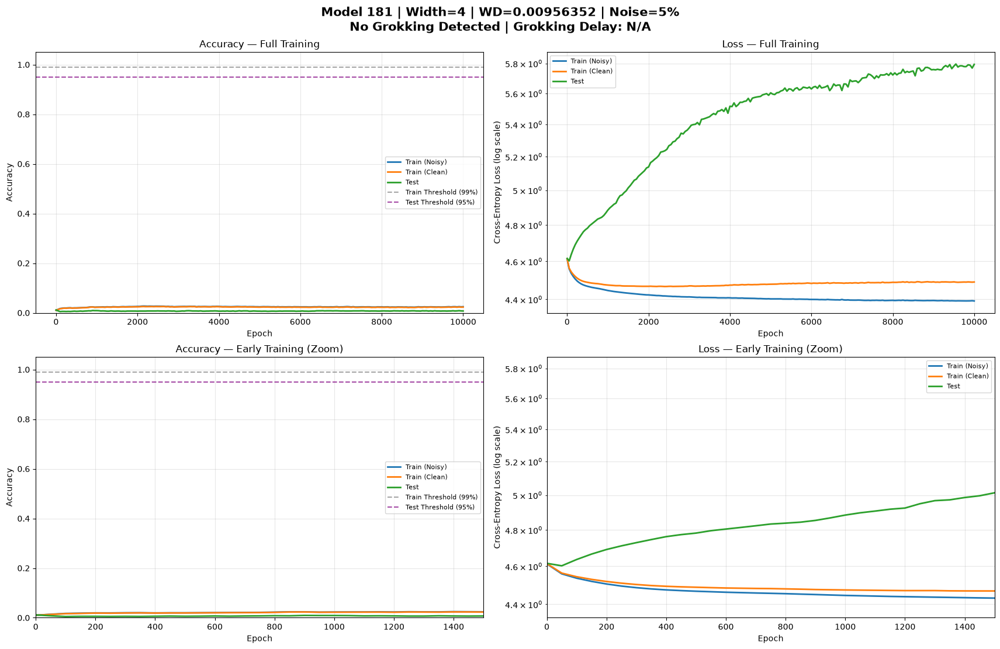

Training Models:  59%|█████▉    | 182/308 [03:00<02:01,  1.04model/s]

Model 182: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_182/learning_curves.png


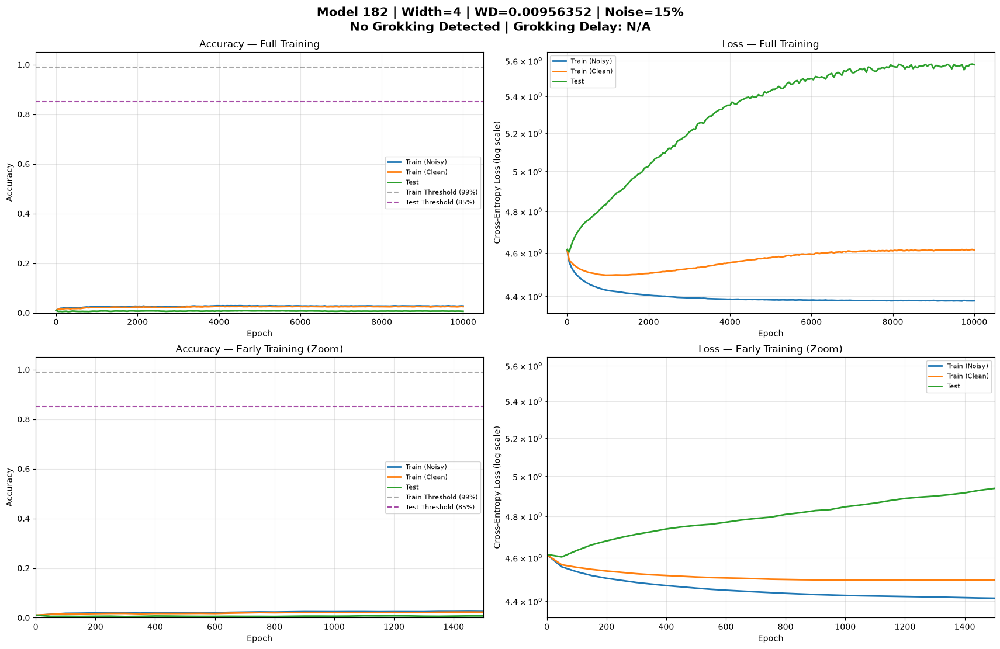

Training Models:  59%|█████▉    | 183/308 [03:01<01:59,  1.04model/s]

Model 183: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_183/learning_curves.png


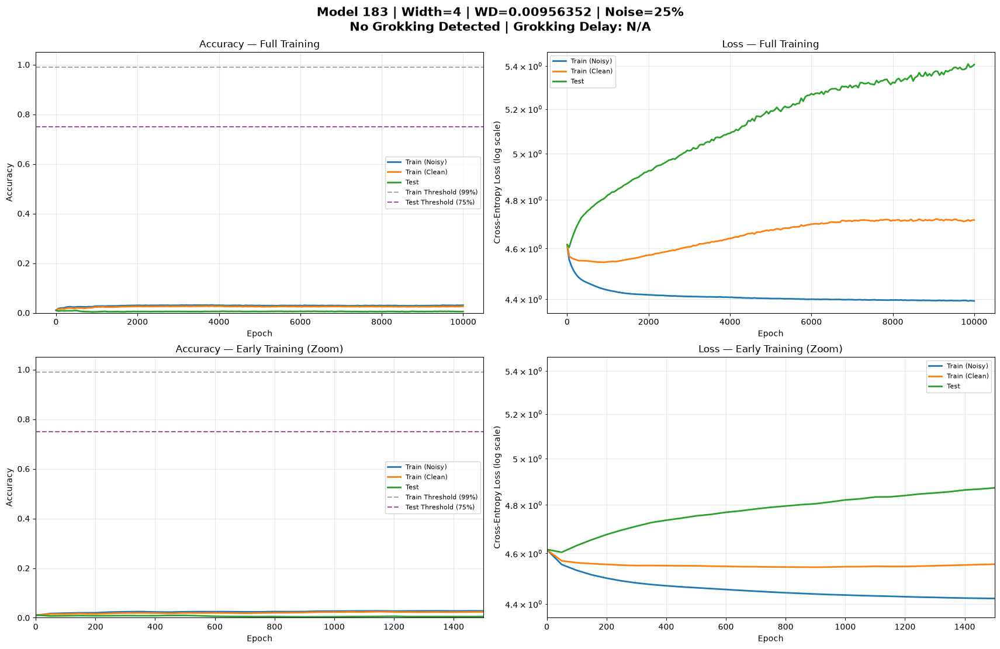

Training Models:  60%|█████▉    | 184/308 [03:02<02:02,  1.01model/s]

Model 184: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_184/learning_curves.png


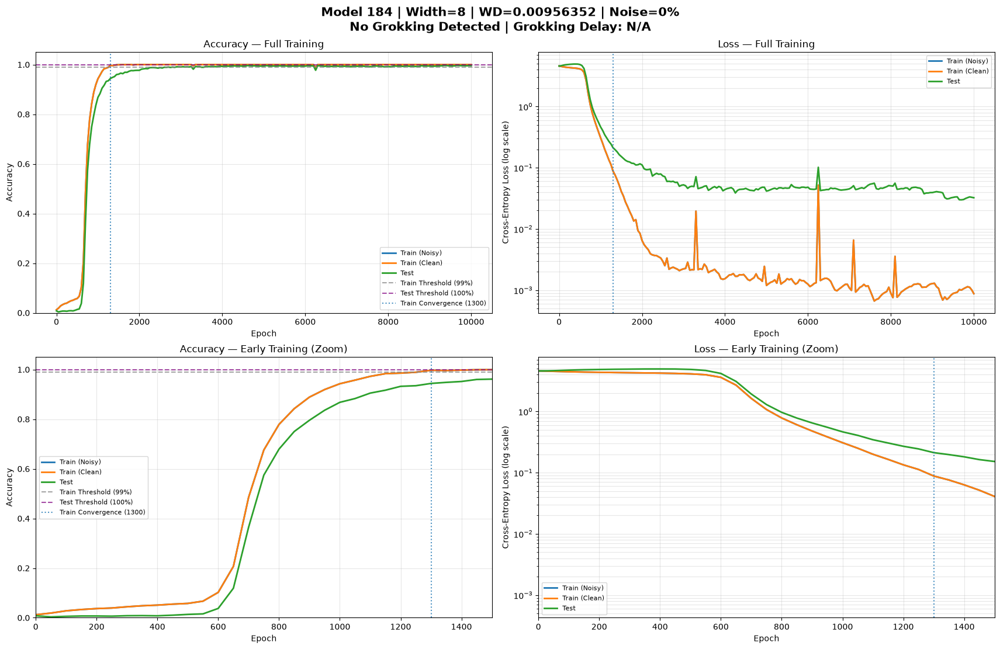

Training Models:  60%|██████    | 185/308 [03:03<02:06,  1.03s/model]

Model 185: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_185/learning_curves.png


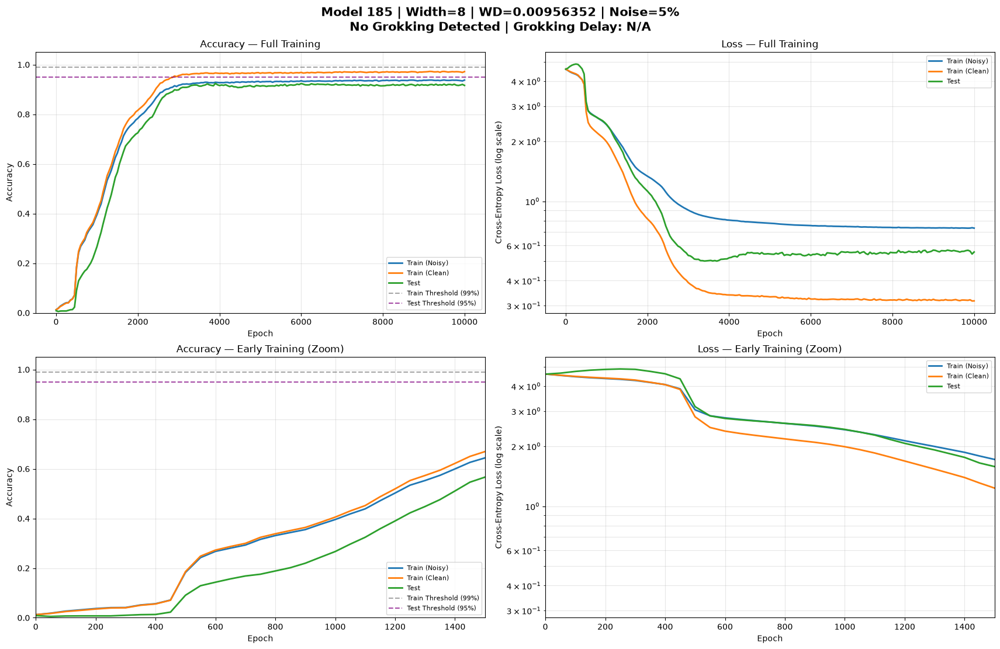

Training Models:  60%|██████    | 186/308 [03:04<02:04,  1.02s/model]

Model 186: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_186/learning_curves.png


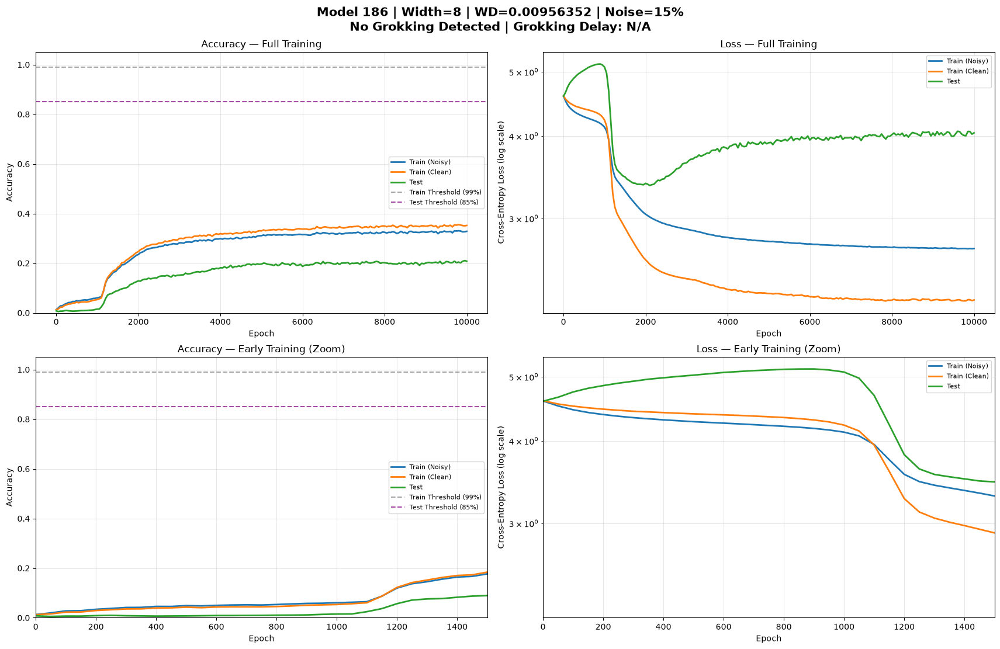

Training Models:  61%|██████    | 187/308 [03:05<01:56,  1.03model/s]

Model 187: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_187/learning_curves.png


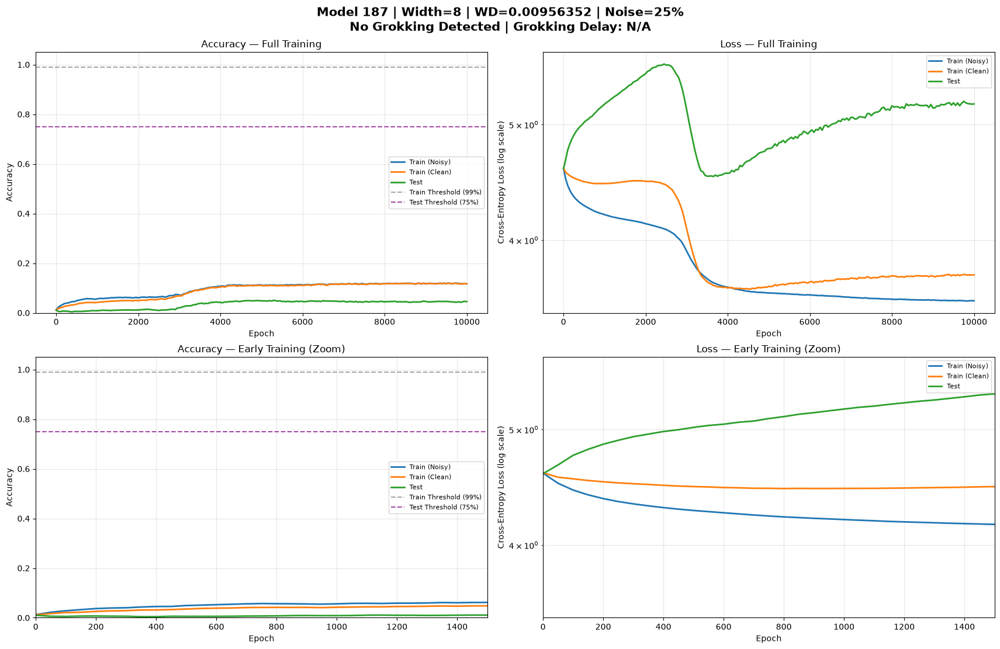

Training Models:  61%|██████    | 188/308 [03:06<01:55,  1.04model/s]

Model 188: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_188/learning_curves.png


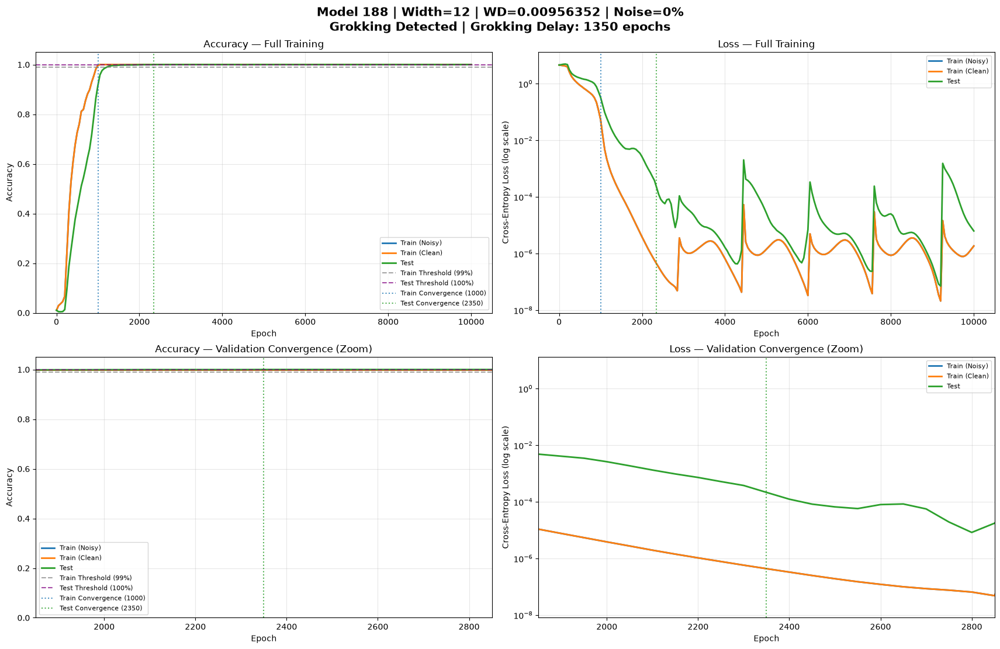

Training Models:  61%|██████▏   | 189/308 [03:07<01:52,  1.06model/s]

Model 189: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_189/learning_curves.png


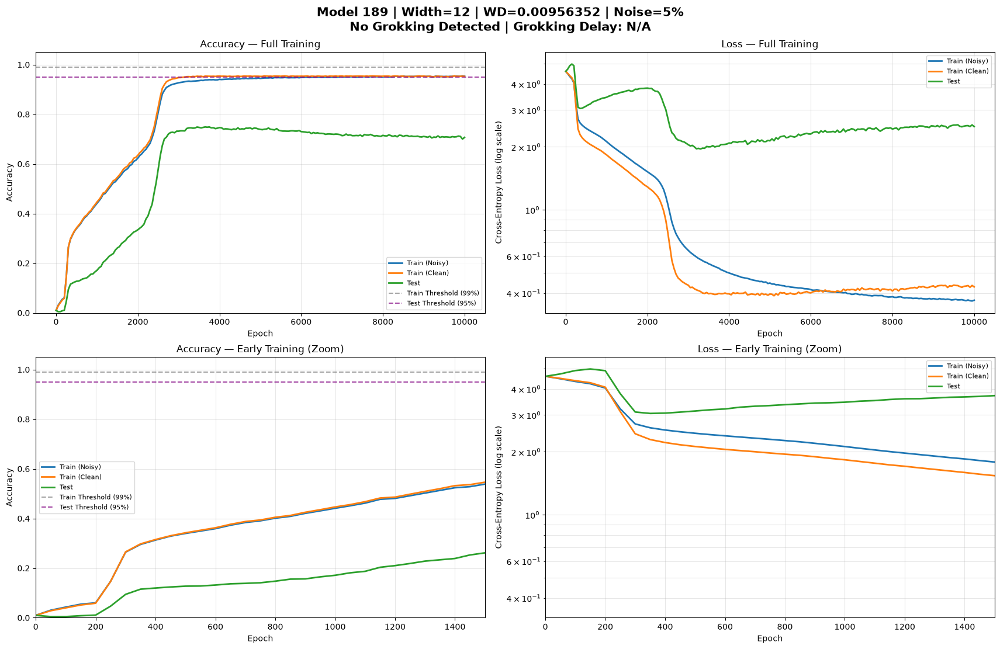

Training Models:  62%|██████▏   | 190/308 [03:08<01:52,  1.05model/s]

Model 190: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_190/learning_curves.png


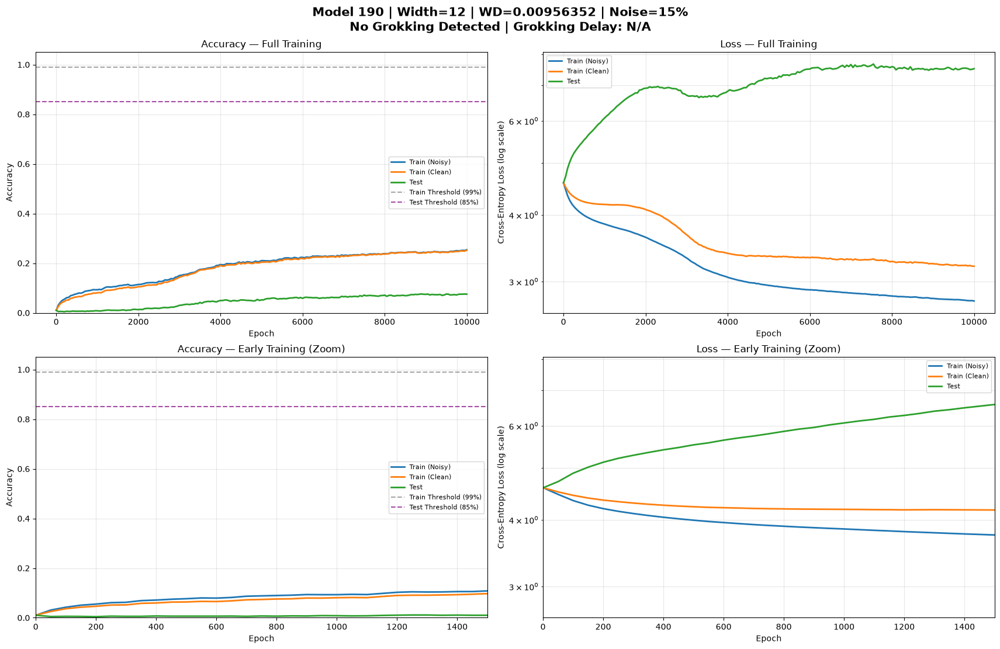

Training Models:  62%|██████▏   | 191/308 [03:09<01:49,  1.07model/s]

Model 191: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_191/learning_curves.png


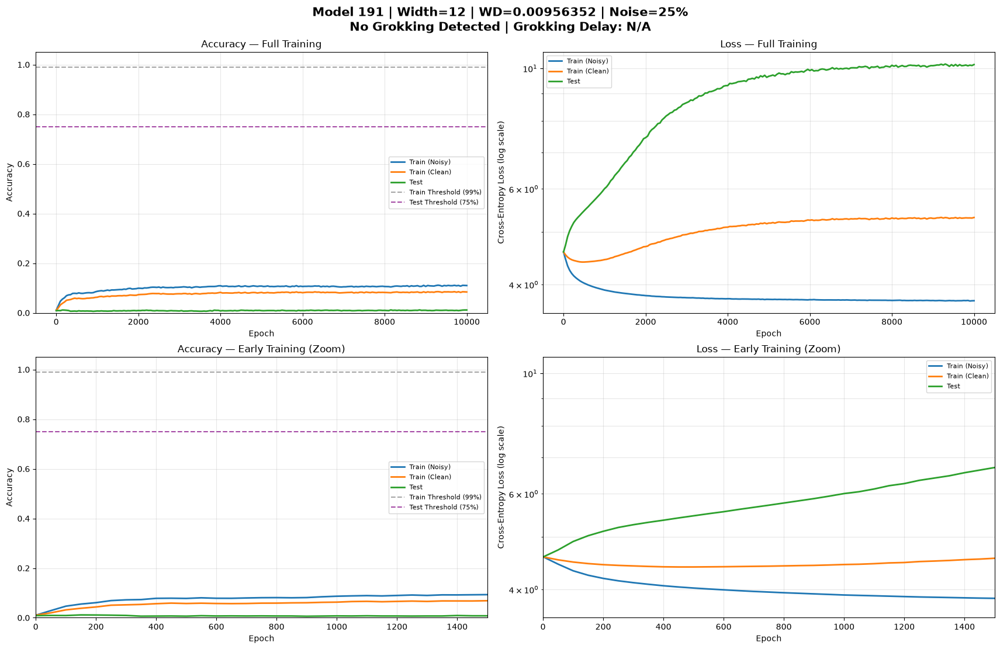

Training Models:  62%|██████▏   | 192/308 [03:10<01:46,  1.08model/s]

Model 192: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_192/learning_curves.png


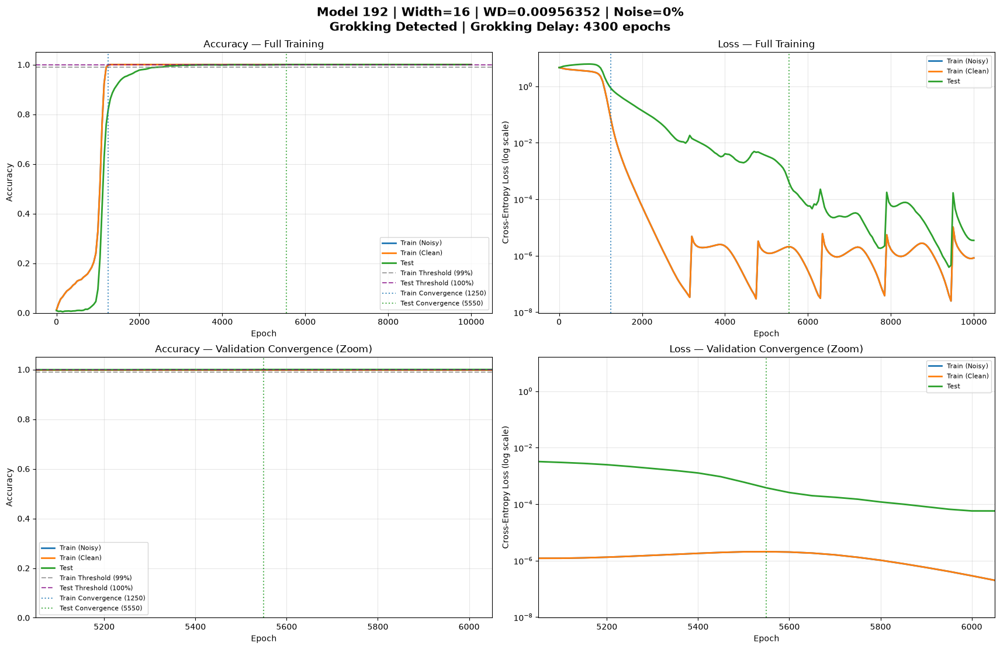

Training Models:  63%|██████▎   | 193/308 [03:11<01:49,  1.05model/s]

Model 193: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_193/learning_curves.png


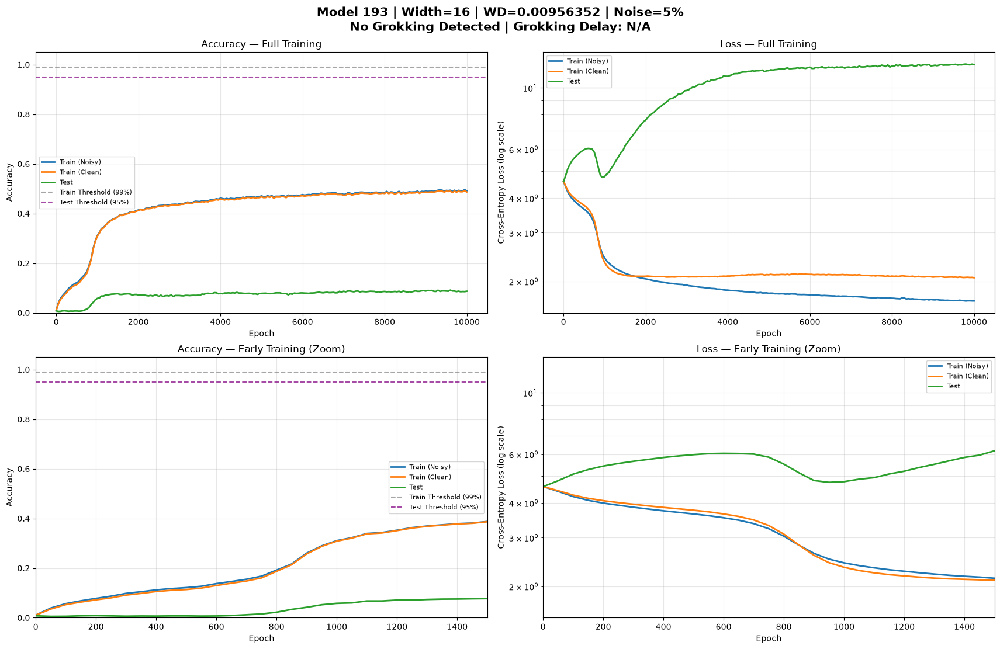

Training Models:  63%|██████▎   | 194/308 [03:12<01:48,  1.05model/s]

Model 194: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_194/learning_curves.png


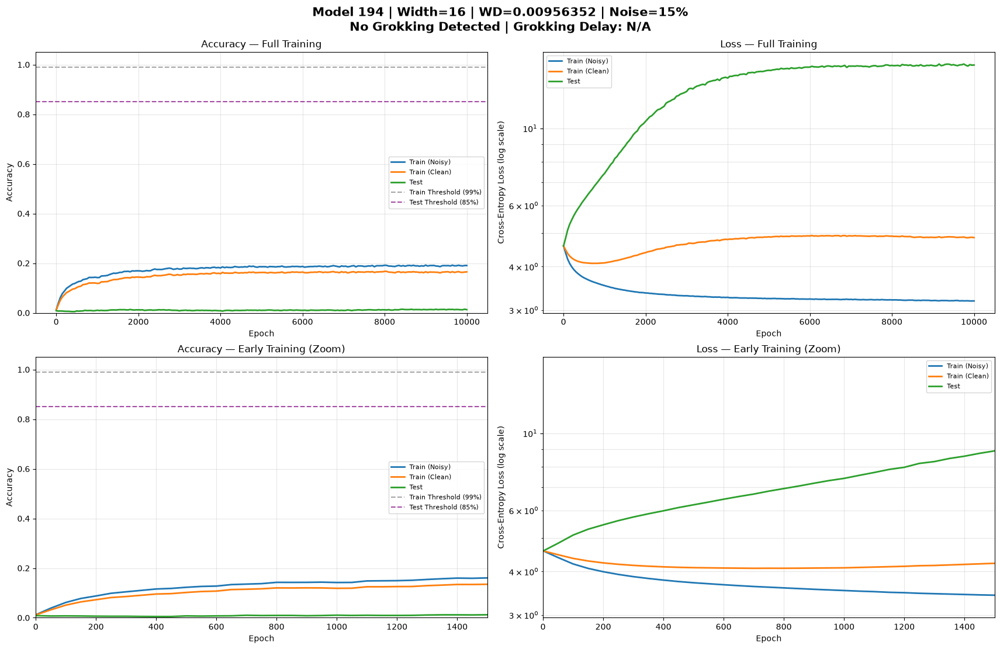

Training Models:  63%|██████▎   | 195/308 [03:13<01:47,  1.06model/s]

Model 195: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_195/learning_curves.png


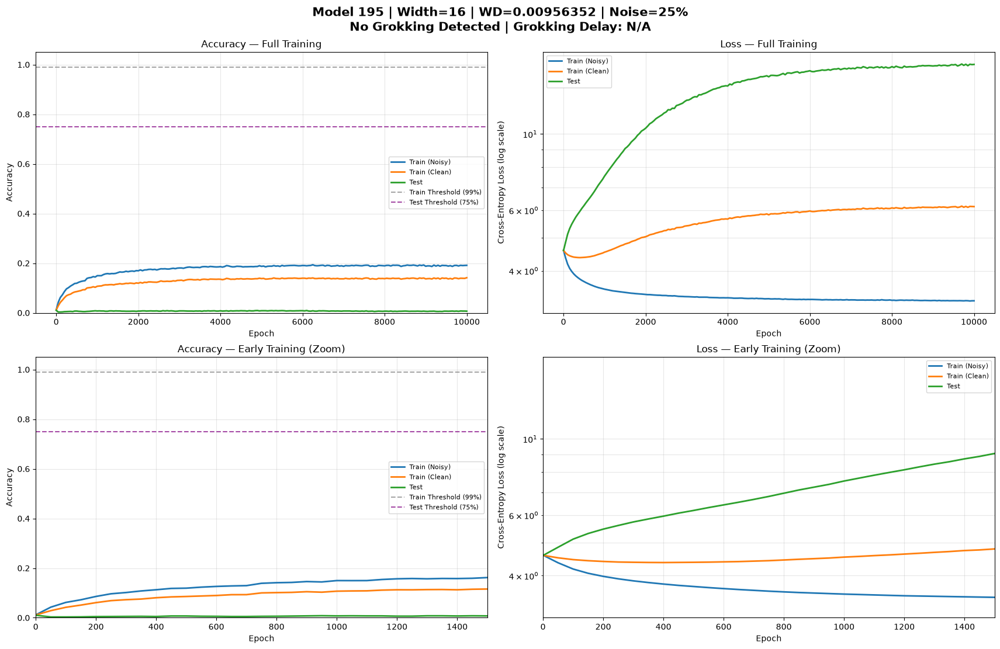

Training Models:  64%|██████▎   | 196/308 [03:13<01:44,  1.07model/s]

Model 196: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_196/learning_curves.png


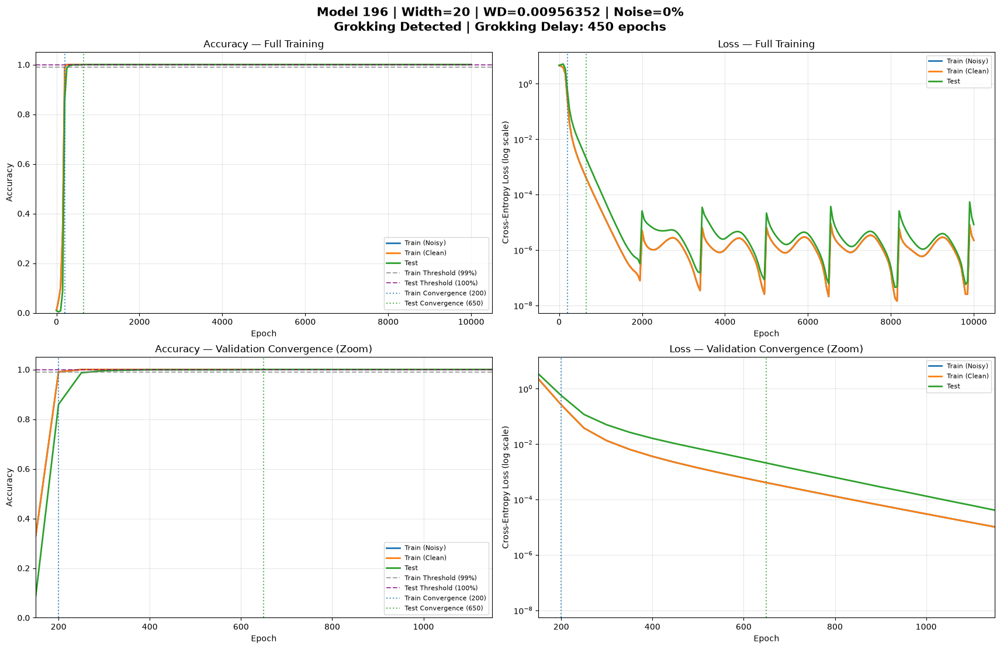

Training Models:  64%|██████▍   | 197/308 [03:14<01:42,  1.08model/s]

Model 197: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_197/learning_curves.png


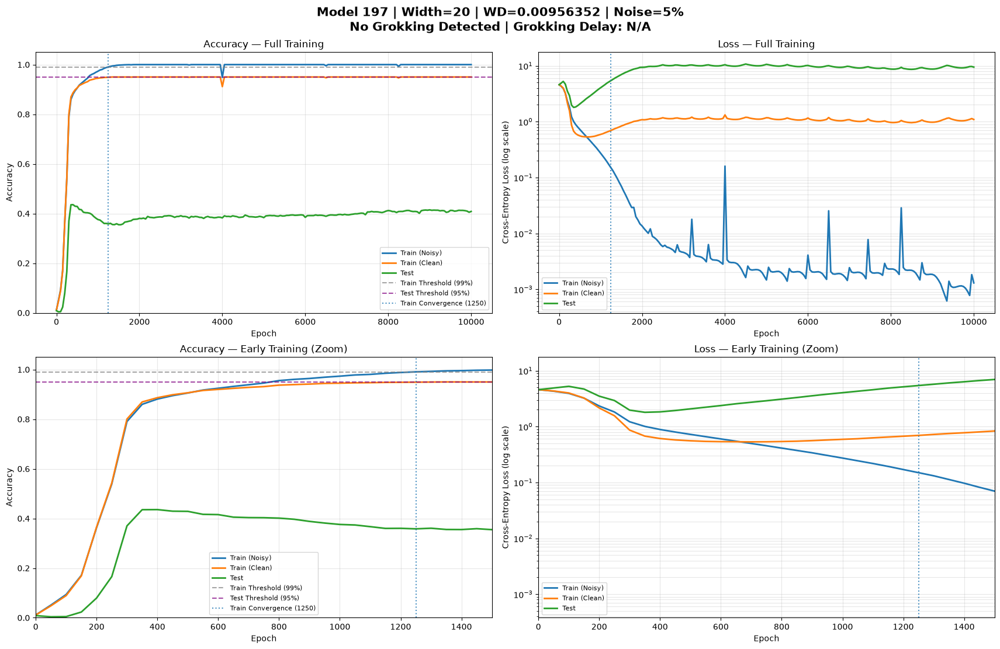

Training Models:  64%|██████▍   | 198/308 [03:16<01:54,  1.04s/model]

Model 198: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_198/learning_curves.png


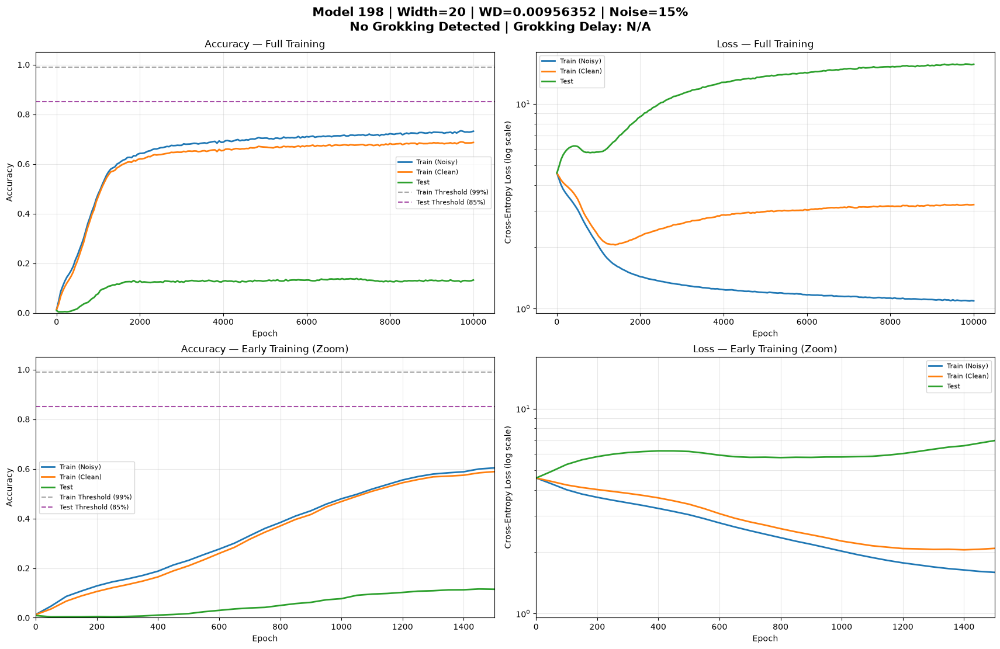

Training Models:  65%|██████▍   | 199/308 [03:17<01:48,  1.00model/s]

Model 199: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_199/learning_curves.png


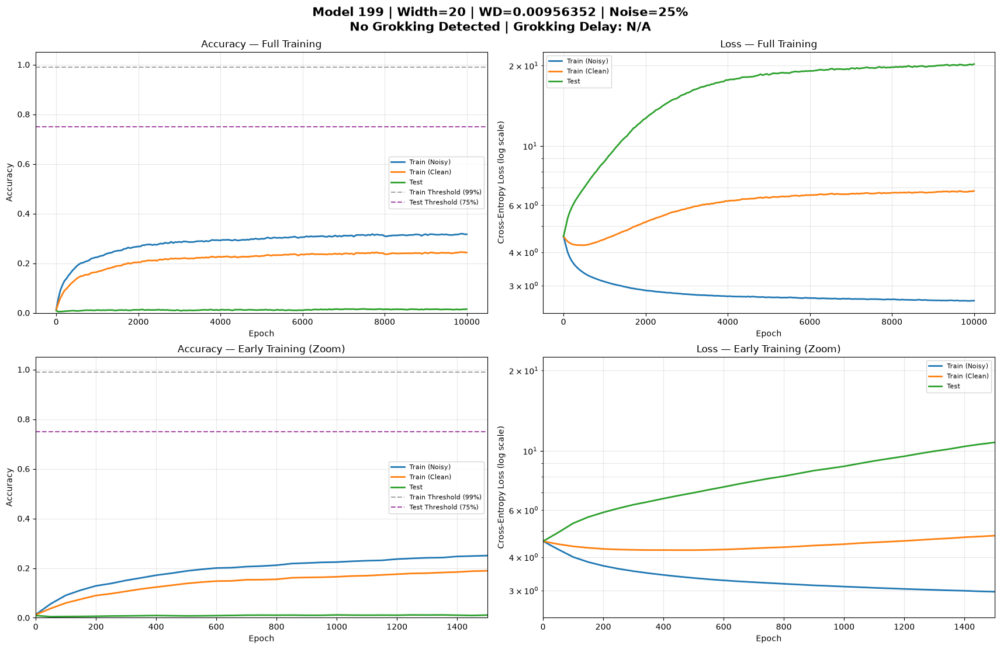

Training Models:  65%|██████▍   | 200/308 [03:17<01:45,  1.02model/s]

Model 200: Already completed. Skipping.
Saved plot: grokking_experiments/models/model_200/learning_curves.png


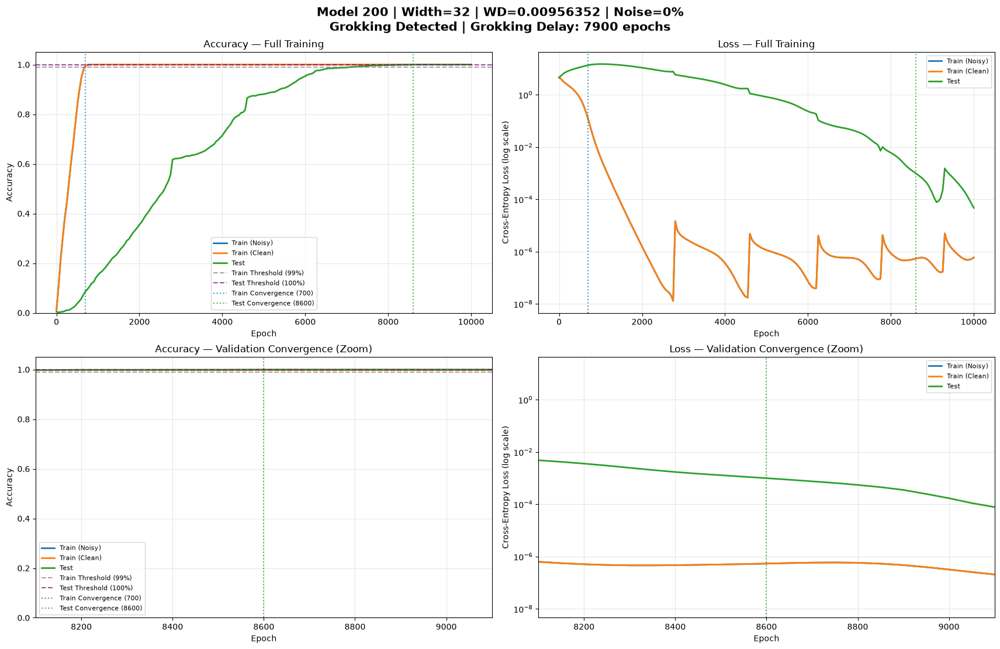

Training Models:  65%|██████▌   | 201/308 [03:18<01:42,  1.05model/s]

Model 201: Resuming from epoch 9001

Training Model 201 | Width=32 | WD=0.009563524997900363 | Noise=5%
Model 201 | Epoch  9500/10000 | Train: 1.0000 | Test: 0.1119
Model 201 | Epoch 10000/10000 | Train: 1.0000 | Test: 0.1204

Model 201 completed! | Grokked: False | Test accuracy: 0.1204
Saved plot: grokking_experiments/models/model_201/learning_curves.png


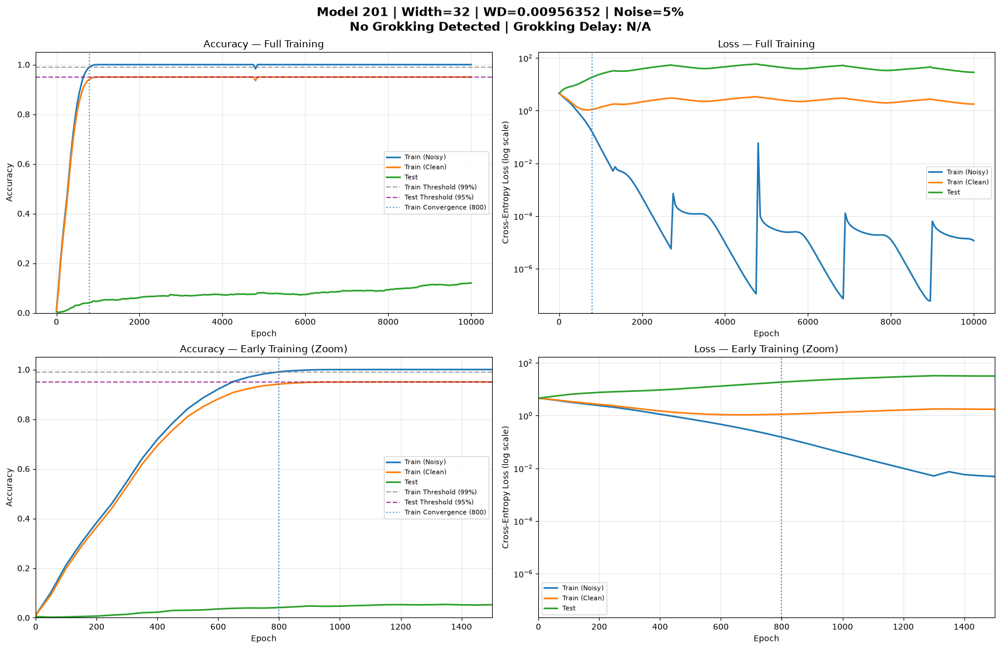

Training Models:  66%|██████▌   | 202/308 [03:33<08:44,  4.95s/model]


Training Model 202 | Width=32 | WD=0.009563524997900363 | Noise=15%
Model 202 | Epoch   500/10000 | Train: 0.5847 | Test: 0.0071
Model 202 | Epoch  1000/10000 | Train: 0.7672 | Test: 0.0089
Model 202 | Epoch  1500/10000 | Train: 0.8731 | Test: 0.0092
Model 202 | Epoch  2000/10000 | Train: 0.9282 | Test: 0.0106
Model 202 | Epoch  2500/10000 | Train: 0.9622 | Test: 0.0124
Model 202 | Epoch  3000/10000 | Train: 0.9759 | Test: 0.0131
Model 202 | Epoch  3500/10000 | Train: 0.9895 | Test: 0.0113
Model 202 | Epoch  4000/10000 | Train: 0.9950 | Test: 0.0124
Model 202 | Epoch  4500/10000 | Train: 0.9938 | Test: 0.0128
Model 202 | Epoch  5000/10000 | Train: 0.9142 | Test: 0.0138
Model 202 | Epoch  5500/10000 | Train: 0.9986 | Test: 0.0124
Model 202 | Epoch  6000/10000 | Train: 0.9991 | Test: 0.0135
Model 202 | Epoch  6500/10000 | Train: 0.9992 | Test: 0.0124
Model 202 | Epoch  7000/10000 | Train: 0.9995 | Test: 0.0131
Model 202 | Epoch  7500/10000 | Train: 0.9995 | Test: 0.0142
Model 202 | Epoc

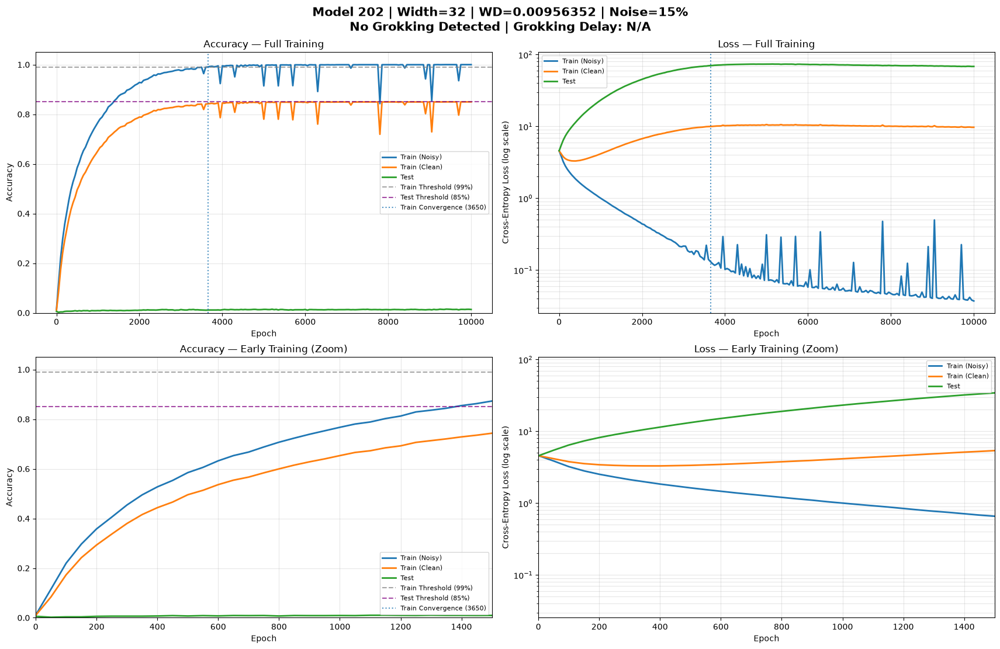

Training Models:  66%|██████▌   | 203/308 [05:04<54:03, 30.89s/model]


Training Model 203 | Width=32 | WD=0.009563524997900363 | Noise=25%
Model 203 | Epoch   500/10000 | Train: 0.5544 | Test: 0.0028
Model 203 | Epoch  1000/10000 | Train: 0.7288 | Test: 0.0064
Model 203 | Epoch  1500/10000 | Train: 0.8260 | Test: 0.0046
Model 203 | Epoch  2000/10000 | Train: 0.8854 | Test: 0.0046
Model 203 | Epoch  2500/10000 | Train: 0.9279 | Test: 0.0060
Model 203 | Epoch  3000/10000 | Train: 0.9546 | Test: 0.0053
Model 203 | Epoch  3500/10000 | Train: 0.9745 | Test: 0.0050
Model 203 | Epoch  4000/10000 | Train: 0.9875 | Test: 0.0046
Model 203 | Epoch  4500/10000 | Train: 0.9898 | Test: 0.0057
Model 203 | Epoch  5000/10000 | Train: 0.9948 | Test: 0.0057
Model 203 | Epoch  5500/10000 | Train: 0.9971 | Test: 0.0053
Model 203 | Epoch  6000/10000 | Train: 0.9965 | Test: 0.0064
Model 203 | Epoch  6500/10000 | Train: 0.9968 | Test: 0.0060
Model 203 | Epoch  7000/10000 | Train: 0.9991 | Test: 0.0060
Model 203 | Epoch  7500/10000 | Train: 0.9991 | Test: 0.0064
Model 203 | Epoc

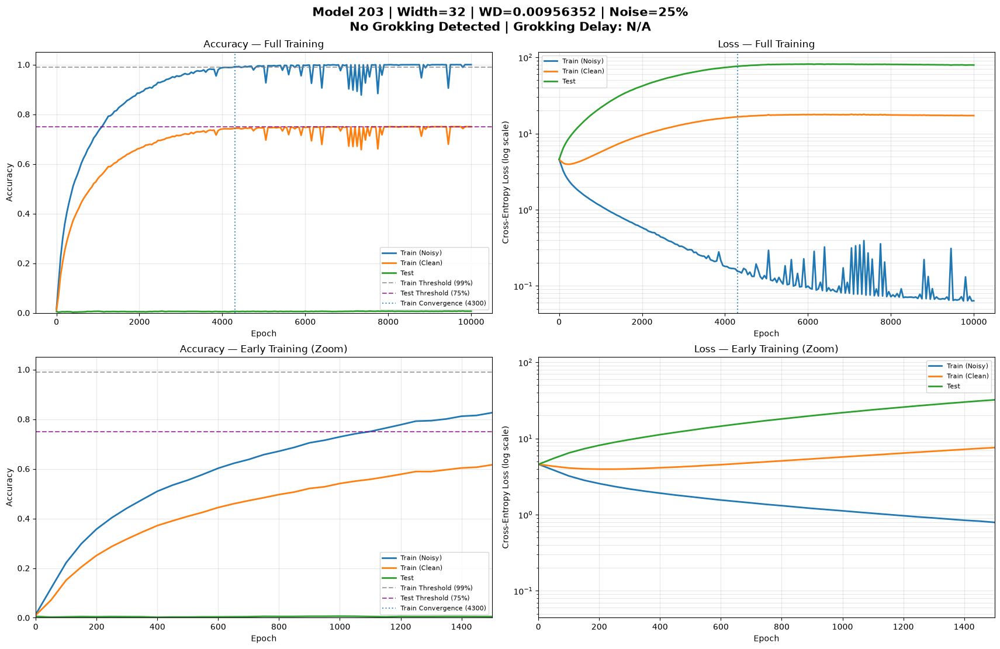

Training Models:  66%|██████▌   | 204/308 [06:36<1:25:24, 49.27s/model]


Training Model 204 | Width=64 | WD=0.009563524997900363 | Noise=0%
Model 204 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0259
Model 204 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0400
Model 204 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0620
Model 204 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.1130
Model 204 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.1211
Model 204 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.1541
Model 204 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.2097
Model 204 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.2922
Model 204 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.3298
Model 204 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.4527
Model 204 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.6054
Model 204 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.6458
Model 204 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.7655
Model 204 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.8902
Model 204 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9295
Model 204 | Epoch

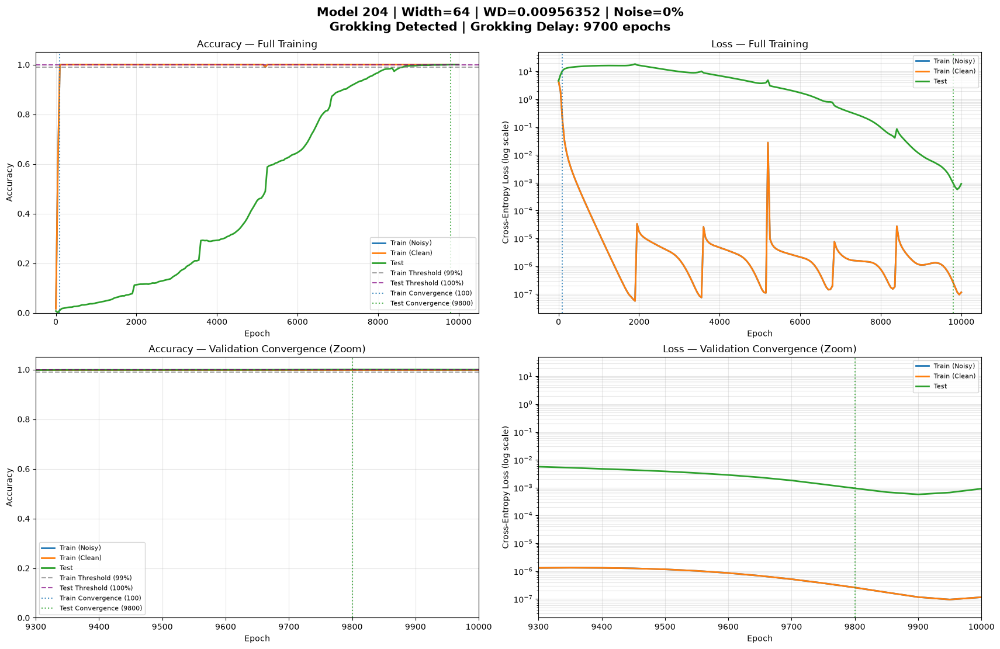

Training Models:  67%|██████▋   | 205/308 [08:08<1:46:38, 62.13s/model]


Training Model 205 | Width=64 | WD=0.009563524997900363 | Noise=5%
Model 205 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0064
Model 205 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0096
Model 205 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0131
Model 205 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0156
Model 205 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0174
Model 205 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.0177
Model 205 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.0188
Model 205 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.0259
Model 205 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.0252
Model 205 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.0344
Model 205 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.0461
Model 205 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.0439
Model 205 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.0457
Model 205 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.0556
Model 205 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.0740
Model 205 | Epoch

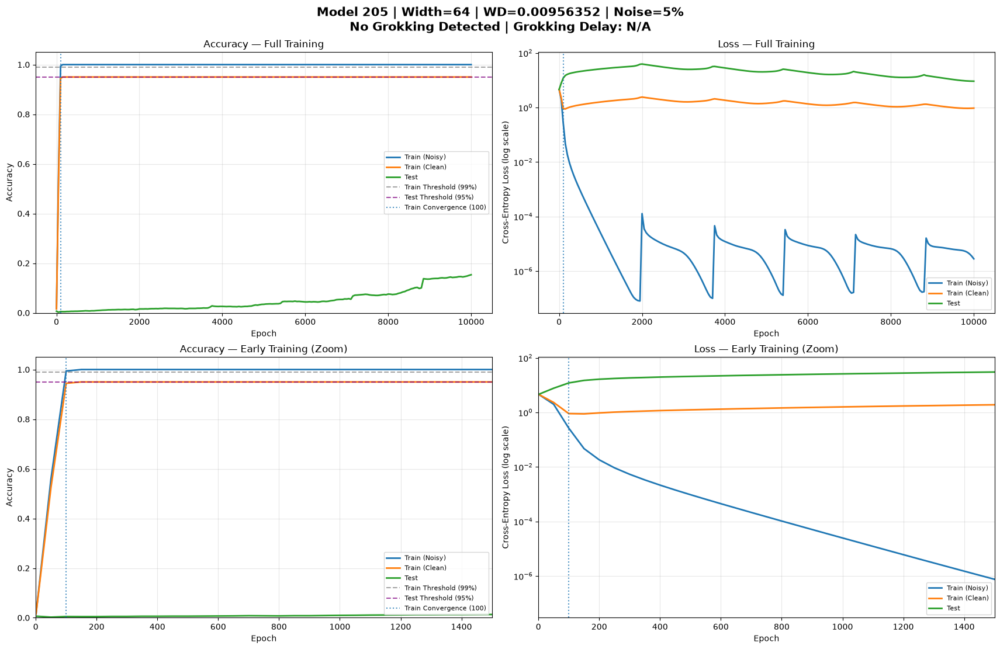

Training Models:  67%|██████▋   | 206/308 [09:41<2:00:57, 71.16s/model]


Training Model 206 | Width=64 | WD=0.009563524997900363 | Noise=15%
Model 206 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0028
Model 206 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0035
Model 206 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0039
Model 206 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0028
Model 206 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0028
Model 206 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.0039
Model 206 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.0039
Model 206 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.0039
Model 206 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.0043
Model 206 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.0046
Model 206 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.0046
Model 206 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.0071
Model 206 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.0046
Model 206 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.0060
Model 206 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.0064
Model 206 | Epoc

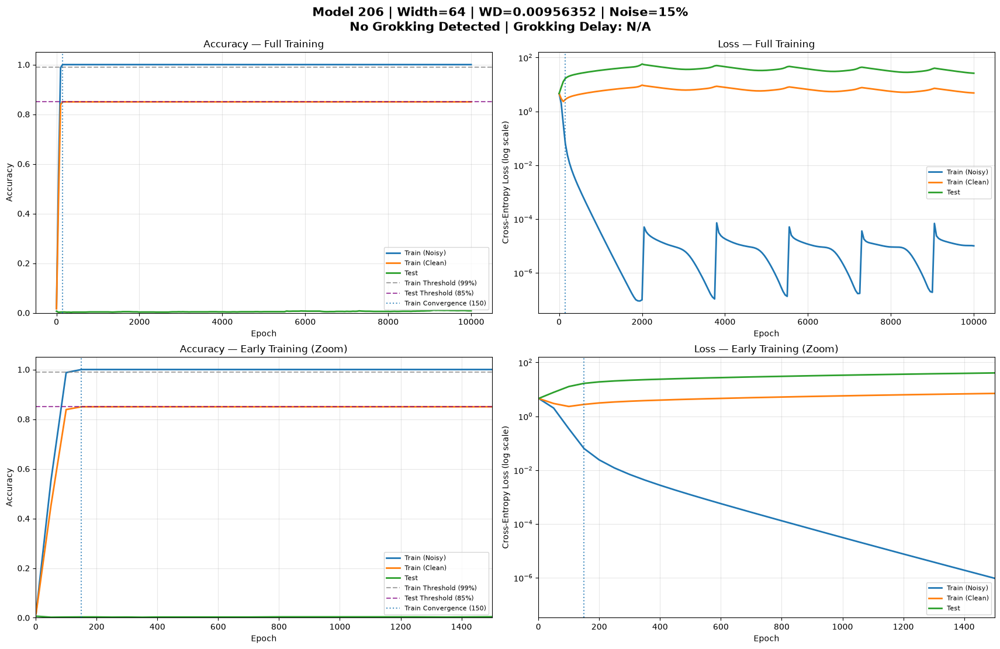

Training Models:  67%|██████▋   | 207/308 [11:13<2:10:17, 77.40s/model]


Training Model 207 | Width=64 | WD=0.009563524997900363 | Noise=25%
Model 207 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0014
Model 207 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0018
Model 207 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0021
Model 207 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0014
Model 207 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0014
Model 207 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.0018
Model 207 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.0018
Model 207 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.0028
Model 207 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.0025
Model 207 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.0028
Model 207 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.0032
Model 207 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.0039
Model 207 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.0032
Model 207 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.0035
Model 207 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.0028
Model 207 | Epoc

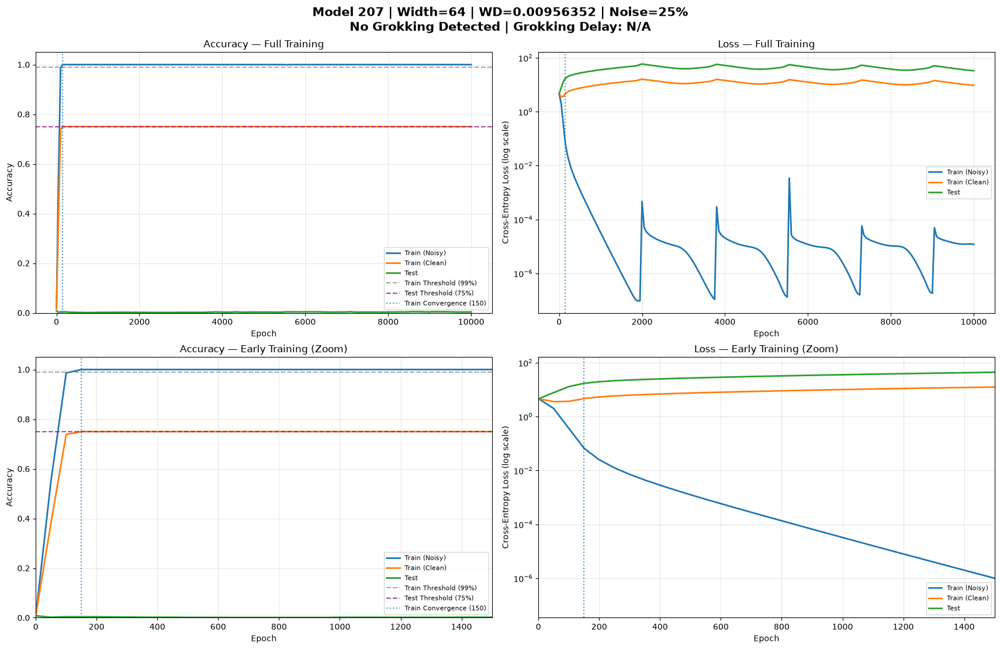

Training Models:  68%|██████▊   | 208/308 [12:45<2:16:17, 81.78s/model]


Training Model 208 | Width=128 | WD=0.009563524997900363 | Noise=0%
Model 208 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0018
Model 208 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0039
Model 208 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0096
Model 208 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0322
Model 208 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0365
Model 208 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.0634
Model 208 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.1470
Model 208 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.1707
Model 208 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.2774
Model 208 | Epoch  5000/10000 | Train: 0.7978 | Test: 0.2426
Model 208 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.6029
Model 208 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.7549
Model 208 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9086
Model 208 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9447
Model 208 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9812
Model 208 | Epoc

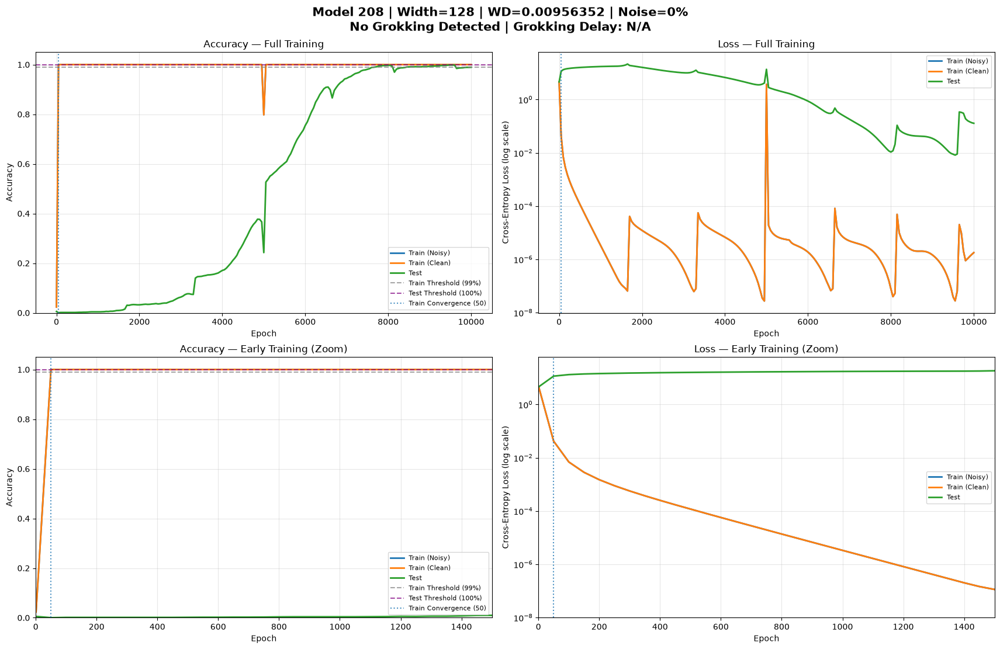

Training Models:  68%|██████▊   | 209/308 [14:20<2:21:31, 85.77s/model]


Training Model 209 | Width=128 | WD=0.009563524997900363 | Noise=5%
Model 209 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0018
Model 209 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0025
Model 209 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0057
Model 209 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0255
Model 209 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0248
Model 209 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.0347
Model 209 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.0900
Model 209 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.1031
Model 209 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.1367
Model 209 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.1725
Model 209 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.3248
Model 209 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.3812
Model 209 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.5133
Model 209 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.6738
Model 209 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.7102
Model 209 | Epoc

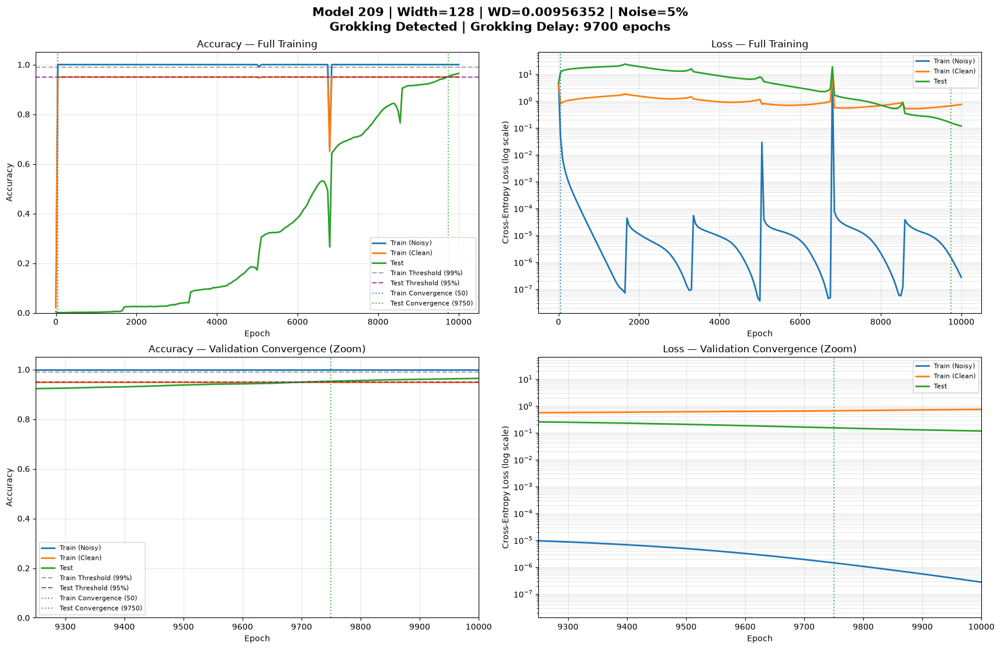

Training Models:  68%|██████▊   | 210/308 [15:56<2:25:09, 88.87s/model]


Training Model 210 | Width=128 | WD=0.009563524997900363 | Noise=15%
Model 210 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0021
Model 210 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0025
Model 210 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0035
Model 210 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0021
Model 210 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0021
Model 210 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.0050
Model 210 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.0053
Model 210 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.0071
Model 210 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.0071
Model 210 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.0149
Model 210 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.0209
Model 210 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.0209
Model 210 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.0333
Model 210 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.0560
Model 210 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.0595
Model 210 | Epo

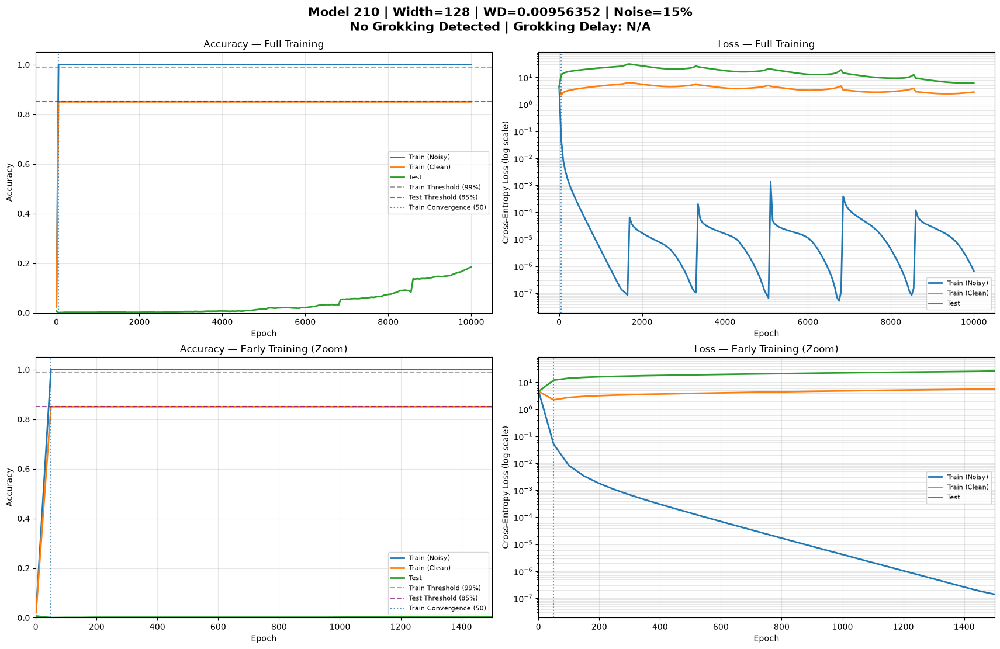

Training Models:  69%|██████▊   | 211/308 [17:32<2:27:21, 91.15s/model]


Training Model 211 | Width=128 | WD=0.009563524997900363 | Noise=25%
Model 211 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0021
Model 211 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0021
Model 211 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0025
Model 211 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0035
Model 211 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0039
Model 211 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.0035
Model 211 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.0039
Model 211 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.0039
Model 211 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.0025
Model 211 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.0046
Model 211 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.0043
Model 211 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.0039
Model 211 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.0067
Model 211 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.0092
Model 211 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.0074
Model 211 | Epo

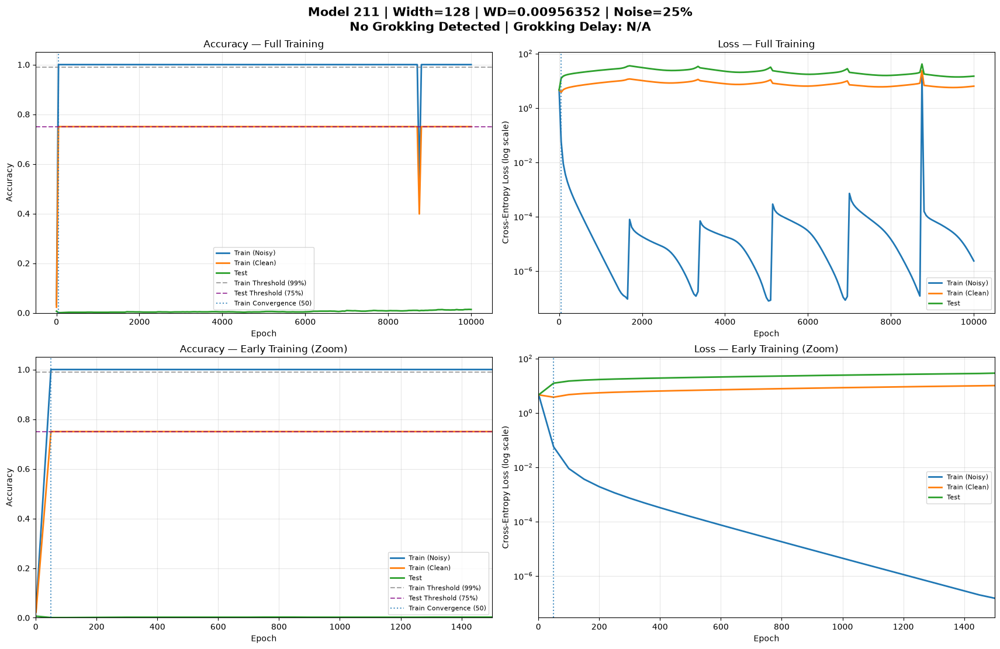

Training Models:  69%|██████▉   | 212/308 [19:08<2:27:52, 92.42s/model]


Training Model 212 | Width=256 | WD=0.009563524997900363 | Noise=0%
Model 212 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0103
Model 212 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0361
Model 212 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.6847
Model 212 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.8452
Model 212 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.9306
Model 212 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.9469
Model 212 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.9660
Model 212 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9763
Model 212 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9897
Model 212 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9933
Model 212 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9986
Model 212 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9968
Model 212 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9996
Model 212 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9996
Model 212 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9982
Model 212 | Epoc

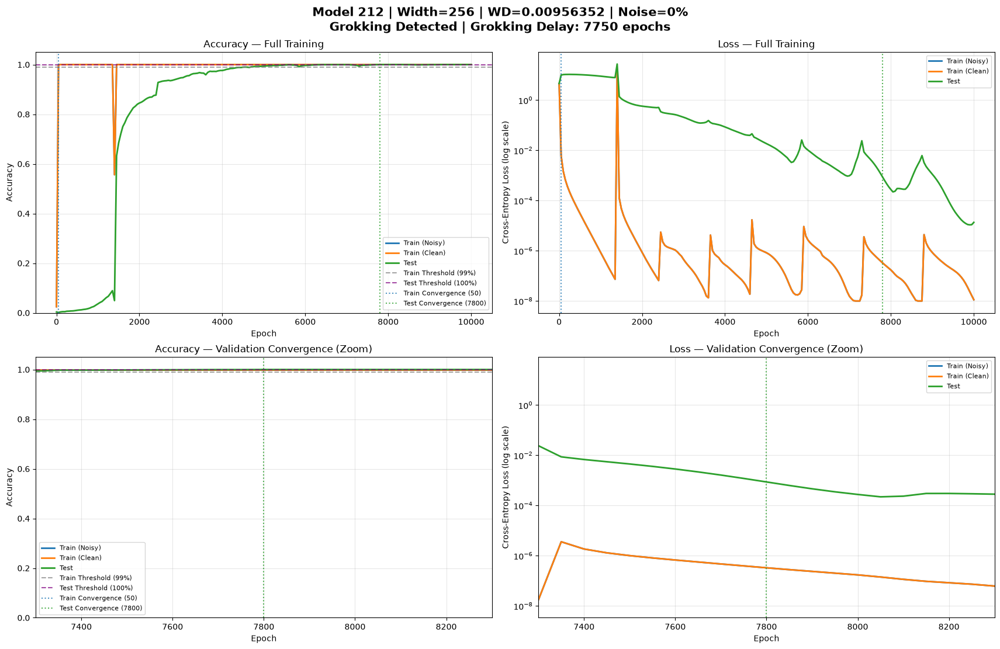

Training Models:  69%|██████▉   | 213/308 [20:42<2:27:19, 93.05s/model]


Training Model 213 | Width=256 | WD=0.009563524997900363 | Noise=5%
Model 213 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0011
Model 213 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0053
Model 213 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.3440
Model 213 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.4949
Model 213 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.5484
Model 213 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.7035
Model 213 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.7662
Model 213 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.5721
Model 213 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.8427
Model 213 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9029
Model 213 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.8495
Model 213 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9047
Model 213 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9440
Model 213 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9242
Model 213 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9678
Model 213 | Epoc

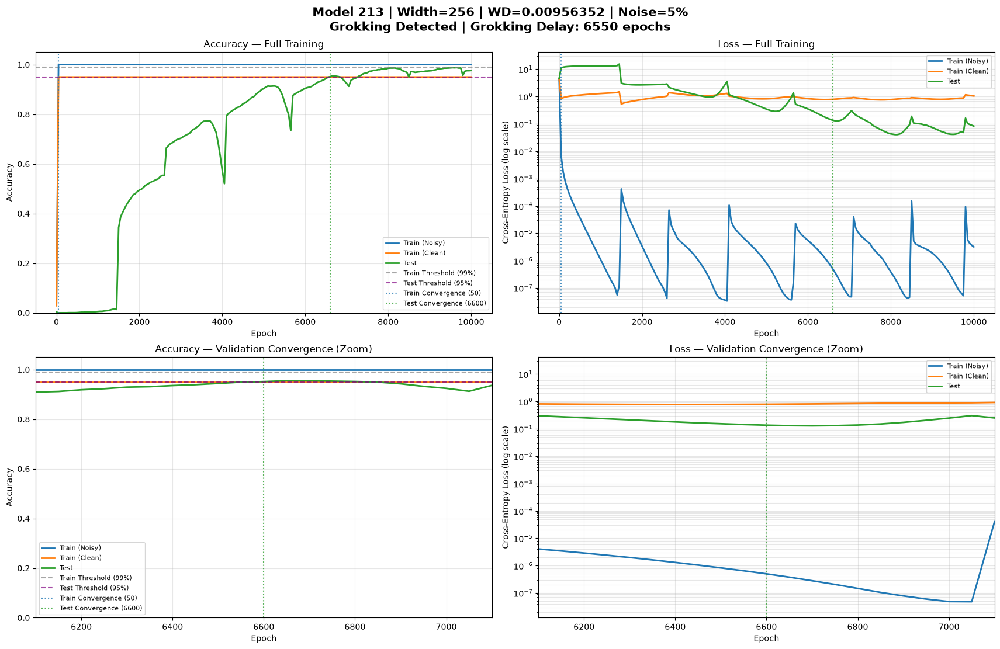

Training Models:  69%|██████▉   | 214/308 [22:18<2:27:02, 93.85s/model]


Training Model 214 | Width=256 | WD=0.009563524997900363 | Noise=15%
Model 214 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0011
Model 214 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0032
Model 214 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0195
Model 214 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0255
Model 214 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0450
Model 214 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.1002
Model 214 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.1201
Model 214 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.1236
Model 214 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.2512
Model 214 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.2752
Model 214 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.2285
Model 214 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.4538
Model 214 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.4637
Model 214 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.4123
Model 214 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.5303
Model 214 | Epo

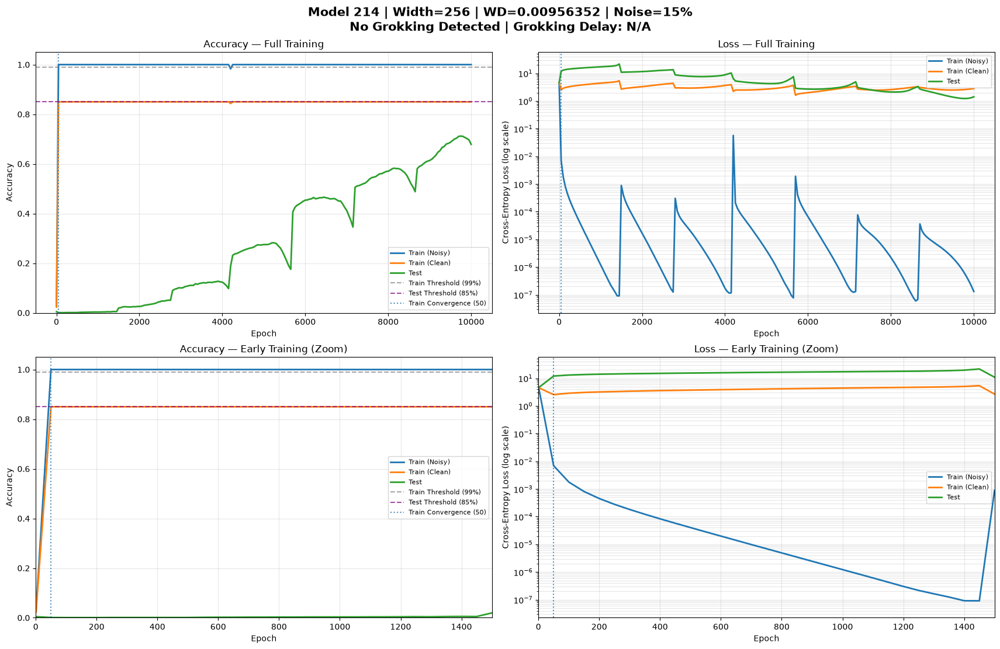

Training Models:  70%|██████▉   | 215/308 [23:53<2:26:14, 94.35s/model]


Training Model 215 | Width=256 | WD=0.009563524997900363 | Noise=25%
Model 215 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0014
Model 215 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0011
Model 215 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0050
Model 215 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0064
Model 215 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0074
Model 215 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.0120
Model 215 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.0145
Model 215 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.0142
Model 215 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.0556
Model 215 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.0553
Model 215 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.0560
Model 215 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.0776
Model 215 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.0886
Model 215 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.0857
Model 215 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.1651
Model 215 | Epo

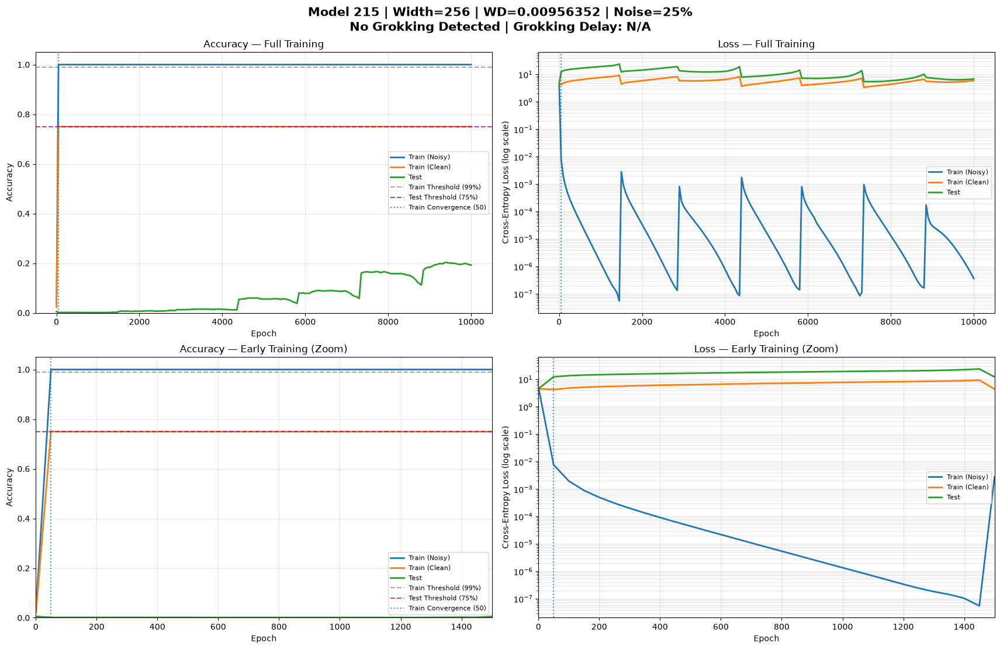

Training Models:  70%|███████   | 216/308 [25:29<2:25:13, 94.71s/model]


Training Model 216 | Width=512 | WD=0.009563524997900363 | Noise=0%
Model 216 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0159
Model 216 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0832
Model 216 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.9911
Model 216 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.9734
Model 216 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.9784
Model 216 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.9880
Model 216 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.9862
Model 216 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9837
Model 216 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9901
Model 216 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9667
Model 216 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9724
Model 216 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9816
Model 216 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9809
Model 216 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9965
Model 216 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9982
Model 216 | Epoc

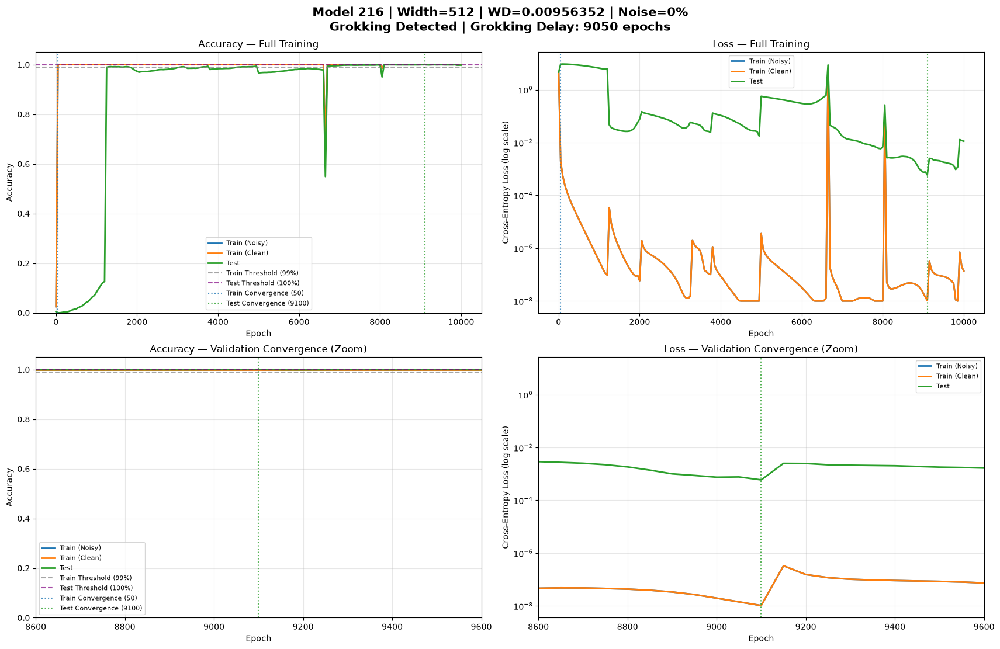

Training Models:  70%|███████   | 217/308 [28:18<2:57:42, 117.17s/model]


Training Model 217 | Width=512 | WD=0.009563524997900363 | Noise=5%
Model 217 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0078
Model 217 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0372
Model 217 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.8856
Model 217 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.8693
Model 217 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.8810
Model 217 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.9136
Model 217 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.9065
Model 217 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9104
Model 217 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9323
Model 217 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9440
Model 217 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9642
Model 217 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9532
Model 217 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9656
Model 217 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.8930
Model 217 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9178
Model 217 | Epoc

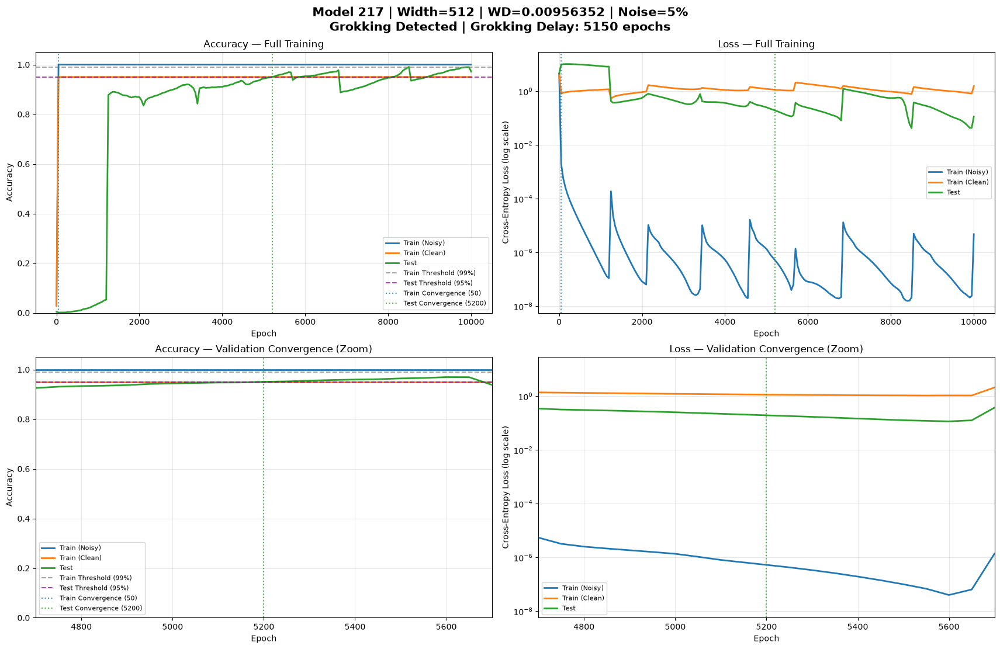

Training Models:  71%|███████   | 218/308 [31:08<3:19:12, 132.80s/model]


Training Model 218 | Width=512 | WD=0.009563524997900363 | Noise=15%
Model 218 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0028
Model 218 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0046
Model 218 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.4803
Model 218 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.4878
Model 218 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.4155
Model 218 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.5554
Model 218 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.5427
Model 218 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.5604
Model 218 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.6196
Model 218 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.6178
Model 218 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.6086
Model 218 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.6334
Model 218 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.5707
Model 218 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.6266
Model 218 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.7354
Model 218 | Epo

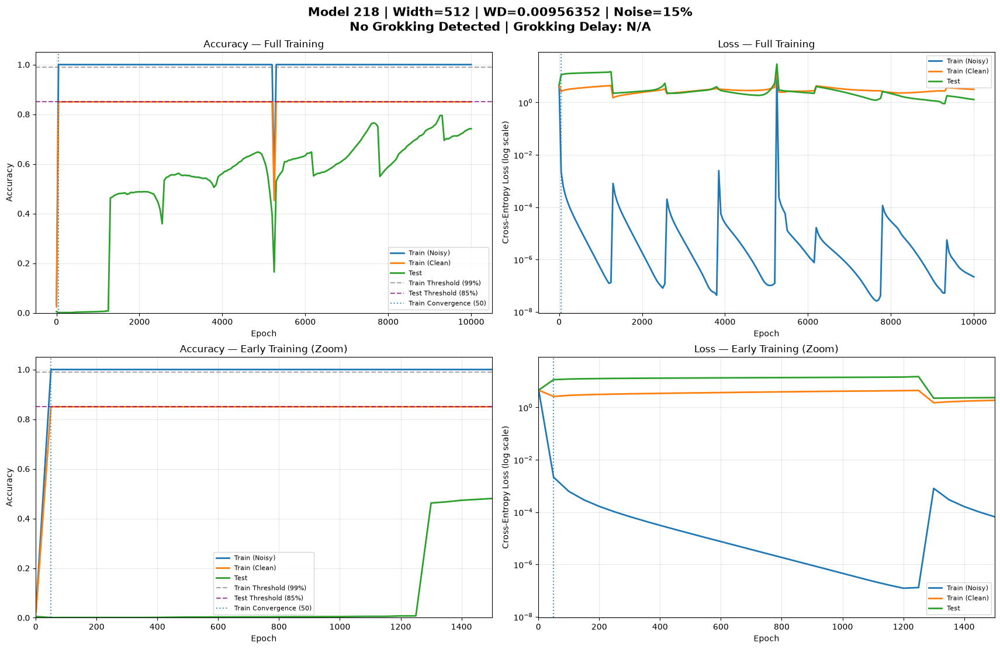

Training Models:  71%|███████   | 219/308 [33:57<3:33:14, 143.75s/model]


Training Model 219 | Width=512 | WD=0.009563524997900363 | Noise=25%
Model 219 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0007
Model 219 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0021
Model 219 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0280
Model 219 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0283
Model 219 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0588
Model 219 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.0563
Model 219 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.0609
Model 219 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.0974
Model 219 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.1077
Model 219 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.0379
Model 219 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.0577
Model 219 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.0538
Model 219 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.0627
Model 219 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.0832
Model 219 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.1031
Model 219 | Epo

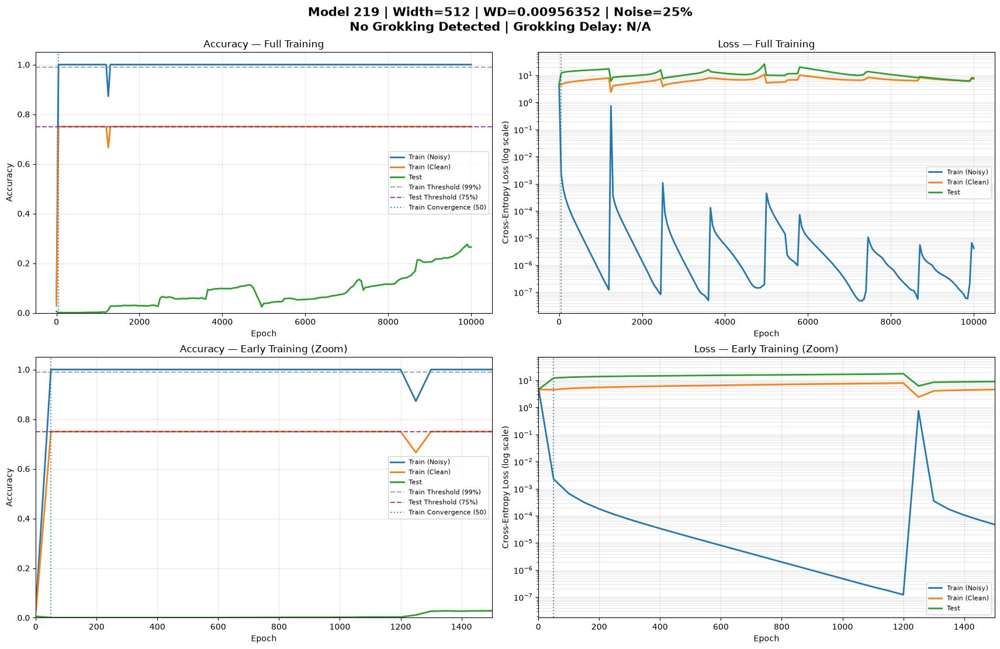

Training Models:  71%|███████▏  | 220/308 [36:46<3:42:01, 151.38s/model]


Training Model 220 | Width=2 | WD=0.04373448295773111 | Noise=0%
Model 220 | Epoch   500/10000 | Train: 0.0503 | Test: 0.0347
Model 220 | Epoch  1000/10000 | Train: 0.0654 | Test: 0.0436
Model 220 | Epoch  1500/10000 | Train: 0.0686 | Test: 0.0510
Model 220 | Epoch  2000/10000 | Train: 0.0691 | Test: 0.0499
Model 220 | Epoch  2500/10000 | Train: 0.0729 | Test: 0.0496
Model 220 | Epoch  3000/10000 | Train: 0.0698 | Test: 0.0478
Model 220 | Epoch  3500/10000 | Train: 0.0724 | Test: 0.0475
Model 220 | Epoch  4000/10000 | Train: 0.0744 | Test: 0.0499
Model 220 | Epoch  4500/10000 | Train: 0.0750 | Test: 0.0503
Model 220 | Epoch  5000/10000 | Train: 0.0744 | Test: 0.0507
Model 220 | Epoch  5500/10000 | Train: 0.0762 | Test: 0.0503
Model 220 | Epoch  6000/10000 | Train: 0.0762 | Test: 0.0510
Model 220 | Epoch  6500/10000 | Train: 0.0746 | Test: 0.0507
Model 220 | Epoch  7000/10000 | Train: 0.0753 | Test: 0.0507
Model 220 | Epoch  7500/10000 | Train: 0.0742 | Test: 0.0507
Model 220 | Epoch  

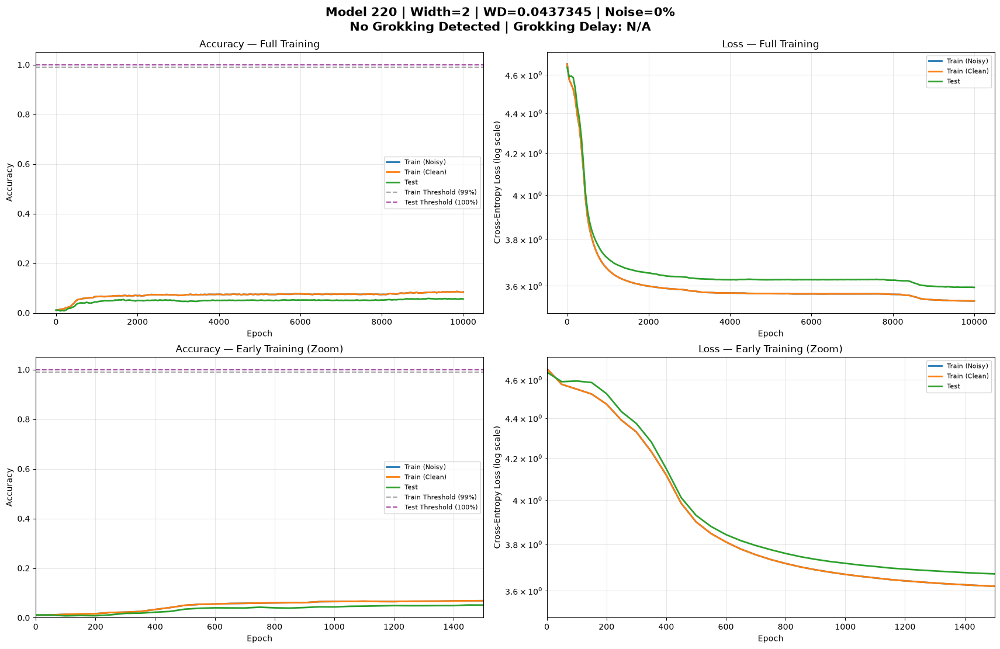

Training Models:  72%|███████▏  | 221/308 [38:20<3:14:14, 133.96s/model]


Training Model 221 | Width=2 | WD=0.04373448295773111 | Noise=5%
Model 221 | Epoch   500/10000 | Train: 0.0225 | Test: 0.0163
Model 221 | Epoch  1000/10000 | Train: 0.0411 | Test: 0.0344
Model 221 | Epoch  1500/10000 | Train: 0.0399 | Test: 0.0290
Model 221 | Epoch  2000/10000 | Train: 0.0398 | Test: 0.0301
Model 221 | Epoch  2500/10000 | Train: 0.0390 | Test: 0.0301
Model 221 | Epoch  3000/10000 | Train: 0.0407 | Test: 0.0305
Model 221 | Epoch  3500/10000 | Train: 0.0404 | Test: 0.0298
Model 221 | Epoch  4000/10000 | Train: 0.0402 | Test: 0.0298
Model 221 | Epoch  4500/10000 | Train: 0.0395 | Test: 0.0287
Model 221 | Epoch  5000/10000 | Train: 0.0401 | Test: 0.0276
Model 221 | Epoch  5500/10000 | Train: 0.0401 | Test: 0.0266
Model 221 | Epoch  6000/10000 | Train: 0.0401 | Test: 0.0280
Model 221 | Epoch  6500/10000 | Train: 0.0405 | Test: 0.0294
Model 221 | Epoch  7000/10000 | Train: 0.0392 | Test: 0.0290
Model 221 | Epoch  7500/10000 | Train: 0.0402 | Test: 0.0294
Model 221 | Epoch  

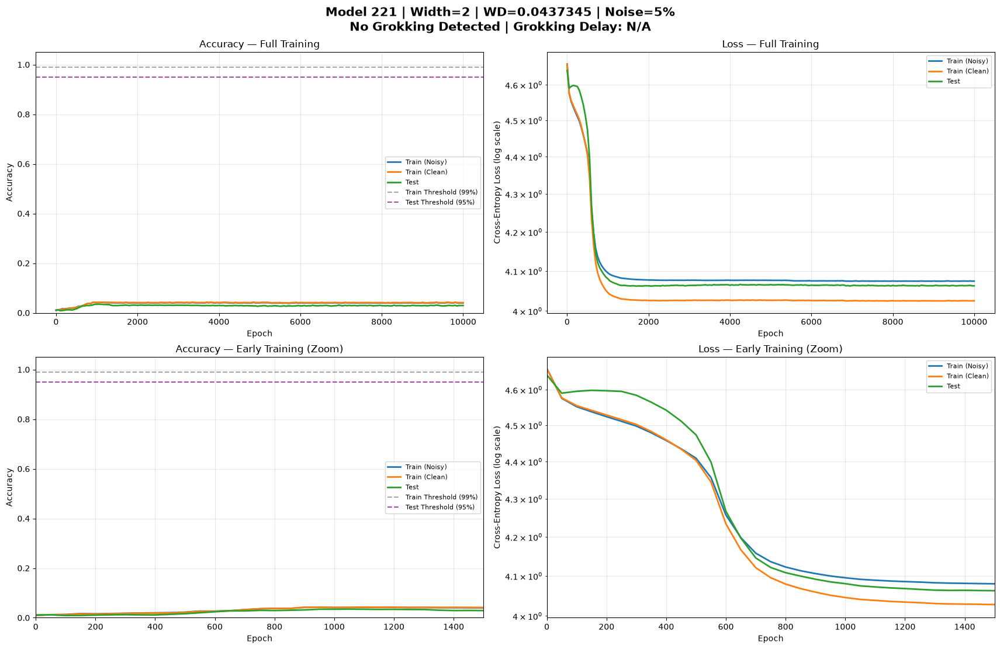

Training Models:  72%|███████▏  | 222/308 [39:52<2:54:19, 121.63s/model]


Training Model 222 | Width=2 | WD=0.04373448295773111 | Noise=15%
Model 222 | Epoch   500/10000 | Train: 0.0182 | Test: 0.0078
Model 222 | Epoch  1000/10000 | Train: 0.0188 | Test: 0.0081
Model 222 | Epoch  1500/10000 | Train: 0.0184 | Test: 0.0081
Model 222 | Epoch  2000/10000 | Train: 0.0193 | Test: 0.0092
Model 222 | Epoch  2500/10000 | Train: 0.0200 | Test: 0.0099
Model 222 | Epoch  3000/10000 | Train: 0.0213 | Test: 0.0110
Model 222 | Epoch  3500/10000 | Train: 0.0216 | Test: 0.0103
Model 222 | Epoch  4000/10000 | Train: 0.0255 | Test: 0.0131
Model 222 | Epoch  4500/10000 | Train: 0.0290 | Test: 0.0145
Model 222 | Epoch  5000/10000 | Train: 0.0298 | Test: 0.0152
Model 222 | Epoch  5500/10000 | Train: 0.0333 | Test: 0.0191
Model 222 | Epoch  6000/10000 | Train: 0.0336 | Test: 0.0149
Model 222 | Epoch  6500/10000 | Train: 0.0342 | Test: 0.0163
Model 222 | Epoch  7000/10000 | Train: 0.0345 | Test: 0.0166
Model 222 | Epoch  7500/10000 | Train: 0.0336 | Test: 0.0163
Model 222 | Epoch 

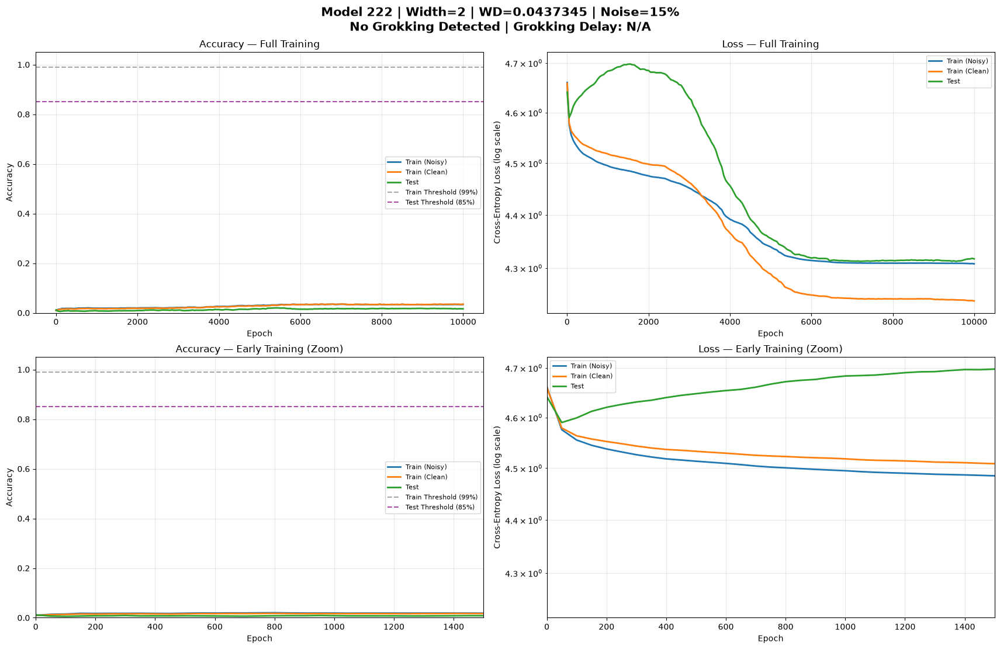

Training Models:  72%|███████▏  | 223/308 [41:25<2:40:03, 112.99s/model]


Training Model 223 | Width=2 | WD=0.04373448295773111 | Noise=25%
Model 223 | Epoch   500/10000 | Train: 0.0188 | Test: 0.0085
Model 223 | Epoch  1000/10000 | Train: 0.0187 | Test: 0.0092
Model 223 | Epoch  1500/10000 | Train: 0.0235 | Test: 0.0145
Model 223 | Epoch  2000/10000 | Train: 0.0269 | Test: 0.0170
Model 223 | Epoch  2500/10000 | Train: 0.0292 | Test: 0.0237
Model 223 | Epoch  3000/10000 | Train: 0.0345 | Test: 0.0287
Model 223 | Epoch  3500/10000 | Train: 0.0364 | Test: 0.0308
Model 223 | Epoch  4000/10000 | Train: 0.0370 | Test: 0.0319
Model 223 | Epoch  4500/10000 | Train: 0.0390 | Test: 0.0347
Model 223 | Epoch  5000/10000 | Train: 0.0392 | Test: 0.0351
Model 223 | Epoch  5500/10000 | Train: 0.0390 | Test: 0.0340
Model 223 | Epoch  6000/10000 | Train: 0.0384 | Test: 0.0337
Model 223 | Epoch  6500/10000 | Train: 0.0380 | Test: 0.0333
Model 223 | Epoch  7000/10000 | Train: 0.0390 | Test: 0.0347
Model 223 | Epoch  7500/10000 | Train: 0.0386 | Test: 0.0340
Model 223 | Epoch 

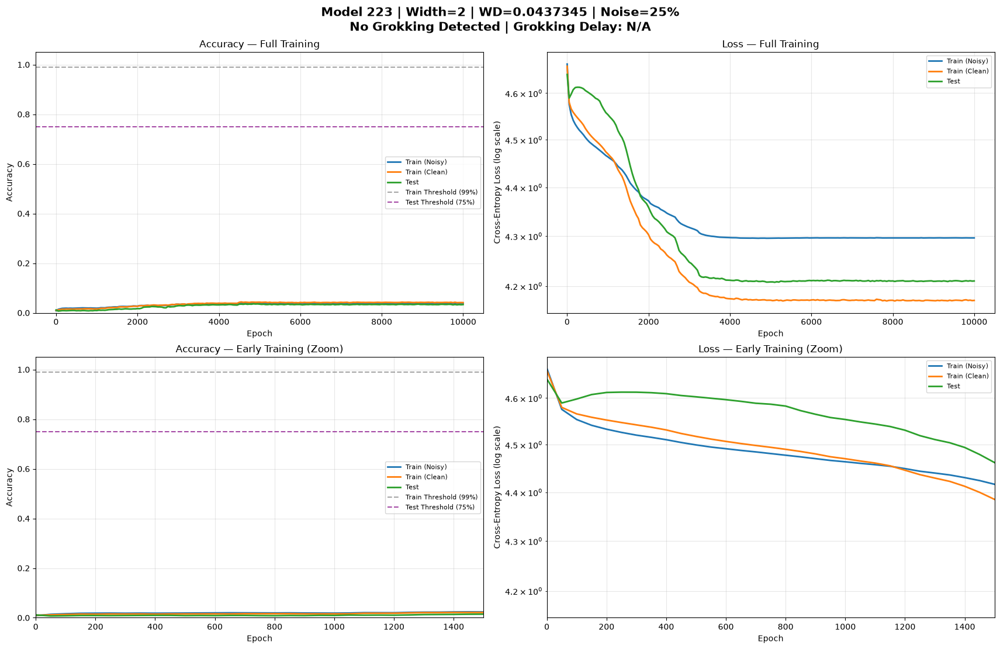

Training Models:  73%|███████▎  | 224/308 [42:58<2:29:36, 106.86s/model]


Training Model 224 | Width=4 | WD=0.04373448295773111 | Noise=0%
Model 224 | Epoch   500/10000 | Train: 0.0234 | Test: 0.0078
Model 224 | Epoch  1000/10000 | Train: 0.0742 | Test: 0.0503
Model 224 | Epoch  1500/10000 | Train: 0.8902 | Test: 0.8622
Model 224 | Epoch  2000/10000 | Train: 0.9245 | Test: 0.9192
Model 224 | Epoch  2500/10000 | Train: 0.9274 | Test: 0.9196
Model 224 | Epoch  3000/10000 | Train: 0.9142 | Test: 0.8987
Model 224 | Epoch  3500/10000 | Train: 0.9532 | Test: 0.9380
Model 224 | Epoch  4000/10000 | Train: 0.9109 | Test: 0.8835
Model 224 | Epoch  4500/10000 | Train: 0.8791 | Test: 0.8463
Model 224 | Epoch  5000/10000 | Train: 0.8580 | Test: 0.8310
Model 224 | Epoch  5500/10000 | Train: 0.8550 | Test: 0.8346
Model 224 | Epoch  6000/10000 | Train: 0.8647 | Test: 0.8328
Model 224 | Epoch  6500/10000 | Train: 0.8814 | Test: 0.8615
Model 224 | Epoch  7000/10000 | Train: 0.8778 | Test: 0.8381
Model 224 | Epoch  7500/10000 | Train: 0.8529 | Test: 0.8183
Model 224 | Epoch  

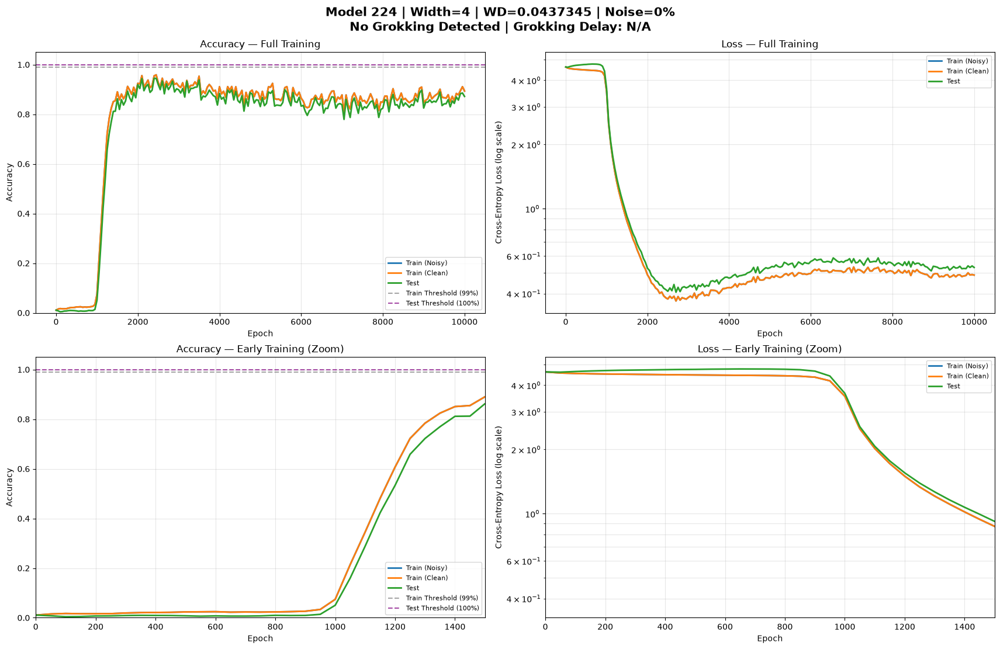

Training Models:  73%|███████▎  | 225/308 [44:31<2:21:59, 102.65s/model]


Training Model 225 | Width=4 | WD=0.04373448295773111 | Noise=5%
Model 225 | Epoch   500/10000 | Train: 0.0217 | Test: 0.0064
Model 225 | Epoch  1000/10000 | Train: 0.0261 | Test: 0.0060
Model 225 | Epoch  1500/10000 | Train: 0.0269 | Test: 0.0067
Model 225 | Epoch  2000/10000 | Train: 0.0264 | Test: 0.0074
Model 225 | Epoch  2500/10000 | Train: 0.0263 | Test: 0.0064
Model 225 | Epoch  3000/10000 | Train: 0.0276 | Test: 0.0085
Model 225 | Epoch  3500/10000 | Train: 0.0279 | Test: 0.0081
Model 225 | Epoch  4000/10000 | Train: 0.0282 | Test: 0.0078
Model 225 | Epoch  4500/10000 | Train: 0.0266 | Test: 0.0078
Model 225 | Epoch  5000/10000 | Train: 0.0272 | Test: 0.0078
Model 225 | Epoch  5500/10000 | Train: 0.0278 | Test: 0.0071
Model 225 | Epoch  6000/10000 | Train: 0.0282 | Test: 0.0071
Model 225 | Epoch  6500/10000 | Train: 0.0292 | Test: 0.0067
Model 225 | Epoch  7000/10000 | Train: 0.0288 | Test: 0.0078
Model 225 | Epoch  7500/10000 | Train: 0.0287 | Test: 0.0074
Model 225 | Epoch  

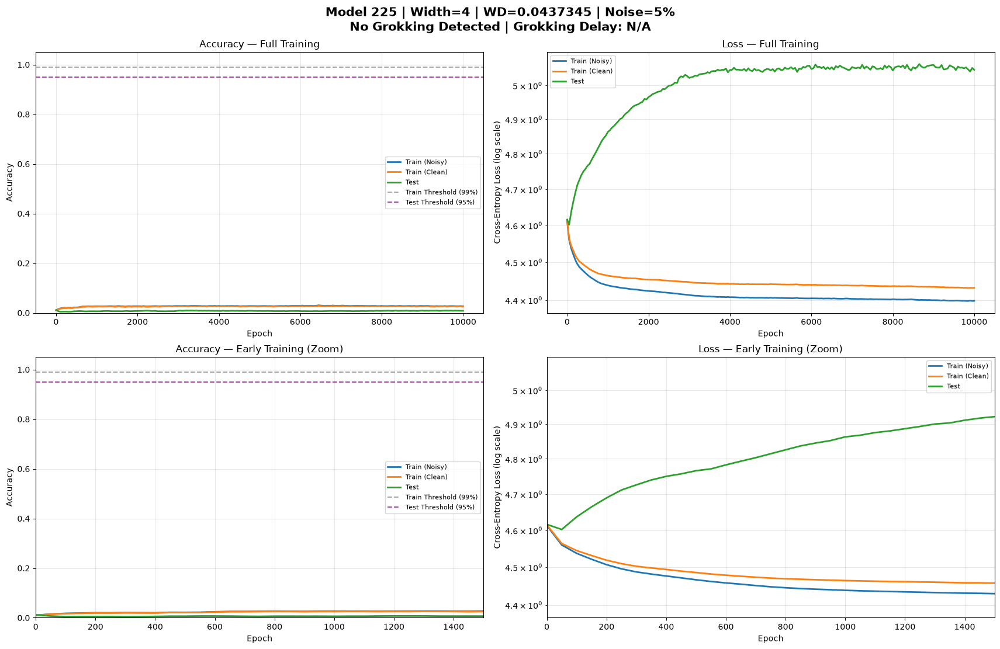

Training Models:  73%|███████▎  | 226/308 [46:03<2:16:10, 99.64s/model] 


Training Model 226 | Width=4 | WD=0.04373448295773111 | Noise=15%
Model 226 | Epoch   500/10000 | Train: 0.0222 | Test: 0.0071
Model 226 | Epoch  1000/10000 | Train: 0.0266 | Test: 0.0067
Model 226 | Epoch  1500/10000 | Train: 0.0238 | Test: 0.0060
Model 226 | Epoch  2000/10000 | Train: 0.0269 | Test: 0.0057
Model 226 | Epoch  2500/10000 | Train: 0.0307 | Test: 0.0074
Model 226 | Epoch  3000/10000 | Train: 0.0313 | Test: 0.0060
Model 226 | Epoch  3500/10000 | Train: 0.0320 | Test: 0.0071
Model 226 | Epoch  4000/10000 | Train: 0.0325 | Test: 0.0096
Model 226 | Epoch  4500/10000 | Train: 0.0325 | Test: 0.0092
Model 226 | Epoch  5000/10000 | Train: 0.0326 | Test: 0.0089
Model 226 | Epoch  5500/10000 | Train: 0.0326 | Test: 0.0113
Model 226 | Epoch  6000/10000 | Train: 0.0317 | Test: 0.0117
Model 226 | Epoch  6500/10000 | Train: 0.0568 | Test: 0.0351
Model 226 | Epoch  7000/10000 | Train: 0.1201 | Test: 0.0974
Model 226 | Epoch  7500/10000 | Train: 0.1397 | Test: 0.1151
Model 226 | Epoch 

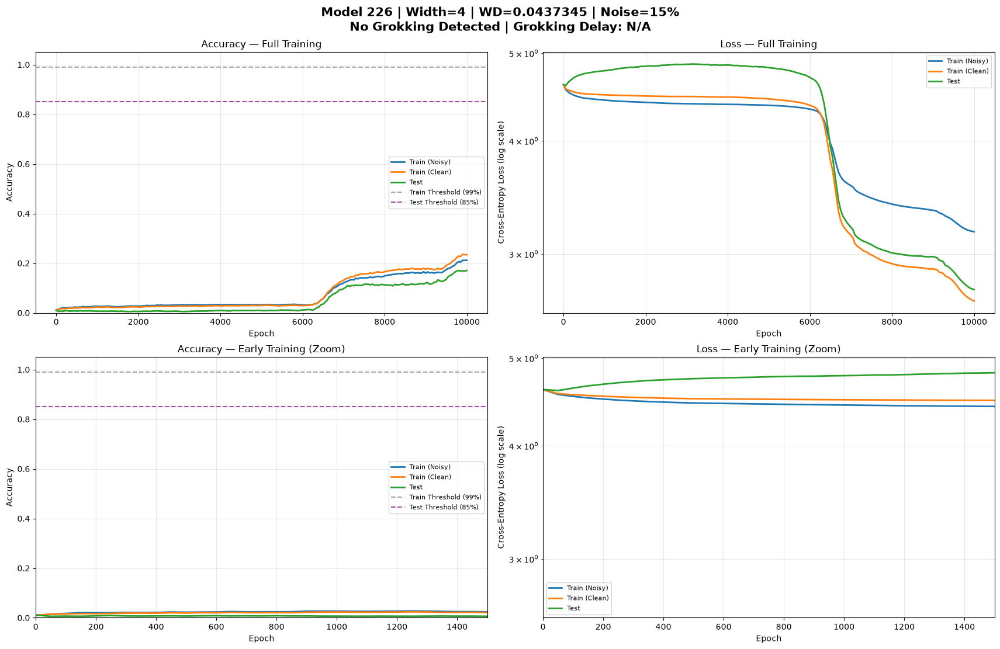

Training Models:  74%|███████▎  | 227/308 [47:36<2:11:42, 97.56s/model]


Training Model 227 | Width=4 | WD=0.04373448295773111 | Noise=25%
Model 227 | Epoch   500/10000 | Train: 0.0252 | Test: 0.0096
Model 227 | Epoch  1000/10000 | Train: 0.0273 | Test: 0.0085
Model 227 | Epoch  1500/10000 | Train: 0.0279 | Test: 0.0074
Model 227 | Epoch  2000/10000 | Train: 0.0288 | Test: 0.0103
Model 227 | Epoch  2500/10000 | Train: 0.0292 | Test: 0.0106
Model 227 | Epoch  3000/10000 | Train: 0.0275 | Test: 0.0135
Model 227 | Epoch  3500/10000 | Train: 0.0301 | Test: 0.0135
Model 227 | Epoch  4000/10000 | Train: 0.0320 | Test: 0.0124
Model 227 | Epoch  4500/10000 | Train: 0.0296 | Test: 0.0124
Model 227 | Epoch  5000/10000 | Train: 0.0316 | Test: 0.0166
Model 227 | Epoch  5500/10000 | Train: 0.0354 | Test: 0.0184
Model 227 | Epoch  6000/10000 | Train: 0.0427 | Test: 0.0340
Model 227 | Epoch  6500/10000 | Train: 0.0597 | Test: 0.0351
Model 227 | Epoch  7000/10000 | Train: 0.0711 | Test: 0.0535
Model 227 | Epoch  7500/10000 | Train: 0.0838 | Test: 0.0666
Model 227 | Epoch 

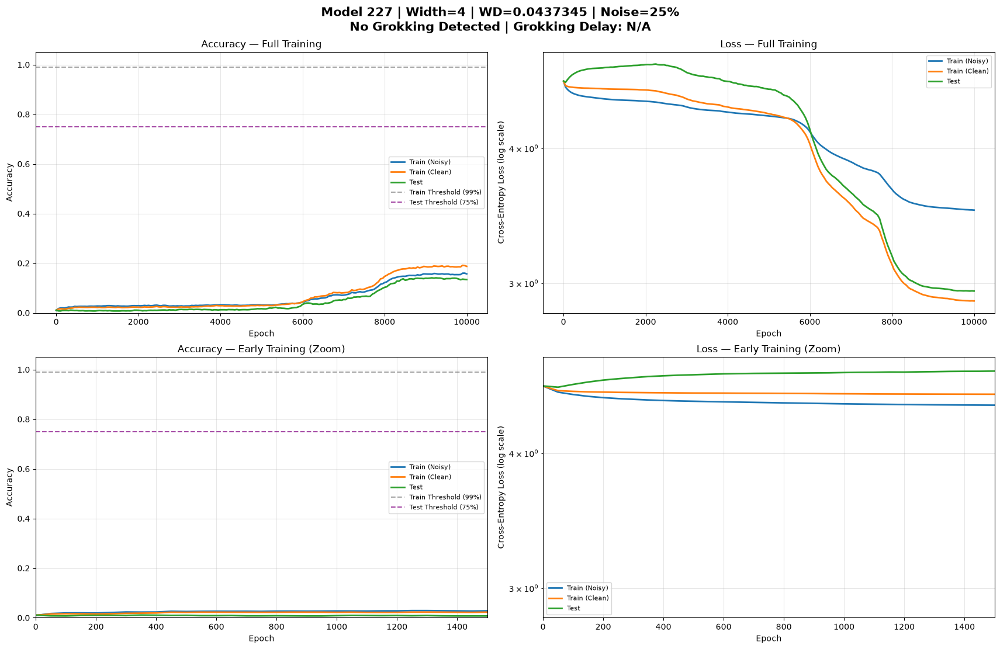

Training Models:  74%|███████▍  | 228/308 [49:09<2:08:25, 96.32s/model]


Training Model 228 | Width=8 | WD=0.04373448295773111 | Noise=0%
Model 228 | Epoch   500/10000 | Train: 0.4092 | Test: 0.2699
Model 228 | Epoch  1000/10000 | Train: 0.8722 | Test: 0.7917
Model 228 | Epoch  1500/10000 | Train: 0.9828 | Test: 0.9398
Model 228 | Epoch  2000/10000 | Train: 0.9997 | Test: 0.9894
Model 228 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.9961
Model 228 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.9975
Model 228 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.9965
Model 228 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9982
Model 228 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9989
Model 228 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 228 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 228 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 228 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9996
Model 228 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 228 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 228 | Epoch  

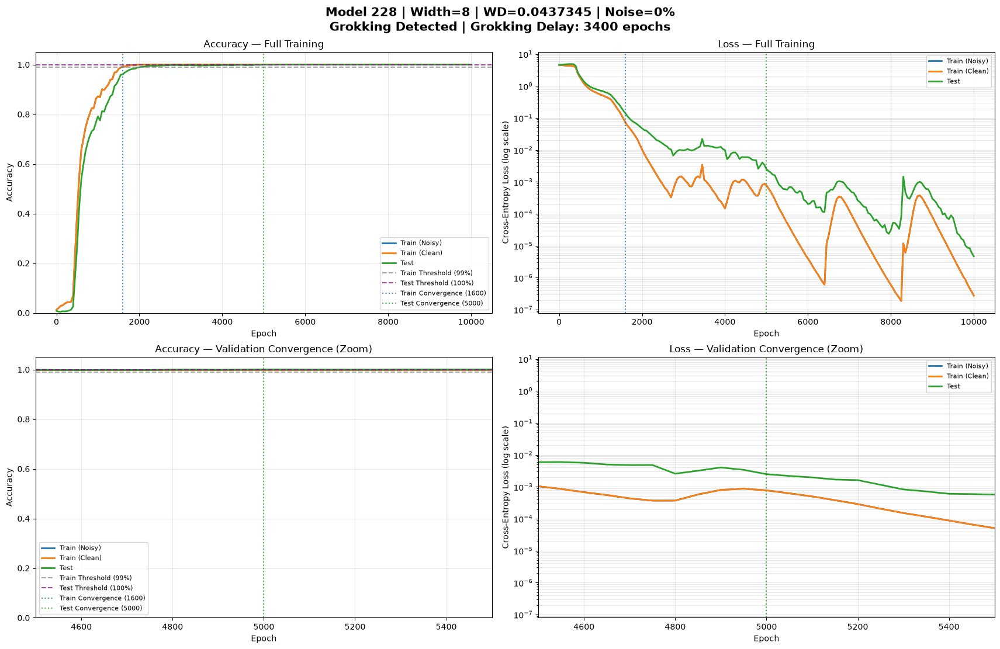

Training Models:  74%|███████▍  | 229/308 [50:43<2:05:40, 95.45s/model]


Training Model 229 | Width=8 | WD=0.04373448295773111 | Noise=5%
Model 229 | Epoch   500/10000 | Train: 0.2533 | Test: 0.1523
Model 229 | Epoch  1000/10000 | Train: 0.9341 | Test: 0.9504
Model 229 | Epoch  1500/10000 | Train: 0.9467 | Test: 0.9823
Model 229 | Epoch  2000/10000 | Train: 0.9485 | Test: 0.9766
Model 229 | Epoch  2500/10000 | Train: 0.9485 | Test: 0.9763
Model 229 | Epoch  3000/10000 | Train: 0.9484 | Test: 0.9734
Model 229 | Epoch  3500/10000 | Train: 0.9485 | Test: 0.9678
Model 229 | Epoch  4000/10000 | Train: 0.9493 | Test: 0.9685
Model 229 | Epoch  4500/10000 | Train: 0.9493 | Test: 0.9717
Model 229 | Epoch  5000/10000 | Train: 0.9493 | Test: 0.9692
Model 229 | Epoch  5500/10000 | Train: 0.9493 | Test: 0.9692
Model 229 | Epoch  6000/10000 | Train: 0.9493 | Test: 0.9681
Model 229 | Epoch  6500/10000 | Train: 0.9497 | Test: 0.9702
Model 229 | Epoch  7000/10000 | Train: 0.9493 | Test: 0.9692
Model 229 | Epoch  7500/10000 | Train: 0.9496 | Test: 0.9685
Model 229 | Epoch  

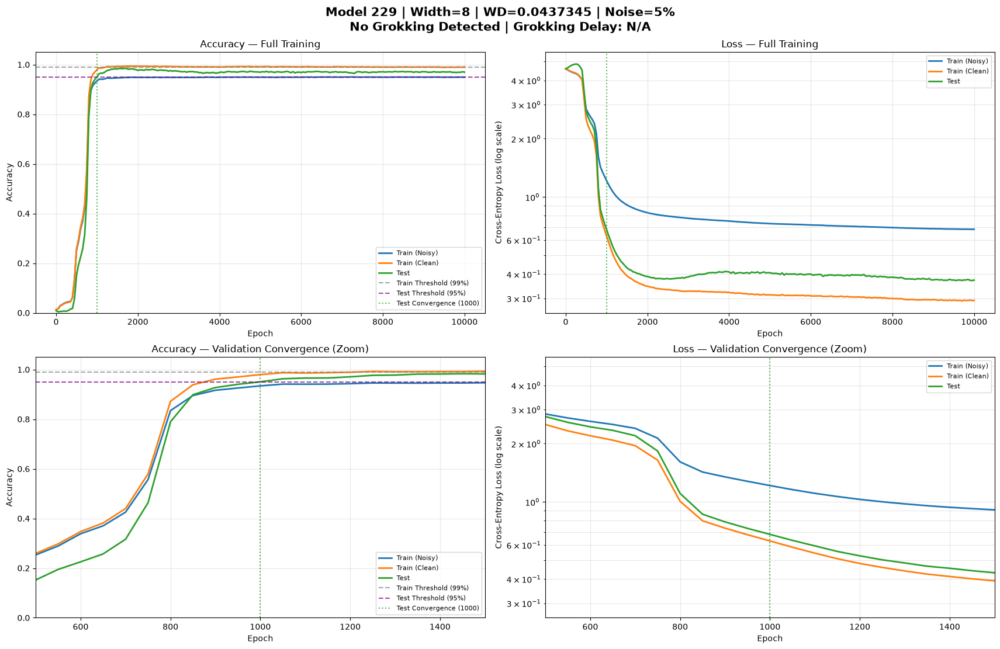

Training Models:  75%|███████▍  | 230/308 [52:16<2:03:09, 94.74s/model]


Training Model 230 | Width=8 | WD=0.04373448295773111 | Noise=15%
Model 230 | Epoch   500/10000 | Train: 0.0431 | Test: 0.0064
Model 230 | Epoch  1000/10000 | Train: 0.0914 | Test: 0.0457
Model 230 | Epoch  1500/10000 | Train: 0.2141 | Test: 0.1173
Model 230 | Epoch  2000/10000 | Train: 0.4472 | Test: 0.4060
Model 230 | Epoch  2500/10000 | Train: 0.8356 | Test: 0.9539
Model 230 | Epoch  3000/10000 | Train: 0.8459 | Test: 0.9756
Model 230 | Epoch  3500/10000 | Train: 0.8466 | Test: 0.9759
Model 230 | Epoch  4000/10000 | Train: 0.8462 | Test: 0.9759
Model 230 | Epoch  4500/10000 | Train: 0.8460 | Test: 0.9756
Model 230 | Epoch  5000/10000 | Train: 0.8459 | Test: 0.9756
Model 230 | Epoch  5500/10000 | Train: 0.8465 | Test: 0.9745
Model 230 | Epoch  6000/10000 | Train: 0.8468 | Test: 0.9770
Model 230 | Epoch  6500/10000 | Train: 0.8462 | Test: 0.9770
Model 230 | Epoch  7000/10000 | Train: 0.8456 | Test: 0.9766
Model 230 | Epoch  7500/10000 | Train: 0.8457 | Test: 0.9773
Model 230 | Epoch 

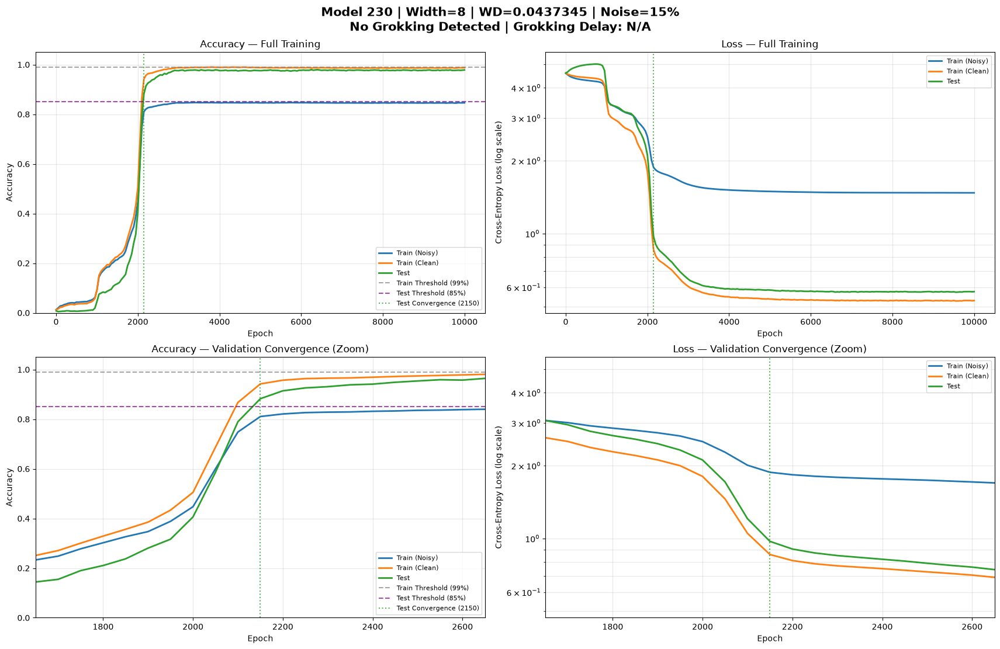

Training Models:  75%|███████▌  | 231/308 [53:48<2:00:39, 94.01s/model]


Training Model 231 | Width=8 | WD=0.04373448295773111 | Noise=25%
Model 231 | Epoch   500/10000 | Train: 0.0489 | Test: 0.0050
Model 231 | Epoch  1000/10000 | Train: 0.0533 | Test: 0.0078
Model 231 | Epoch  1500/10000 | Train: 0.0559 | Test: 0.0050
Model 231 | Epoch  2000/10000 | Train: 0.0615 | Test: 0.0067
Model 231 | Epoch  2500/10000 | Train: 0.0623 | Test: 0.0060
Model 231 | Epoch  3000/10000 | Train: 0.0635 | Test: 0.0096
Model 231 | Epoch  3500/10000 | Train: 0.0632 | Test: 0.0081
Model 231 | Epoch  4000/10000 | Train: 0.0659 | Test: 0.0096
Model 231 | Epoch  4500/10000 | Train: 0.0651 | Test: 0.0110
Model 231 | Epoch  5000/10000 | Train: 0.0650 | Test: 0.0106
Model 231 | Epoch  5500/10000 | Train: 0.0630 | Test: 0.0092
Model 231 | Epoch  6000/10000 | Train: 0.0639 | Test: 0.0110
Model 231 | Epoch  6500/10000 | Train: 0.0653 | Test: 0.0103
Model 231 | Epoch  7000/10000 | Train: 0.0664 | Test: 0.0110
Model 231 | Epoch  7500/10000 | Train: 0.0648 | Test: 0.0110
Model 231 | Epoch 

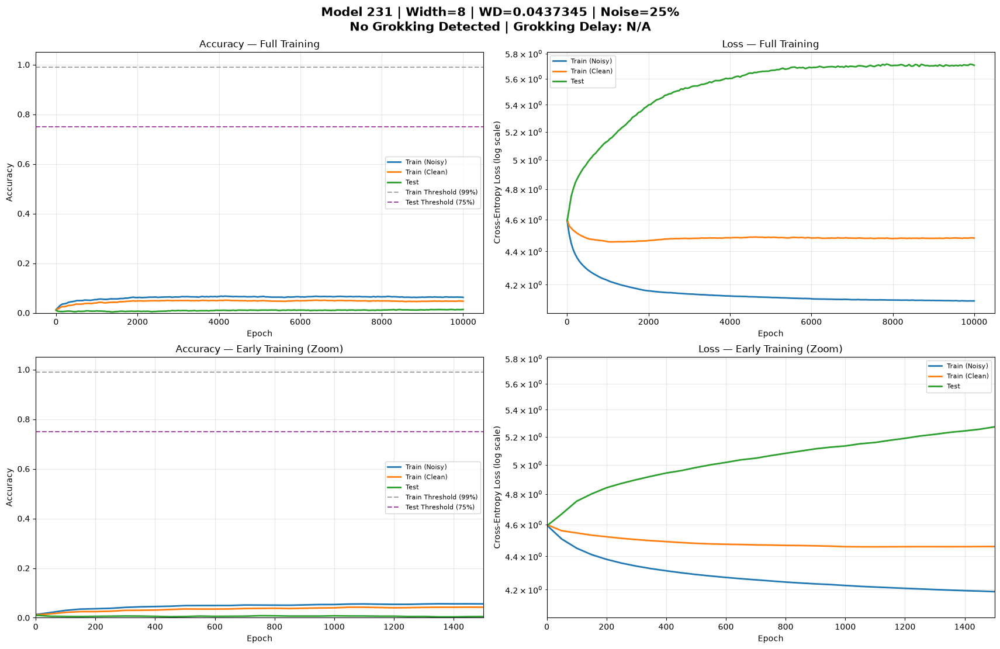

Training Models:  75%|███████▌  | 232/308 [55:21<1:58:41, 93.71s/model]


Training Model 232 | Width=12 | WD=0.04373448295773111 | Noise=0%
Model 232 | Epoch   500/10000 | Train: 0.9891 | Test: 0.9430
Model 232 | Epoch  1000/10000 | Train: 1.0000 | Test: 1.0000
Model 232 | Epoch  1500/10000 | Train: 1.0000 | Test: 1.0000
Model 232 | Epoch  2000/10000 | Train: 1.0000 | Test: 1.0000
Model 232 | Epoch  2500/10000 | Train: 1.0000 | Test: 1.0000
Model 232 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 232 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 232 | Epoch  4000/10000 | Train: 1.0000 | Test: 1.0000
Model 232 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 232 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 232 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 232 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 232 | Epoch  6500/10000 | Train: 1.0000 | Test: 1.0000
Model 232 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 232 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 232 | Epoch 

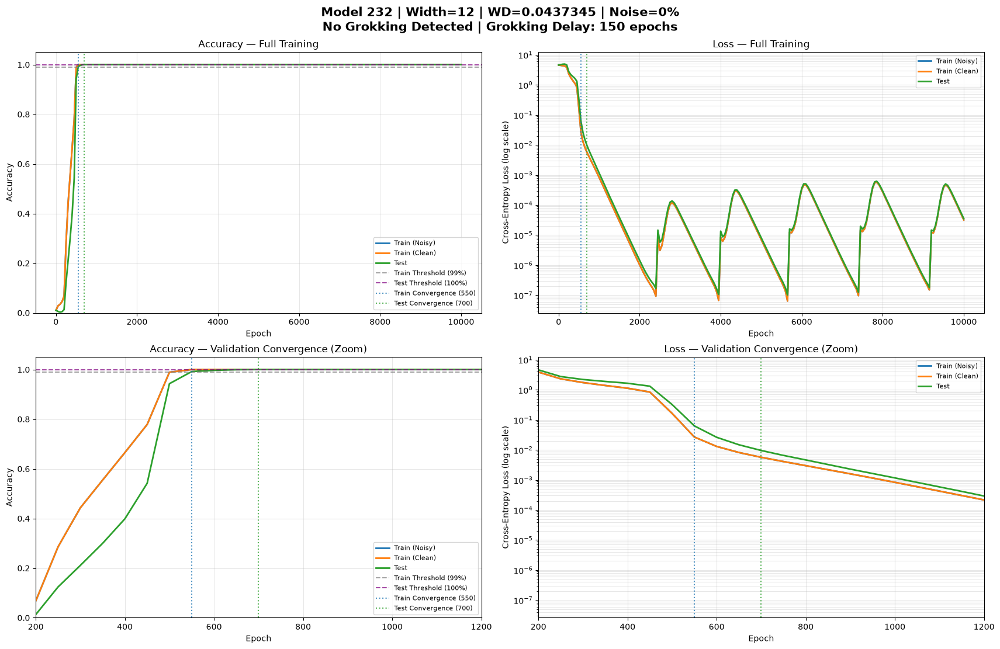

Training Models:  76%|███████▌  | 233/308 [56:55<1:57:17, 93.84s/model]


Training Model 233 | Width=12 | WD=0.04373448295773111 | Noise=5%
Model 233 | Epoch   500/10000 | Train: 0.3717 | Test: 0.1527
Model 233 | Epoch  1000/10000 | Train: 0.9165 | Test: 0.8512
Model 233 | Epoch  1500/10000 | Train: 0.9491 | Test: 0.8948
Model 233 | Epoch  2000/10000 | Train: 0.9511 | Test: 0.8852
Model 233 | Epoch  2500/10000 | Train: 0.9534 | Test: 0.8757
Model 233 | Epoch  3000/10000 | Train: 0.9563 | Test: 0.8523
Model 233 | Epoch  3500/10000 | Train: 0.9573 | Test: 0.8438
Model 233 | Epoch  4000/10000 | Train: 0.9589 | Test: 0.8321
Model 233 | Epoch  4500/10000 | Train: 0.9610 | Test: 0.8300
Model 233 | Epoch  5000/10000 | Train: 0.9628 | Test: 0.8271
Model 233 | Epoch  5500/10000 | Train: 0.9634 | Test: 0.8211
Model 233 | Epoch  6000/10000 | Train: 0.9636 | Test: 0.8190
Model 233 | Epoch  6500/10000 | Train: 0.9651 | Test: 0.8144
Model 233 | Epoch  7000/10000 | Train: 0.9648 | Test: 0.8222
Model 233 | Epoch  7500/10000 | Train: 0.9663 | Test: 0.8186
Model 233 | Epoch 

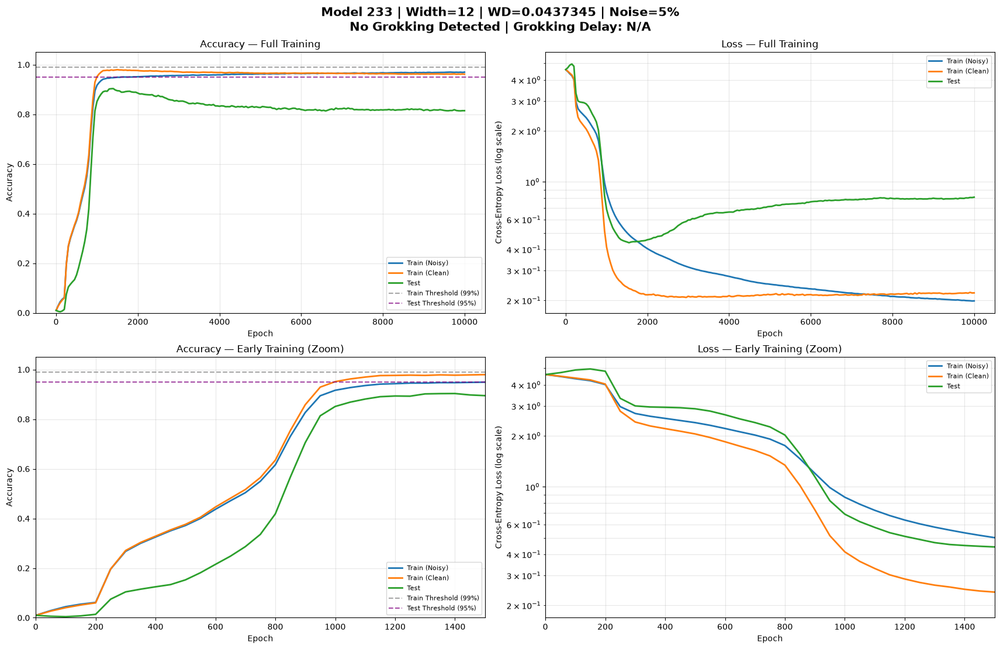

Training Models:  76%|███████▌  | 234/308 [58:29<1:55:49, 93.91s/model]


Training Model 234 | Width=12 | WD=0.04373448295773111 | Noise=15%
Model 234 | Epoch   500/10000 | Train: 0.0812 | Test: 0.0074
Model 234 | Epoch  1000/10000 | Train: 0.1940 | Test: 0.0553
Model 234 | Epoch  1500/10000 | Train: 0.2425 | Test: 0.0871
Model 234 | Epoch  2000/10000 | Train: 0.2841 | Test: 0.1077
Model 234 | Epoch  2500/10000 | Train: 0.3178 | Test: 0.1254
Model 234 | Epoch  3000/10000 | Train: 0.3397 | Test: 0.1477
Model 234 | Epoch  3500/10000 | Train: 0.3588 | Test: 0.1583
Model 234 | Epoch  4000/10000 | Train: 0.4370 | Test: 0.2345
Model 234 | Epoch  4500/10000 | Train: 0.6796 | Test: 0.5055
Model 234 | Epoch  5000/10000 | Train: 0.7060 | Test: 0.5448
Model 234 | Epoch  5500/10000 | Train: 0.7199 | Test: 0.5576
Model 234 | Epoch  6000/10000 | Train: 0.7300 | Test: 0.5813
Model 234 | Epoch  6500/10000 | Train: 0.7363 | Test: 0.5940
Model 234 | Epoch  7000/10000 | Train: 0.7387 | Test: 0.5923
Model 234 | Epoch  7500/10000 | Train: 0.7464 | Test: 0.6004
Model 234 | Epoch

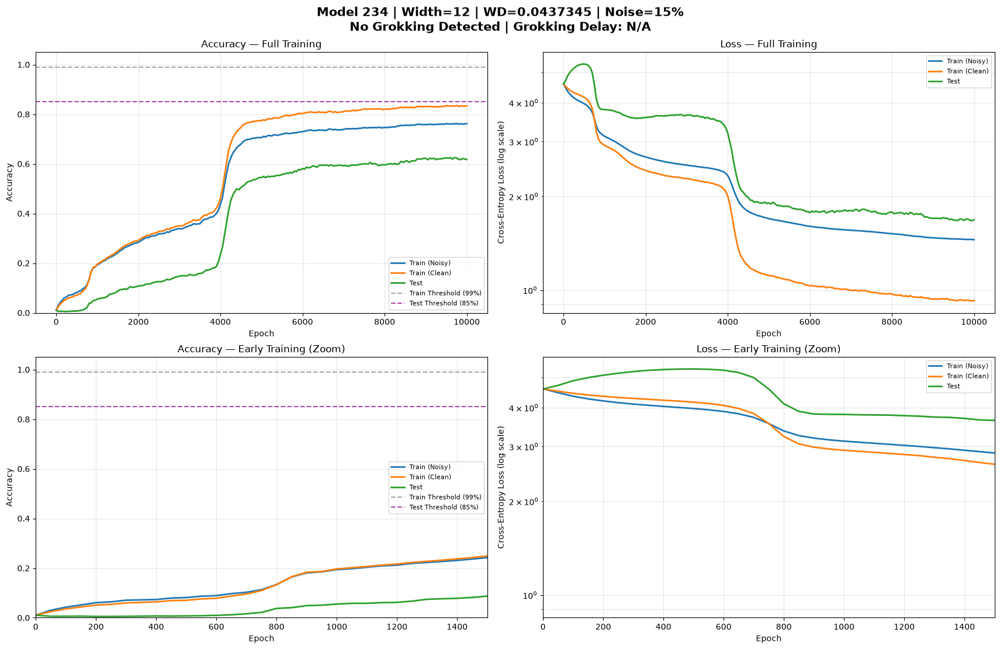

Training Models:  76%|███████▋  | 235/308 [1:00:03<1:54:08, 93.82s/model]


Training Model 235 | Width=12 | WD=0.04373448295773111 | Noise=25%
Model 235 | Epoch   500/10000 | Train: 0.0764 | Test: 0.0085
Model 235 | Epoch  1000/10000 | Train: 0.0935 | Test: 0.0057
Model 235 | Epoch  1500/10000 | Train: 0.1031 | Test: 0.0053
Model 235 | Epoch  2000/10000 | Train: 0.1013 | Test: 0.0085
Model 235 | Epoch  2500/10000 | Train: 0.1064 | Test: 0.0096
Model 235 | Epoch  3000/10000 | Train: 0.1087 | Test: 0.0092
Model 235 | Epoch  3500/10000 | Train: 0.1116 | Test: 0.0067
Model 235 | Epoch  4000/10000 | Train: 0.1098 | Test: 0.0085
Model 235 | Epoch  4500/10000 | Train: 0.1160 | Test: 0.0092
Model 235 | Epoch  5000/10000 | Train: 0.1183 | Test: 0.0142
Model 235 | Epoch  5500/10000 | Train: 0.1527 | Test: 0.0358
Model 235 | Epoch  6000/10000 | Train: 0.1857 | Test: 0.0468
Model 235 | Epoch  6500/10000 | Train: 0.1942 | Test: 0.0510
Model 235 | Epoch  7000/10000 | Train: 0.2013 | Test: 0.0457
Model 235 | Epoch  7500/10000 | Train: 0.2079 | Test: 0.0521
Model 235 | Epoch

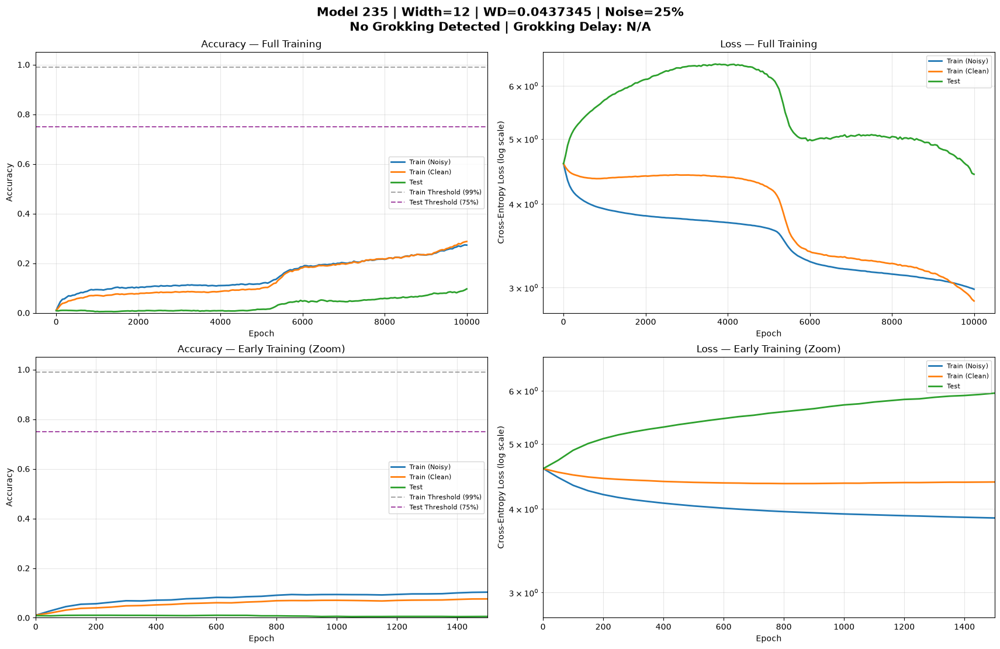

Training Models:  77%|███████▋  | 236/308 [1:01:37<1:52:35, 93.83s/model]


Training Model 236 | Width=16 | WD=0.04373448295773111 | Noise=0%
Model 236 | Epoch   500/10000 | Train: 0.1329 | Test: 0.0166
Model 236 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.9965
Model 236 | Epoch  1500/10000 | Train: 1.0000 | Test: 1.0000
Model 236 | Epoch  2000/10000 | Train: 1.0000 | Test: 1.0000
Model 236 | Epoch  2500/10000 | Train: 1.0000 | Test: 1.0000
Model 236 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 236 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 236 | Epoch  4000/10000 | Train: 1.0000 | Test: 1.0000
Model 236 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 236 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 236 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 236 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 236 | Epoch  6500/10000 | Train: 1.0000 | Test: 1.0000
Model 236 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 236 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 236 | Epoch 

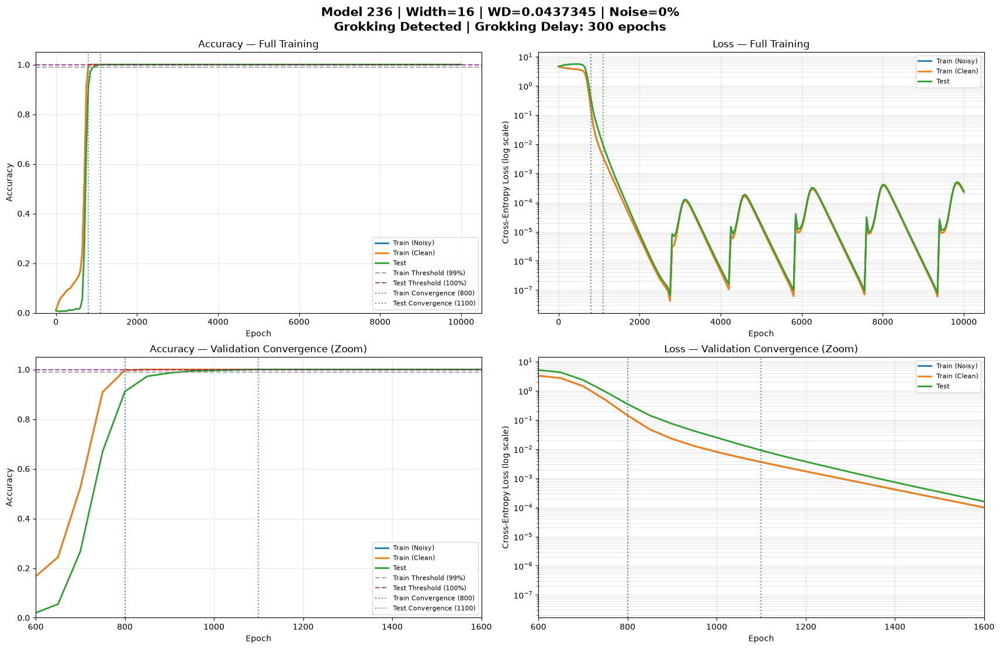

Training Models:  77%|███████▋  | 237/308 [1:03:10<1:50:57, 93.77s/model]


Training Model 237 | Width=16 | WD=0.04373448295773111 | Noise=5%
Model 237 | Epoch   500/10000 | Train: 0.1256 | Test: 0.0099
Model 237 | Epoch  1000/10000 | Train: 0.3980 | Test: 0.0861
Model 237 | Epoch  1500/10000 | Train: 0.8433 | Test: 0.5193
Model 237 | Epoch  2000/10000 | Train: 0.9151 | Test: 0.5948
Model 237 | Epoch  2500/10000 | Train: 0.9414 | Test: 0.6284
Model 237 | Epoch  3000/10000 | Train: 0.9578 | Test: 0.6415
Model 237 | Epoch  3500/10000 | Train: 0.9680 | Test: 0.6525
Model 237 | Epoch  4000/10000 | Train: 0.9768 | Test: 0.6504
Model 237 | Epoch  4500/10000 | Train: 0.9833 | Test: 0.6521
Model 237 | Epoch  5000/10000 | Train: 0.9900 | Test: 0.6564
Model 237 | Epoch  5500/10000 | Train: 0.9962 | Test: 0.6490
Model 237 | Epoch  6000/10000 | Train: 0.9980 | Test: 0.6482
Model 237 | Epoch  6500/10000 | Train: 0.9998 | Test: 0.6507
Model 237 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.6507
Model 237 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.6592
Model 237 | Epoch 

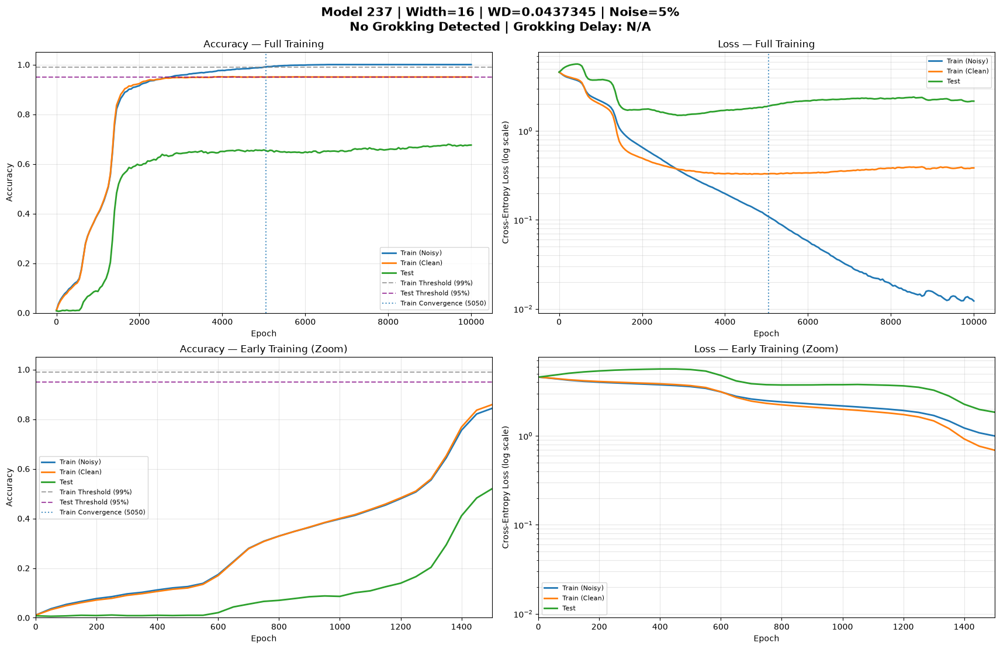

Training Models:  77%|███████▋  | 238/308 [1:04:44<1:49:12, 93.61s/model]


Training Model 238 | Width=16 | WD=0.04373448295773111 | Noise=15%
Model 238 | Epoch   500/10000 | Train: 0.1140 | Test: 0.0053
Model 238 | Epoch  1000/10000 | Train: 0.1362 | Test: 0.0089
Model 238 | Epoch  1500/10000 | Train: 0.1486 | Test: 0.0071
Model 238 | Epoch  2000/10000 | Train: 0.1511 | Test: 0.0085
Model 238 | Epoch  2500/10000 | Train: 0.1608 | Test: 0.0092
Model 238 | Epoch  3000/10000 | Train: 0.1623 | Test: 0.0110
Model 238 | Epoch  3500/10000 | Train: 0.1675 | Test: 0.0156
Model 238 | Epoch  4000/10000 | Train: 0.1755 | Test: 0.0145
Model 238 | Epoch  4500/10000 | Train: 0.1784 | Test: 0.0124
Model 238 | Epoch  5000/10000 | Train: 0.1849 | Test: 0.0124
Model 238 | Epoch  5500/10000 | Train: 0.1819 | Test: 0.0117
Model 238 | Epoch  6000/10000 | Train: 0.2000 | Test: 0.0177
Model 238 | Epoch  6500/10000 | Train: 0.2457 | Test: 0.0315
Model 238 | Epoch  7000/10000 | Train: 0.3025 | Test: 0.0546
Model 238 | Epoch  7500/10000 | Train: 0.3966 | Test: 0.1045
Model 238 | Epoch

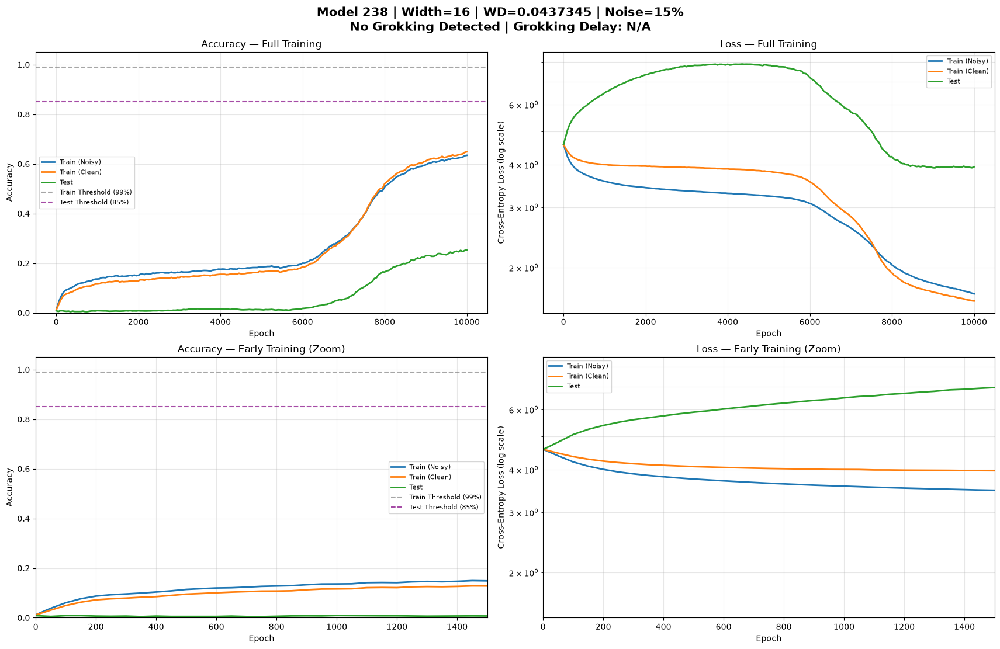

Training Models:  78%|███████▊  | 239/308 [1:06:17<1:47:37, 93.58s/model]


Training Model 239 | Width=16 | WD=0.04373448295773111 | Noise=25%
Model 239 | Epoch   500/10000 | Train: 0.1186 | Test: 0.0046
Model 239 | Epoch  1000/10000 | Train: 0.1374 | Test: 0.0060
Model 239 | Epoch  1500/10000 | Train: 0.1471 | Test: 0.0057
Model 239 | Epoch  2000/10000 | Train: 0.1511 | Test: 0.0067
Model 239 | Epoch  2500/10000 | Train: 0.1596 | Test: 0.0060
Model 239 | Epoch  3000/10000 | Train: 0.1650 | Test: 0.0060
Model 239 | Epoch  3500/10000 | Train: 0.1655 | Test: 0.0064
Model 239 | Epoch  4000/10000 | Train: 0.1698 | Test: 0.0071
Model 239 | Epoch  4500/10000 | Train: 0.1707 | Test: 0.0067
Model 239 | Epoch  5000/10000 | Train: 0.1731 | Test: 0.0074
Model 239 | Epoch  5500/10000 | Train: 0.1735 | Test: 0.0071
Model 239 | Epoch  6000/10000 | Train: 0.1763 | Test: 0.0057
Model 239 | Epoch  6500/10000 | Train: 0.1758 | Test: 0.0050
Model 239 | Epoch  7000/10000 | Train: 0.1801 | Test: 0.0067
Model 239 | Epoch  7500/10000 | Train: 0.1789 | Test: 0.0081
Model 239 | Epoch

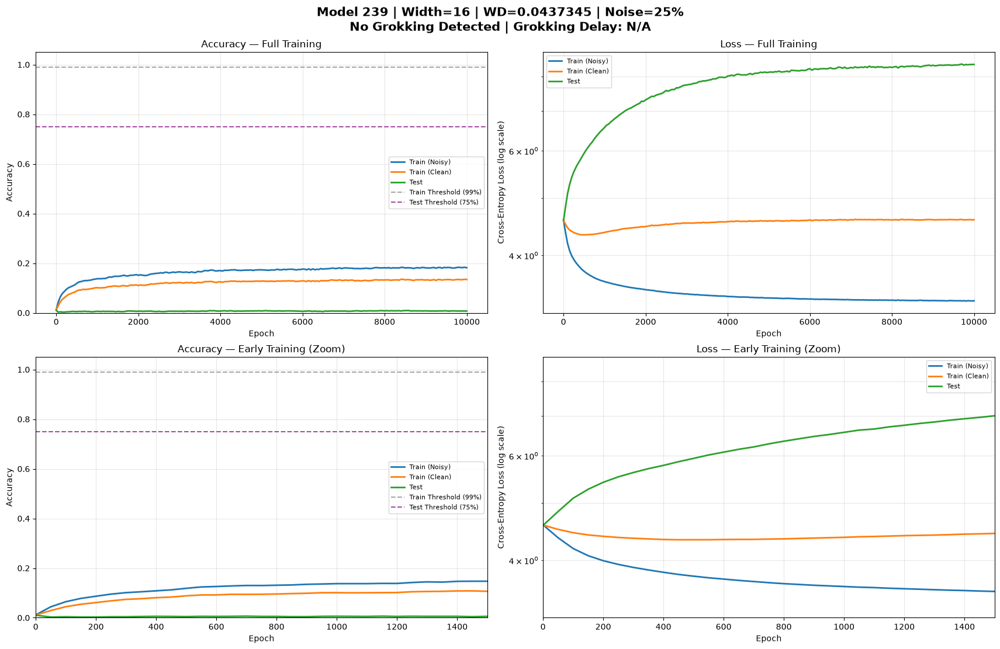

Training Models:  78%|███████▊  | 240/308 [1:07:50<1:45:40, 93.24s/model]


Training Model 240 | Width=20 | WD=0.04373448295773111 | Noise=0%
Model 240 | Epoch   500/10000 | Train: 1.0000 | Test: 1.0000
Model 240 | Epoch  1000/10000 | Train: 1.0000 | Test: 1.0000
Model 240 | Epoch  1500/10000 | Train: 1.0000 | Test: 1.0000
Model 240 | Epoch  2000/10000 | Train: 1.0000 | Test: 1.0000
Model 240 | Epoch  2500/10000 | Train: 1.0000 | Test: 1.0000
Model 240 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 240 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 240 | Epoch  4000/10000 | Train: 1.0000 | Test: 1.0000
Model 240 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 240 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 240 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 240 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 240 | Epoch  6500/10000 | Train: 1.0000 | Test: 1.0000
Model 240 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 240 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 240 | Epoch 

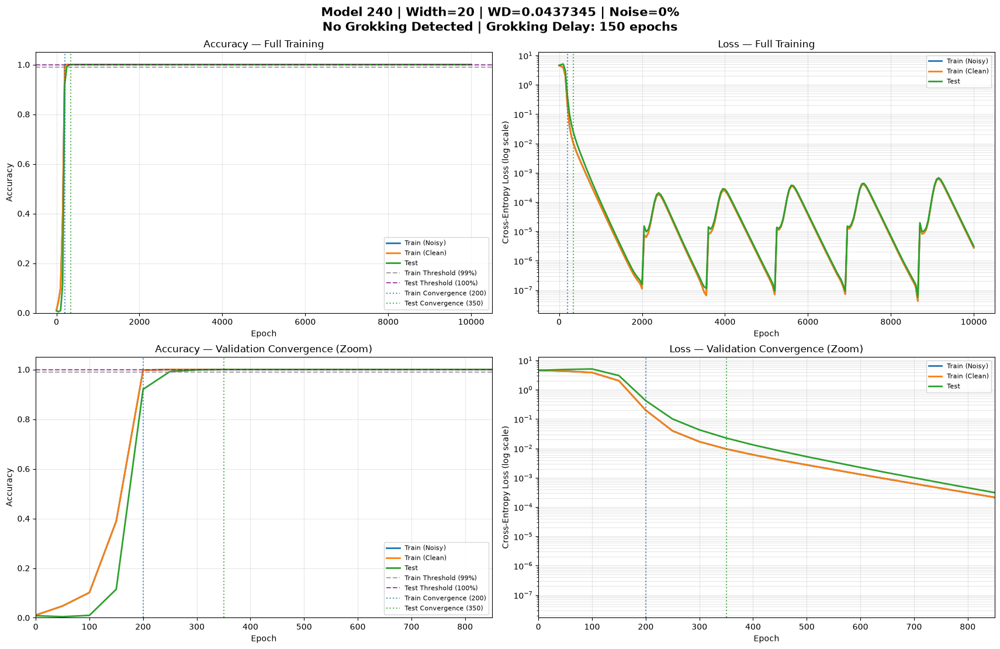

Training Models:  78%|███████▊  | 241/308 [1:09:24<1:44:24, 93.50s/model]


Training Model 241 | Width=20 | WD=0.04373448295773111 | Noise=5%
Model 241 | Epoch   500/10000 | Train: 0.9128 | Test: 0.4903
Model 241 | Epoch  1000/10000 | Train: 0.9819 | Test: 0.6532
Model 241 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.6876
Model 241 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.7056
Model 241 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.7258
Model 241 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.7276
Model 241 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.7421
Model 241 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.7485
Model 241 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.7474
Model 241 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.7464
Model 241 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.7538
Model 241 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.7581
Model 241 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.7620
Model 241 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.7598
Model 241 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.7574
Model 241 | Epoch 

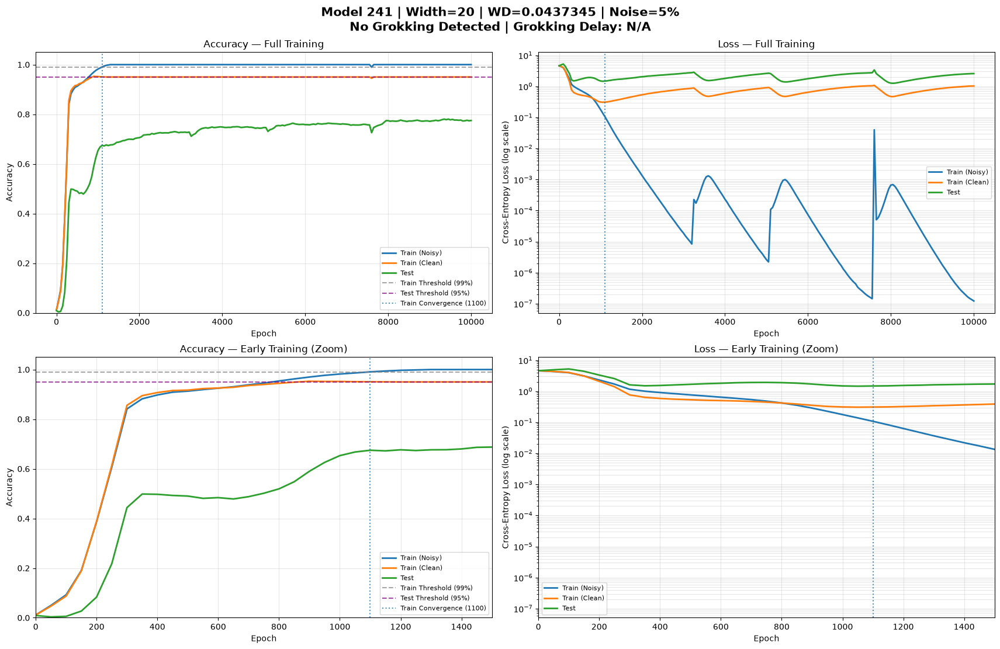

Training Models:  79%|███████▊  | 242/308 [1:10:57<1:42:47, 93.44s/model]


Training Model 242 | Width=20 | WD=0.04373448295773111 | Noise=15%
Model 242 | Epoch   500/10000 | Train: 0.2357 | Test: 0.0181
Model 242 | Epoch  1000/10000 | Train: 0.6036 | Test: 0.1477
Model 242 | Epoch  1500/10000 | Train: 0.6710 | Test: 0.1612
Model 242 | Epoch  2000/10000 | Train: 0.6957 | Test: 0.1626
Model 242 | Epoch  2500/10000 | Train: 0.7082 | Test: 0.1654
Model 242 | Epoch  3000/10000 | Train: 0.7226 | Test: 0.1633
Model 242 | Epoch  3500/10000 | Train: 0.7338 | Test: 0.1697
Model 242 | Epoch  4000/10000 | Train: 0.7367 | Test: 0.1658
Model 242 | Epoch  4500/10000 | Train: 0.7385 | Test: 0.1714
Model 242 | Epoch  5000/10000 | Train: 0.7416 | Test: 0.1676
Model 242 | Epoch  5500/10000 | Train: 0.7461 | Test: 0.1725
Model 242 | Epoch  6000/10000 | Train: 0.7463 | Test: 0.1796
Model 242 | Epoch  6500/10000 | Train: 0.7501 | Test: 0.1714
Model 242 | Epoch  7000/10000 | Train: 0.7568 | Test: 0.1743
Model 242 | Epoch  7500/10000 | Train: 0.7598 | Test: 0.1800
Model 242 | Epoch

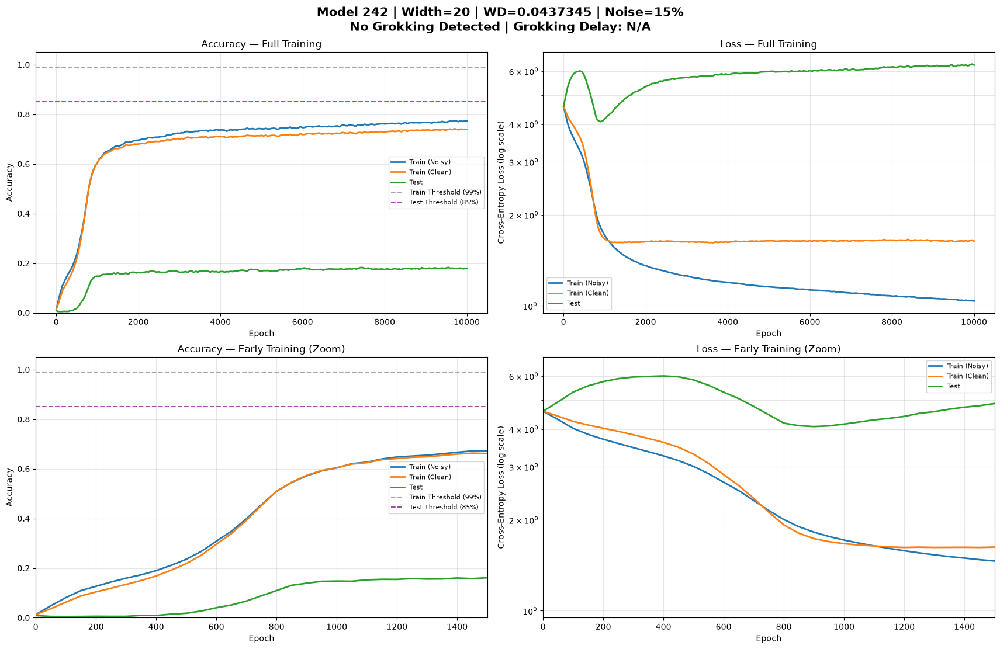

Training Models:  79%|███████▉  | 243/308 [1:12:30<1:41:01, 93.25s/model]


Training Model 243 | Width=20 | WD=0.04373448295773111 | Noise=25%
Model 243 | Epoch   500/10000 | Train: 0.1810 | Test: 0.0043
Model 243 | Epoch  1000/10000 | Train: 0.2212 | Test: 0.0092
Model 243 | Epoch  1500/10000 | Train: 0.2452 | Test: 0.0099
Model 243 | Epoch  2000/10000 | Train: 0.2662 | Test: 0.0120
Model 243 | Epoch  2500/10000 | Train: 0.2766 | Test: 0.0120
Model 243 | Epoch  3000/10000 | Train: 0.2862 | Test: 0.0099
Model 243 | Epoch  3500/10000 | Train: 0.2978 | Test: 0.0113
Model 243 | Epoch  4000/10000 | Train: 0.3056 | Test: 0.0142
Model 243 | Epoch  4500/10000 | Train: 0.3176 | Test: 0.0156
Model 243 | Epoch  5000/10000 | Train: 0.3322 | Test: 0.0170
Model 243 | Epoch  5500/10000 | Train: 0.3512 | Test: 0.0223
Model 243 | Epoch  6000/10000 | Train: 0.3697 | Test: 0.0276
Model 243 | Epoch  6500/10000 | Train: 0.3864 | Test: 0.0315
Model 243 | Epoch  7000/10000 | Train: 0.4148 | Test: 0.0393
Model 243 | Epoch  7500/10000 | Train: 0.4340 | Test: 0.0538
Model 243 | Epoch

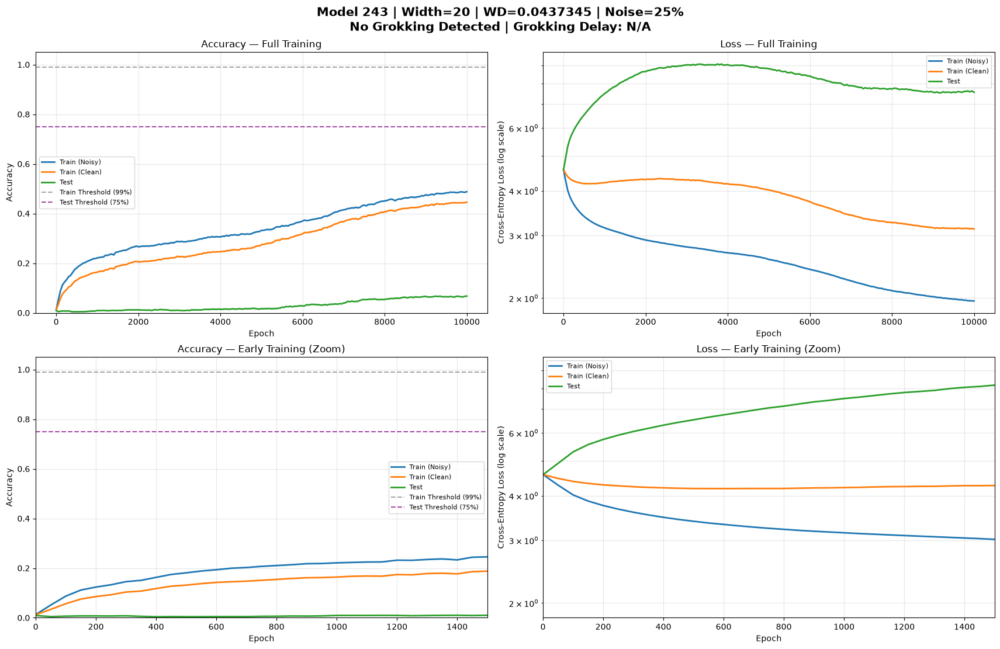

Training Models:  79%|███████▉  | 244/308 [1:14:02<1:39:07, 92.93s/model]


Training Model 244 | Width=32 | WD=0.04373448295773111 | Noise=0%
Model 244 | Epoch   500/10000 | Train: 0.9959 | Test: 0.2090
Model 244 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.8523
Model 244 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.9993
Model 244 | Epoch  2000/10000 | Train: 1.0000 | Test: 1.0000
Model 244 | Epoch  2500/10000 | Train: 1.0000 | Test: 1.0000
Model 244 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 244 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 244 | Epoch  4000/10000 | Train: 1.0000 | Test: 1.0000
Model 244 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 244 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 244 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 244 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 244 | Epoch  6500/10000 | Train: 1.0000 | Test: 1.0000
Model 244 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 244 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 244 | Epoch 

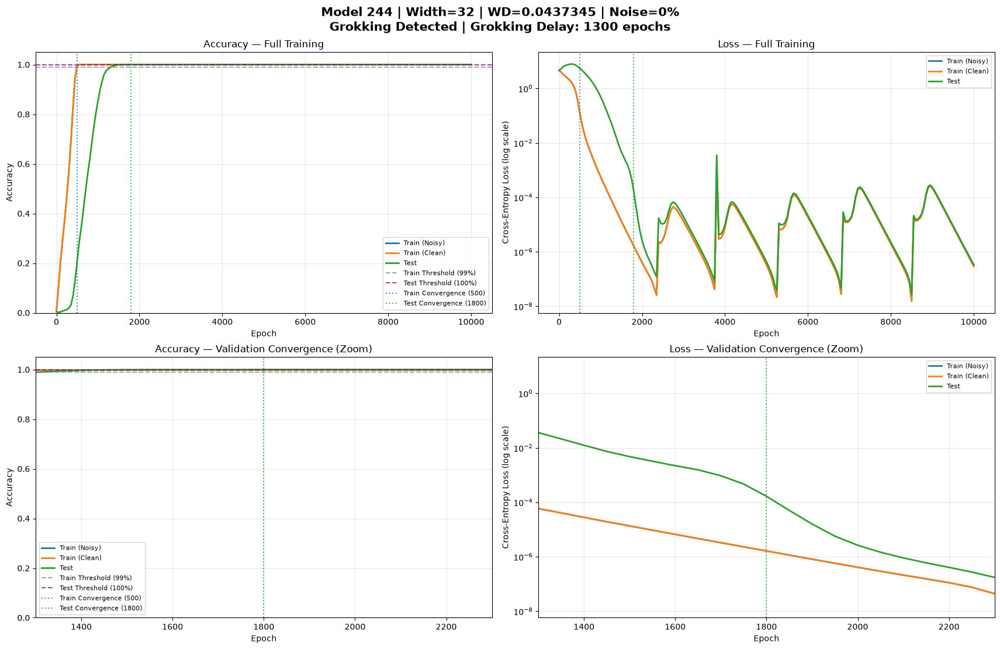

Training Models:  80%|███████▉  | 245/308 [1:15:34<1:37:22, 92.74s/model]


Training Model 245 | Width=32 | WD=0.04373448295773111 | Noise=5%
Model 245 | Epoch   500/10000 | Train: 0.8409 | Test: 0.0418
Model 245 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.1063
Model 245 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.1785
Model 245 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.2462
Model 245 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.3142
Model 245 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.3858
Model 245 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.4499
Model 245 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.5742
Model 245 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.7216
Model 245 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.8147
Model 245 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.8293
Model 245 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.8934
Model 245 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9164
Model 245 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9214
Model 245 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9214
Model 245 | Epoch 

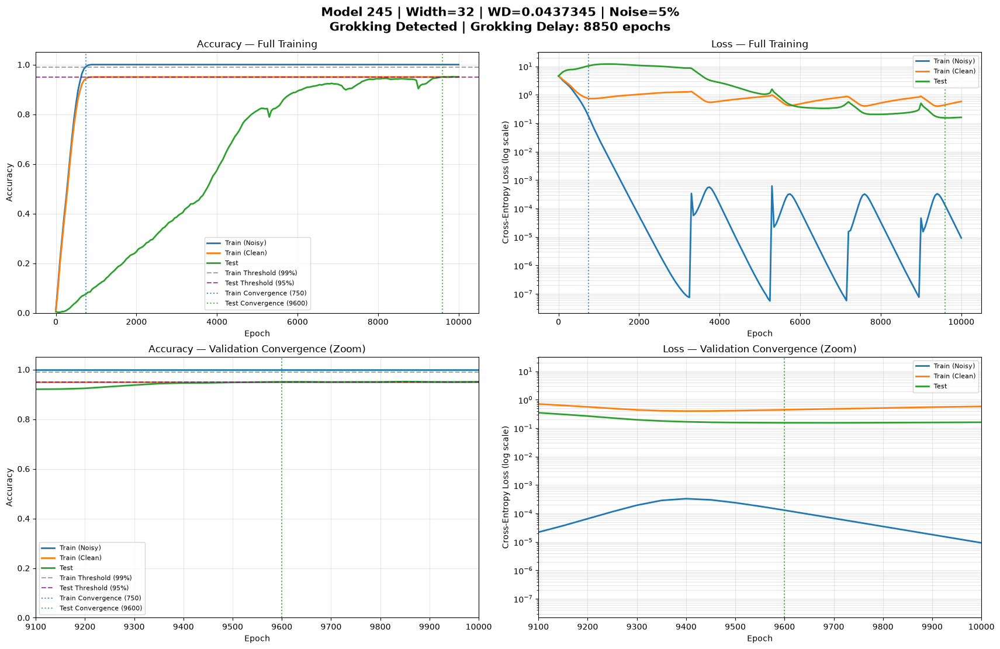

Training Models:  80%|███████▉  | 246/308 [1:17:08<1:36:06, 93.00s/model]


Training Model 246 | Width=32 | WD=0.04373448295773111 | Noise=15%
Model 246 | Epoch   500/10000 | Train: 0.5642 | Test: 0.0124
Model 246 | Epoch  1000/10000 | Train: 0.7206 | Test: 0.0128
Model 246 | Epoch  1500/10000 | Train: 0.8149 | Test: 0.0138
Model 246 | Epoch  2000/10000 | Train: 0.8693 | Test: 0.0145
Model 246 | Epoch  2500/10000 | Train: 0.9053 | Test: 0.0145
Model 246 | Epoch  3000/10000 | Train: 0.9289 | Test: 0.0163
Model 246 | Epoch  3500/10000 | Train: 0.9466 | Test: 0.0163
Model 246 | Epoch  4000/10000 | Train: 0.9590 | Test: 0.0149
Model 246 | Epoch  4500/10000 | Train: 0.9680 | Test: 0.0174
Model 246 | Epoch  5000/10000 | Train: 0.9737 | Test: 0.0191
Model 246 | Epoch  5500/10000 | Train: 0.9789 | Test: 0.0191
Model 246 | Epoch  6000/10000 | Train: 0.9856 | Test: 0.0170
Model 246 | Epoch  6500/10000 | Train: 0.9885 | Test: 0.0191
Model 246 | Epoch  7000/10000 | Train: 0.9918 | Test: 0.0191
Model 246 | Epoch  7500/10000 | Train: 0.9941 | Test: 0.0202
Model 246 | Epoch

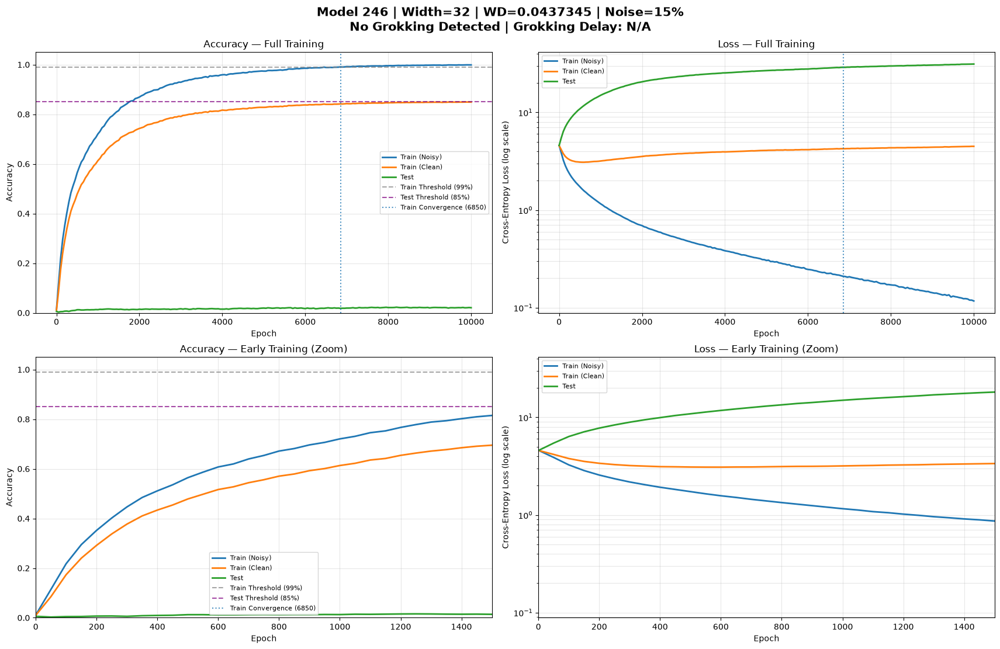

Training Models:  80%|████████  | 247/308 [1:18:41<1:34:28, 92.92s/model]


Training Model 247 | Width=32 | WD=0.04373448295773111 | Noise=25%
Model 247 | Epoch   500/10000 | Train: 0.5422 | Test: 0.0039
Model 247 | Epoch  1000/10000 | Train: 0.6830 | Test: 0.0053
Model 247 | Epoch  1500/10000 | Train: 0.7666 | Test: 0.0064
Model 247 | Epoch  2000/10000 | Train: 0.8119 | Test: 0.0046
Model 247 | Epoch  2500/10000 | Train: 0.8439 | Test: 0.0053
Model 247 | Epoch  3000/10000 | Train: 0.8644 | Test: 0.0057
Model 247 | Epoch  3500/10000 | Train: 0.8860 | Test: 0.0050
Model 247 | Epoch  4000/10000 | Train: 0.8952 | Test: 0.0057
Model 247 | Epoch  4500/10000 | Train: 0.9001 | Test: 0.0050
Model 247 | Epoch  5000/10000 | Train: 0.9089 | Test: 0.0057
Model 247 | Epoch  5500/10000 | Train: 0.9192 | Test: 0.0053
Model 247 | Epoch  6000/10000 | Train: 0.9227 | Test: 0.0053
Model 247 | Epoch  6500/10000 | Train: 0.9279 | Test: 0.0053
Model 247 | Epoch  7000/10000 | Train: 0.9306 | Test: 0.0053
Model 247 | Epoch  7500/10000 | Train: 0.9374 | Test: 0.0050
Model 247 | Epoch

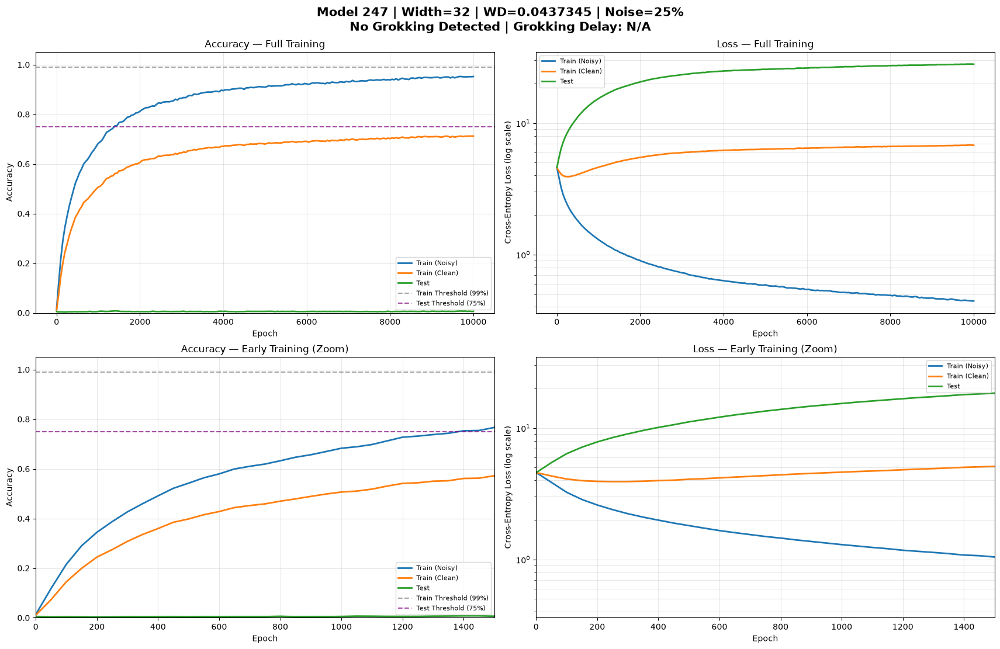

Training Models:  81%|████████  | 248/308 [1:20:14<1:32:54, 92.91s/model]


Training Model 248 | Width=64 | WD=0.04373448295773111 | Noise=0%
Model 248 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0521
Model 248 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.3206
Model 248 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.9578
Model 248 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.9975
Model 248 | Epoch  2500/10000 | Train: 1.0000 | Test: 1.0000
Model 248 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 248 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 248 | Epoch  4000/10000 | Train: 1.0000 | Test: 1.0000
Model 248 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 248 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 248 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 248 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 248 | Epoch  6500/10000 | Train: 1.0000 | Test: 1.0000
Model 248 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 248 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 248 | Epoch 

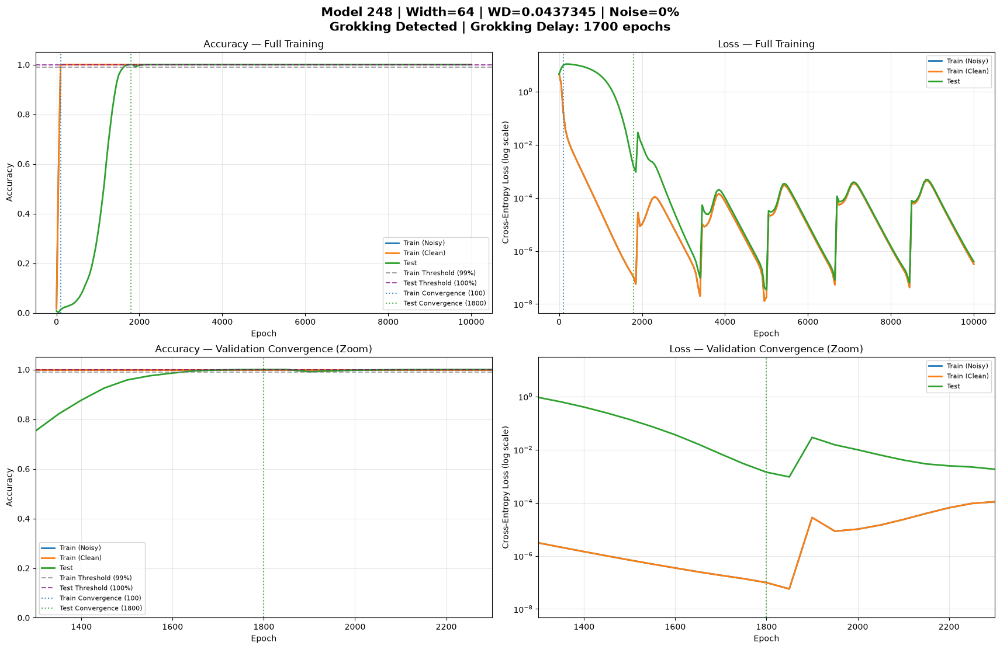

Training Models:  81%|████████  | 249/308 [1:21:47<1:31:26, 93.00s/model]


Training Model 249 | Width=64 | WD=0.04373448295773111 | Noise=5%
Model 249 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0103
Model 249 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0262
Model 249 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0549
Model 249 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.1141
Model 249 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.2012
Model 249 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.4789
Model 249 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.7471
Model 249 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.8268
Model 249 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9242
Model 249 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9493
Model 249 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9543
Model 249 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9685
Model 249 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9795
Model 249 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9816
Model 249 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9805
Model 249 | Epoch 

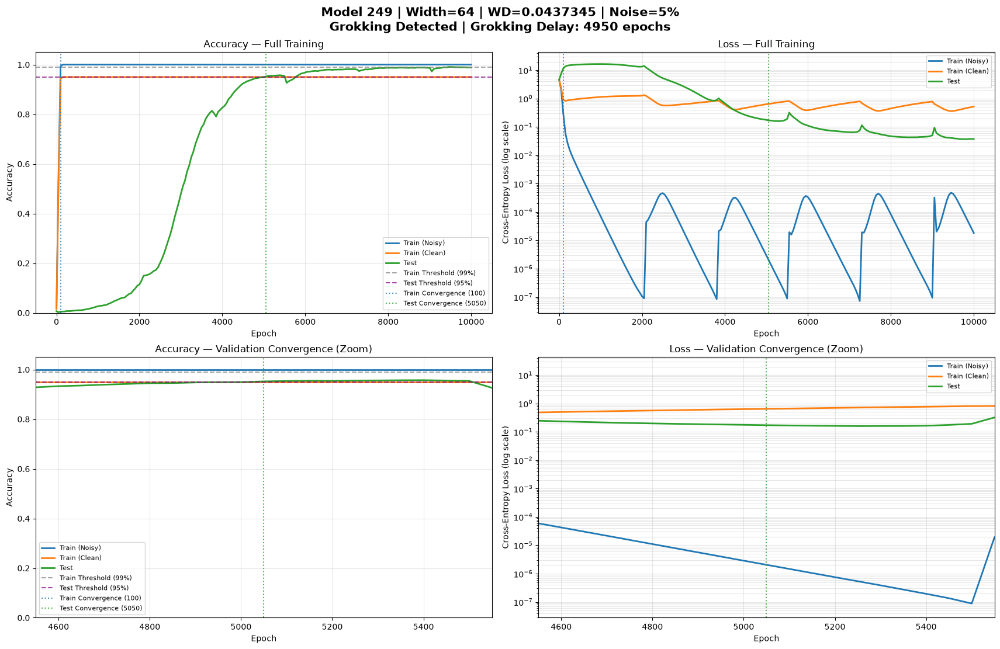

Training Models:  81%|████████  | 250/308 [1:23:21<1:30:12, 93.32s/model]


Training Model 250 | Width=64 | WD=0.04373448295773111 | Noise=15%
Model 250 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0021
Model 250 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0028
Model 250 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0043
Model 250 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0064
Model 250 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0071
Model 250 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.0124
Model 250 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.0227
Model 250 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.0305
Model 250 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.0414
Model 250 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.0708
Model 250 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.1169
Model 250 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.1477
Model 250 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.2108
Model 250 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.2869
Model 250 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.3468
Model 250 | Epoch

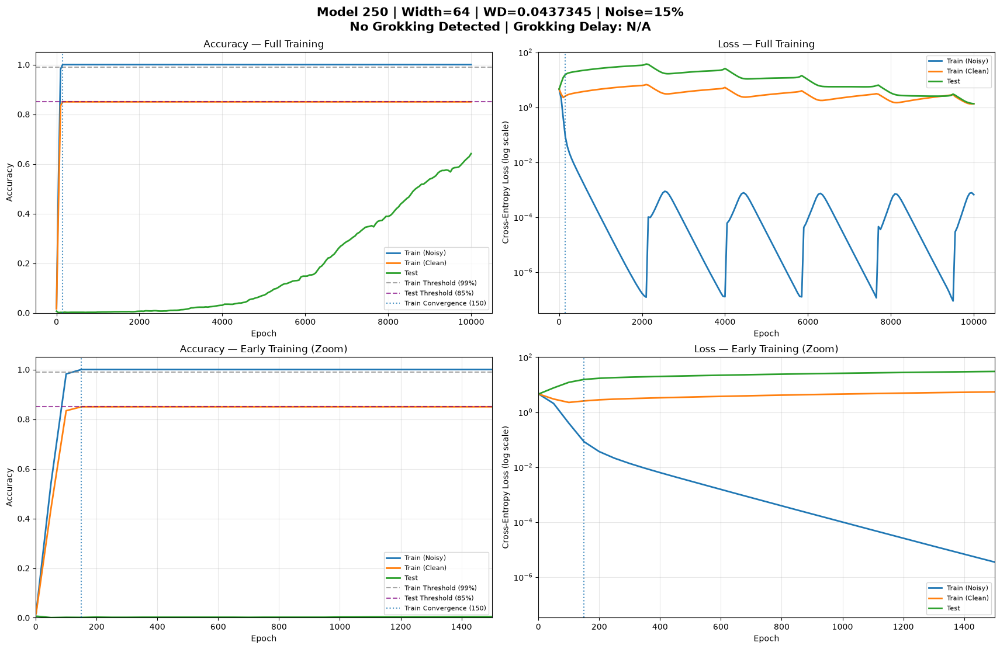

Training Models:  81%|████████▏ | 251/308 [1:24:54<1:28:43, 93.39s/model]


Training Model 251 | Width=64 | WD=0.04373448295773111 | Noise=25%
Model 251 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0043
Model 251 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0053
Model 251 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0046
Model 251 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0039
Model 251 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0053
Model 251 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.0039
Model 251 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.0039
Model 251 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.0039
Model 251 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.0032
Model 251 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.0043
Model 251 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.0053
Model 251 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.0053
Model 251 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.0078
Model 251 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.0085
Model 251 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.0124
Model 251 | Epoch

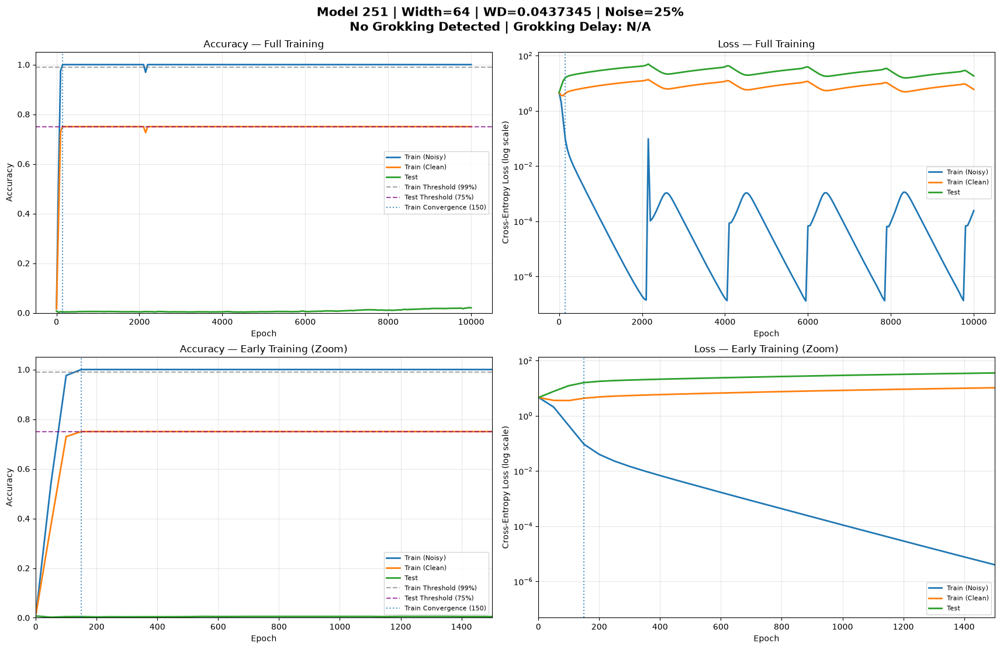

Training Models:  82%|████████▏ | 252/308 [1:26:28<1:27:20, 93.58s/model]


Training Model 252 | Width=128 | WD=0.04373448295773111 | Noise=0%
Model 252 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0099
Model 252 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.1389
Model 252 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.8332
Model 252 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.9887
Model 252 | Epoch  2500/10000 | Train: 1.0000 | Test: 1.0000
Model 252 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 252 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 252 | Epoch  4000/10000 | Train: 1.0000 | Test: 1.0000
Model 252 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 252 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 252 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 252 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 252 | Epoch  6500/10000 | Train: 1.0000 | Test: 1.0000
Model 252 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 252 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 252 | Epoch

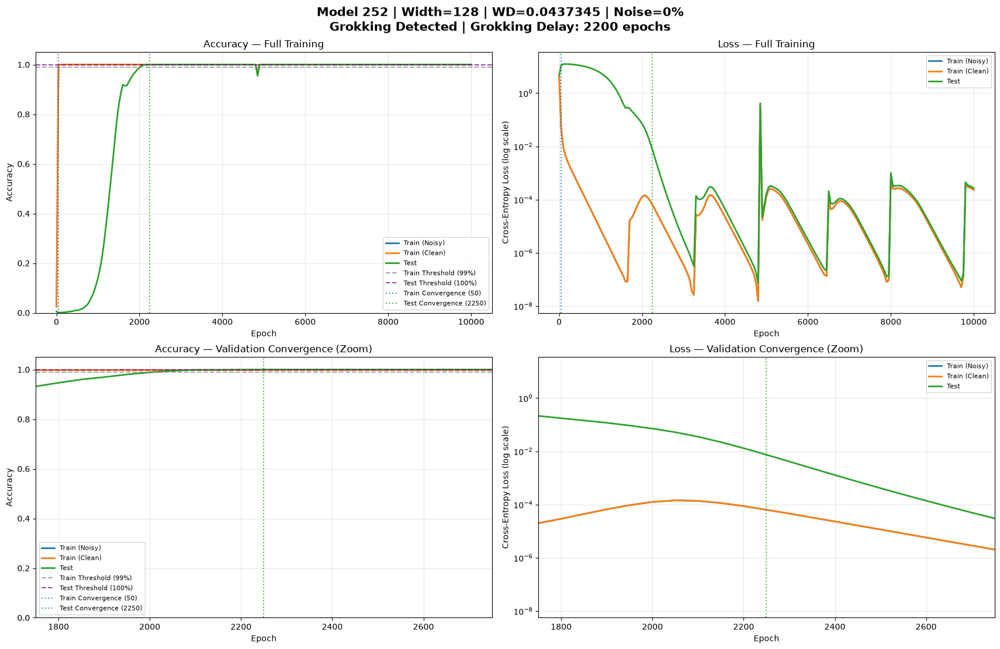

Training Models:  82%|████████▏ | 253/308 [1:28:03<1:26:07, 93.96s/model]


Training Model 253 | Width=128 | WD=0.04373448295773111 | Noise=5%
Model 253 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0035
Model 253 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0553
Model 253 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.3585
Model 253 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.6773
Model 253 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.9497
Model 253 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.9883
Model 253 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.9798
Model 253 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9954
Model 253 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9968
Model 253 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9965
Model 253 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9986
Model 253 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9982
Model 253 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9979
Model 253 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9975
Model 253 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9989
Model 253 | Epoch

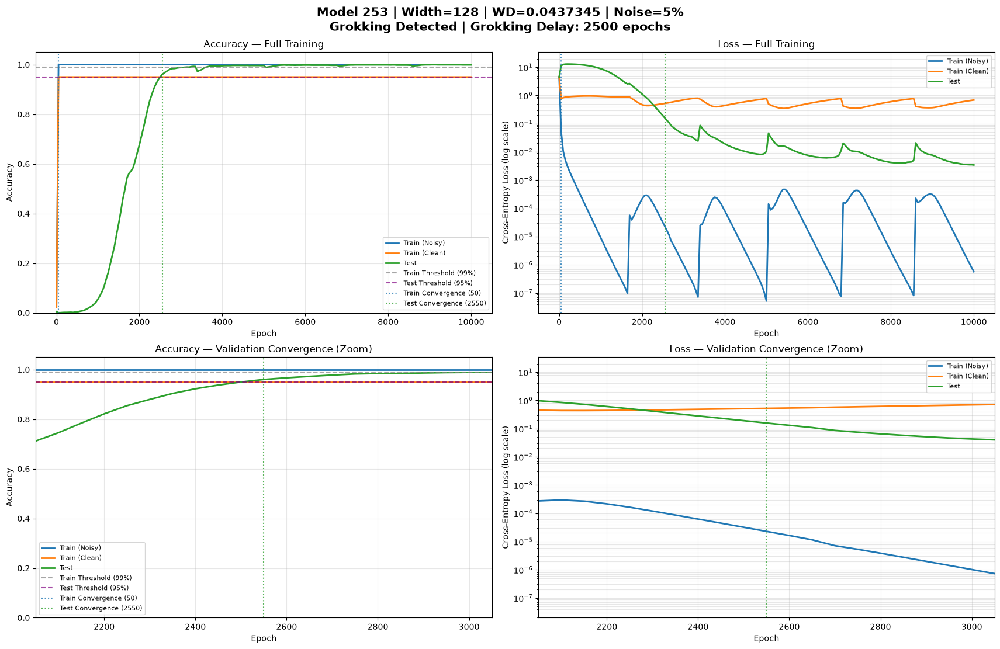

Training Models:  82%|████████▏ | 254/308 [1:29:39<1:25:03, 94.51s/model]


Training Model 254 | Width=128 | WD=0.04373448295773111 | Noise=15%
Model 254 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0028
Model 254 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0060
Model 254 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0188
Model 254 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0365
Model 254 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0783
Model 254 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.1856
Model 254 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.3309
Model 254 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.4548
Model 254 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.6043
Model 254 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.6982
Model 254 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.7520
Model 254 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.8236
Model 254 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.8604
Model 254 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.8827
Model 254 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9104
Model 254 | Epoc

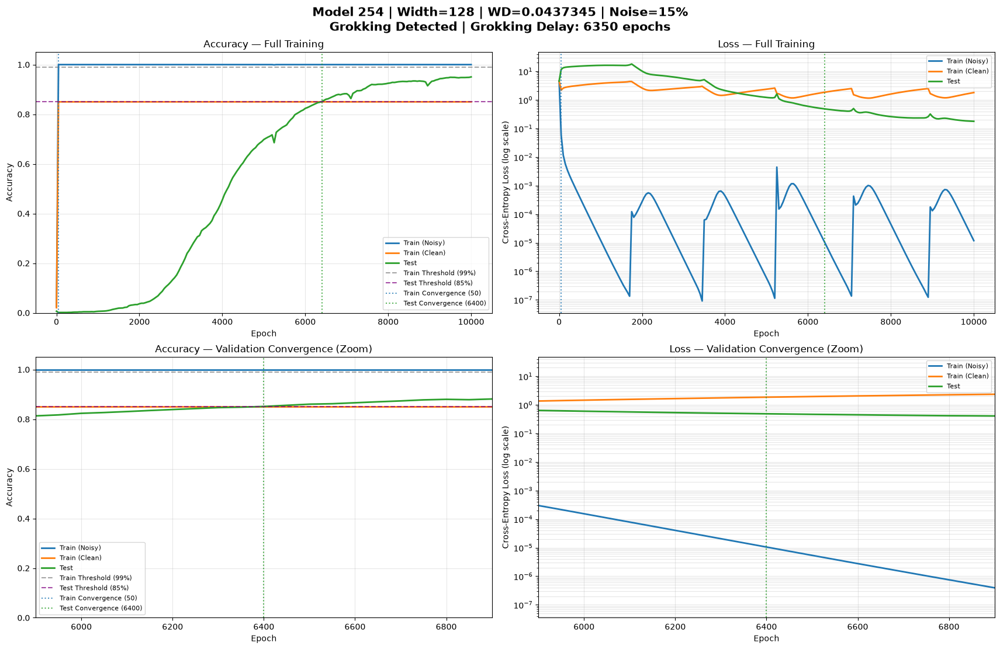

Training Models:  83%|████████▎ | 255/308 [1:31:14<1:23:39, 94.70s/model]


Training Model 255 | Width=128 | WD=0.04373448295773111 | Noise=25%
Model 255 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0011
Model 255 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0018
Model 255 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0025
Model 255 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0043
Model 255 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0053
Model 255 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.0085
Model 255 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.0128
Model 255 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.0202
Model 255 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.0461
Model 255 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.0747
Model 255 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.1123
Model 255 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.1530
Model 255 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.2118
Model 255 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.2660
Model 255 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.3206
Model 255 | Epoc

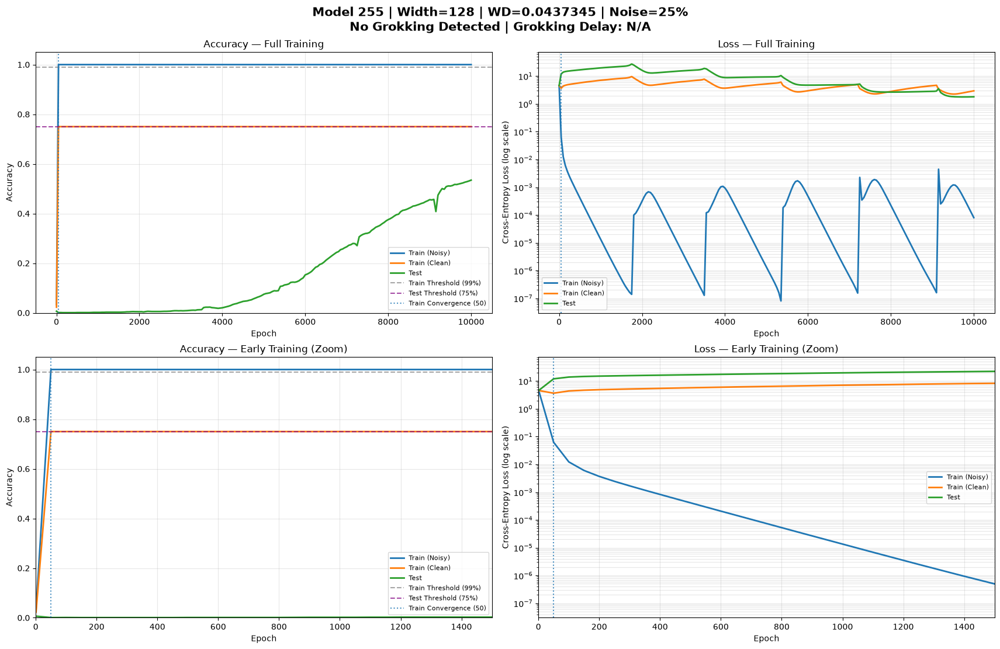

Training Models:  83%|████████▎ | 256/308 [1:32:49<1:22:13, 94.88s/model]


Training Model 256 | Width=256 | WD=0.04373448295773111 | Noise=0%
Model 256 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0687
Model 256 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.8310
Model 256 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.9894
Model 256 | Epoch  2000/10000 | Train: 1.0000 | Test: 1.0000
Model 256 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.9972
Model 256 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 256 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 256 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9996
Model 256 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 256 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 256 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 256 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 256 | Epoch  6500/10000 | Train: 1.0000 | Test: 1.0000
Model 256 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 256 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 256 | Epoch

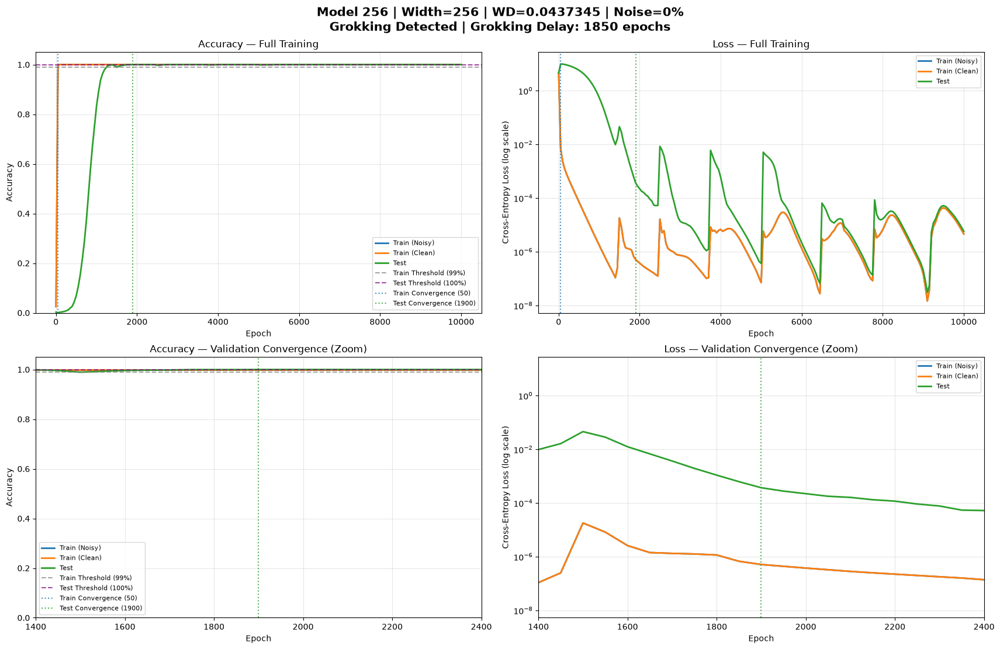

Training Models:  83%|████████▎ | 257/308 [1:34:23<1:20:22, 94.56s/model]


Training Model 257 | Width=256 | WD=0.04373448295773111 | Noise=5%
Model 257 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0128
Model 257 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.2118
Model 257 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.7697
Model 257 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.8778
Model 257 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.8339
Model 257 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.8675
Model 257 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.9897
Model 257 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9972
Model 257 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9663
Model 257 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9982
Model 257 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9996
Model 257 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 257 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9975
Model 257 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9996
Model 257 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9996
Model 257 | Epoch

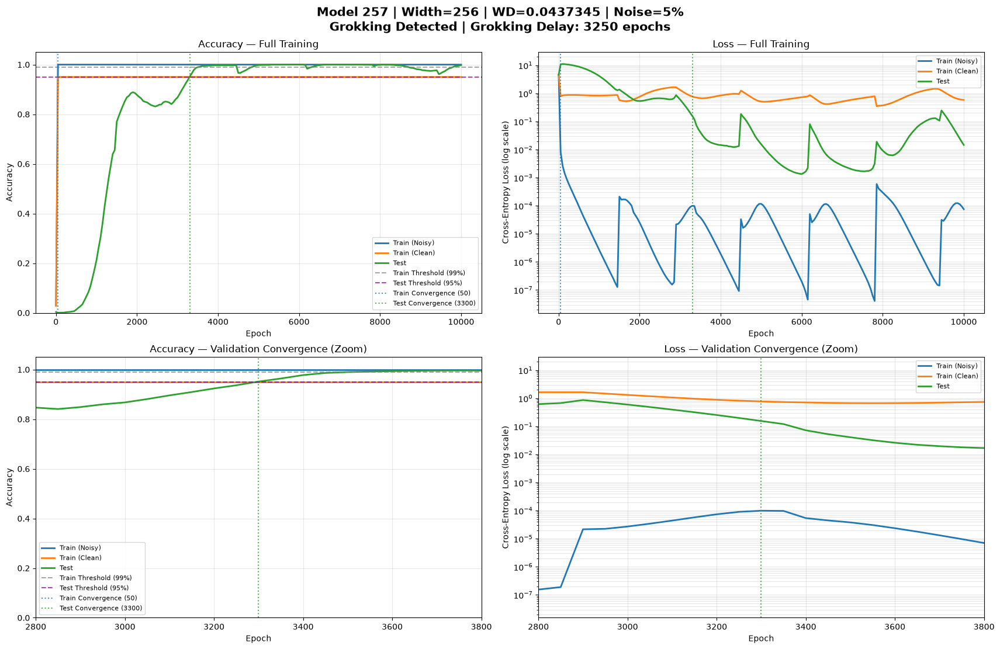

Training Models:  84%|████████▍ | 258/308 [1:35:57<1:18:42, 94.45s/model]


Training Model 258 | Width=256 | WD=0.04373448295773111 | Noise=15%
Model 258 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0050
Model 258 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0195
Model 258 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0684
Model 258 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.2664
Model 258 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.2434
Model 258 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.4145
Model 258 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.6157
Model 258 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.8434
Model 258 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9132
Model 258 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9199
Model 258 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9550
Model 258 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9628
Model 258 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9593
Model 258 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9766
Model 258 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9816
Model 258 | Epoc

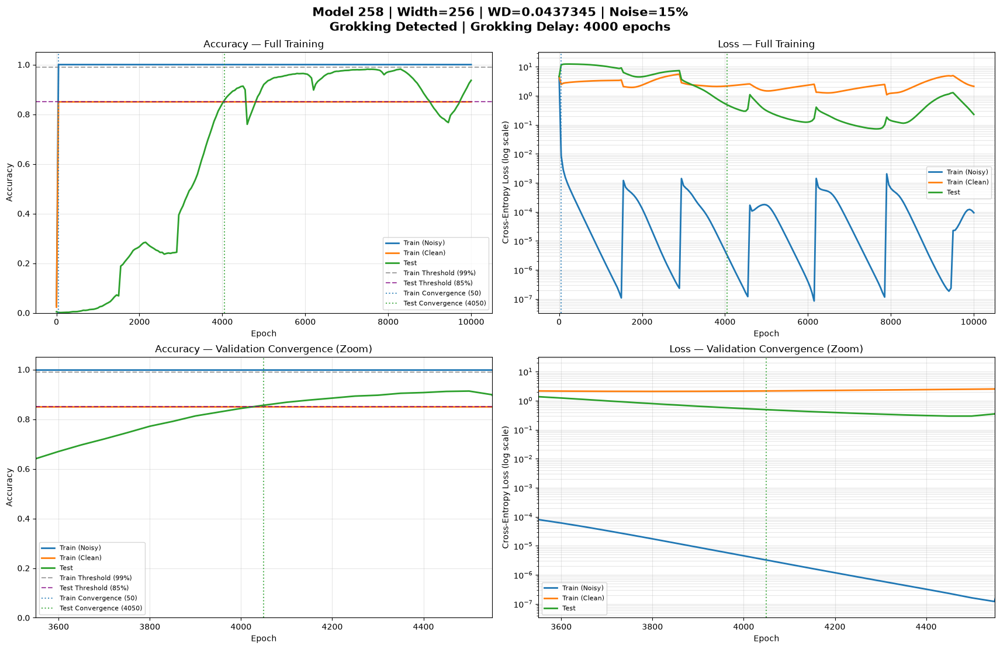

Training Models:  84%|████████▍ | 259/308 [1:37:32<1:17:03, 94.36s/model]


Training Model 259 | Width=256 | WD=0.04373448295773111 | Noise=25%
Model 259 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0014
Model 259 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0025
Model 259 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0064
Model 259 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0273
Model 259 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0305
Model 259 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.0772
Model 259 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.1442
Model 259 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.2278
Model 259 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.3252
Model 259 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.3450
Model 259 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.3585
Model 259 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.3872
Model 259 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.4648
Model 259 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.5657
Model 259 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.6394
Model 259 | Epoc

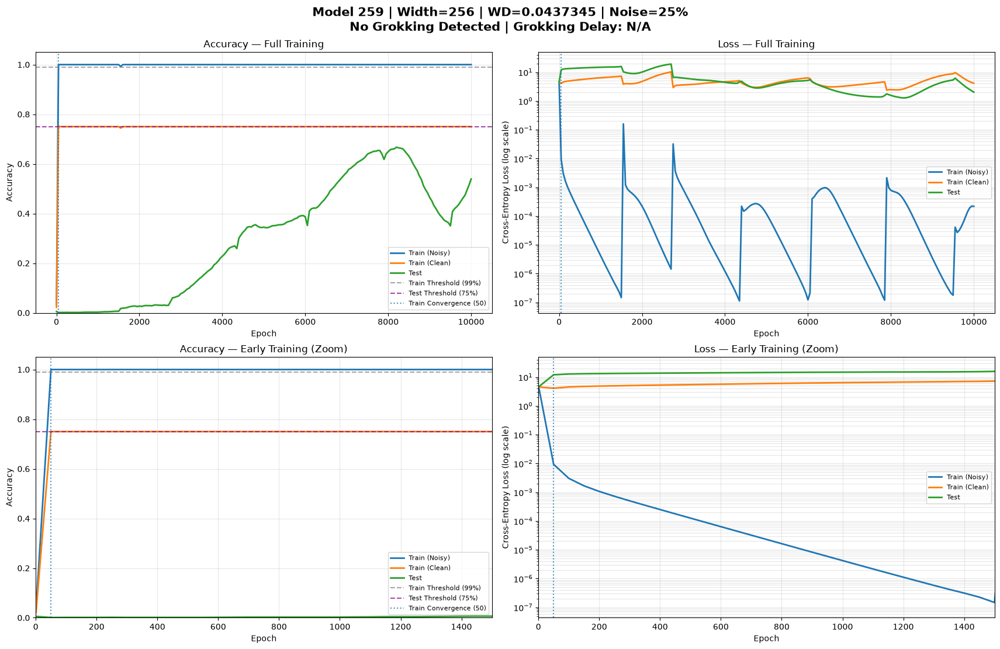

Training Models:  84%|████████▍ | 260/308 [1:39:06<1:15:25, 94.28s/model]


Training Model 260 | Width=512 | WD=0.04373448295773111 | Noise=0%
Model 260 | Epoch   500/10000 | Train: 1.0000 | Test: 0.1668
Model 260 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.9607
Model 260 | Epoch  1500/10000 | Train: 1.0000 | Test: 1.0000
Model 260 | Epoch  2000/10000 | Train: 1.0000 | Test: 1.0000
Model 260 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.9996
Model 260 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 260 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 260 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9929
Model 260 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 260 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 260 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 260 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 260 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9986
Model 260 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 260 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 260 | Epoch

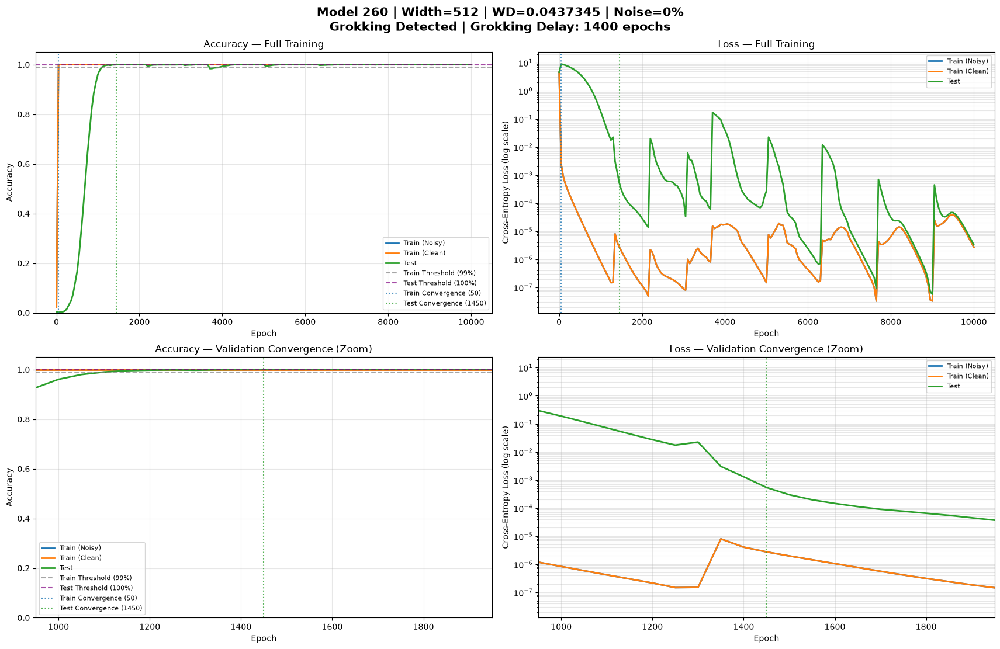

Training Models:  85%|████████▍ | 261/308 [1:41:50<1:30:16, 115.23s/model]


Training Model 261 | Width=512 | WD=0.04373448295773111 | Noise=5%
Model 261 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0740
Model 261 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.6121
Model 261 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.9235
Model 261 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.7829
Model 261 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.6674
Model 261 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.9281
Model 261 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.9777
Model 261 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9940
Model 261 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9890
Model 261 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9968
Model 261 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9940
Model 261 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9947
Model 261 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9947
Model 261 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9943
Model 261 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9936
Model 261 | Epoch

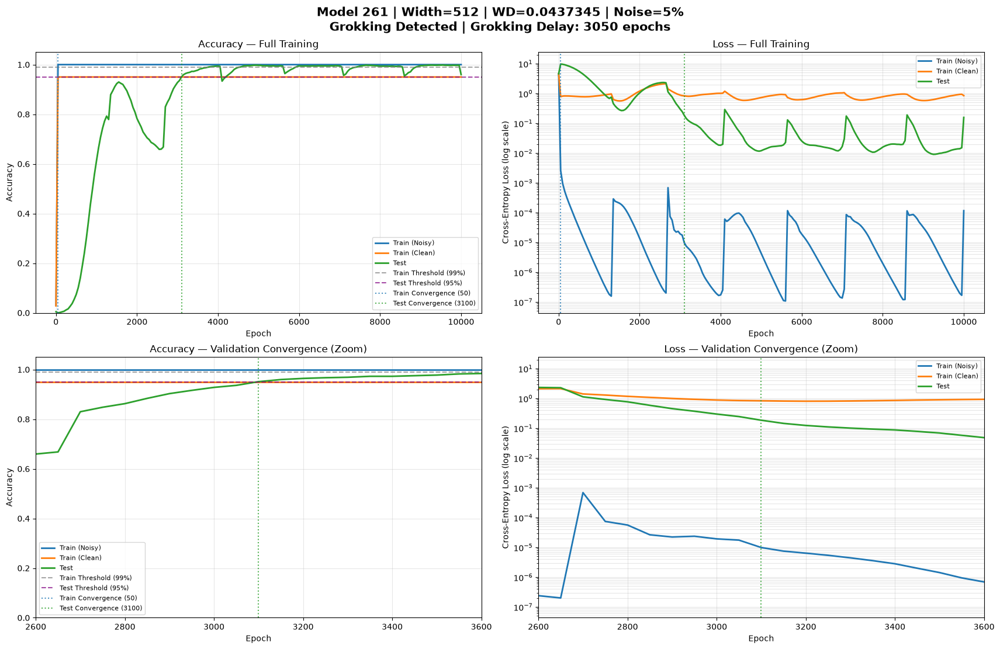

Training Models:  85%|████████▌ | 262/308 [1:44:34<1:39:34, 129.87s/model]


Training Model 262 | Width=512 | WD=0.04373448295773111 | Noise=15%
Model 262 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0053
Model 262 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0510
Model 262 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.4045
Model 262 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.2618
Model 262 | Epoch  2500/10000 | Train: 0.4841 | Test: 0.1679
Model 262 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.6915
Model 262 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.7177
Model 262 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.7117
Model 262 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.8526
Model 262 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.8895
Model 262 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.7949
Model 262 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.8898
Model 262 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.8165
Model 262 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.8190
Model 262 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.8215
Model 262 | Epoc

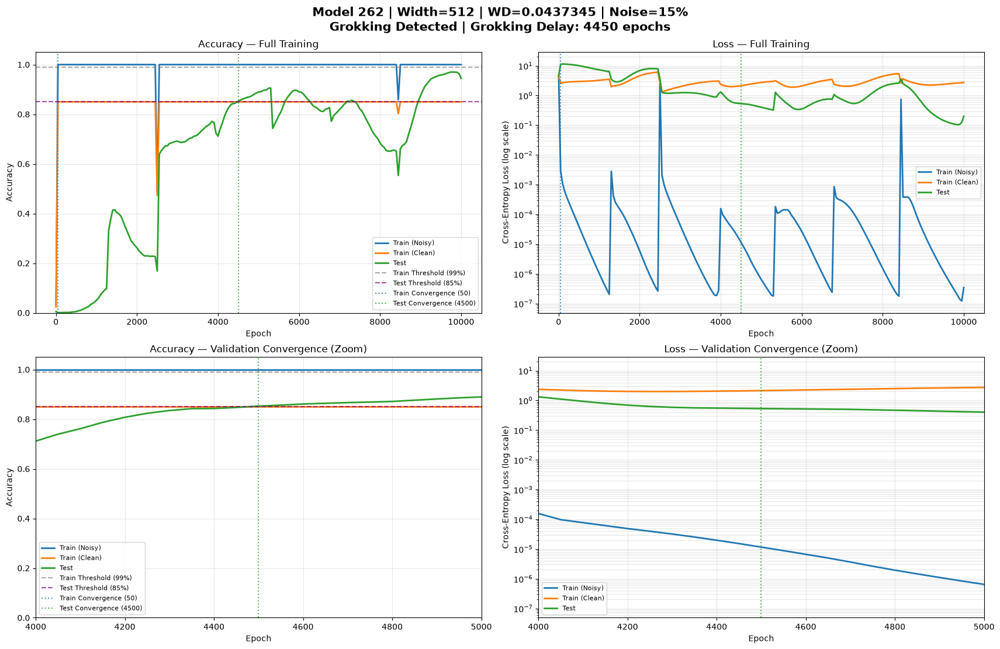

Training Models:  85%|████████▌ | 263/308 [1:47:18<1:45:08, 140.18s/model]


Training Model 263 | Width=512 | WD=0.04373448295773111 | Noise=25%
Model 263 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0025
Model 263 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0092
Model 263 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0436
Model 263 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.1364
Model 263 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.1637
Model 263 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.1516
Model 263 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.2483
Model 263 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.2136
Model 263 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.1927
Model 263 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.5275
Model 263 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.6135
Model 263 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.6316
Model 263 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.5997
Model 263 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.5937
Model 263 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.6482
Model 263 | Epoc

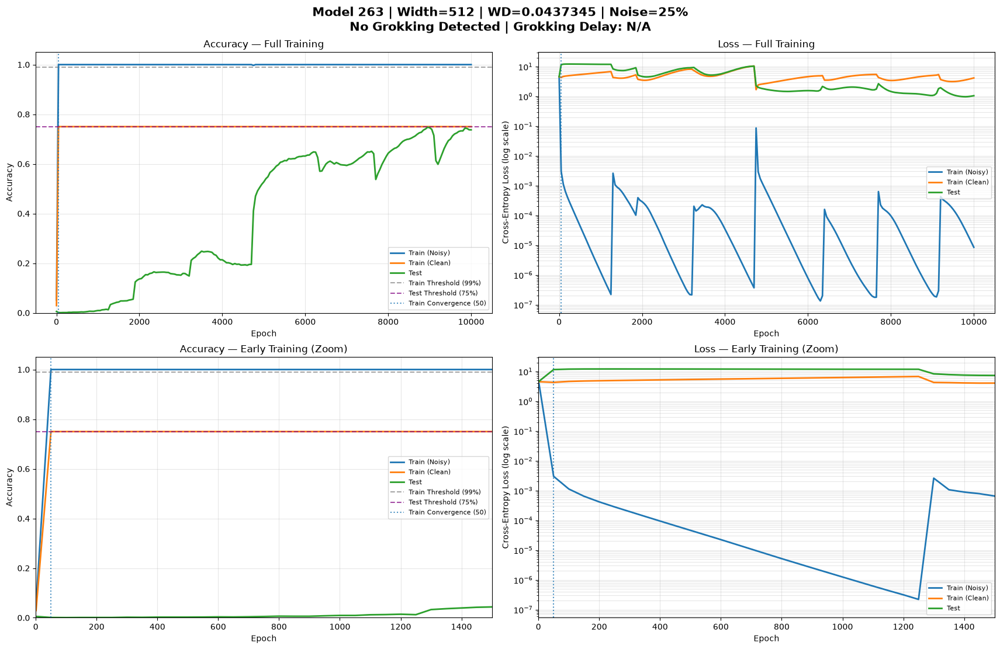

Training Models:  86%|████████▌ | 264/308 [1:50:02<1:48:02, 147.34s/model]


Training Model 264 | Width=2 | WD=0.2 | Noise=0%
Model 264 | Epoch   500/10000 | Train: 0.0316 | Test: 0.0191
Model 264 | Epoch  1000/10000 | Train: 0.0404 | Test: 0.0216
Model 264 | Epoch  1500/10000 | Train: 0.0372 | Test: 0.0184
Model 264 | Epoch  2000/10000 | Train: 0.0425 | Test: 0.0227
Model 264 | Epoch  2500/10000 | Train: 0.0389 | Test: 0.0237
Model 264 | Epoch  3000/10000 | Train: 0.0377 | Test: 0.0223
Model 264 | Epoch  3500/10000 | Train: 0.0443 | Test: 0.0276
Model 264 | Epoch  4000/10000 | Train: 0.0477 | Test: 0.0329
Model 264 | Epoch  4500/10000 | Train: 0.0469 | Test: 0.0337
Model 264 | Epoch  5000/10000 | Train: 0.0536 | Test: 0.0361
Model 264 | Epoch  5500/10000 | Train: 0.0645 | Test: 0.0436
Model 264 | Epoch  6000/10000 | Train: 0.0645 | Test: 0.0453
Model 264 | Epoch  6500/10000 | Train: 0.0662 | Test: 0.0468
Model 264 | Epoch  7000/10000 | Train: 0.0711 | Test: 0.0496
Model 264 | Epoch  7500/10000 | Train: 0.0782 | Test: 0.0549
Model 264 | Epoch  8000/10000 | Tra

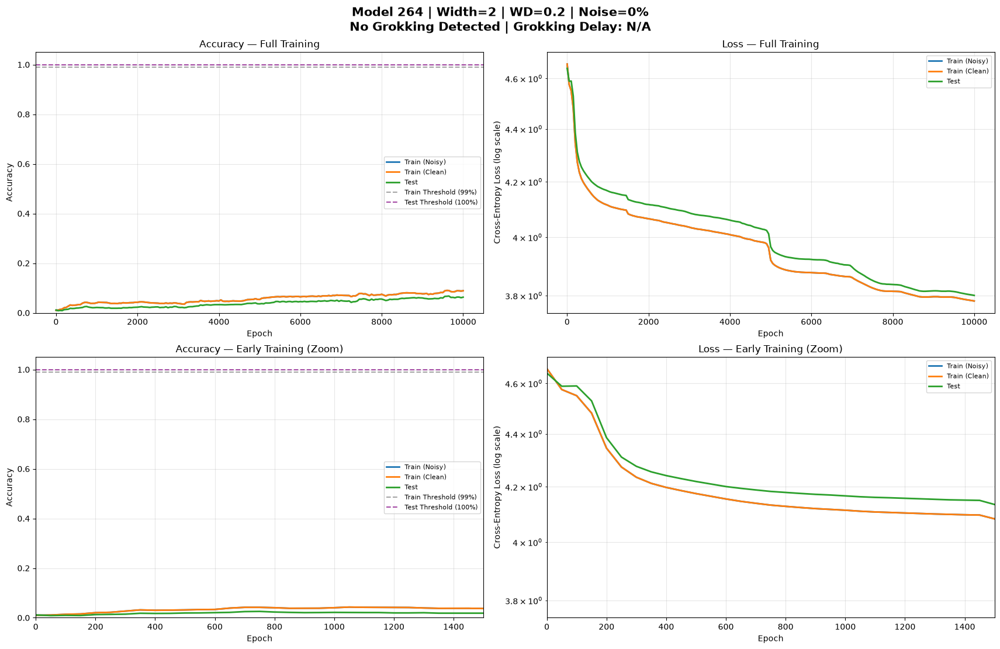

Training Models:  86%|████████▌ | 265/308 [1:51:36<1:33:59, 131.15s/model]


Training Model 265 | Width=2 | WD=0.2 | Noise=5%
Model 265 | Epoch   500/10000 | Train: 0.0380 | Test: 0.0276
Model 265 | Epoch  1000/10000 | Train: 0.0565 | Test: 0.0386
Model 265 | Epoch  1500/10000 | Train: 0.0582 | Test: 0.0397
Model 265 | Epoch  2000/10000 | Train: 0.0597 | Test: 0.0411
Model 265 | Epoch  2500/10000 | Train: 0.0586 | Test: 0.0422
Model 265 | Epoch  3000/10000 | Train: 0.0618 | Test: 0.0425
Model 265 | Epoch  3500/10000 | Train: 0.0603 | Test: 0.0436
Model 265 | Epoch  4000/10000 | Train: 0.0615 | Test: 0.0439
Model 265 | Epoch  4500/10000 | Train: 0.0641 | Test: 0.0450
Model 265 | Epoch  5000/10000 | Train: 0.0612 | Test: 0.0443
Model 265 | Epoch  5500/10000 | Train: 0.0630 | Test: 0.0443
Model 265 | Epoch  6000/10000 | Train: 0.0662 | Test: 0.0461
Model 265 | Epoch  6500/10000 | Train: 0.0621 | Test: 0.0443
Model 265 | Epoch  7000/10000 | Train: 0.0621 | Test: 0.0425
Model 265 | Epoch  7500/10000 | Train: 0.0629 | Test: 0.0446
Model 265 | Epoch  8000/10000 | Tra

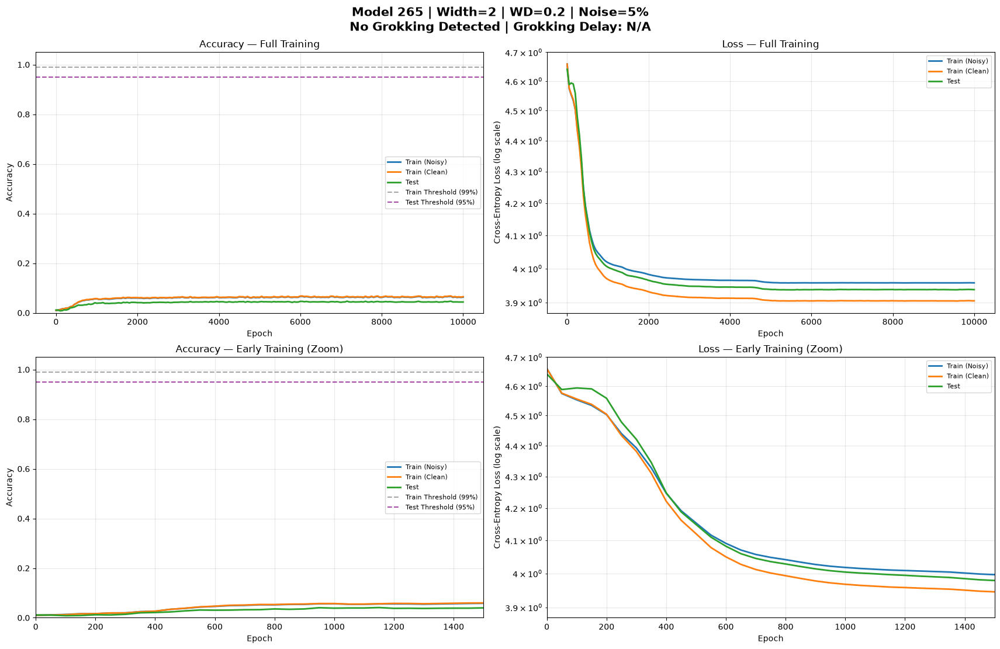

Training Models:  86%|████████▋ | 266/308 [1:53:09<1:23:54, 119.86s/model]


Training Model 266 | Width=2 | WD=0.2 | Noise=15%
Model 266 | Epoch   500/10000 | Train: 0.0328 | Test: 0.0227
Model 266 | Epoch  1000/10000 | Train: 0.0486 | Test: 0.0368
Model 266 | Epoch  1500/10000 | Train: 0.0846 | Test: 0.0712
Model 266 | Epoch  2000/10000 | Train: 0.0913 | Test: 0.0701
Model 266 | Epoch  2500/10000 | Train: 0.0943 | Test: 0.0783
Model 266 | Epoch  3000/10000 | Train: 0.0958 | Test: 0.0747
Model 266 | Epoch  3500/10000 | Train: 0.1005 | Test: 0.0772
Model 266 | Epoch  4000/10000 | Train: 0.1023 | Test: 0.0829
Model 266 | Epoch  4500/10000 | Train: 0.1022 | Test: 0.0861
Model 266 | Epoch  5000/10000 | Train: 0.0998 | Test: 0.0840
Model 266 | Epoch  5500/10000 | Train: 0.0985 | Test: 0.0811
Model 266 | Epoch  6000/10000 | Train: 0.0990 | Test: 0.0832
Model 266 | Epoch  6500/10000 | Train: 0.0978 | Test: 0.0850
Model 266 | Epoch  7000/10000 | Train: 0.0973 | Test: 0.0843
Model 266 | Epoch  7500/10000 | Train: 0.0975 | Test: 0.0832
Model 266 | Epoch  8000/10000 | Tr

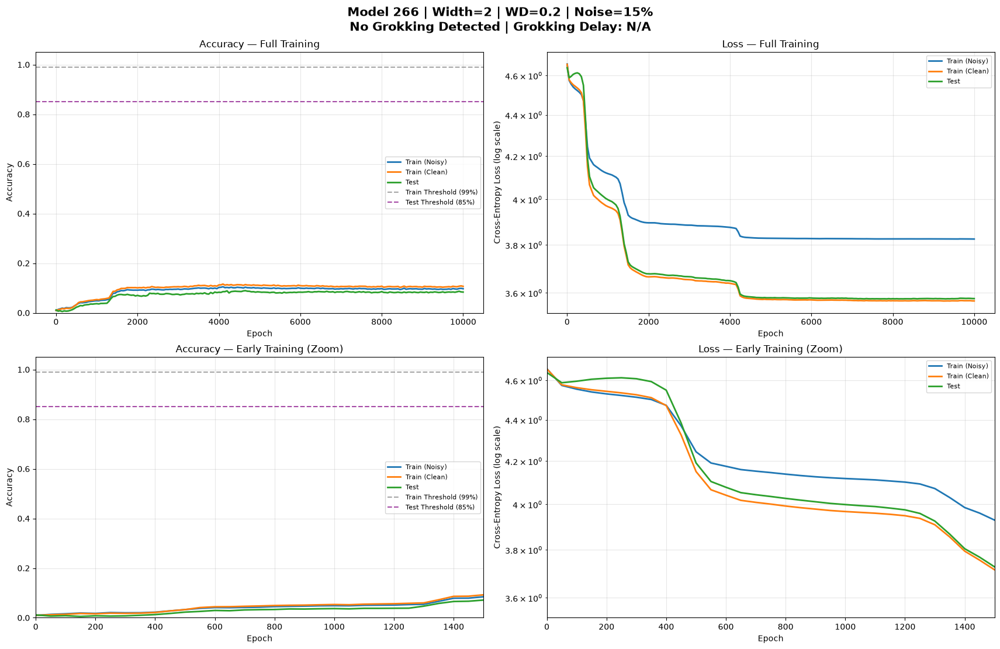

Training Models:  87%|████████▋ | 267/308 [1:54:43<1:16:30, 111.96s/model]


Training Model 267 | Width=2 | WD=0.2 | Noise=25%
Model 267 | Epoch   500/10000 | Train: 0.0196 | Test: 0.0103
Model 267 | Epoch  1000/10000 | Train: 0.0226 | Test: 0.0142
Model 267 | Epoch  1500/10000 | Train: 0.0284 | Test: 0.0213
Model 267 | Epoch  2000/10000 | Train: 0.0295 | Test: 0.0273
Model 267 | Epoch  2500/10000 | Train: 0.0292 | Test: 0.0262
Model 267 | Epoch  3000/10000 | Train: 0.0384 | Test: 0.0308
Model 267 | Epoch  3500/10000 | Train: 0.0383 | Test: 0.0351
Model 267 | Epoch  4000/10000 | Train: 0.0415 | Test: 0.0393
Model 267 | Epoch  4500/10000 | Train: 0.0416 | Test: 0.0379
Model 267 | Epoch  5000/10000 | Train: 0.0407 | Test: 0.0358
Model 267 | Epoch  5500/10000 | Train: 0.0404 | Test: 0.0361
Model 267 | Epoch  6000/10000 | Train: 0.0401 | Test: 0.0361
Model 267 | Epoch  6500/10000 | Train: 0.0407 | Test: 0.0358
Model 267 | Epoch  7000/10000 | Train: 0.0399 | Test: 0.0354
Model 267 | Epoch  7500/10000 | Train: 0.0398 | Test: 0.0368
Model 267 | Epoch  8000/10000 | Tr

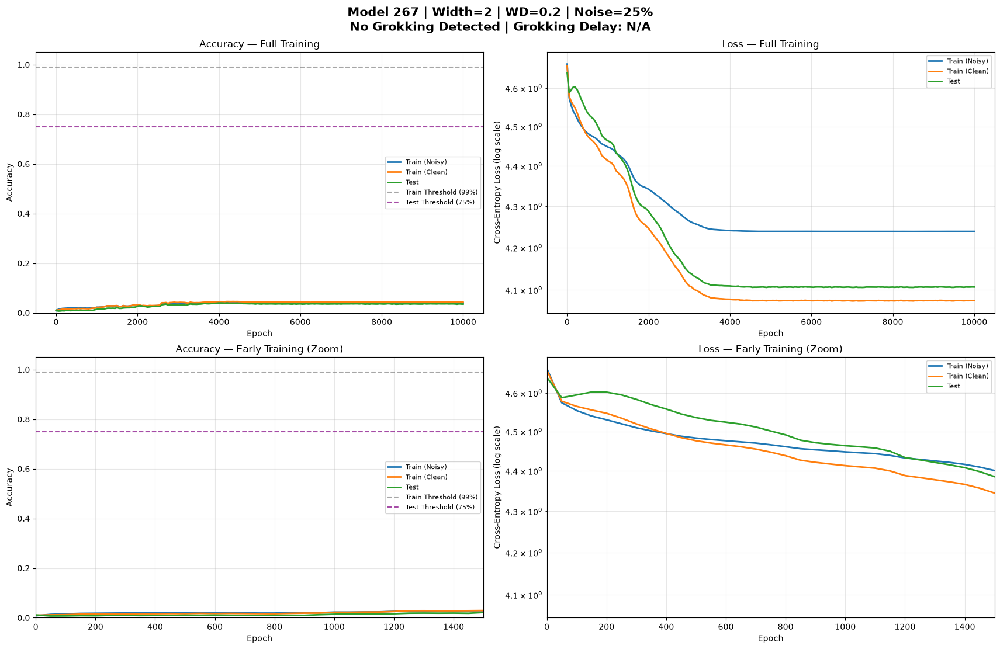

Training Models:  87%|████████▋ | 268/308 [1:56:17<1:11:04, 106.61s/model]


Training Model 268 | Width=4 | WD=0.2 | Noise=0%
Model 268 | Epoch   500/10000 | Train: 0.5597 | Test: 0.4694
Model 268 | Epoch  1000/10000 | Train: 0.7725 | Test: 0.7425
Model 268 | Epoch  1500/10000 | Train: 0.7724 | Test: 0.7279
Model 268 | Epoch  2000/10000 | Train: 0.7074 | Test: 0.6518
Model 268 | Epoch  2500/10000 | Train: 0.7033 | Test: 0.6468
Model 268 | Epoch  3000/10000 | Train: 0.7153 | Test: 0.6546
Model 268 | Epoch  3500/10000 | Train: 0.6195 | Test: 0.5707
Model 268 | Epoch  4000/10000 | Train: 0.6676 | Test: 0.6188
Model 268 | Epoch  4500/10000 | Train: 0.6392 | Test: 0.5923
Model 268 | Epoch  5000/10000 | Train: 0.6869 | Test: 0.6376
Model 268 | Epoch  5500/10000 | Train: 0.6650 | Test: 0.6192
Model 268 | Epoch  6000/10000 | Train: 0.6602 | Test: 0.6047
Model 268 | Epoch  6500/10000 | Train: 0.6476 | Test: 0.5948
Model 268 | Epoch  7000/10000 | Train: 0.6975 | Test: 0.6550
Model 268 | Epoch  7500/10000 | Train: 0.7161 | Test: 0.6741
Model 268 | Epoch  8000/10000 | Tra

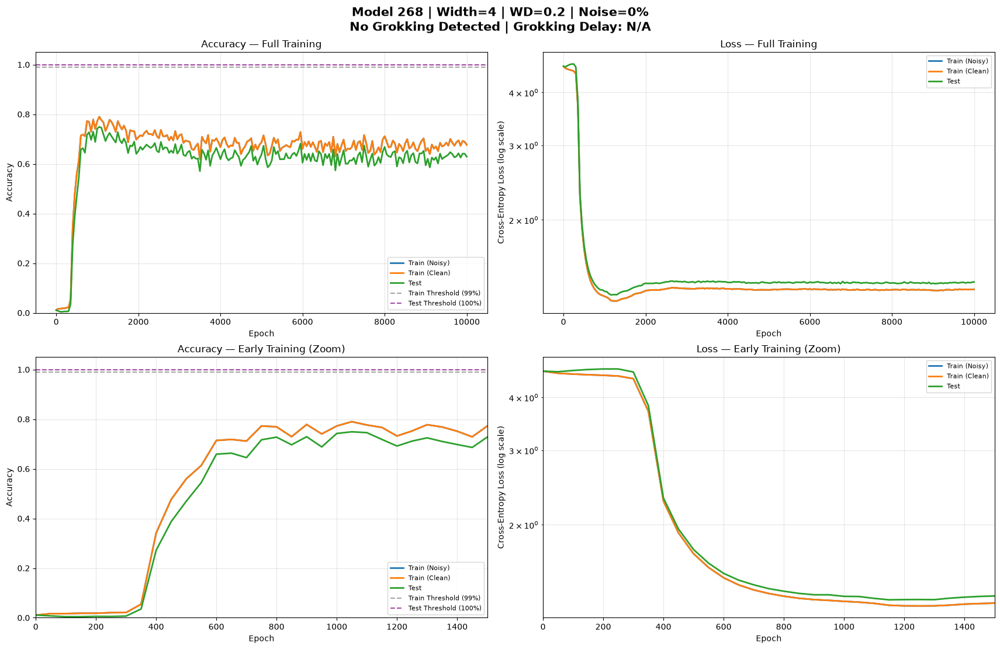

Training Models:  87%|████████▋ | 269/308 [1:57:52<1:07:01, 103.11s/model]


Training Model 269 | Width=4 | WD=0.2 | Noise=5%
Model 269 | Epoch   500/10000 | Train: 0.0657 | Test: 0.0499
Model 269 | Epoch  1000/10000 | Train: 0.2634 | Test: 0.2140
Model 269 | Epoch  1500/10000 | Train: 0.2804 | Test: 0.2274
Model 269 | Epoch  2000/10000 | Train: 0.2823 | Test: 0.2366
Model 269 | Epoch  2500/10000 | Train: 0.2852 | Test: 0.2402
Model 269 | Epoch  3000/10000 | Train: 0.2917 | Test: 0.2561
Model 269 | Epoch  3500/10000 | Train: 0.2905 | Test: 0.2441
Model 269 | Epoch  4000/10000 | Train: 0.3154 | Test: 0.2738
Model 269 | Epoch  4500/10000 | Train: 0.3052 | Test: 0.2607
Model 269 | Epoch  5000/10000 | Train: 0.3063 | Test: 0.2600
Model 269 | Epoch  5500/10000 | Train: 0.3114 | Test: 0.2738
Model 269 | Epoch  6000/10000 | Train: 0.2938 | Test: 0.2526
Model 269 | Epoch  6500/10000 | Train: 0.2909 | Test: 0.2512
Model 269 | Epoch  7000/10000 | Train: 0.2991 | Test: 0.2547
Model 269 | Epoch  7500/10000 | Train: 0.3053 | Test: 0.2533
Model 269 | Epoch  8000/10000 | Tra

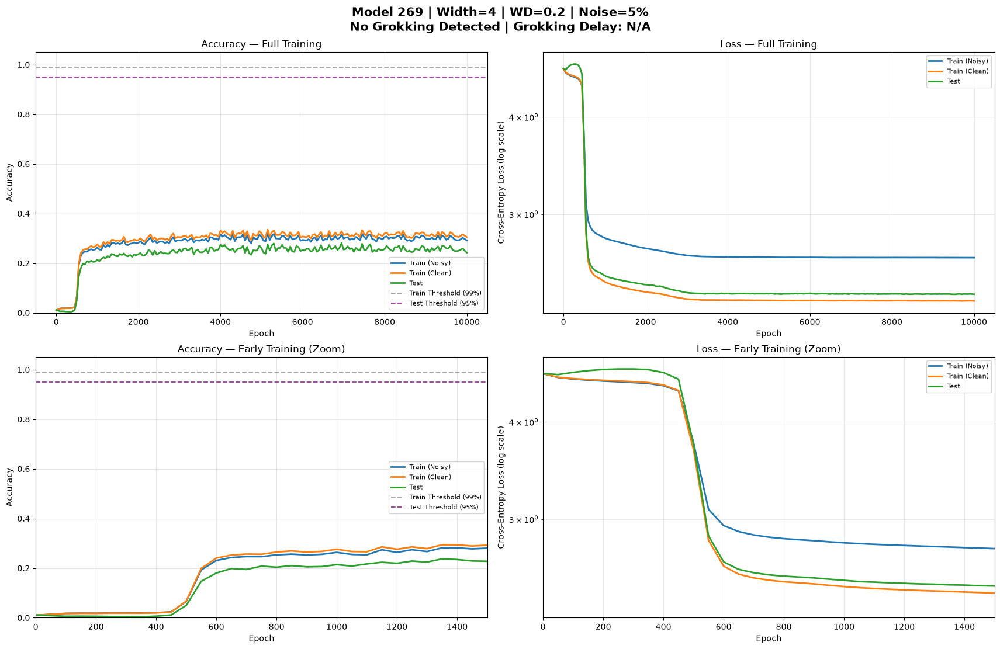

Training Models:  88%|████████▊ | 270/308 [1:59:27<1:03:45, 100.68s/model]


Training Model 270 | Width=4 | WD=0.2 | Noise=15%
Model 270 | Epoch   500/10000 | Train: 0.0252 | Test: 0.0078
Model 270 | Epoch  1000/10000 | Train: 0.1477 | Test: 0.1173
Model 270 | Epoch  1500/10000 | Train: 0.1483 | Test: 0.1137
Model 270 | Epoch  2000/10000 | Train: 0.1470 | Test: 0.1130
Model 270 | Epoch  2500/10000 | Train: 0.1687 | Test: 0.1488
Model 270 | Epoch  3000/10000 | Train: 0.1899 | Test: 0.1601
Model 270 | Epoch  3500/10000 | Train: 0.1969 | Test: 0.1612
Model 270 | Epoch  4000/10000 | Train: 0.1978 | Test: 0.1668
Model 270 | Epoch  4500/10000 | Train: 0.1921 | Test: 0.1647
Model 270 | Epoch  5000/10000 | Train: 0.1927 | Test: 0.1683
Model 270 | Epoch  5500/10000 | Train: 0.1916 | Test: 0.1598
Model 270 | Epoch  6000/10000 | Train: 0.1942 | Test: 0.1576
Model 270 | Epoch  6500/10000 | Train: 0.1925 | Test: 0.1668
Model 270 | Epoch  7000/10000 | Train: 0.1909 | Test: 0.1601
Model 270 | Epoch  7500/10000 | Train: 0.1898 | Test: 0.1537
Model 270 | Epoch  8000/10000 | Tr

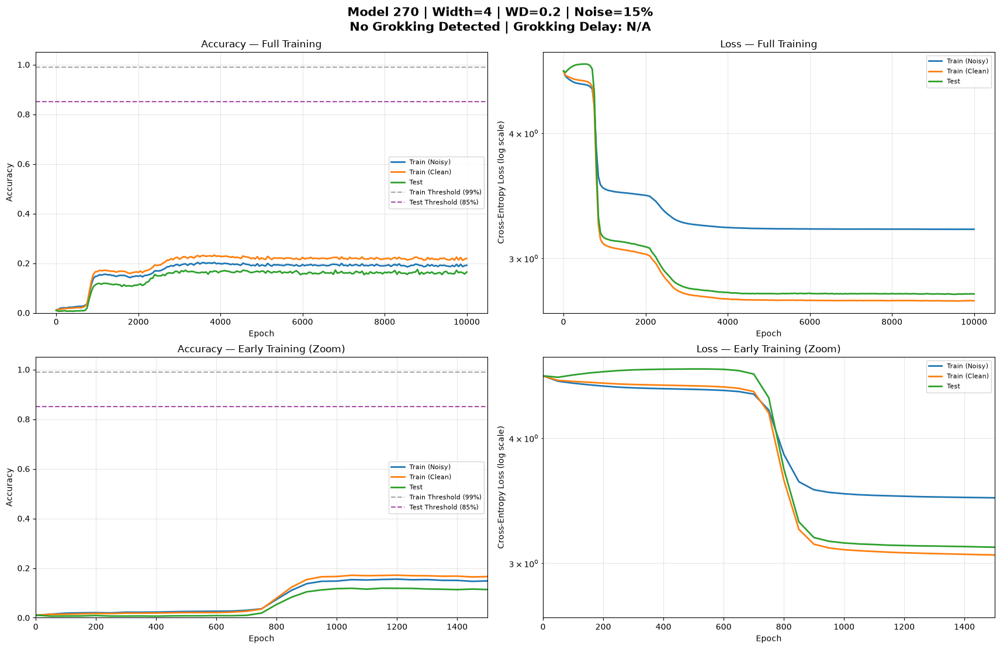

Training Models:  88%|████████▊ | 271/308 [2:01:03<1:01:15, 99.33s/model] 


Training Model 271 | Width=4 | WD=0.2 | Noise=25%
Model 271 | Epoch   500/10000 | Train: 0.0220 | Test: 0.0053
Model 271 | Epoch  1000/10000 | Train: 0.0920 | Test: 0.0840
Model 271 | Epoch  1500/10000 | Train: 0.1474 | Test: 0.1339
Model 271 | Epoch  2000/10000 | Train: 0.1704 | Test: 0.1601
Model 271 | Epoch  2500/10000 | Train: 0.1682 | Test: 0.1651
Model 271 | Epoch  3000/10000 | Train: 0.1695 | Test: 0.1693
Model 271 | Epoch  3500/10000 | Train: 0.1678 | Test: 0.1739
Model 271 | Epoch  4000/10000 | Train: 0.1704 | Test: 0.1739
Model 271 | Epoch  4500/10000 | Train: 0.1740 | Test: 0.1707
Model 271 | Epoch  5000/10000 | Train: 0.1716 | Test: 0.1640
Model 271 | Epoch  5500/10000 | Train: 0.1702 | Test: 0.1661
Model 271 | Epoch  6000/10000 | Train: 0.1667 | Test: 0.1562
Model 271 | Epoch  6500/10000 | Train: 0.1661 | Test: 0.1583
Model 271 | Epoch  7000/10000 | Train: 0.1641 | Test: 0.1587
Model 271 | Epoch  7500/10000 | Train: 0.1655 | Test: 0.1523
Model 271 | Epoch  8000/10000 | Tr

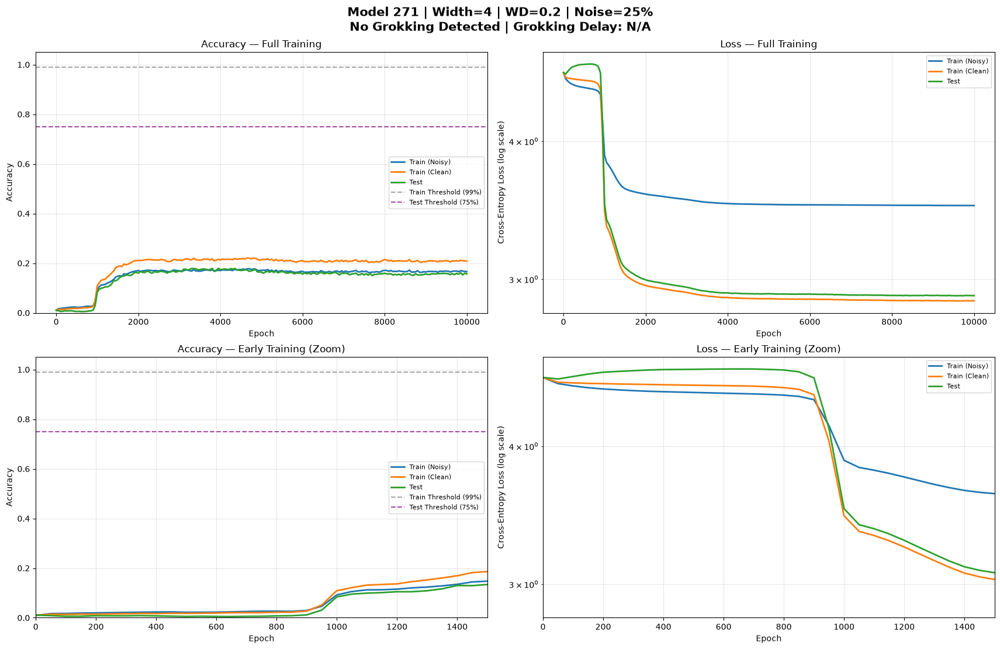

Training Models:  88%|████████▊ | 272/308 [2:02:40<59:11, 98.65s/model]  


Training Model 272 | Width=8 | WD=0.2 | Noise=0%
Model 272 | Epoch   500/10000 | Train: 0.6389 | Test: 0.5299
Model 272 | Epoch  1000/10000 | Train: 0.8386 | Test: 0.7662
Model 272 | Epoch  1500/10000 | Train: 0.8808 | Test: 0.8211
Model 272 | Epoch  2000/10000 | Train: 0.8884 | Test: 0.8197
Model 272 | Epoch  2500/10000 | Train: 0.8741 | Test: 0.8052
Model 272 | Epoch  3000/10000 | Train: 0.8573 | Test: 0.7945
Model 272 | Epoch  3500/10000 | Train: 0.8469 | Test: 0.7765
Model 272 | Epoch  4000/10000 | Train: 0.8460 | Test: 0.7751
Model 272 | Epoch  4500/10000 | Train: 0.8474 | Test: 0.7871
Model 272 | Epoch  5000/10000 | Train: 0.8535 | Test: 0.7843
Model 272 | Epoch  5500/10000 | Train: 0.8690 | Test: 0.8013
Model 272 | Epoch  6000/10000 | Train: 0.8731 | Test: 0.8239
Model 272 | Epoch  6500/10000 | Train: 0.9283 | Test: 0.8870
Model 272 | Epoch  7000/10000 | Train: 0.9722 | Test: 0.9539
Model 272 | Epoch  7500/10000 | Train: 0.9710 | Test: 0.9486
Model 272 | Epoch  8000/10000 | Tra

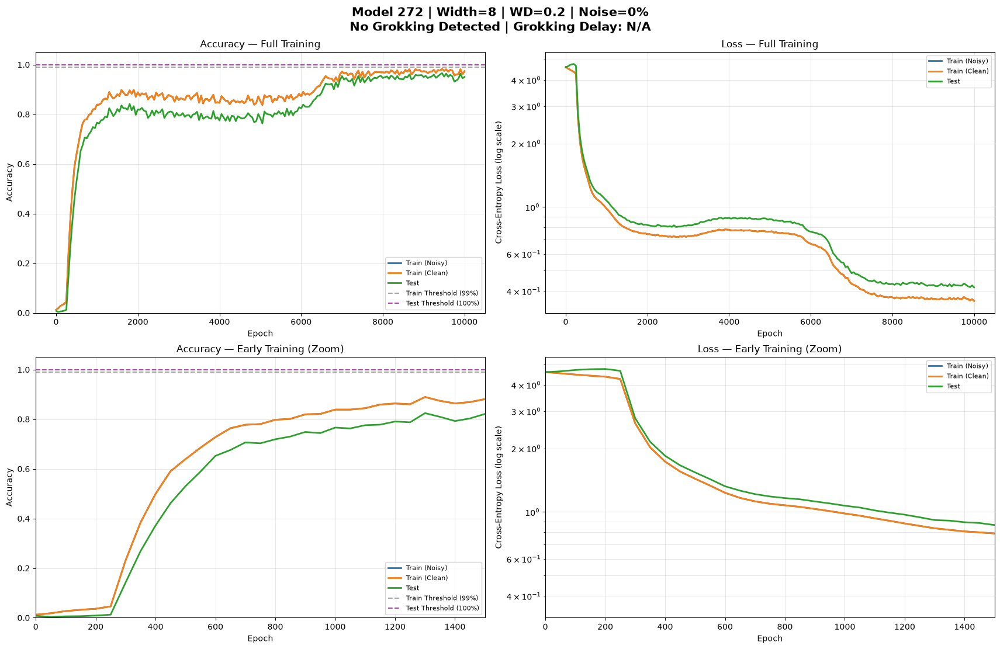

Training Models:  89%|████████▊ | 273/308 [2:04:16<57:09, 97.98s/model]


Training Model 273 | Width=8 | WD=0.2 | Noise=5%
Model 273 | Epoch   500/10000 | Train: 0.8580 | Test: 0.8413
Model 273 | Epoch  1000/10000 | Train: 0.9138 | Test: 0.9327
Model 273 | Epoch  1500/10000 | Train: 0.9273 | Test: 0.9515
Model 273 | Epoch  2000/10000 | Train: 0.9306 | Test: 0.9522
Model 273 | Epoch  2500/10000 | Train: 0.9353 | Test: 0.9617
Model 273 | Epoch  3000/10000 | Train: 0.9362 | Test: 0.9674
Model 273 | Epoch  3500/10000 | Train: 0.9391 | Test: 0.9649
Model 273 | Epoch  4000/10000 | Train: 0.9440 | Test: 0.9780
Model 273 | Epoch  4500/10000 | Train: 0.9412 | Test: 0.9770
Model 273 | Epoch  5000/10000 | Train: 0.9377 | Test: 0.9720
Model 273 | Epoch  5500/10000 | Train: 0.9437 | Test: 0.9795
Model 273 | Epoch  6000/10000 | Train: 0.9406 | Test: 0.9745
Model 273 | Epoch  6500/10000 | Train: 0.9459 | Test: 0.9834
Model 273 | Epoch  7000/10000 | Train: 0.9435 | Test: 0.9809
Model 273 | Epoch  7500/10000 | Train: 0.9437 | Test: 0.9784
Model 273 | Epoch  8000/10000 | Tra

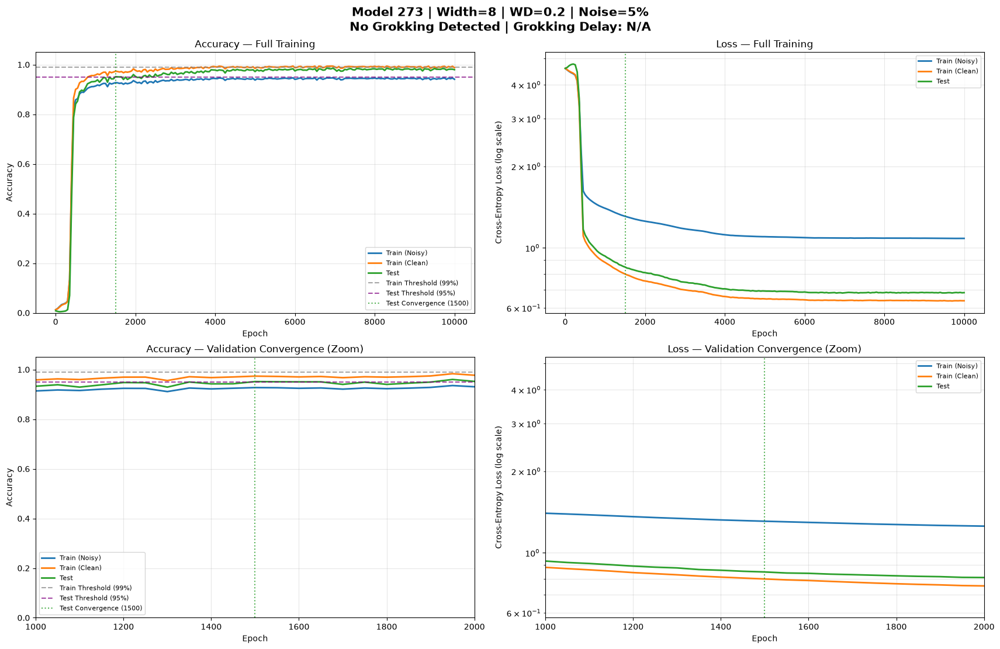

Training Models:  89%|████████▉ | 274/308 [2:05:52<55:08, 97.32s/model]


Training Model 274 | Width=8 | WD=0.2 | Noise=15%
Model 274 | Epoch   500/10000 | Train: 0.0773 | Test: 0.0344
Model 274 | Epoch  1000/10000 | Train: 0.5577 | Test: 0.5430
Model 274 | Epoch  1500/10000 | Train: 0.6327 | Test: 0.6167
Model 274 | Epoch  2000/10000 | Train: 0.6872 | Test: 0.7226
Model 274 | Epoch  2500/10000 | Train: 0.7244 | Test: 0.7797
Model 274 | Epoch  3000/10000 | Train: 0.7309 | Test: 0.7977
Model 274 | Epoch  3500/10000 | Train: 0.7316 | Test: 0.7885
Model 274 | Epoch  4000/10000 | Train: 0.7364 | Test: 0.7882
Model 274 | Epoch  4500/10000 | Train: 0.7393 | Test: 0.7984
Model 274 | Epoch  5000/10000 | Train: 0.7425 | Test: 0.8048
Model 274 | Epoch  5500/10000 | Train: 0.7478 | Test: 0.8101
Model 274 | Epoch  6000/10000 | Train: 0.7425 | Test: 0.8069
Model 274 | Epoch  6500/10000 | Train: 0.7434 | Test: 0.8094
Model 274 | Epoch  7000/10000 | Train: 0.7439 | Test: 0.8115
Model 274 | Epoch  7500/10000 | Train: 0.7413 | Test: 0.8073
Model 274 | Epoch  8000/10000 | Tr

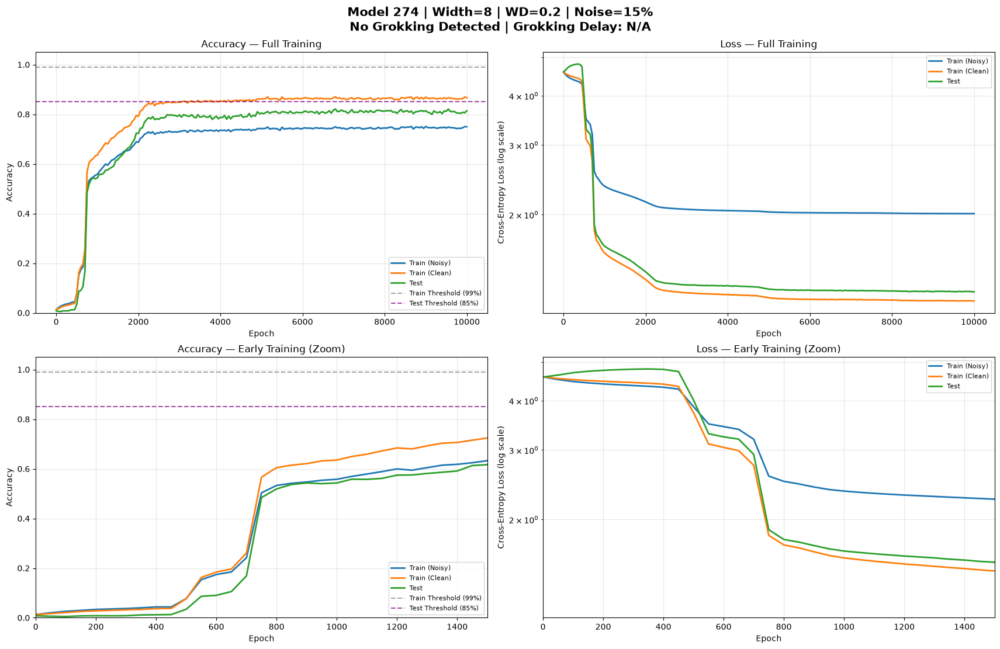

Training Models:  89%|████████▉ | 275/308 [2:07:28<53:19, 96.95s/model]


Training Model 275 | Width=8 | WD=0.2 | Noise=25%
Model 275 | Epoch   500/10000 | Train: 0.0466 | Test: 0.0089
Model 275 | Epoch  1000/10000 | Train: 0.1318 | Test: 0.0719
Model 275 | Epoch  1500/10000 | Train: 0.5179 | Test: 0.5462
Model 275 | Epoch  2000/10000 | Train: 0.6073 | Test: 0.7425
Model 275 | Epoch  2500/10000 | Train: 0.6254 | Test: 0.7545
Model 275 | Epoch  3000/10000 | Train: 0.6309 | Test: 0.7701
Model 275 | Epoch  3500/10000 | Train: 0.6370 | Test: 0.7768
Model 275 | Epoch  4000/10000 | Train: 0.6371 | Test: 0.7768
Model 275 | Epoch  4500/10000 | Train: 0.6389 | Test: 0.7843
Model 275 | Epoch  5000/10000 | Train: 0.6479 | Test: 0.7821
Model 275 | Epoch  5500/10000 | Train: 0.6591 | Test: 0.8123
Model 275 | Epoch  6000/10000 | Train: 0.6842 | Test: 0.8558
Model 275 | Epoch  6500/10000 | Train: 0.6915 | Test: 0.8764
Model 275 | Epoch  7000/10000 | Train: 0.7001 | Test: 0.8849
Model 275 | Epoch  7500/10000 | Train: 0.6985 | Test: 0.8874
Model 275 | Epoch  8000/10000 | Tr

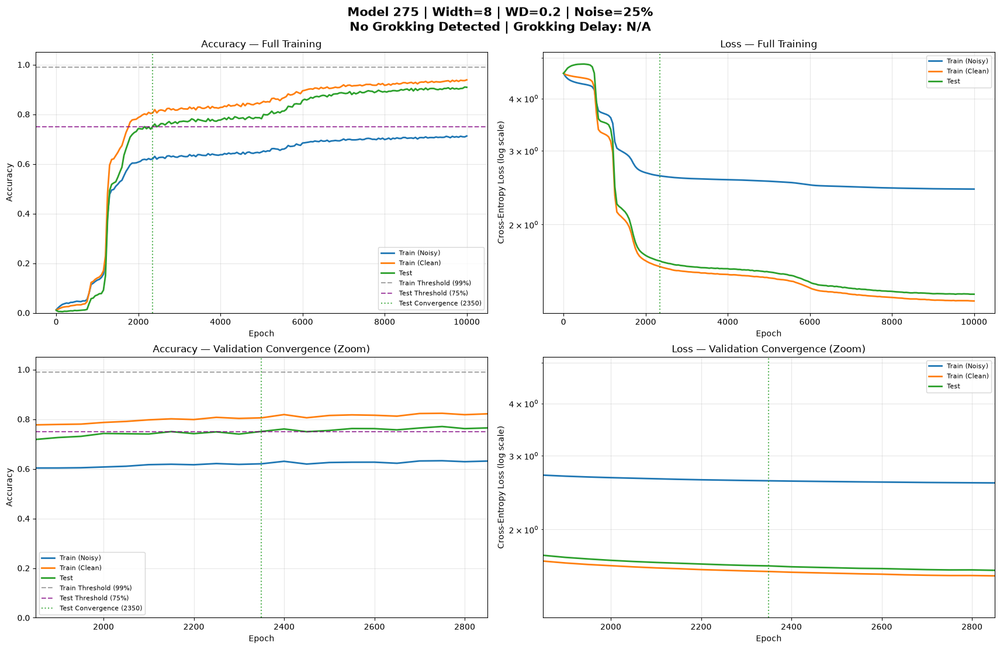

Training Models:  90%|████████▉ | 276/308 [2:09:04<51:29, 96.56s/model]


Training Model 276 | Width=12 | WD=0.2 | Noise=0%
Model 276 | Epoch   500/10000 | Train: 1.0000 | Test: 0.9996
Model 276 | Epoch  1000/10000 | Train: 1.0000 | Test: 1.0000
Model 276 | Epoch  1500/10000 | Train: 1.0000 | Test: 1.0000
Model 276 | Epoch  2000/10000 | Train: 1.0000 | Test: 1.0000
Model 276 | Epoch  2500/10000 | Train: 1.0000 | Test: 1.0000
Model 276 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 276 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 276 | Epoch  4000/10000 | Train: 1.0000 | Test: 1.0000
Model 276 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 276 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 276 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 276 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 276 | Epoch  6500/10000 | Train: 1.0000 | Test: 1.0000
Model 276 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 276 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 276 | Epoch  8000/10000 | Tr

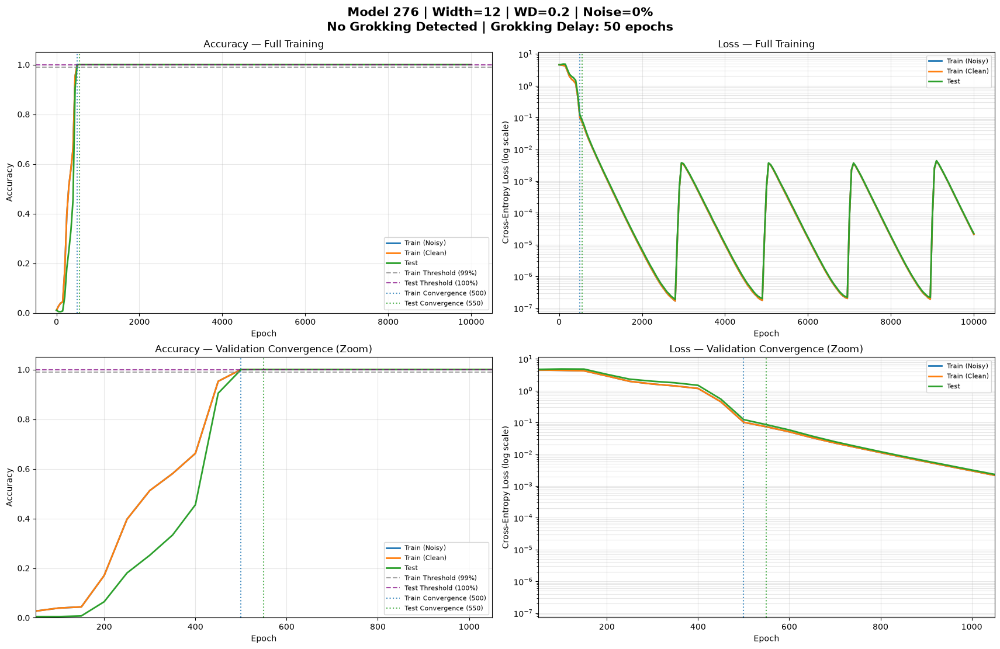

Training Models:  90%|████████▉ | 277/308 [2:10:41<50:01, 96.83s/model]


Training Model 277 | Width=12 | WD=0.2 | Noise=5%
Model 277 | Epoch   500/10000 | Train: 0.3990 | Test: 0.1916
Model 277 | Epoch  1000/10000 | Train: 0.9500 | Test: 0.9989
Model 277 | Epoch  1500/10000 | Train: 0.9502 | Test: 0.9947
Model 277 | Epoch  2000/10000 | Train: 0.9500 | Test: 0.9936
Model 277 | Epoch  2500/10000 | Train: 0.9502 | Test: 0.9933
Model 277 | Epoch  3000/10000 | Train: 0.9503 | Test: 0.9936
Model 277 | Epoch  3500/10000 | Train: 0.9505 | Test: 0.9943
Model 277 | Epoch  4000/10000 | Train: 0.9507 | Test: 0.9919
Model 277 | Epoch  4500/10000 | Train: 0.9507 | Test: 0.9915
Model 277 | Epoch  5000/10000 | Train: 0.9510 | Test: 0.9897
Model 277 | Epoch  5500/10000 | Train: 0.9510 | Test: 0.9890
Model 277 | Epoch  6000/10000 | Train: 0.9510 | Test: 0.9894
Model 277 | Epoch  6500/10000 | Train: 0.9514 | Test: 0.9894
Model 277 | Epoch  7000/10000 | Train: 0.9516 | Test: 0.9894
Model 277 | Epoch  7500/10000 | Train: 0.9517 | Test: 0.9901
Model 277 | Epoch  8000/10000 | Tr

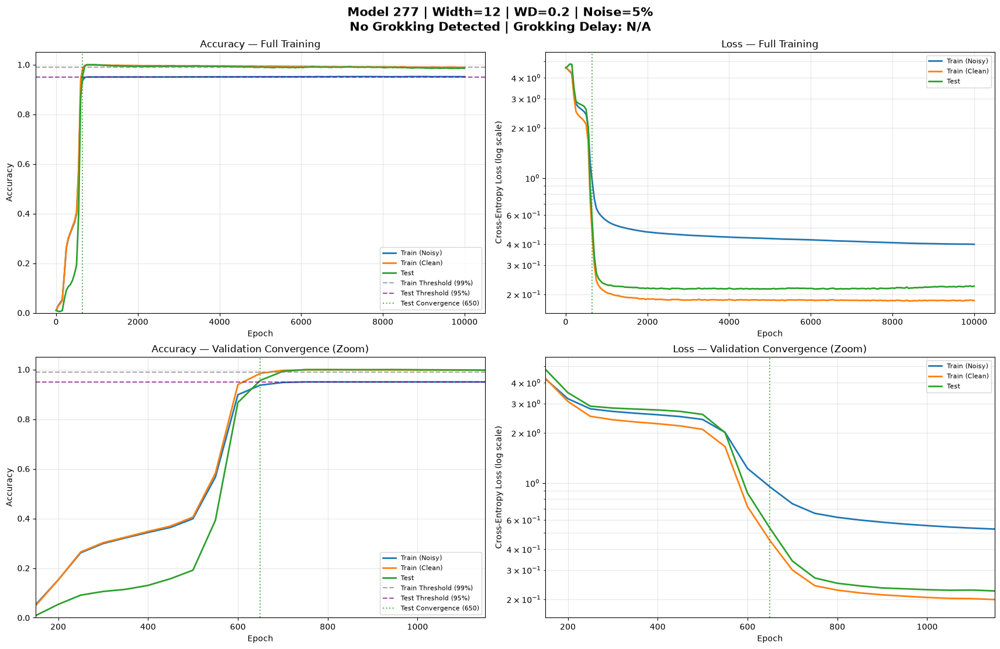

Training Models:  90%|█████████ | 278/308 [2:12:18<48:28, 96.94s/model]


Training Model 278 | Width=12 | WD=0.2 | Noise=15%
Model 278 | Epoch   500/10000 | Train: 0.0894 | Test: 0.0220
Model 278 | Epoch  1000/10000 | Train: 0.7115 | Test: 0.6638
Model 278 | Epoch  1500/10000 | Train: 0.8450 | Test: 0.9826
Model 278 | Epoch  2000/10000 | Train: 0.8497 | Test: 0.9883
Model 278 | Epoch  2500/10000 | Train: 0.8498 | Test: 0.9904
Model 278 | Epoch  3000/10000 | Train: 0.8498 | Test: 0.9890
Model 278 | Epoch  3500/10000 | Train: 0.8497 | Test: 0.9890
Model 278 | Epoch  4000/10000 | Train: 0.8497 | Test: 0.9904
Model 278 | Epoch  4500/10000 | Train: 0.8492 | Test: 0.9890
Model 278 | Epoch  5000/10000 | Train: 0.8492 | Test: 0.9872
Model 278 | Epoch  5500/10000 | Train: 0.8494 | Test: 0.9880
Model 278 | Epoch  6000/10000 | Train: 0.8495 | Test: 0.9872
Model 278 | Epoch  6500/10000 | Train: 0.8488 | Test: 0.9862
Model 278 | Epoch  7000/10000 | Train: 0.8489 | Test: 0.9869
Model 278 | Epoch  7500/10000 | Train: 0.8488 | Test: 0.9880
Model 278 | Epoch  8000/10000 | T

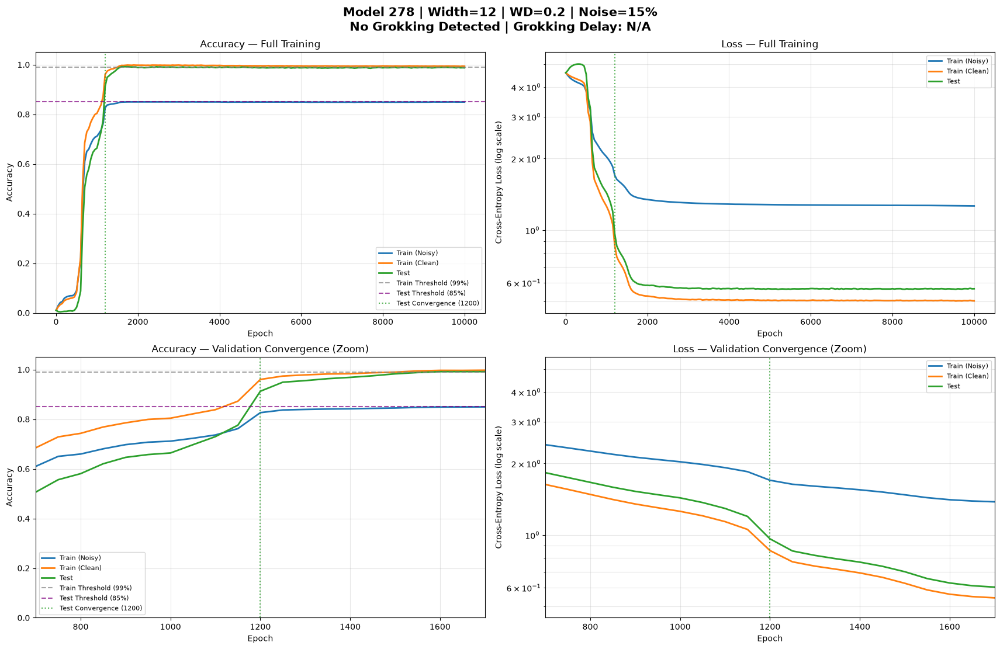

Training Models:  91%|█████████ | 279/308 [2:13:56<46:57, 97.15s/model]


Training Model 279 | Width=12 | WD=0.2 | Noise=25%
Model 279 | Epoch   500/10000 | Train: 0.0691 | Test: 0.0067
Model 279 | Epoch  1000/10000 | Train: 0.0837 | Test: 0.0138
Model 279 | Epoch  1500/10000 | Train: 0.6998 | Test: 0.7928
Model 279 | Epoch  2000/10000 | Train: 0.7114 | Test: 0.8183
Model 279 | Epoch  2500/10000 | Train: 0.7305 | Test: 0.8820
Model 279 | Epoch  3000/10000 | Train: 0.7355 | Test: 0.9058
Model 279 | Epoch  3500/10000 | Train: 0.7382 | Test: 0.9168
Model 279 | Epoch  4000/10000 | Train: 0.7414 | Test: 0.9309
Model 279 | Epoch  4500/10000 | Train: 0.7445 | Test: 0.9550
Model 279 | Epoch  5000/10000 | Train: 0.7473 | Test: 0.9724
Model 279 | Epoch  5500/10000 | Train: 0.7481 | Test: 0.9766
Model 279 | Epoch  6000/10000 | Train: 0.7490 | Test: 0.9809
Model 279 | Epoch  6500/10000 | Train: 0.7492 | Test: 0.9777
Model 279 | Epoch  7000/10000 | Train: 0.7483 | Test: 0.9752
Model 279 | Epoch  7500/10000 | Train: 0.7492 | Test: 0.9766
Model 279 | Epoch  8000/10000 | T

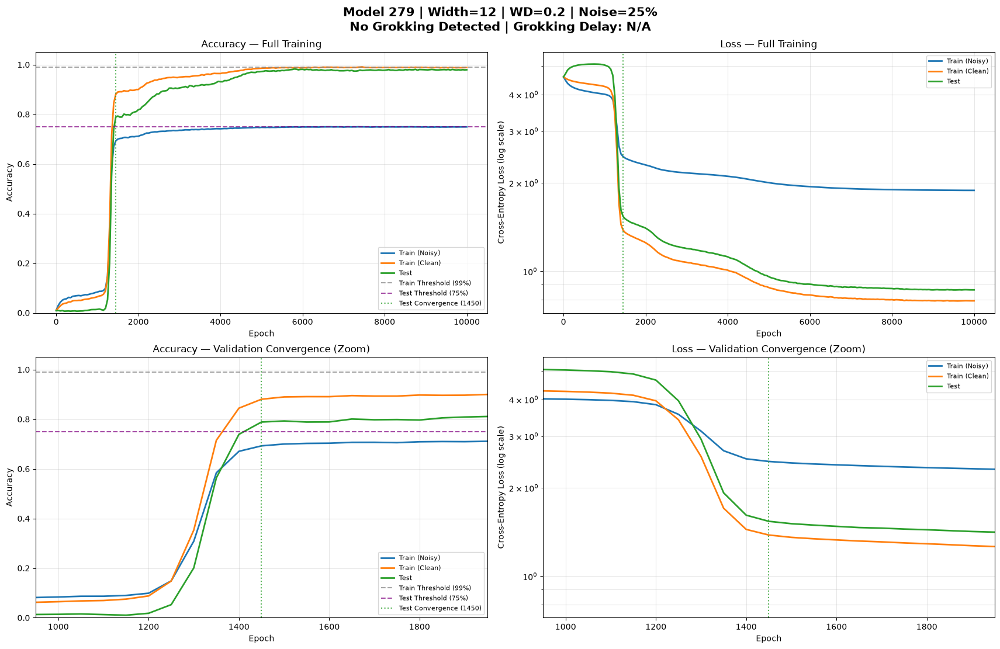

Training Models:  91%|█████████ | 280/308 [2:15:34<45:26, 97.37s/model]


Training Model 280 | Width=16 | WD=0.2 | Noise=0%
Model 280 | Epoch   500/10000 | Train: 1.0000 | Test: 1.0000
Model 280 | Epoch  1000/10000 | Train: 1.0000 | Test: 1.0000
Model 280 | Epoch  1500/10000 | Train: 1.0000 | Test: 1.0000
Model 280 | Epoch  2000/10000 | Train: 1.0000 | Test: 1.0000
Model 280 | Epoch  2500/10000 | Train: 1.0000 | Test: 1.0000
Model 280 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 280 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 280 | Epoch  4000/10000 | Train: 1.0000 | Test: 1.0000
Model 280 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 280 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 280 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 280 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 280 | Epoch  6500/10000 | Train: 1.0000 | Test: 1.0000
Model 280 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 280 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 280 | Epoch  8000/10000 | Tr

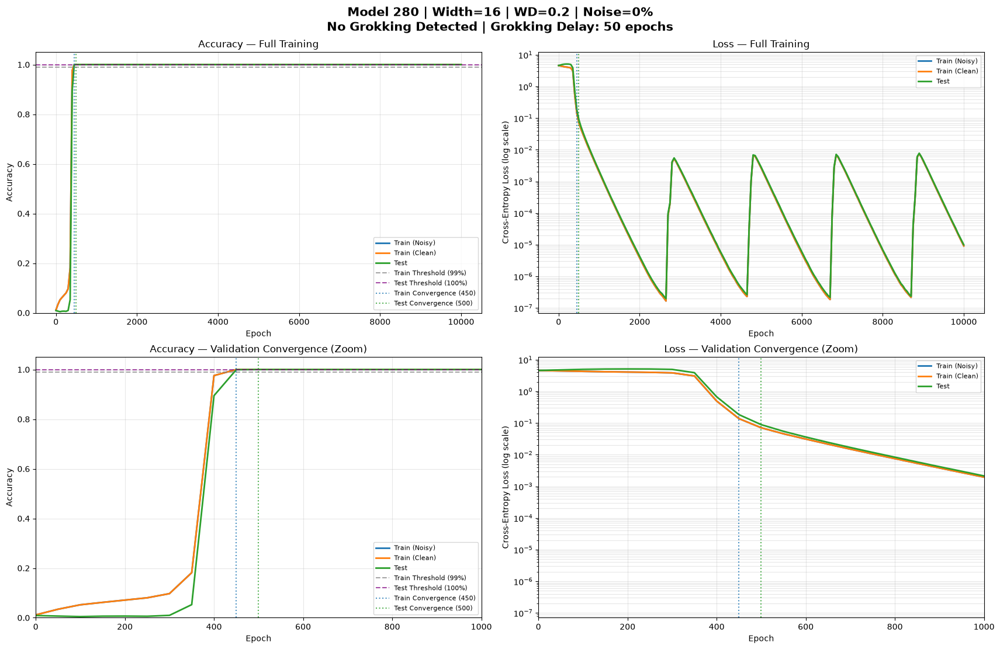

Training Models:  91%|█████████ | 281/308 [2:17:10<43:40, 97.07s/model]


Training Model 281 | Width=16 | WD=0.2 | Noise=5%
Model 281 | Epoch   500/10000 | Train: 0.4274 | Test: 0.1385
Model 281 | Epoch  1000/10000 | Train: 0.9405 | Test: 0.9238
Model 281 | Epoch  1500/10000 | Train: 0.9537 | Test: 0.9830
Model 281 | Epoch  2000/10000 | Train: 0.9608 | Test: 0.9674
Model 281 | Epoch  2500/10000 | Train: 0.9634 | Test: 0.9550
Model 281 | Epoch  3000/10000 | Train: 0.9657 | Test: 0.9479
Model 281 | Epoch  3500/10000 | Train: 0.9677 | Test: 0.9454
Model 281 | Epoch  4000/10000 | Train: 0.9702 | Test: 0.9384
Model 281 | Epoch  4500/10000 | Train: 0.9712 | Test: 0.9398
Model 281 | Epoch  5000/10000 | Train: 0.9724 | Test: 0.9352
Model 281 | Epoch  5500/10000 | Train: 0.9733 | Test: 0.9345
Model 281 | Epoch  6000/10000 | Train: 0.9739 | Test: 0.9320
Model 281 | Epoch  6500/10000 | Train: 0.9749 | Test: 0.9323
Model 281 | Epoch  7000/10000 | Train: 0.9753 | Test: 0.9288
Model 281 | Epoch  7500/10000 | Train: 0.9759 | Test: 0.9274
Model 281 | Epoch  8000/10000 | Tr

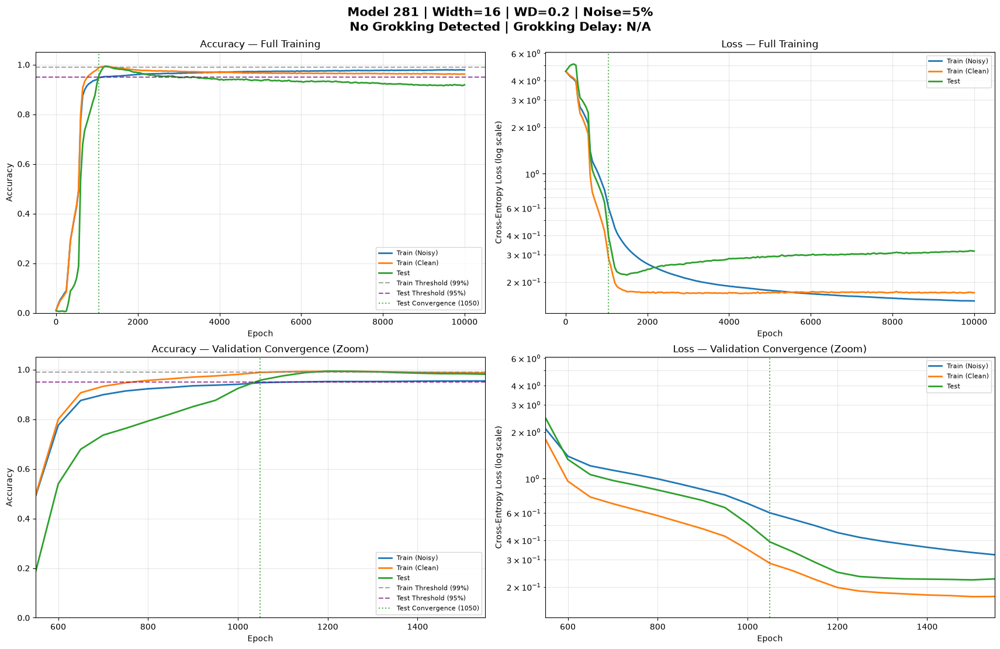

Training Models:  92%|█████████▏| 282/308 [2:18:46<41:55, 96.76s/model]


Training Model 282 | Width=16 | WD=0.2 | Noise=15%
Model 282 | Epoch   500/10000 | Train: 0.1014 | Test: 0.0081
Model 282 | Epoch  1000/10000 | Train: 0.7434 | Test: 0.6337
Model 282 | Epoch  1500/10000 | Train: 0.8498 | Test: 0.9543
Model 282 | Epoch  2000/10000 | Train: 0.8515 | Test: 0.9508
Model 282 | Epoch  2500/10000 | Train: 0.8507 | Test: 0.9430
Model 282 | Epoch  3000/10000 | Train: 0.8514 | Test: 0.9451
Model 282 | Epoch  3500/10000 | Train: 0.8518 | Test: 0.9433
Model 282 | Epoch  4000/10000 | Train: 0.8517 | Test: 0.9416
Model 282 | Epoch  4500/10000 | Train: 0.8539 | Test: 0.9454
Model 282 | Epoch  5000/10000 | Train: 0.8538 | Test: 0.9504
Model 282 | Epoch  5500/10000 | Train: 0.8535 | Test: 0.9522
Model 282 | Epoch  6000/10000 | Train: 0.8544 | Test: 0.9522
Model 282 | Epoch  6500/10000 | Train: 0.8555 | Test: 0.9547
Model 282 | Epoch  7000/10000 | Train: 0.8565 | Test: 0.9508
Model 282 | Epoch  7500/10000 | Train: 0.8573 | Test: 0.9493
Model 282 | Epoch  8000/10000 | T

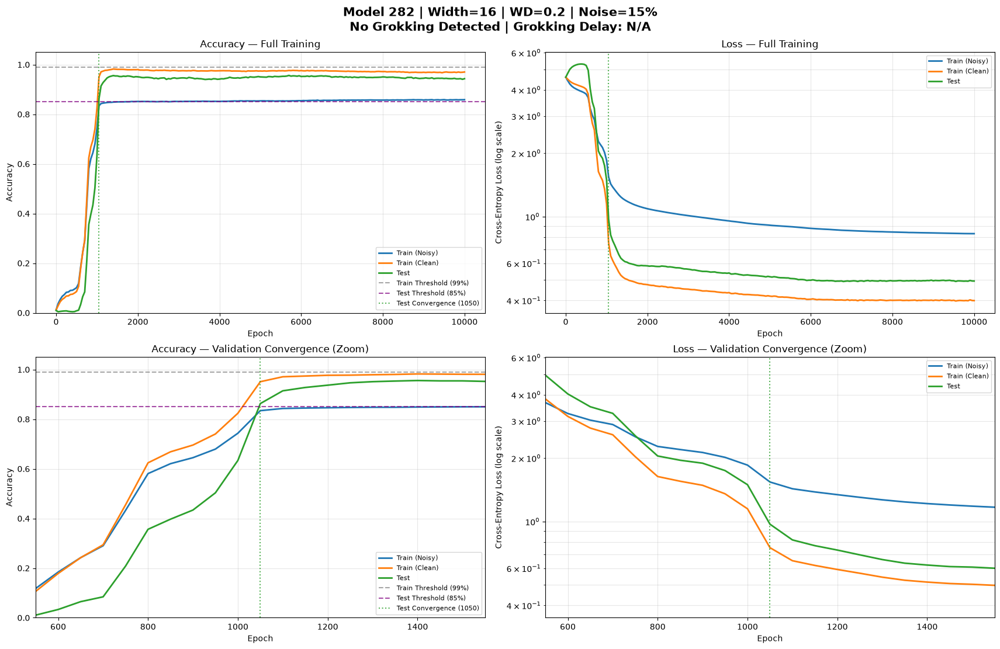

Training Models:  92%|█████████▏| 283/308 [2:20:22<40:13, 96.55s/model]


Training Model 283 | Width=16 | WD=0.2 | Noise=25%
Model 283 | Epoch   500/10000 | Train: 0.1060 | Test: 0.0046
Model 283 | Epoch  1000/10000 | Train: 0.1203 | Test: 0.0057
Model 283 | Epoch  1500/10000 | Train: 0.1286 | Test: 0.0064
Model 283 | Epoch  2000/10000 | Train: 0.1318 | Test: 0.0064
Model 283 | Epoch  2500/10000 | Train: 0.1391 | Test: 0.0046
Model 283 | Epoch  3000/10000 | Train: 0.1394 | Test: 0.0067
Model 283 | Epoch  3500/10000 | Train: 0.1427 | Test: 0.0092
Model 283 | Epoch  4000/10000 | Train: 0.1538 | Test: 0.0113
Model 283 | Epoch  4500/10000 | Train: 0.3474 | Test: 0.1272
Model 283 | Epoch  5000/10000 | Train: 0.7180 | Test: 0.7499
Model 283 | Epoch  5500/10000 | Train: 0.7370 | Test: 0.8130
Model 283 | Epoch  6000/10000 | Train: 0.7384 | Test: 0.8073
Model 283 | Epoch  6500/10000 | Train: 0.7408 | Test: 0.8087
Model 283 | Epoch  7000/10000 | Train: 0.7448 | Test: 0.8147
Model 283 | Epoch  7500/10000 | Train: 0.7434 | Test: 0.8229
Model 283 | Epoch  8000/10000 | T

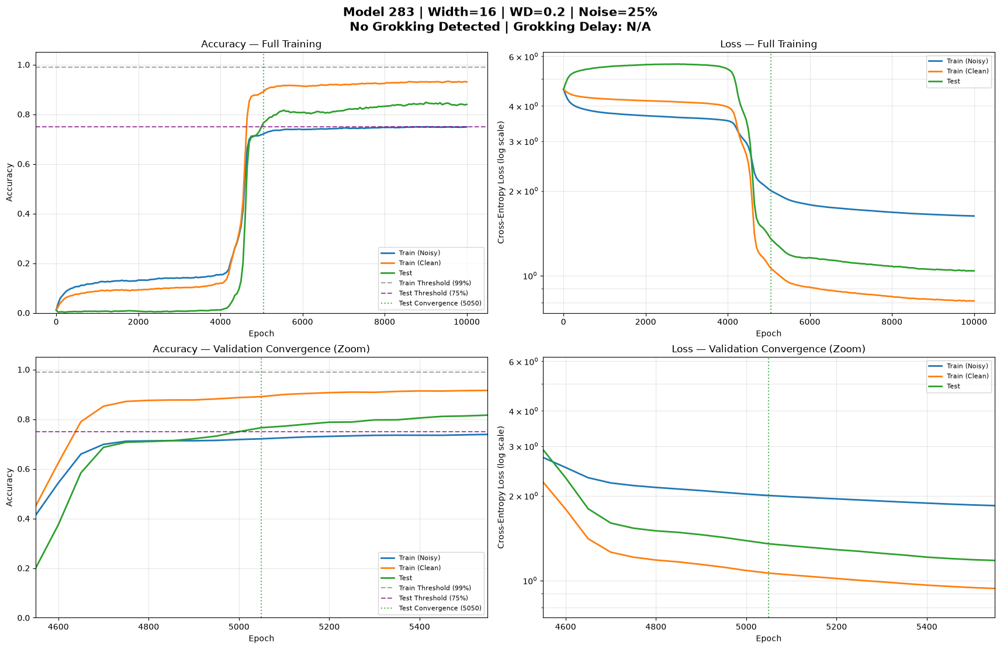

Training Models:  92%|█████████▏| 284/308 [2:21:58<38:32, 96.37s/model]


Training Model 284 | Width=20 | WD=0.2 | Noise=0%
Model 284 | Epoch   500/10000 | Train: 1.0000 | Test: 1.0000
Model 284 | Epoch  1000/10000 | Train: 1.0000 | Test: 1.0000
Model 284 | Epoch  1500/10000 | Train: 1.0000 | Test: 1.0000
Model 284 | Epoch  2000/10000 | Train: 1.0000 | Test: 1.0000
Model 284 | Epoch  2500/10000 | Train: 1.0000 | Test: 1.0000
Model 284 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 284 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 284 | Epoch  4000/10000 | Train: 1.0000 | Test: 1.0000
Model 284 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 284 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 284 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 284 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 284 | Epoch  6500/10000 | Train: 1.0000 | Test: 1.0000
Model 284 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 284 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 284 | Epoch  8000/10000 | Tr

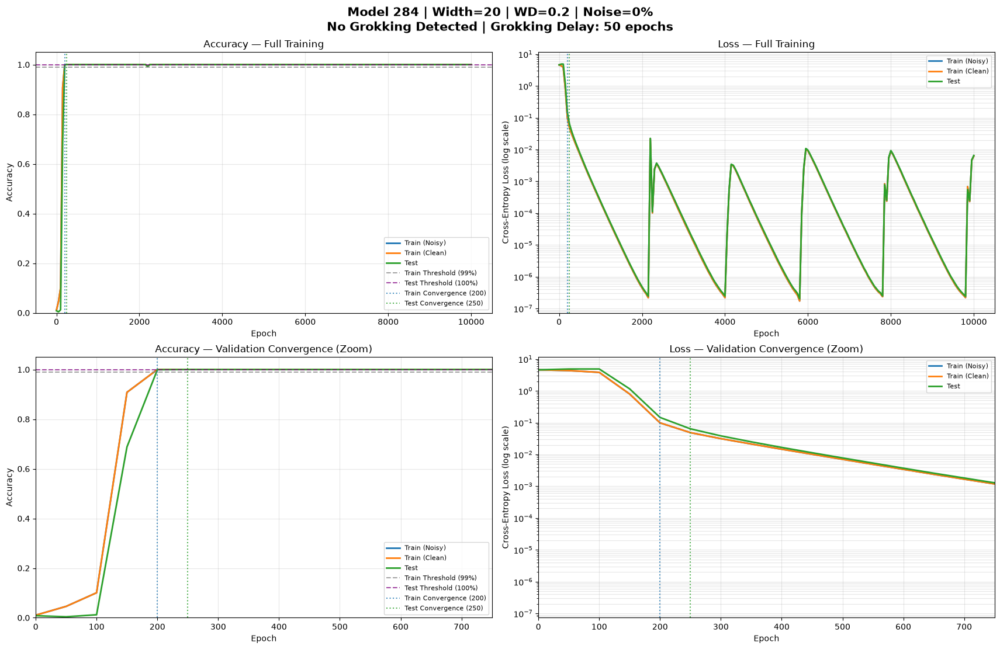

Training Models:  93%|█████████▎| 285/308 [2:23:35<36:56, 96.38s/model]


Training Model 285 | Width=20 | WD=0.2 | Noise=5%
Model 285 | Epoch   500/10000 | Train: 0.9528 | Test: 0.9738
Model 285 | Epoch  1000/10000 | Train: 0.9774 | Test: 0.9164
Model 285 | Epoch  1500/10000 | Train: 0.9956 | Test: 0.9026
Model 285 | Epoch  2000/10000 | Train: 0.9998 | Test: 0.8966
Model 285 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.8994
Model 285 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.9090
Model 285 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.9061
Model 285 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9068
Model 285 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9033
Model 285 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9075
Model 285 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9026
Model 285 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9079
Model 285 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9068
Model 285 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9047
Model 285 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9044
Model 285 | Epoch  8000/10000 | Tr

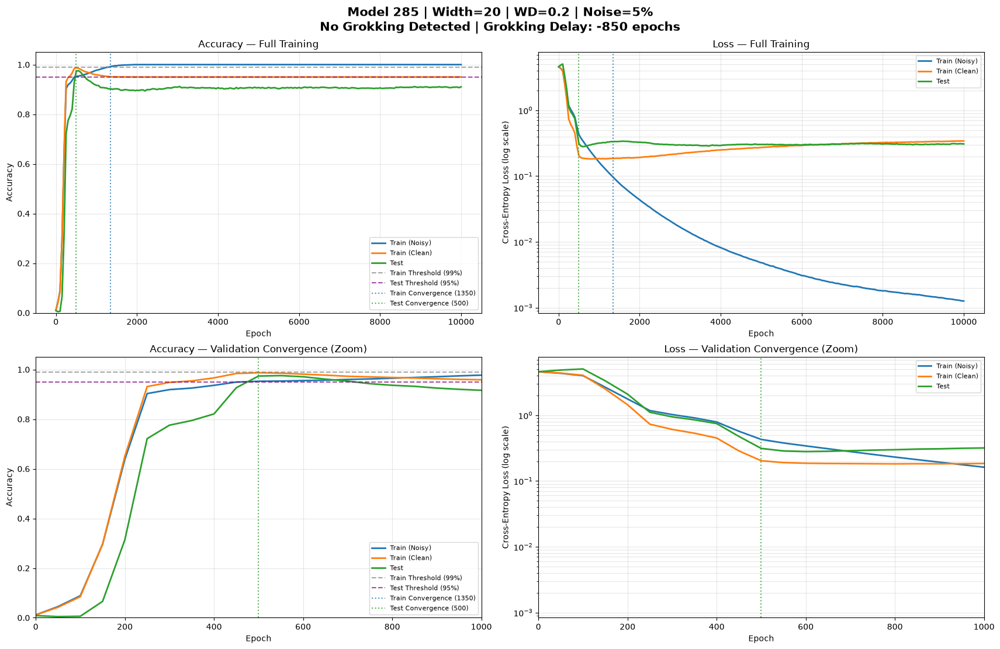

Training Models:  93%|█████████▎| 286/308 [2:25:11<35:20, 96.38s/model]


Training Model 286 | Width=20 | WD=0.2 | Noise=15%
Model 286 | Epoch   500/10000 | Train: 0.6433 | Test: 0.3004
Model 286 | Epoch  1000/10000 | Train: 0.8450 | Test: 0.8250
Model 286 | Epoch  1500/10000 | Train: 0.8659 | Test: 0.8590
Model 286 | Epoch  2000/10000 | Train: 0.8737 | Test: 0.8300
Model 286 | Epoch  2500/10000 | Train: 0.8796 | Test: 0.8452
Model 286 | Epoch  3000/10000 | Train: 0.8861 | Test: 0.8399
Model 286 | Epoch  3500/10000 | Train: 0.8917 | Test: 0.8172
Model 286 | Epoch  4000/10000 | Train: 0.8958 | Test: 0.8105
Model 286 | Epoch  4500/10000 | Train: 0.8986 | Test: 0.8112
Model 286 | Epoch  5000/10000 | Train: 0.9013 | Test: 0.8013
Model 286 | Epoch  5500/10000 | Train: 0.9049 | Test: 0.8013
Model 286 | Epoch  6000/10000 | Train: 0.9051 | Test: 0.7970
Model 286 | Epoch  6500/10000 | Train: 0.9072 | Test: 0.7924
Model 286 | Epoch  7000/10000 | Train: 0.9075 | Test: 0.7935
Model 286 | Epoch  7500/10000 | Train: 0.9063 | Test: 0.7917
Model 286 | Epoch  8000/10000 | T

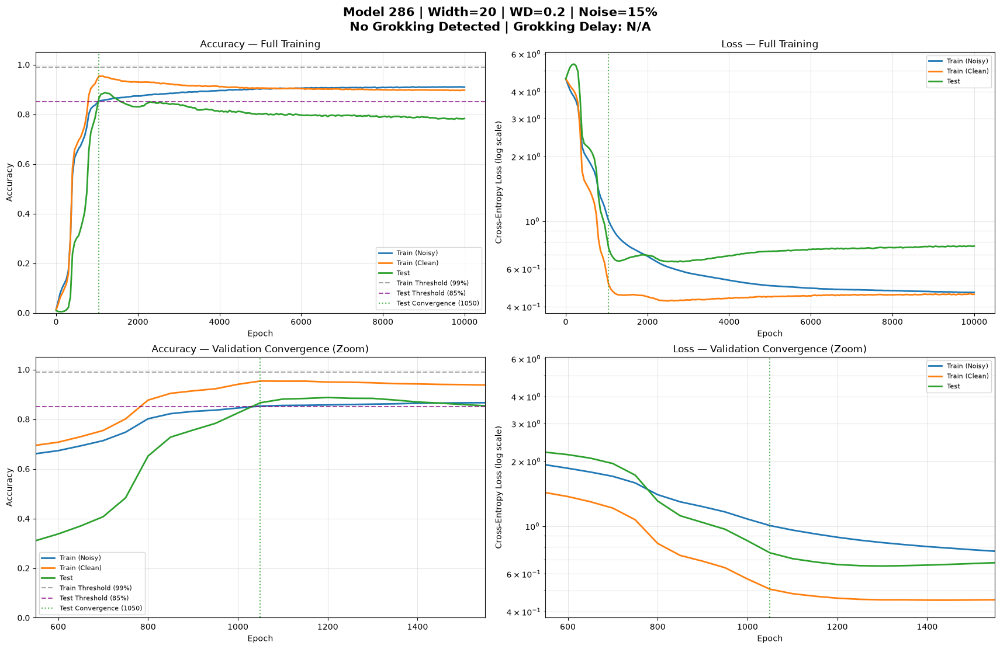

Training Models:  93%|█████████▎| 287/308 [2:26:48<33:44, 96.41s/model]


Training Model 287 | Width=20 | WD=0.2 | Noise=25%
Model 287 | Epoch   500/10000 | Train: 0.1611 | Test: 0.0113
Model 287 | Epoch  1000/10000 | Train: 0.4959 | Test: 0.1817
Model 287 | Epoch  1500/10000 | Train: 0.6857 | Test: 0.4400
Model 287 | Epoch  2000/10000 | Train: 0.6995 | Test: 0.4580
Model 287 | Epoch  2500/10000 | Train: 0.7086 | Test: 0.4591
Model 287 | Epoch  3000/10000 | Train: 0.7117 | Test: 0.4803
Model 287 | Epoch  3500/10000 | Train: 0.7168 | Test: 0.4881
Model 287 | Epoch  4000/10000 | Train: 0.7208 | Test: 0.4991
Model 287 | Epoch  4500/10000 | Train: 0.7275 | Test: 0.5076
Model 287 | Epoch  5000/10000 | Train: 0.7355 | Test: 0.5239
Model 287 | Epoch  5500/10000 | Train: 0.7431 | Test: 0.5455
Model 287 | Epoch  6000/10000 | Train: 0.7473 | Test: 0.5593
Model 287 | Epoch  6500/10000 | Train: 0.7513 | Test: 0.5639
Model 287 | Epoch  7000/10000 | Train: 0.7511 | Test: 0.5661
Model 287 | Epoch  7500/10000 | Train: 0.7530 | Test: 0.5714
Model 287 | Epoch  8000/10000 | T

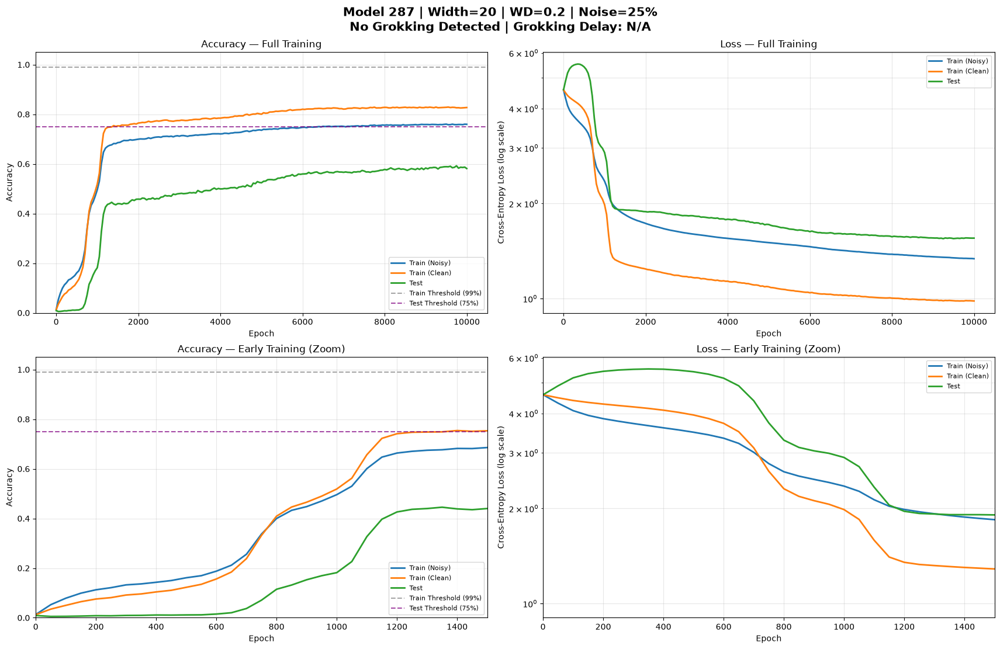

Training Models:  94%|█████████▎| 288/308 [2:28:23<32:03, 96.17s/model]


Training Model 288 | Width=32 | WD=0.2 | Noise=0%
Model 288 | Epoch   500/10000 | Train: 1.0000 | Test: 1.0000
Model 288 | Epoch  1000/10000 | Train: 1.0000 | Test: 1.0000
Model 288 | Epoch  1500/10000 | Train: 1.0000 | Test: 1.0000
Model 288 | Epoch  2000/10000 | Train: 1.0000 | Test: 1.0000
Model 288 | Epoch  2500/10000 | Train: 1.0000 | Test: 1.0000
Model 288 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 288 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 288 | Epoch  4000/10000 | Train: 1.0000 | Test: 1.0000
Model 288 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 288 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 288 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 288 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 288 | Epoch  6500/10000 | Train: 1.0000 | Test: 1.0000
Model 288 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 288 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 288 | Epoch  8000/10000 | Tr

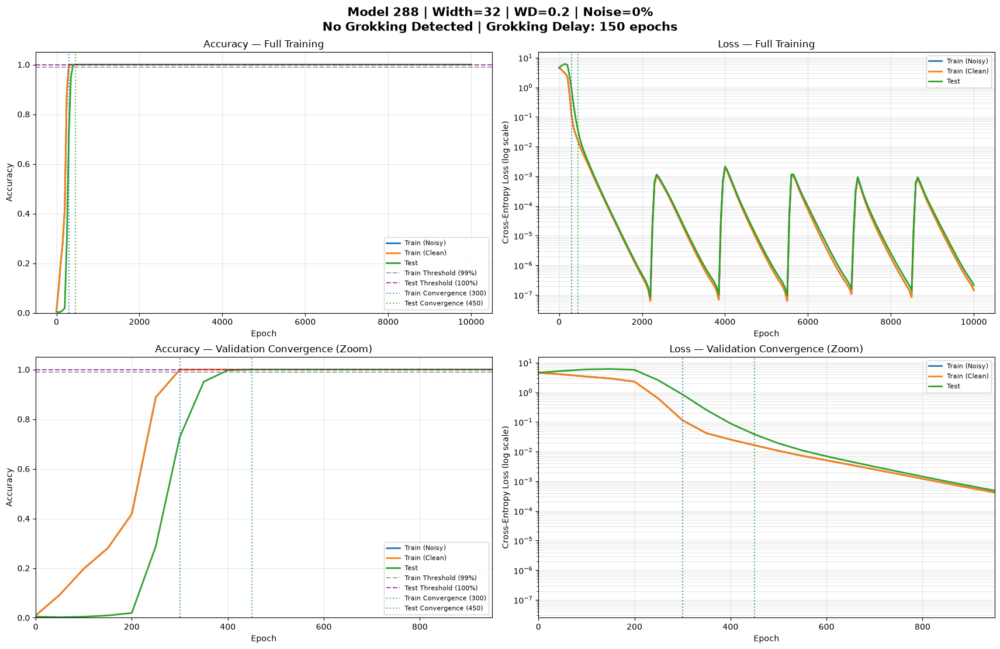

Training Models:  94%|█████████▍| 289/308 [2:29:59<30:23, 95.98s/model]


Training Model 289 | Width=32 | WD=0.2 | Noise=5%
Model 289 | Epoch   500/10000 | Train: 0.9954 | Test: 0.6918
Model 289 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.9309
Model 289 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.9462
Model 289 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.9486
Model 289 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.9522
Model 289 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.9529
Model 289 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.9525
Model 289 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9564
Model 289 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9642
Model 289 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9628
Model 289 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9628
Model 289 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9617
Model 289 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9575
Model 289 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9571
Model 289 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9656
Model 289 | Epoch  8000/10000 | Tr

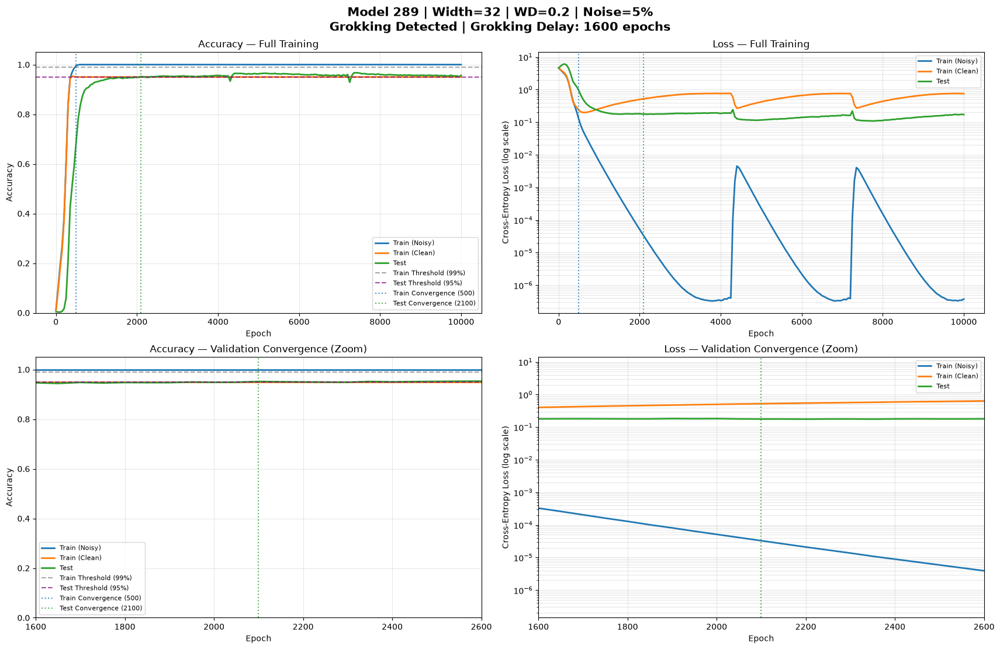

Training Models:  94%|█████████▍| 290/308 [2:31:34<28:45, 95.85s/model]


Training Model 290 | Width=32 | WD=0.2 | Noise=15%
Model 290 | Epoch   500/10000 | Train: 0.5454 | Test: 0.0213
Model 290 | Epoch  1000/10000 | Train: 0.9825 | Test: 0.4807
Model 290 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.5246
Model 290 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.5473
Model 290 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.5597
Model 290 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.5703
Model 290 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.5802
Model 290 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.5852
Model 290 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.5951
Model 290 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.5990
Model 290 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.6026
Model 290 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.6082
Model 290 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.6086
Model 290 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.6128
Model 290 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.6111
Model 290 | Epoch  8000/10000 | T

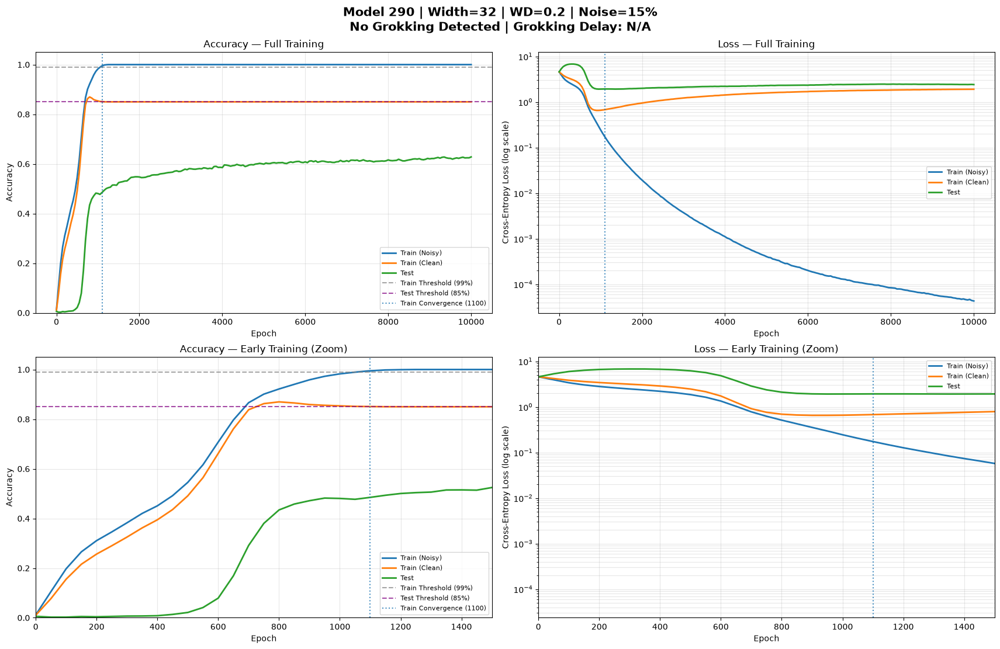

Training Models:  94%|█████████▍| 291/308 [2:33:10<27:09, 95.87s/model]


Training Model 291 | Width=32 | WD=0.2 | Noise=25%
Model 291 | Epoch   500/10000 | Train: 0.4387 | Test: 0.0039
Model 291 | Epoch  1000/10000 | Train: 0.6055 | Test: 0.0124
Model 291 | Epoch  1500/10000 | Train: 0.7814 | Test: 0.0634
Model 291 | Epoch  2000/10000 | Train: 0.8863 | Test: 0.1190
Model 291 | Epoch  2500/10000 | Train: 0.9358 | Test: 0.1311
Model 291 | Epoch  3000/10000 | Train: 0.9605 | Test: 0.1374
Model 291 | Epoch  3500/10000 | Train: 0.9765 | Test: 0.1502
Model 291 | Epoch  4000/10000 | Train: 0.9863 | Test: 0.1573
Model 291 | Epoch  4500/10000 | Train: 0.9916 | Test: 0.1559
Model 291 | Epoch  5000/10000 | Train: 0.9948 | Test: 0.1640
Model 291 | Epoch  5500/10000 | Train: 0.9957 | Test: 0.1633
Model 291 | Epoch  6000/10000 | Train: 0.9979 | Test: 0.1700
Model 291 | Epoch  6500/10000 | Train: 0.9991 | Test: 0.1686
Model 291 | Epoch  7000/10000 | Train: 0.9989 | Test: 0.1686
Model 291 | Epoch  7500/10000 | Train: 0.9994 | Test: 0.1633
Model 291 | Epoch  8000/10000 | T

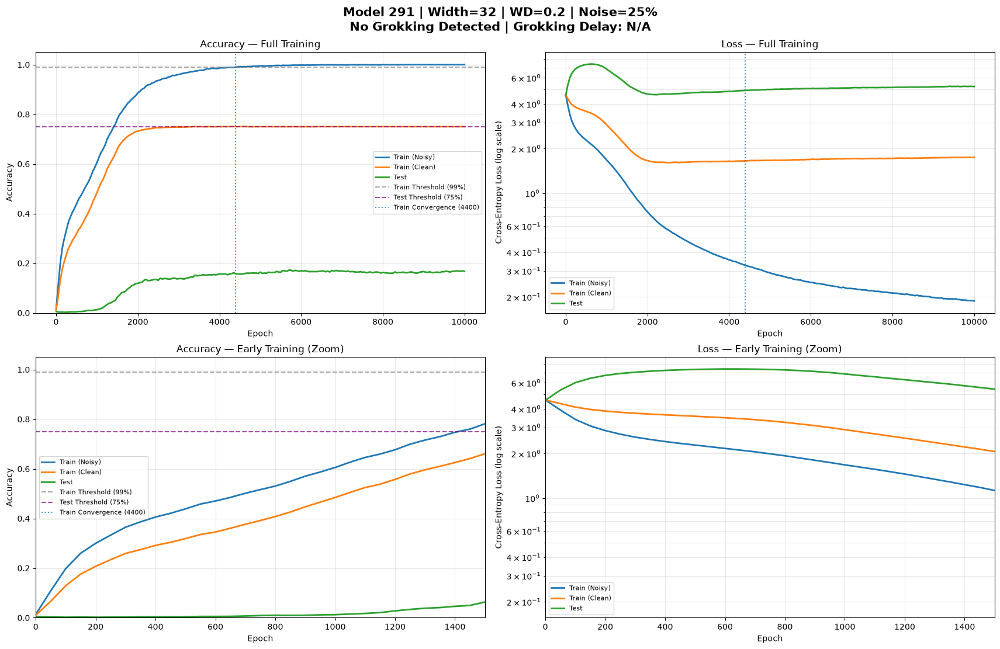

Training Models:  95%|█████████▍| 292/308 [2:34:46<25:33, 95.84s/model]


Training Model 292 | Width=64 | WD=0.2 | Noise=0%
Model 292 | Epoch   500/10000 | Train: 1.0000 | Test: 1.0000
Model 292 | Epoch  1000/10000 | Train: 1.0000 | Test: 1.0000
Model 292 | Epoch  1500/10000 | Train: 1.0000 | Test: 1.0000
Model 292 | Epoch  2000/10000 | Train: 1.0000 | Test: 1.0000
Model 292 | Epoch  2500/10000 | Train: 1.0000 | Test: 1.0000
Model 292 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 292 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 292 | Epoch  4000/10000 | Train: 1.0000 | Test: 1.0000
Model 292 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 292 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 292 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 292 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 292 | Epoch  6500/10000 | Train: 1.0000 | Test: 1.0000
Model 292 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 292 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 292 | Epoch  8000/10000 | Tr

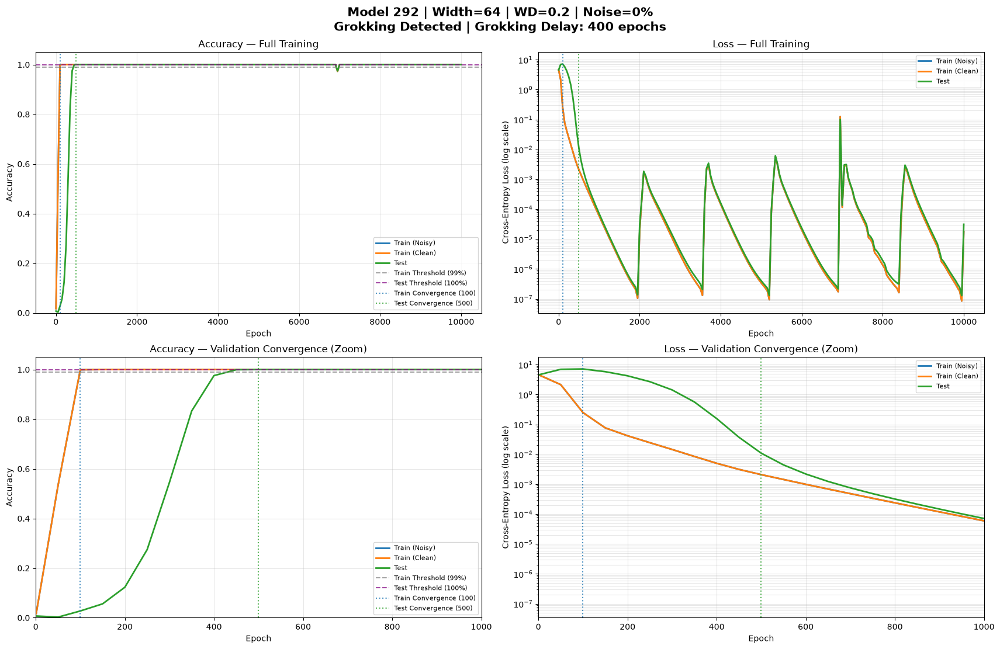

Training Models:  95%|█████████▌| 293/308 [2:36:23<24:02, 96.17s/model]


Training Model 293 | Width=64 | WD=0.2 | Noise=5%
Model 293 | Epoch   500/10000 | Train: 1.0000 | Test: 0.2855
Model 293 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.9674
Model 293 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.9795
Model 293 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.9841
Model 293 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.9876
Model 293 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.9858
Model 293 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.9869
Model 293 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9876
Model 293 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9908
Model 293 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9915
Model 293 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9901
Model 293 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9872
Model 293 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9897
Model 293 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9911
Model 293 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9901
Model 293 | Epoch  8000/10000 | Tr

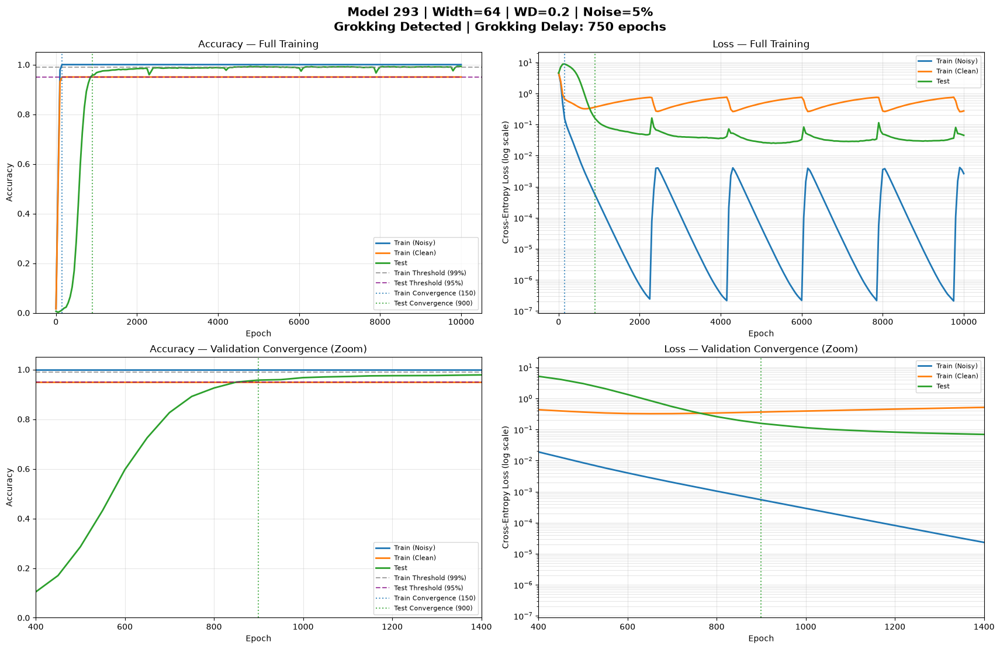

Training Models:  95%|█████████▌| 294/308 [2:38:00<22:29, 96.41s/model]


Training Model 294 | Width=64 | WD=0.2 | Noise=15%
Model 294 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0128
Model 294 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.1144
Model 294 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.3734
Model 294 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.5813
Model 294 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.7120
Model 294 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.8154
Model 294 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.8381
Model 294 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.8530
Model 294 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.8541
Model 294 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.8898
Model 294 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.8916
Model 294 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.8898
Model 294 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.8859
Model 294 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9107
Model 294 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9072
Model 294 | Epoch  8000/10000 | T

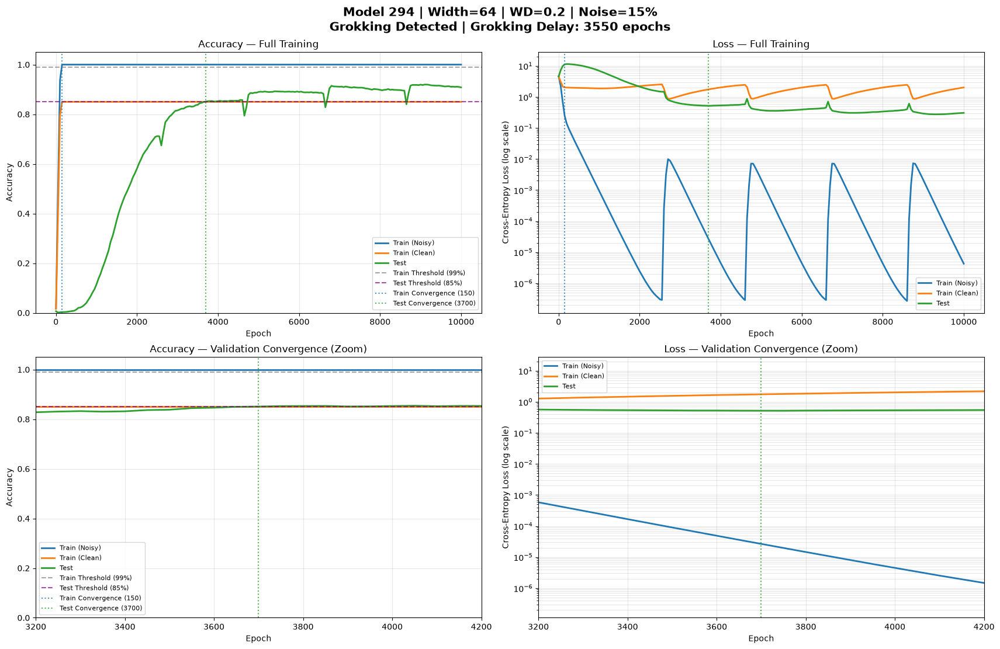

Training Models:  96%|█████████▌| 295/308 [2:39:37<20:54, 96.53s/model]


Training Model 295 | Width=64 | WD=0.2 | Noise=25%
Model 295 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0039
Model 295 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0035
Model 295 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.0081
Model 295 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.0124
Model 295 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.0262
Model 295 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.0616
Model 295 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.1275
Model 295 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.2550
Model 295 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.3401
Model 295 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.4137
Model 295 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.3914
Model 295 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.5260
Model 295 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.5558
Model 295 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.5657
Model 295 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.5809
Model 295 | Epoch  8000/10000 | T

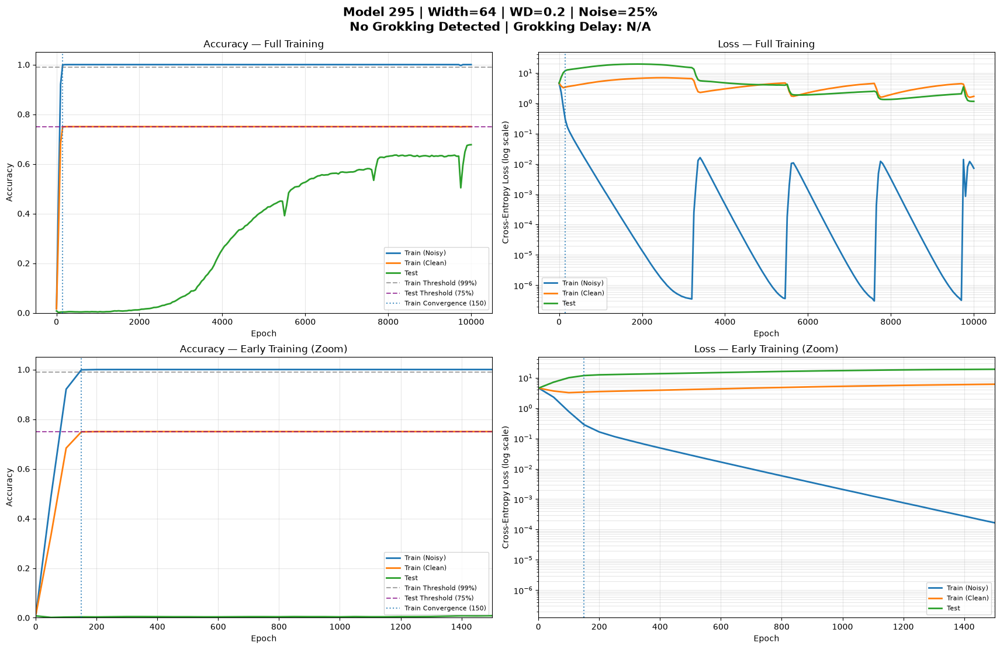

Training Models:  96%|█████████▌| 296/308 [2:41:14<19:19, 96.65s/model]


Training Model 296 | Width=128 | WD=0.2 | Noise=0%
Model 296 | Epoch   500/10000 | Train: 1.0000 | Test: 0.9996
Model 296 | Epoch  1000/10000 | Train: 1.0000 | Test: 1.0000
Model 296 | Epoch  1500/10000 | Train: 1.0000 | Test: 1.0000
Model 296 | Epoch  2000/10000 | Train: 1.0000 | Test: 1.0000
Model 296 | Epoch  2500/10000 | Train: 1.0000 | Test: 1.0000
Model 296 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 296 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 296 | Epoch  4000/10000 | Train: 1.0000 | Test: 1.0000
Model 296 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 296 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 296 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 296 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 296 | Epoch  6500/10000 | Train: 1.0000 | Test: 1.0000
Model 296 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 296 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 296 | Epoch  8000/10000 | T

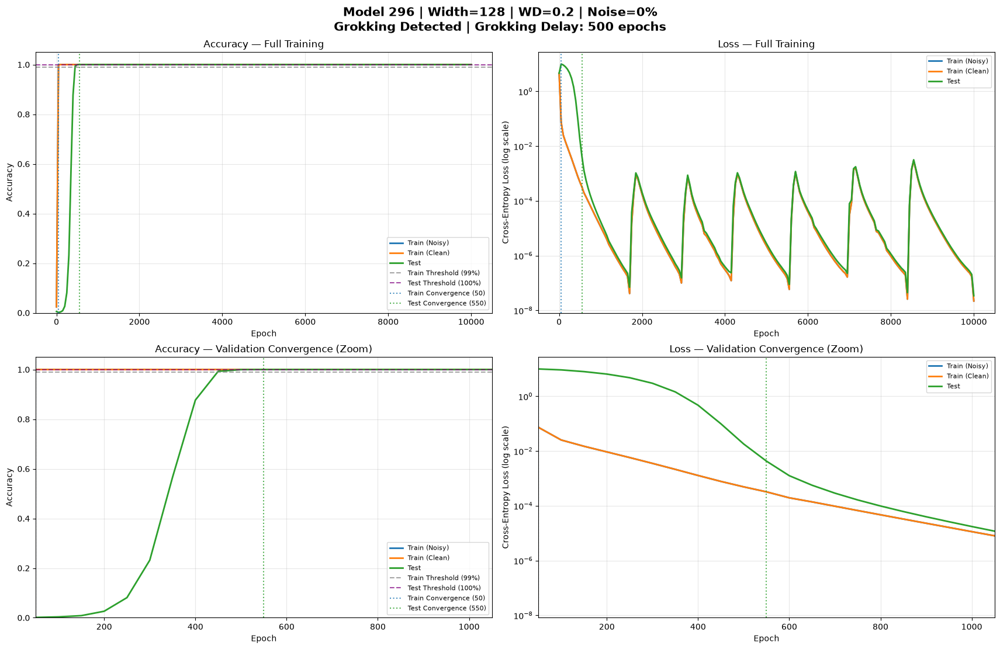

Training Models:  96%|█████████▋| 297/308 [2:42:52<17:48, 97.10s/model]


Training Model 297 | Width=128 | WD=0.2 | Noise=5%
Model 297 | Epoch   500/10000 | Train: 1.0000 | Test: 0.8696
Model 297 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.9979
Model 297 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.9968
Model 297 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.9986
Model 297 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.9972
Model 297 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.9975
Model 297 | Epoch  3500/10000 | Train: 0.9728 | Test: 0.9224
Model 297 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9968
Model 297 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9968
Model 297 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9965
Model 297 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9961
Model 297 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9965
Model 297 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9975
Model 297 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9975
Model 297 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9972
Model 297 | Epoch  8000/10000 | T

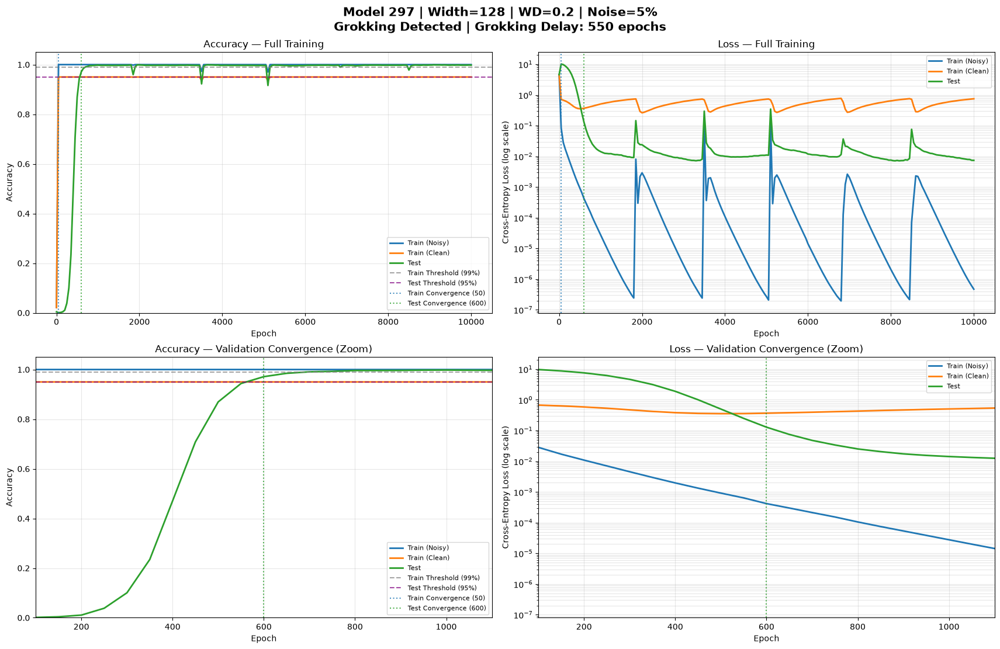

Training Models:  97%|█████████▋| 298/308 [2:44:30<16:15, 97.55s/model]


Training Model 298 | Width=128 | WD=0.2 | Noise=15%
Model 298 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0542
Model 298 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.5877
Model 298 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.8505
Model 298 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.9182
Model 298 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.9476
Model 298 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.9564
Model 298 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.9639
Model 298 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9720
Model 298 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9706
Model 298 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9699
Model 298 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9543
Model 298 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9593
Model 298 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9582
Model 298 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9649
Model 298 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9798
Model 298 | Epoch  8000/10000 | 

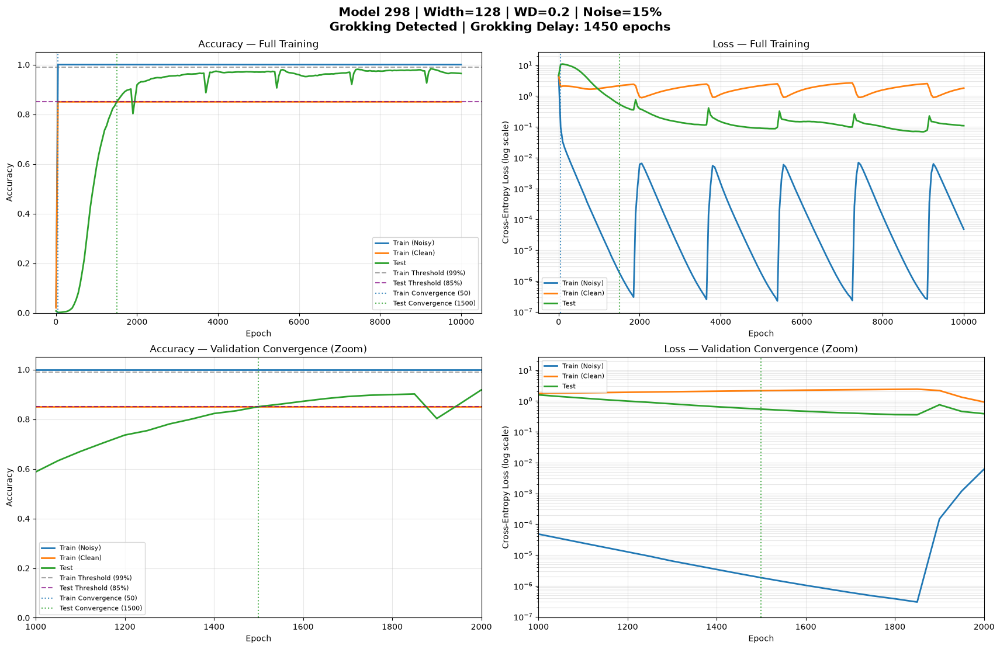

Training Models:  97%|█████████▋| 299/308 [2:46:09<14:41, 97.93s/model]


Training Model 299 | Width=128 | WD=0.2 | Noise=25%
Model 299 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0050
Model 299 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.0298
Model 299 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.1810
Model 299 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.3525
Model 299 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.5388
Model 299 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.6284
Model 299 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.6776
Model 299 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.7343
Model 299 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.7680
Model 299 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.7914
Model 299 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.8108
Model 299 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.8169
Model 299 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.8197
Model 299 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.8310
Model 299 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.8363
Model 299 | Epoch  8000/10000 | 

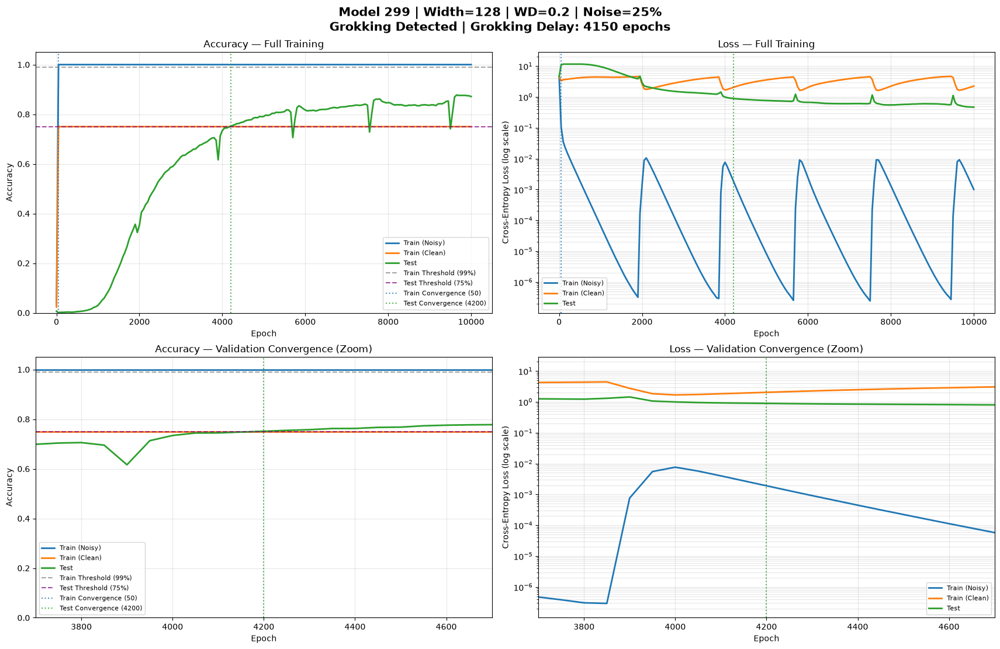

Training Models:  97%|█████████▋| 300/308 [2:47:48<13:05, 98.15s/model]


Training Model 300 | Width=256 | WD=0.2 | Noise=0%
Model 300 | Epoch   500/10000 | Train: 1.0000 | Test: 1.0000
Model 300 | Epoch  1000/10000 | Train: 1.0000 | Test: 1.0000
Model 300 | Epoch  1500/10000 | Train: 1.0000 | Test: 1.0000
Model 300 | Epoch  2000/10000 | Train: 1.0000 | Test: 1.0000
Model 300 | Epoch  2500/10000 | Train: 1.0000 | Test: 1.0000
Model 300 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 300 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 300 | Epoch  4000/10000 | Train: 1.0000 | Test: 1.0000
Model 300 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 300 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 300 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 300 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 300 | Epoch  6500/10000 | Train: 1.0000 | Test: 1.0000
Model 300 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 300 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 300 | Epoch  8000/10000 | T

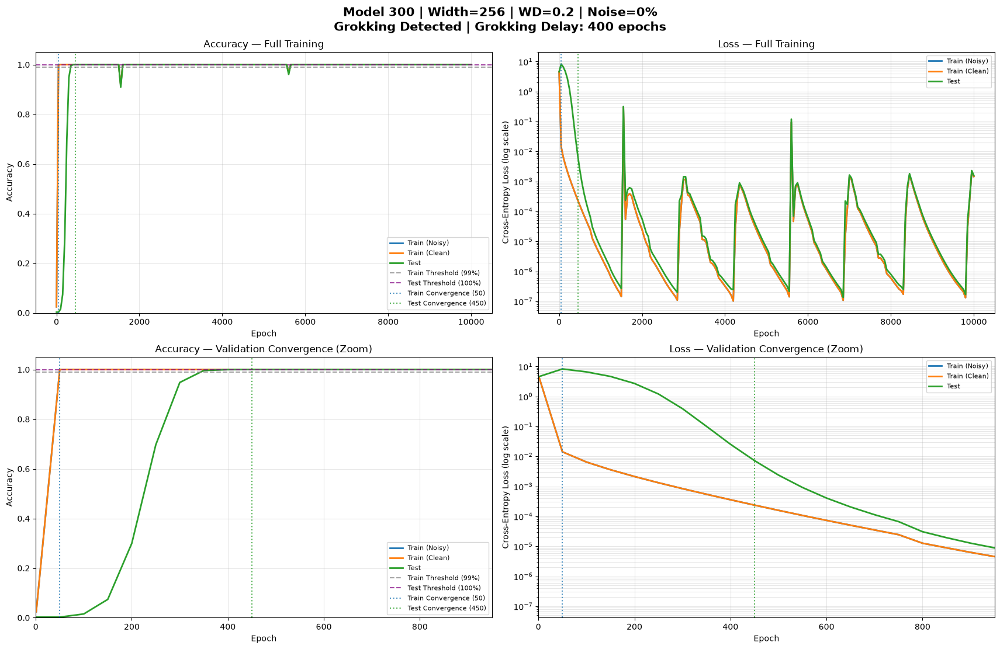

Training Models:  98%|█████████▊| 301/308 [2:49:25<11:24, 97.78s/model]


Training Model 301 | Width=256 | WD=0.2 | Noise=5%
Model 301 | Epoch   500/10000 | Train: 1.0000 | Test: 0.9695
Model 301 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.9993
Model 301 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.9993
Model 301 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.9993
Model 301 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.9989
Model 301 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.9986
Model 301 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.9996
Model 301 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9979
Model 301 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9982
Model 301 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9989
Model 301 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9993
Model 301 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9986
Model 301 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9986
Model 301 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9989
Model 301 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9979
Model 301 | Epoch  8000/10000 | T

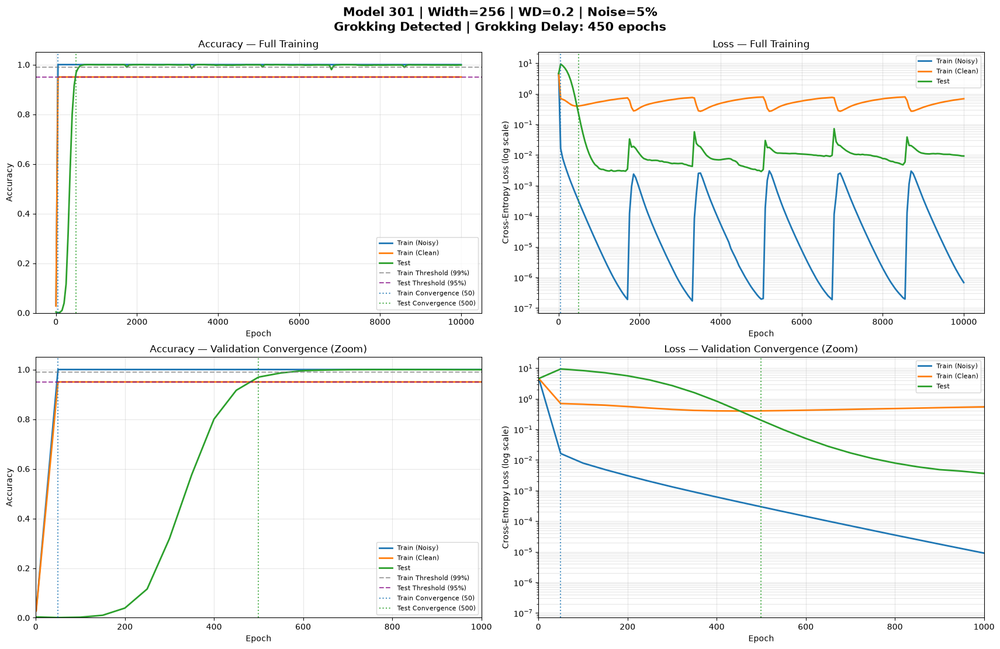

Training Models:  98%|█████████▊| 302/308 [2:51:02<09:44, 97.49s/model]


Training Model 302 | Width=256 | WD=0.2 | Noise=15%
Model 302 | Epoch   500/10000 | Train: 1.0000 | Test: 0.2597
Model 302 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.8845
Model 302 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.9469
Model 302 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.9674
Model 302 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.9639
Model 302 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.9667
Model 302 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.9713
Model 302 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9706
Model 302 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9713
Model 302 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9738
Model 302 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9798
Model 302 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9522
Model 302 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9685
Model 302 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9267
Model 302 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9617
Model 302 | Epoch  8000/10000 | 

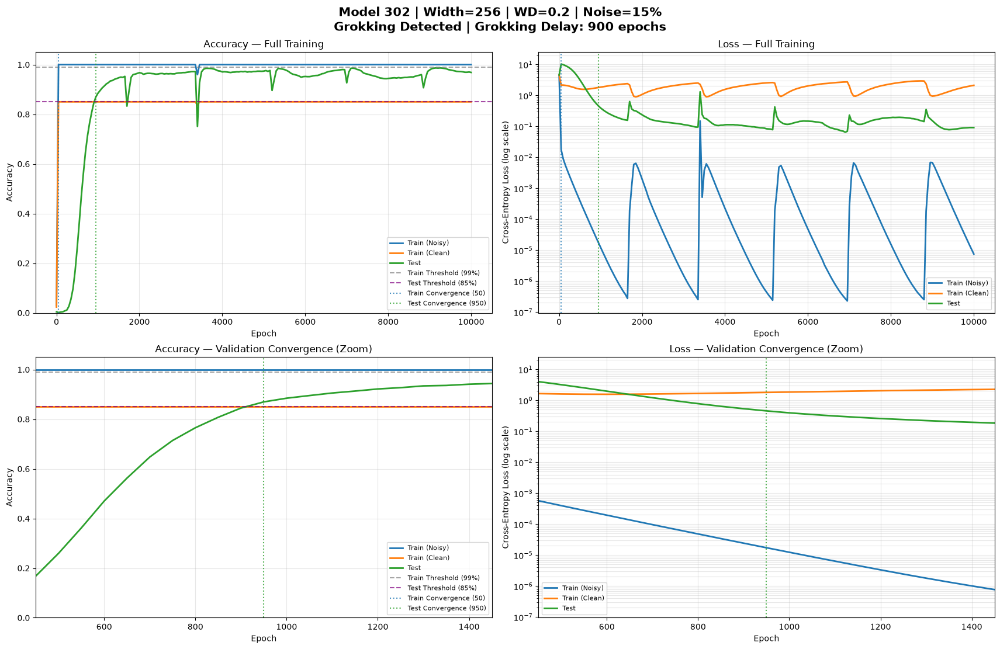

Training Models:  98%|█████████▊| 303/308 [2:52:38<08:06, 97.29s/model]


Training Model 303 | Width=256 | WD=0.2 | Noise=25%
Model 303 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0124
Model 303 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.2140
Model 303 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.4361
Model 303 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.5586
Model 303 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.6213
Model 303 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.6826
Model 303 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.5824
Model 303 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.7237
Model 303 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.7527
Model 303 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.7832
Model 303 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.8572
Model 303 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.7722
Model 303 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.7471
Model 303 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.7736
Model 303 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.8990
Model 303 | Epoch  8000/10000 | 

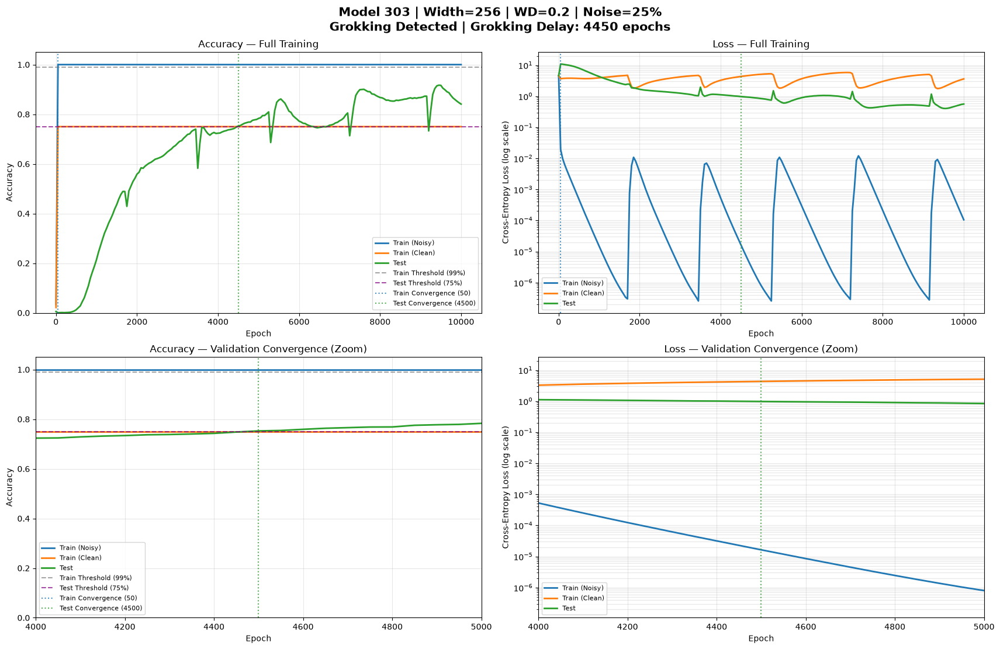

Training Models:  99%|█████████▊| 304/308 [2:54:15<06:28, 97.13s/model]


Training Model 304 | Width=512 | WD=0.2 | Noise=0%
Model 304 | Epoch   500/10000 | Train: 1.0000 | Test: 1.0000
Model 304 | Epoch  1000/10000 | Train: 1.0000 | Test: 1.0000
Model 304 | Epoch  1500/10000 | Train: 1.0000 | Test: 1.0000
Model 304 | Epoch  2000/10000 | Train: 1.0000 | Test: 1.0000
Model 304 | Epoch  2500/10000 | Train: 1.0000 | Test: 1.0000
Model 304 | Epoch  3000/10000 | Train: 1.0000 | Test: 1.0000
Model 304 | Epoch  3500/10000 | Train: 1.0000 | Test: 1.0000
Model 304 | Epoch  4000/10000 | Train: 1.0000 | Test: 1.0000
Model 304 | Epoch  4500/10000 | Train: 1.0000 | Test: 1.0000
Model 304 | Epoch  5000/10000 | Train: 1.0000 | Test: 1.0000
Model 304 | Epoch  5500/10000 | Train: 1.0000 | Test: 1.0000
Model 304 | Epoch  6000/10000 | Train: 1.0000 | Test: 1.0000
Model 304 | Epoch  6500/10000 | Train: 1.0000 | Test: 1.0000
Model 304 | Epoch  7000/10000 | Train: 1.0000 | Test: 1.0000
Model 304 | Epoch  7500/10000 | Train: 1.0000 | Test: 1.0000
Model 304 | Epoch  8000/10000 | T

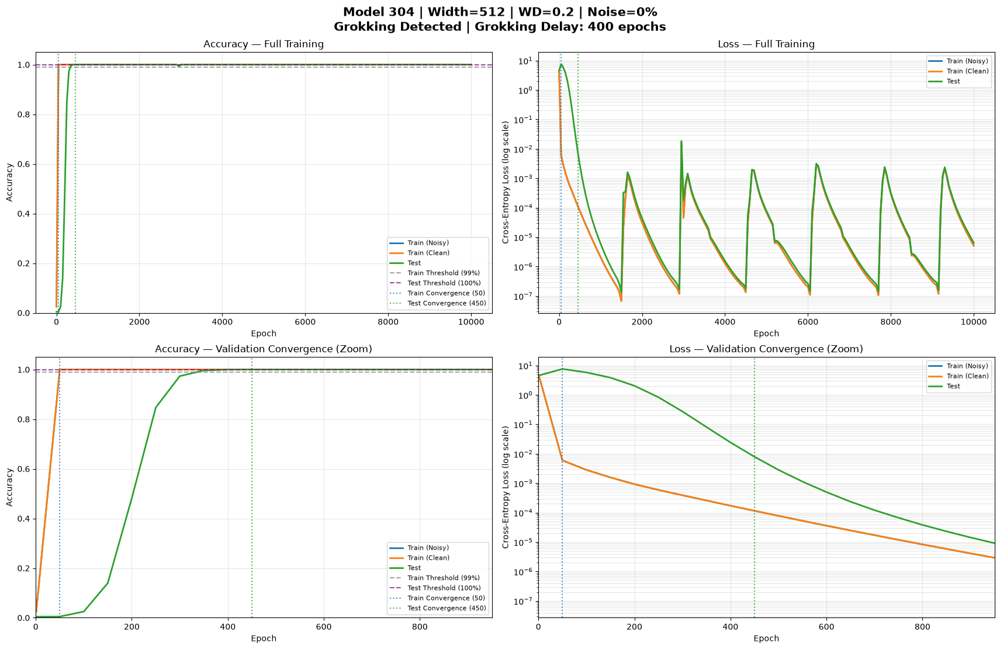

Training Models:  99%|█████████▉| 305/308 [2:57:02<05:54, 118.13s/model]


Training Model 305 | Width=512 | WD=0.2 | Noise=5%
Model 305 | Epoch   500/10000 | Train: 1.0000 | Test: 0.9479
Model 305 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.9901
Model 305 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.9972
Model 305 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.9727
Model 305 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.9823
Model 305 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.9904
Model 305 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.9979
Model 305 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9993
Model 305 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9989
Model 305 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9986
Model 305 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9996
Model 305 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9993
Model 305 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9989
Model 305 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9922
Model 305 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9996
Model 305 | Epoch  8000/10000 | T

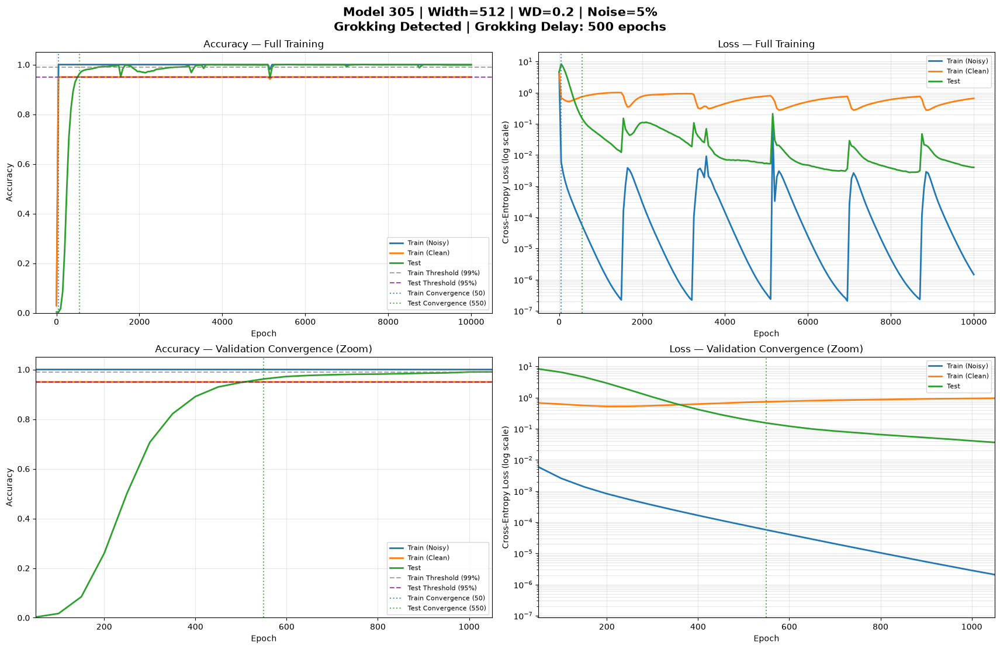

Training Models:  99%|█████████▉| 306/308 [2:59:49<04:25, 132.75s/model]


Training Model 306 | Width=512 | WD=0.2 | Noise=15%
Model 306 | Epoch   500/10000 | Train: 1.0000 | Test: 0.3950
Model 306 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.7106
Model 306 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.8069
Model 306 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.7347
Model 306 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.7584
Model 306 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.8200
Model 306 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.9072
Model 306 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.9490
Model 306 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.9256
Model 306 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.9330
Model 306 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.9681
Model 306 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.9674
Model 306 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.9617
Model 306 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.9649
Model 306 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.9816
Model 306 | Epoch  8000/10000 | 

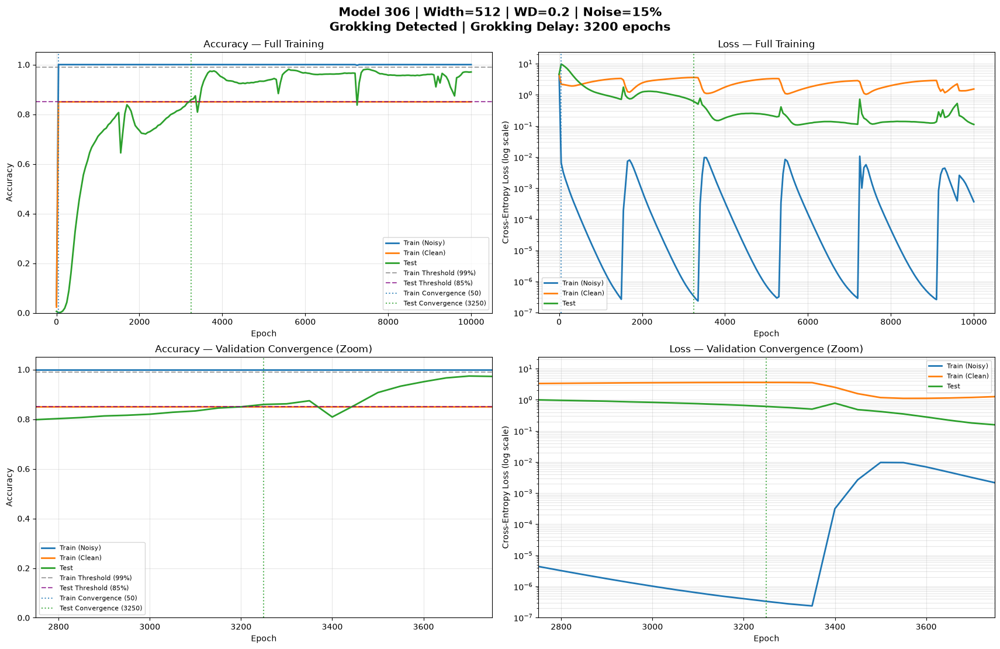

Training Models: 100%|█████████▉| 307/308 [3:02:36<02:22, 142.99s/model]


Training Model 307 | Width=512 | WD=0.2 | Noise=25%
Model 307 | Epoch   500/10000 | Train: 1.0000 | Test: 0.0252
Model 307 | Epoch  1000/10000 | Train: 1.0000 | Test: 0.1070
Model 307 | Epoch  1500/10000 | Train: 1.0000 | Test: 0.1647
Model 307 | Epoch  2000/10000 | Train: 1.0000 | Test: 0.2476
Model 307 | Epoch  2500/10000 | Train: 1.0000 | Test: 0.2770
Model 307 | Epoch  3000/10000 | Train: 1.0000 | Test: 0.3298
Model 307 | Epoch  3500/10000 | Train: 1.0000 | Test: 0.3663
Model 307 | Epoch  4000/10000 | Train: 1.0000 | Test: 0.5590
Model 307 | Epoch  4500/10000 | Train: 1.0000 | Test: 0.5370
Model 307 | Epoch  5000/10000 | Train: 1.0000 | Test: 0.5583
Model 307 | Epoch  5500/10000 | Train: 1.0000 | Test: 0.6302
Model 307 | Epoch  6000/10000 | Train: 1.0000 | Test: 0.7354
Model 307 | Epoch  6500/10000 | Train: 1.0000 | Test: 0.6787
Model 307 | Epoch  7000/10000 | Train: 1.0000 | Test: 0.6975
Model 307 | Epoch  7500/10000 | Train: 1.0000 | Test: 0.7283
Model 307 | Epoch  8000/10000 | 

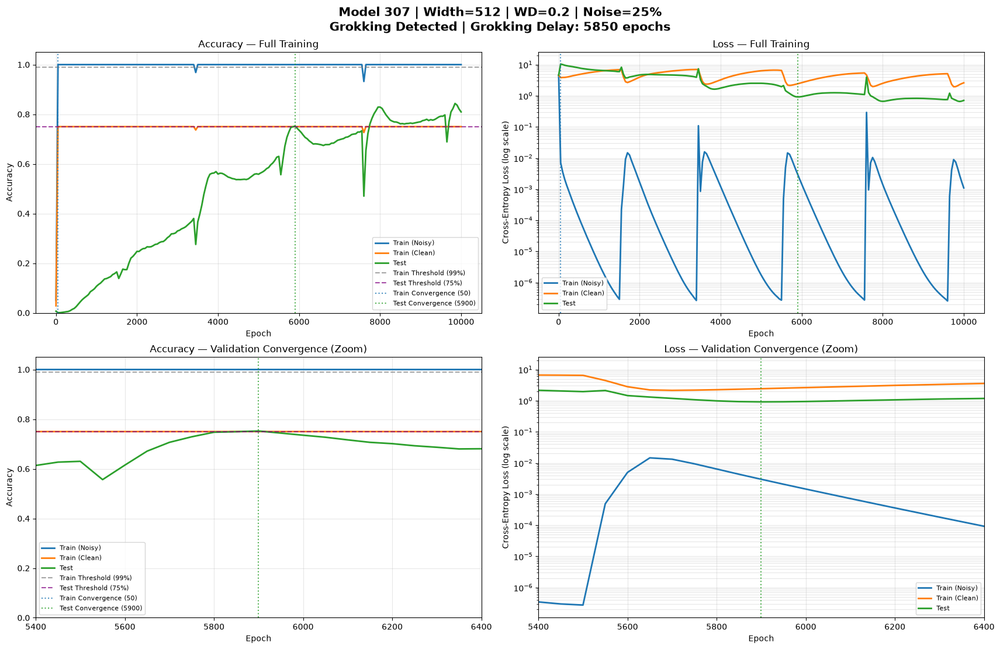

Training Models: 100%|██████████| 308/308 [3:05:23<00:00, 36.12s/model] 


EXPERIMENT SUMMARY
Status: FINISHED
Execution time: 3.09 hours
Total configurations: 308
Completed models: 308
Remaining models: 0
Results file: grokking_experiments/results.csv

Models exhibiting Grokking: 48
Grokking detection rate: 15.6%

First 20 completed experiments:


,index,weightDecay,hiddenWidth,labelNoise,trainConvergenceEpoch,testConvergenceEpoch,grokkingDelay,grokked,finalTestAccuracy
0,0,0.0,2,0,NaN,NaN,NaN,False,0.037194
1,1,0.0,2,5,NaN,NaN,NaN,False,0.031881
2,2,0.0,2,15,NaN,NaN,NaN,False,0.006730
3,3,0.0,2,25,NaN,NaN,NaN,False,0.007439
4,4,0.0,4,0,3150.0,NaN,NaN,False,0.998583
5,5,0.0,4,5,NaN,NaN,NaN,False,0.007793
6,6,0.0,4,15,NaN,NaN,NaN,False,0.009210
7,7,0.0,4,25,NaN,NaN,NaN,False,0.005668
8,8,0.0,8,0,NaN,NaN,NaN,False,0.938363
9,9,0.0,8,5,NaN,NaN,NaN,False,0.869996


In [10]:
# ============================================================
# AUTOMATED EXPERIMENT RUNNER
# ============================================================

from tqdm.auto import tqdm


# ============================================================
# 1. LOAD AND VALIDATE CONFIGURATIONS
# ============================================================

with open(CONFIG_FILE, "r") as f:
    experiment_configs = json.load(f)

config_by_index = {
    config["index"]: config
    for config in experiment_configs
}

# Ensure configuration indices are unique
if len(config_by_index) != len(experiment_configs):
    raise ValueError("Duplicate configuration indices detected!")

print(f"Total configurations: {len(experiment_configs)}")


# ============================================================
# 2. SELECT CONFIGURATIONS TO TRAIN
# ============================================================

if RUN_INDICES is None:

    selected_configs = experiment_configs

else:

    requested_indices = set(RUN_INDICES)

    missing_indices = requested_indices - set(config_by_index)

    if missing_indices:
        raise ValueError(
            f"Unknown configuration indices: {sorted(missing_indices)}"
        )

    selected_configs = [
        config
        for config in experiment_configs
        if config["index"] in requested_indices
    ]


print(f"Selected configurations: {len(selected_configs)}")
print(f"Epochs per model: {EPOCHS:,}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Checkpoint interval: {CHECKPOINT_EVERY}")
print(f"Device: {DEVICE}")


# ============================================================
# 3. VALIDATE EXISTING EXPERIMENTS
# ============================================================

def get_experiment_status(config):

    index = config["index"]

    model_dir = MODELS_DIR / f"model_{index:03d}"

    summary_path = model_dir / "summary.json"
    history_path = model_dir / "history.csv"
    checkpoint_path = model_dir / "checkpoint.pt"

    # --------------------------------------------------------
    # COMPLETED EXPERIMENT
    # --------------------------------------------------------

    if summary_path.exists():

        with open(summary_path, "r") as f:
            summary = json.load(f)

        # Validate configuration
        for key, value in config.items():

            if summary.get(key) != value:
                raise ValueError(
                    f"Model {index:03d}: configuration mismatch "
                    f"for '{key}'."
                )

        # Validate training duration
        if summary.get("epochs") != EPOCHS:
            raise ValueError(
                f"Model {index:03d}: saved for "
                f"{summary.get('epochs')} epochs, "
                f"but current EPOCHS={EPOCHS}."
            )

        # Ensure training history exists
        if not history_path.exists():
            raise FileNotFoundError(
                f"Model {index:03d}: summary exists "
                f"but history.csv is missing."
            )

        return "completed"

    # --------------------------------------------------------
    # RESUMABLE EXPERIMENT
    # --------------------------------------------------------

    if checkpoint_path.exists():

        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False
        )

        # Validate checkpoint configuration
        if checkpoint.get("config") != config:
            raise ValueError(
                f"Model {index:03d}: checkpoint "
                f"configuration mismatch."
            )

        # Validate checkpoint epoch
        checkpoint_epoch = checkpoint.get("epoch", -1)

        if not 1 <= checkpoint_epoch <= EPOCHS:
            raise ValueError(
                f"Model {index:03d}: invalid checkpoint "
                f"epoch {checkpoint_epoch}."
            )

        return "resumable"

    # --------------------------------------------------------
    # NEW EXPERIMENT
    # --------------------------------------------------------

    return "pending"


# Check selected experiments
status_counts = {
    "completed": 0,
    "resumable": 0,
    "pending": 0
}

for config in selected_configs:

    status = get_experiment_status(config)

    status_counts[status] += 1


print("\n" + "=" * 60)
print("EXPERIMENT STATUS")
print("=" * 60)

print(f"Completed:   {status_counts['completed']}")
print(f"Resumable:   {status_counts['resumable']}")
print(f"Not started: {status_counts['pending']}")


# ============================================================
# 4. COMBINED RESULTS SAVING
# ============================================================

RESULTS_FILE = OUT_DIR / "results.csv"


def save_experiment_results():

    summaries = []

    # Only collect results belonging to the current experiment
    for config in experiment_configs:

        index = config["index"]

        summary_path = (
            MODELS_DIR
            / f"model_{index:03d}"
            / "summary.json"
        )

        if not summary_path.exists():
            continue

        with open(summary_path, "r") as f:
            summary = json.load(f)

        # Validate configuration
        if any(
            summary.get(key) != value
            for key, value in config.items()
        ):
            raise ValueError(
                f"Model {index:03d}: saved configuration mismatch."
            )

        # Validate epoch count
        if summary.get("epochs") != EPOCHS:
            raise ValueError(
                f"Model {index:03d}: saved epoch count mismatch."
            )

        summaries.append(summary)

    if not summaries:
        return pd.DataFrame()

    # Combine model summaries
    results_df = pd.DataFrame(summaries)

    results_df = (
        results_df
        .sort_values("index")
        .reset_index(drop=True)
    )

    # Save atomically to avoid corrupting an existing results file
    temp_path = RESULTS_FILE.with_suffix(".tmp")

    results_df.to_csv(
        temp_path,
        index=False
    )

    temp_path.replace(RESULTS_FILE)

    return results_df


# ============================================================
# 5. RUN EXPERIMENTS
# ============================================================

print("\nStarting automated experiments...\n")

experiment_start = time.time()

interrupted = False

try:

    for config in tqdm(
        selected_configs,
        desc="Training Models",
        unit="model"
    ):

        index = config["index"]

        # ----------------------------------------------------
        # TRAIN OR RESUME MODEL
        # ----------------------------------------------------

        train_model(config)

        # ----------------------------------------------------
        # SAVE COMBINED RESULTS
        # ----------------------------------------------------

        save_experiment_results()

        # ----------------------------------------------------
        # GENERATE MODEL VISUALIZATION
        # ----------------------------------------------------

        plot_model_results(
            model_index=index,
            show=SHOW_PLOTS
        )

except KeyboardInterrupt:

    interrupted = True

    print("\nTraining interrupted by user.")
    print("Completed models and saved checkpoints are preserved.")

finally:

    # Save all completed results, even after interruption
    results_df = save_experiment_results()


# ============================================================
# 6. FINAL EXPERIMENT SUMMARY
# ============================================================

elapsed_seconds = time.time() - experiment_start

print("\n" + "=" * 60)
print("EXPERIMENT SUMMARY")
print("=" * 60)

if interrupted:
    print("Status: INTERRUPTED")
else:
    print("Status: FINISHED")

print(f"Execution time: {elapsed_seconds / 3600:.2f} hours")

print(f"Total configurations: {len(experiment_configs)}")

print(f"Completed models: {len(results_df)}")

print(
    f"Remaining models: "
    f"{len(experiment_configs) - len(results_df)}"
)

print(f"Results file: {RESULTS_FILE}")


# ============================================================
# 7. DISPLAY RESULTS
# ============================================================

if not results_df.empty:

    grokked_count = int(results_df["grokked"].sum())

    grokking_rate = (
        grokked_count / len(results_df) * 100
    )

    print(f"\nModels exhibiting Grokking: {grokked_count}")
    print(f"Grokking detection rate: {grokking_rate:.1f}%")

    columns = [
        "index",
        "weightDecay",
        "hiddenWidth",
        "labelNoise",
        "trainConvergenceEpoch",
        "testConvergenceEpoch",
        "grokkingDelay",
        "grokked",
        "finalTestAccuracy"
    ]

    print("\nFirst 20 completed experiments:")

    display(
        results_df[columns].head(20)
    )

else:

    print("\nNo experiments completed yet.")

# Grokking visualization

Saved: grokking_experiments/grokking_landscape.png
Grokking detected: 48/308 completed models
Not yet completed: 0


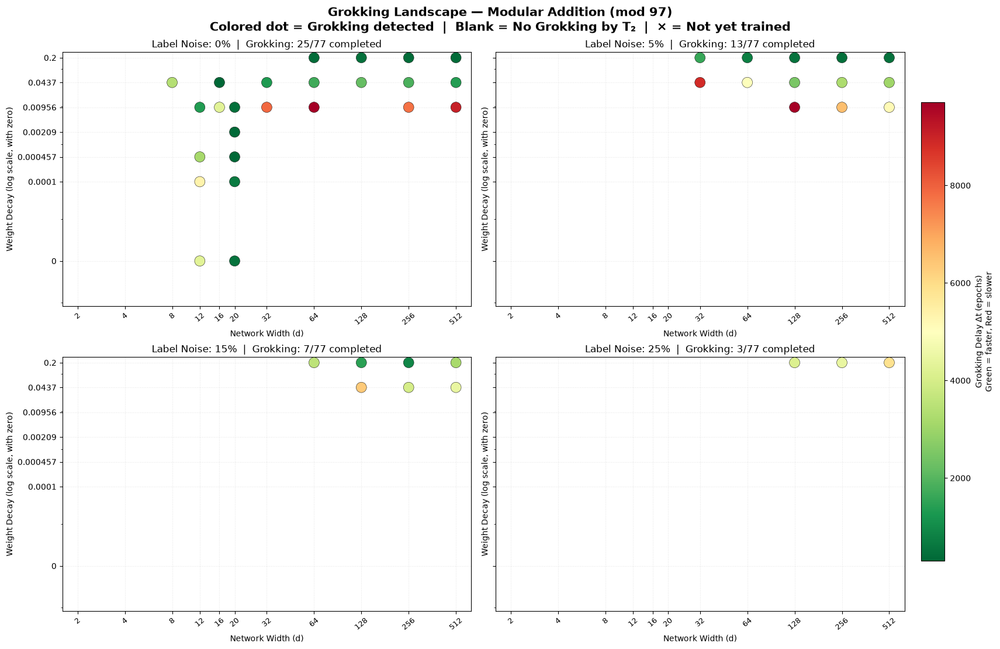

In [11]:
# ============================================================
# GROKKING LANDSCAPE VISUALIZATION
# ============================================================

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable


def plot_grokking_landscape(show=True, save=True):

    # ========================================================
    # 1. LOAD EXPERIMENT DATA
    # ========================================================

    results_path = OUT_DIR / "results.csv"

    if not results_path.exists():
        raise FileNotFoundError(
            f"{results_path} not found. "
            "Complete at least one model first."
        )

    with open(CONFIG_FILE, "r") as f:
        configurations = json.load(f)

    results = pd.read_csv(results_path)

    required_columns = {
        "index",
        "hiddenWidth",
        "weightDecay",
        "labelNoise",
        "grokked",
        "grokkingDelay"
    }

    missing = required_columns - set(results.columns)

    if missing:
        raise ValueError(
            f"Missing results columns: {sorted(missing)}"
        )

    # ========================================================
    # 2. VALIDATE RESULTS
    # ========================================================

    configs_by_index = {
        int(config["index"]): config
        for config in configurations
    }

    if len(configs_by_index) != len(configurations):
        raise ValueError(
            "Duplicate indices in configurations.json."
        )

    if results["index"].duplicated().any():
        raise ValueError(
            "Duplicate model indices in results.csv."
        )

    # Prevent mixing results from different configuration grids
    for _, row in results.iterrows():

        index = int(row["index"])

        if index not in configs_by_index:
            raise ValueError(
                f"Model {index} is not in configurations.json."
            )

        config = configs_by_index[index]

        if (
            int(row["hiddenWidth"]) != int(config["hiddenWidth"])
            or int(row["labelNoise"]) != int(config["labelNoise"])
            or not np.isclose(
                float(row["weightDecay"]),
                float(config["weightDecay"]),
                rtol=1e-8,
                atol=1e-12
            )
        ):
            raise ValueError(
                f"Model {index}: configuration mismatch."
            )

    # Convert saved values to appropriate types
    results["grokkedFlag"] = (
        results["grokked"]
        .astype(str)
        .str.lower()
        .isin(["true", "1"])
    )

    results["grokkingDelay"] = pd.to_numeric(
        results["grokkingDelay"],
        errors="coerce"
    )

    if results.loc[
        results["grokkedFlag"], "grokkingDelay"
    ].isna().any():
        raise ValueError(
            "A detected Grokking run is missing its delay."
        )

    # ========================================================
    # 3. PREPARE AXES AND COLOR SCALE
    # ========================================================

    widths = sorted({
        int(config["hiddenWidth"])
        for config in configurations
    })

    weight_decays = sorted({
        float(config["weightDecay"])
        for config in configurations
    })

    noise_levels = sorted({
        int(config["labelNoise"])
        for config in configurations
    })

    completed_indices = set(
        results["index"].astype(int)
    )

    # Use the same color scale across all noise levels
    delays = results.loc[
        results["grokkedFlag"],
        "grokkingDelay"
    ]

    norm = None

    if not delays.empty:

        min_delay = float(delays.min())
        max_delay = float(delays.max())

        if min_delay == max_delay:
            min_delay -= 1
            max_delay += 1

        norm = Normalize(
            vmin=min_delay,
            vmax=max_delay
        )

    # ========================================================
    # 4. CREATE FIGURE
    # ========================================================

    ncols = 2
    nrows = (len(noise_levels) + ncols - 1) // ncols

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(17, 5.5 * nrows),
        sharex=True,
        sharey=True,
        constrained_layout=True
    )

    axes = np.asarray(axes).ravel()

    fig.suptitle(
        "Grokking Landscape — Modular Addition (mod 97)\n"
        "Colored dot = Grokking detected  |  "
        "Blank = No Grokking by T₂  |  "
        "× = Not yet trained",
        fontsize=15,
        fontweight="bold"
    )

    positive_wd = [
        wd for wd in weight_decays
        if wd > 0
    ]

    # ========================================================
    # 5. PLOT EACH NOISE LEVEL
    # ========================================================

    for ax, noise in zip(axes, noise_levels):

        # All configurations expected for this noise level
        expected = [
            config
            for config in configurations
            if int(config["labelNoise"]) == noise
        ]

        # Completed experiments
        subset = results[
            results["labelNoise"] == noise
        ]

        # Only experiments where Grokking was detected
        detected = subset[
            subset["grokkedFlag"]
        ]

        # Experiments that have not completed
        pending = [
            config
            for config in expected
            if int(config["index"]) not in completed_indices
        ]

        # ----------------------------------------------------
        # PLOT DETECTED GROKKING
        # ----------------------------------------------------

        if not detected.empty:

            ax.scatter(
                detected["hiddenWidth"],
                detected["weightDecay"],
                c=detected["grokkingDelay"],
                cmap="RdYlGn_r",
                norm=norm,
                s=165,
                edgecolors="black",
                linewidths=0.35,
                zorder=3
            )

        # ----------------------------------------------------
        # MARK UNFINISHED EXPERIMENTS
        # ----------------------------------------------------

        if pending:

            ax.scatter(
                [config["hiddenWidth"] for config in pending],
                [config["weightDecay"] for config in pending],
                marker="x",
                color="0.6",
                s=60,
                linewidths=1.1,
                zorder=2
            )

        # ----------------------------------------------------
        # GRAPH TITLE
        # ----------------------------------------------------

        ax.set_title(
            f"Label Noise: {noise}%  |  "
            f"Grokking: {len(detected)}/{len(subset)} completed",
            fontsize=12
        )

        # ----------------------------------------------------
        # X-AXIS: NETWORK WIDTH
        # ----------------------------------------------------

        ax.set_xscale("log", base=2)

        ax.set_xticks(widths)

        ax.set_xticklabels(
            [str(width) for width in widths],
            rotation=40,
            fontsize=9
        )

        ax.tick_params(
            axis="x",
            labelbottom=True
        )

        ax.set_xlim(
            min(widths) / 1.25,
            max(widths) * 1.25
        )

        # ----------------------------------------------------
        # Y-AXIS: WEIGHT DECAY
        # ----------------------------------------------------

        # Symmetric log supports WD=0
        if positive_wd:

            min_positive = min(positive_wd)

            ax.set_yscale(
                "symlog",
                base=10,
                linthresh=min_positive / 10
            )

            ax.set_ylim(
                -min_positive / 8,
                max(weight_decays) * 1.4
            )

        else:
            ax.set_ylim(-0.1, 0.1)

        ax.set_yticks(weight_decays)

        ax.set_yticklabels([
            f"{wd:.3g}"
            for wd in weight_decays
        ])

        # ----------------------------------------------------
        # LABELS AND GRID
        # ----------------------------------------------------

        ax.set_xlabel("Network Width (d)")
        ax.set_ylabel("Weight Decay (log scale, with zero)")

        ax.grid(
            True,
            which="major",
            linestyle=":",
            alpha=0.3
        )

    # Hide unused panels if necessary
    for ax in axes[len(noise_levels):]:
        ax.set_visible(False)

    # ========================================================
    # 6. SHARED COLORBAR
    # ========================================================

    if norm is not None:

        colorbar = fig.colorbar(
            ScalarMappable(
                norm=norm,
                cmap="RdYlGn_r"
            ),
            ax=axes[:len(noise_levels)].tolist(),
            shrink=0.82,
            pad=0.02
        )

        colorbar.set_label(
            "Grokking Delay Δt (epochs)\n"
            "Green = faster, Red = slower"
        )

    # ========================================================
    # 7. SAVE FIGURE
    # ========================================================

    if save:

        plot_path = OUT_DIR / "grokking_landscape.png"

        fig.savefig(
            plot_path,
            dpi=170,
            bbox_inches="tight"
        )

        print(f"Saved: {plot_path}")

    # ========================================================
    # 8. DISPLAY SUMMARY
    # ========================================================

    grokked_count = int(
        results["grokkedFlag"].sum()
    )

    pending_count = (
        len(configurations) - len(results)
    )

    print(
        f"Grokking detected: "
        f"{grokked_count}/{len(results)} completed models"
    )

    print(f"Not yet completed: {pending_count}")

    if show:
        plt.show()
    else:
        plt.close(fig)


# ============================================================
# GENERATE GROKKING LANDSCAPE
# ============================================================

plot_grokking_landscape()